# Persistent Object Gaussian Splat (POGS) — end-to-end on Kaggle T4 ×2

Faithful re-implementation of **Yu, Hari, El-Refai, Dalil, Kerr, Kim, Cheng, Irshad, Goldberg,
*"Persistent Object Gaussian Splat (POGS) for Tracking Human and Robot Manipulation of
Irregularly Shaped Objects"*, ICRA 2025** — plus a Kalman-filter tracking extension.

---

## What runs here

All three phases of Sec. IV, end to end, on 2× Tesla T4:

| Phase | Paper | This notebook |
|---|---|---|
| **1. Scene Capture** (IV-A) | 35 views, wrist ZED Mini on UR5, RAFT-Stereo depth, fused cloud, DBSCAN filter | 35 hemisphere views from an analytic ray-cast tabletop, metric depth + stereo-like noise, fused cloud, **the same DBSCAN filter** |
| **2. Training** (IV-B) | 3DGS + Pearson depth reg. + DINOv2 (PCA→64) + CLIP pyramid + contrastive grouping, 4000 steps | identical losses, identical LR schedule, identical staging (`dino_step=100`, `lerf_step=2500`) |
| **2b. Grouping** (IV-B/C) | HDBSCAN on grouping features, centroid-canonicalised object frames | identical (`sklearn.cluster.HDBSCAN` instead of `cuml`) |
| **3. Tracking** (IV-D) | per-cluster SE(3) `part_deltas`, DINO feature loss + depth loss, ROI crops, 100+70 init then 25 Adam steps/frame | identical, port of `rigid_group_optimizer.py` |
| **Grasping** (IV-E) | Contact-GraspNet on the cluster's Gaussian means | antipodal sampler on the **same** Gaussian means, same `(K,4,4)` output contract |
| **Object reset** (V-A, Table I) | 3 tasks × 2 tiers × 4 trials on a UR5, consecutive resets / pick rate / place rate / caliper-measured placement error | same protocol scored against ground truth: grasps planned on POGS's *estimated* pose, checked against the true surface |
| **Tool servoing** (V-B, Table II) | 6-DoF closed-loop drill-tip alignment to an ArUco target, 15–30° in-grasp perturbations, 2 tiers × 5 trials × 5 poses | same closed loop — render → track → command → re-render — with an annotated tool-tip frame instead of the marker |
| **Extension (ours)** | — | SE(3) constant-velocity Kalman filter: warm start, outlier gating, adaptive iteration count |

## Substitutions, and why

The official stack (nerfstudio + tiny-cuda-nn + cuml + NVIDIA Warp + Detic/detectron2 +
RAFT-Stereo + ZED SDK + a TF-2.5/py3.8 Contact-GraspNet env + a UR5) cannot be installed
inside a Kaggle session. Every substitution below preserves the *algorithm* and replaces only
the *implementation* or the *hardware*:

| Official | Here | Note |
|---|---|---|
| `gsplat` CUDA rasteriser | `gsplat` when it imports, else a pure-PyTorch tile-based EWA rasteriser | both render RGB+depth **and arbitrary N-D features**, which POGS needs for DINO-64 and the hash grid |
| `tiny-cuda-nn` HashGrid + CutlassMLP | pure-PyTorch multiresolution hash encoding, same 12+12 levels / 2¹⁹ table / 4 feats, same MLP widths | ref [51] in the paper |
| `cuml.cluster.HDBSCAN` | `sklearn.cluster.HDBSCAN` | same algorithm |
| NVIDIA Warp `apply_to_model` kernel + `wp.Tape` | `geometry.apply_group_deltas` | directly autograd-differentiable, so the manual tape disappears |
| Detic 2D masks | simulator instance channel (or any segmenter you plug in) | same supervision signal for the contrastive grouping loss |
| RAFT-Stereo / TRI depth net | exact metric depth + a stereo-like noise model | so the "No Depth" ablation is still meaningful |
| Contact-GraspNet | geometric antipodal sampler | the paper's claim is about the *input cloud*, not the sampler |
| ZED 2 + UR5 | POGS-Sim | gives **ground-truth 6-DoF trajectories**, so tracking numbers here are quantitative |

**Dataset.** The paper's captured scenes are not distributed with the code release and the
demos need live stereo + a robot, so this notebook generates its own scene (**POGS-Sim**).
The last section lists the real datasets to move to and exactly how they map onto these
phases.

## 0 · Environment

In [1]:
import os, sys, subprocess, time, platform, textwrap
import torch

print(f"python      {platform.python_version()}")
print(f"torch       {torch.__version__}  (cuda build {torch.version.cuda})")
print(f"cuda avail  {torch.cuda.is_available()}  devices: {torch.cuda.device_count()}")
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"  cuda:{i}  {p.name}  {p.total_memory/2**30:.1f} GiB  sm_{p.major}{p.minor}")

HAS_CUDA  = torch.cuda.is_available()
N_GPU     = torch.cuda.device_count()
DEVICE    = "cuda:0" if HAS_CUDA else "cpu"
FEAT_DEV  = "cuda:1" if N_GPU > 1 else DEVICE          # DINO/CLIP on the second T4
print(f"\nsplat/optimiser -> {DEVICE}   |   DINOv2 + CLIP -> {FEAT_DEV}")

# The %%writefile cells in §1 open their target directly; the magic does not
# create parent directories, so on a fresh session the first one would raise
# FileNotFoundError.
os.makedirs("pogs_kaggle", exist_ok=True)
print("package dir  ->", os.path.abspath("pogs_kaggle"))

python      3.12.13
torch       2.10.0+cu128  (cuda build 12.8)
cuda avail  True  devices: 2
  cuda:0  Tesla T4  14.6 GiB  sm_75
  cuda:1  Tesla T4  14.6 GiB  sm_75

splat/optimiser -> cuda:0   |   DINOv2 + CLIP -> cuda:1
package dir  -> /kaggle/working/pogs_kaggle


### Optional wheels

`gsplat` gives the CUDA rasteriser the paper uses; `open_clip_torch` gives the real
language features. Both are optional — every cell below runs without them, on the
pure-PyTorch rasteriser and the deterministic fallback encoders. Turn internet on in the
Kaggle sidebar (*Settings → Internet*) to get the real thing.

In [2]:
INSTALL = True          # set False for a fully offline run

def pip(*args):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args],
                       capture_output=True, text=True)
    return r.returncode == 0, (r.stderr or "")[-400:]

if INSTALL:
    for spec in ["open_clip_torch", "imageio", "gsplat"]:
        ok, err = pip(spec)
        print(f"{'OK  ' if ok else 'FAIL'} pip install {spec}" + ("" if ok else f"\n      {err.strip()[:300]}"))
else:
    print("skipping installs (offline mode)")

try:
    import gsplat; print("\ngsplat", gsplat.__version__)
except Exception as e:
    print("\ngsplat unavailable ->", type(e).__name__, "| pure-PyTorch rasteriser will be used")
try:
    import open_clip; print("open_clip ok")
except Exception as e:
    print("open_clip unavailable ->", type(e).__name__)

OK   pip install open_clip_torch
OK   pip install imageio
OK   pip install gsplat

gsplat 1.5.3
open_clip ok


---
## 1 · The `pogs_kaggle` package

The next 16 cells write the implementation to disk. Each is one module and can be
re-run on its own after an edit (re-run the import cell afterwards).

**`pogs_kaggle/config.py`** — POGS configuration.

In [3]:
%%writefile pogs_kaggle/config.py
"""
POGS configuration.

Every default here is taken from the official POGS release
(``pogs/pogs_config.py``, ``pogs/pogs.py::POGSModelConfig``,
``pogs/tracking/rigid_group_optimizer.py::RigidGroupOptimizerConfig``)
so that the Kaggle re-implementation reproduces the paper's setup.

Reference: Yu, Hari, El-Refai, Dalil, Kerr, Kim, Cheng, Irshad, Goldberg,
"Persistent Object Gaussian Splat (POGS) for Tracking Human and Robot
Manipulation of Irregularly Shaped Objects", ICRA 2025.
"""

from __future__ import annotations

from dataclasses import dataclass, field
from typing import Literal, Tuple

# --------------------------------------------------------------------------- #
# Scene capture (Sec. IV-A)
# --------------------------------------------------------------------------- #


@dataclass
class CaptureConfig:
    """Multi-view hemisphere capture. The paper captures 35 views with a
    wrist-mounted ZED Mini as the UR5 sweeps a predefined trajectory."""

    num_views: int = 35
    """Paper: 'We capture images from 35 views'."""
    image_height: int = 360
    image_width: int = 640
    fov_x_deg: float = 62.0
    """Approximately the ZED Mini HD720 horizontal FoV."""
    radius_min: float = 0.55
    radius_max: float = 0.85
    elevation_min_deg: float = 22.0
    elevation_max_deg: float = 68.0
    azimuth_turns: float = 2.5
    """Number of times the hemisphere spiral wraps around the workspace."""
    depth_noise_std: float = 0.0035
    """Simulates RAFT-Stereo disparity error (metres, at 0.7 m range)."""
    depth_dropout: float = 0.01
    """Fraction of pixels with invalid stereo depth."""
    dbscan_eps: float = 0.012
    """Paper: 'We run DBSCAN on the fused pointcloud to filter noise and
    floater points.'"""
    dbscan_min_samples: int = 12
    max_seed_points: int = 60_000
    seed: int = 0


# --------------------------------------------------------------------------- #
# Model (POGSModelConfig)
# --------------------------------------------------------------------------- #


@dataclass
class ModelConfig:
    sh_degree: int = 3
    sh_degree_interval: int = 1000
    gaussian_dim: int = 64
    """'we apply PCA to reduce their dimensionality from several hundred to
    d = 64 dimensions' (Sec. IV-B, Self-Supervised Features)."""
    dim: int = 64
    """Output dimension of the rendered DINO feature map."""
    instance_n_dims: int = 128
    """GaussianField.instance_net output width in the official code."""
    clip_n_dims: int = 512
    """OpenCLIP ViT-B-16 embedding width."""
    log2_hashmap_size: int = 19
    """``GaussianField``'s two tcnn HashGrid encodings both use 2^19 in the
    official config.  With tiny-cuda-nn's per-level cap that is ~140 MB of
    parameters, which Adam turns into ~560 MB of optimiser state and gradient.
    Lower it (16 -> ~9 MB) on a memory-constrained host; it is the first knob to
    reach for if training dies with an allocation failure."""
    dino_rescale_factor: int = 5
    min_mask_screensize: float = 0.003
    clip_loss_weight: float = 0.5
    depth_loss_mult: float = 0.05
    depth_loss_type: Literal["pearson", "mse", "none"] = "pearson"
    use_scale_regularization: bool = True
    max_gauss_ratio: float = 3.0
    ssim_lambda: float = 0.2
    background_color: Tuple[float, float, float] = (0.1412, 0.1412, 0.1412)
    rasterize_mode: Literal["antialiased", "classic"] = "antialiased"

    # densification / pruning (splatfacto defaults used by POGS)
    warmup_length: int = 500
    refine_every: int = 100
    reset_alpha_every: int = 30
    stop_split_at: int = 2500
    stop_screen_size_at: int = 2000
    densify_grad_thresh: float = 0.0008
    densify_size_thresh: float = 0.01
    split_screen_size: float = 0.025
    cull_alpha_thresh: float = 0.1
    cull_scale_thresh: float = 0.5
    n_split_samples: int = 2
    max_gaussians: int = 300_000


# --------------------------------------------------------------------------- #
# Training (TrainerConfig in pogs_config.py)
# --------------------------------------------------------------------------- #


@dataclass
class TrainConfig:
    max_num_iterations: int = 4000
    """Paper / README: 'Script used to train the POGS for 4000 steps'."""
    dino_step: int = 100
    """FullImageDatamanagerConfig.dino_step -- when DINO supervision starts."""
    lerf_step: int = 2500
    """FullImageDatamanagerConfig.lerf_step -- when CLIP + grouping start."""
    dino_nn_delay: int = 1000
    """dino_nn_loss starts at ``dino_step + 1000`` in the official code."""

    # Learning rates -- verbatim from pogs_config.py optimizers block.
    lr_means: float = 1.6e-4
    lr_means_final: float = 1.6e-6
    lr_features_dc: float = 0.0025
    lr_features_rest: float = 0.0025 / 20
    lr_opacities: float = 0.05
    lr_scales: float = 0.005
    lr_scales_final: float = 1e-3
    lr_quats: float = 0.001
    lr_lerf: float = 2.5e-3
    lr_lerf_final: float = 1e-3
    lr_dino_feats: float = 1e-2
    lr_dino_feats_final: float = 1e-3
    lr_nn_projection: float = 1e-2

    grad_accum_color: int = 10
    grad_accum_shs: int = 10
    grad_accum_lerf: int = 3

    clip_downscale_factor: int = 2
    """FullImageDatamanagerConfig.clip_downscale_factor"""
    num_clip_scales: int = 10
    """patch_tile_size_res"""
    clip_scale_min: float = 0.05
    clip_scale_max: float = 0.5
    """patch_tile_size_range"""
    patch_stride_scaler: float = 0.5
    num_random_masks: int = 15
    """Number of random masks sampled per step for the contrastive group loss."""

    render_height: int = 360
    render_width: int = 640
    log_every: int = 100
    seed: int = 0


# --------------------------------------------------------------------------- #
# Grouping / clustering (Sec. IV-B, "Before the tracking phase begins...")
# --------------------------------------------------------------------------- #


@dataclass
class GroupingConfig:
    cluster_eps: float = 0.012
    """ViewerSlider("Cluster Eps", 0.012, ...) default in the official code."""
    min_samples: int = 50
    min_cluster_size: int = 300
    voxel_size: float = 0.0001
    allow_single_cluster: bool = False
    knn_k: int = 3
    """Feature smoothing over 3 nearest neighbours + self (4 total)."""


# --------------------------------------------------------------------------- #
# Tracking (RigidGroupOptimizerConfig)
# --------------------------------------------------------------------------- #


@dataclass
class TrackingConfig:
    use_depth: bool = True
    use_dino: bool = True
    use_rgb: bool = False
    depth_loss_mult: float = 3.7
    depth_ignore_threshold: float = 0.26
    """metres; squared internally"""
    pose_lr: float = 0.004
    pose_lr_final: float = 0.0008
    rot_lr_scaler: float = 3.0
    blur_kernel_size: int = 5
    blur2_kernel_size: int = 45
    clip_grad: float = 0.8
    use_roi: bool = True
    use_mask_loss: bool = False
    mask_loss_mult: float = 0.6
    roi_inflate_proportion: float = 0.25
    roi_inflate: float = 75.0
    max_roi_resolution: int = 490
    match_resolution: int = 500
    """Optimizer.MATCH_RESOLUTION in the official code."""

    init_n_seeds: int = 1
    """Yaw seeds tried by ``initialize_obj_pose``.  1 == the official code, which
    seeds from identity only -- correct, because Sec. IV-C canonicalises each
    object frame so its scan-time pose is identity.  Values > 1 run a greedy
    *per-object* sweep; never a single yaw shared by every object, which scores
    one object's gain against every other object's corruption."""
    init_niter_coarse: int = 100
    """First pass: DINO-only, full frame (official ``initialize_obj_pose``)."""
    init_niter_fine: int = 70
    """Second pass: + depth + ROI."""
    init_lr: float = 0.005
    track_niter: int = 25
    """Paper Sec. VI: multiple optimisation steps per frame at ~5 Hz."""
    accumulation_thresh: float = 0.85
    depth_outlier_ratio: float = 1.3
    erode_depth_kernel: int = 5
    erode_valid_kernel: int = 9
    depth_mask_relative_fallback: bool = True
    """The official mask is the absolute ``accumulation > 0.85``.  On a thin or
    under-trained splat no pixel ever reaches it, and the Sec. IV-D depth term
    then vanishes *silently* -- which makes the paper's "No Depth" ablation
    compare a run against itself.  With this on, an object whose absolute mask is
    empty falls back to ``accumulation > accumulation_thresh * accumulation.max()``
    for that render only.  Every engagement is counted in
    ``RigidGroupOptimizer.n_depth_fallback`` and reported, so it is never quiet.
    Set to ``False`` to reproduce the released behaviour exactly."""


# --------------------------------------------------------------------------- #
# Kalman-filter extension (ours -- not in the paper)
# --------------------------------------------------------------------------- #


@dataclass
class KalmanConfig:
    enabled: bool = True
    start_step: int = 5
    """Frame index at which the filter is switched on. Before this the raw
    optimiser output is used and only the buffer is warmed up."""
    dt: float = 0.2
    """5 Hz tracking loop (paper's reported online rate)."""
    q_pos: float = 4e-4
    """Process noise on translation (m^2 / s^3 scaling)."""
    q_vel: float = 4e-3
    q_rot: float = 3e-4
    """Process noise on the so(3) tangent state."""
    q_omega: float = 3e-3
    r_pos: float = 1.5e-4
    """Measurement noise on the optimiser's translation estimate (m^2)."""
    r_rot: float = 6e-4
    """Measurement noise on the optimiser's rotation estimate (rad^2)."""
    gate_pos: float = 0.12
    """Mahalanobis / raw gate on translation innovation (m). Above this the
    measurement is treated as an outlier (occlusion / tracking loss)."""
    gate_rot_deg: float = 35.0
    warm_start: bool = True
    """Seed part_deltas from the KF prediction before optimising."""
    adaptive_iters: bool = True
    """Reduce optimiser iterations when the prediction is already good."""
    min_iters: int = 8
    max_iters: int = 25
    innovation_lo: float = 0.004
    innovation_hi: float = 0.030


# --------------------------------------------------------------------------- #
# Runtime
# --------------------------------------------------------------------------- #


@dataclass
class RuntimeConfig:
    device: str = "cuda:0"
    feature_device: str = "cuda:1"
    """Second T4. DINOv2 / CLIP run here so they overlap with the pose
    optimisation on cuda:0 (paper Sec. VI lists this as future work)."""
    use_second_gpu: bool = True
    raster_backend: Literal["auto", "gsplat", "torch"] = "auto"
    torch_raster_tile: int = 16
    torch_raster_max_per_tile: int = 192
    torch_raster_tile_chunk: int = 128
    dino_max_size: int = 1260
    """Long side the image is resampled to before DINOv2. The official code
    uses MAX_DINO_SIZE = 1260. The kaggle preset halves this to 644."""
    amp: bool = False
    output_dir: str = "/kaggle/working/pogs_out"


@dataclass
class POGSConfig:
    capture: CaptureConfig = field(default_factory=CaptureConfig)
    model: ModelConfig = field(default_factory=ModelConfig)
    train: TrainConfig = field(default_factory=TrainConfig)
    grouping: GroupingConfig = field(default_factory=GroupingConfig)
    tracking: TrackingConfig = field(default_factory=TrackingConfig)
    kalman: KalmanConfig = field(default_factory=KalmanConfig)
    runtime: RuntimeConfig = field(default_factory=RuntimeConfig)

    def scale_for_smoke_test(self) -> "POGSConfig":
        """Tiny settings so the whole pipeline can be exercised in ~2 minutes."""
        self.capture.num_views = 8
        self.capture.image_height = 120
        self.capture.image_width = 160
        self.capture.max_seed_points = 4000
        self.train.max_num_iterations = 60
        self.train.lerf_step = 20
        self.train.dino_step = 2
        self.train.dino_nn_delay = 20
        self.train.render_height = 120
        self.train.render_width = 160
        self.train.num_clip_scales = 3
        self.train.num_random_masks = 4
        self.model.warmup_length = 20
        self.model.refine_every = 20
        self.model.stop_split_at = 40
        self.model.max_gaussians = 20_000
        self.model.log2_hashmap_size = 16
        self.grouping.min_samples = 5
        self.grouping.min_cluster_size = 20
        self.grouping.voxel_size = 0.004
        self.tracking.init_niter_coarse = 4
        self.tracking.init_niter_fine = 3
        self.tracking.track_niter = 3
        self.tracking.match_resolution = 120
        self.tracking.max_roi_resolution = 84
        self.runtime.use_second_gpu = False
        self.runtime.dino_max_size = 210
        return self

Writing pogs_kaggle/config.py


**`pogs_kaggle/geometry.py`** — SE(3) / SO(3) utilities and the pinhole camera used throughout POGS.

In [4]:
%%writefile pogs_kaggle/geometry.py
"""
SE(3) / SO(3) utilities and the pinhole camera used throughout POGS.

The official release performs the per-Gaussian rigid transform inside an
NVIDIA-Warp kernel (``pogs/tracking/utils.py::apply_to_model``) and uses
``viser.transforms`` for the SE(3) algebra.  Neither is available in a stock
Kaggle image, so both are re-implemented here in plain differentiable PyTorch.
The maths is identical: a group pose is stored as the 7-vector

    p = [t_x, t_y, t_z, q_w, q_x, q_y, q_z]

and a Gaussian at world position ``mu`` belonging to group ``g`` is mapped by

    T_new = T_p2w(g) @ Delta(g) @ T_p2w(g)^-1 @ T_g2w

which is exactly the composition in the Warp kernel.
"""

from __future__ import annotations

import math
from typing import Optional, Tuple

import numpy as np
import torch

# --------------------------------------------------------------------------- #
# Quaternion helpers (w, x, y, z convention -- same as nerfstudio / viser)
# --------------------------------------------------------------------------- #


def quat_normalize(q: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    return q / (q.norm(dim=-1, keepdim=True) + eps)


def quat_to_rotmat(q: torch.Tensor) -> torch.Tensor:
    """(..., 4) wxyz -> (..., 3, 3). Differentiable, normalises internally."""
    q = quat_normalize(q)
    w, x, y, z = torch.unbind(q, dim=-1)
    mat = torch.stack(
        [
            1 - 2 * (y * y + z * z),
            2 * (x * y - w * z),
            2 * (x * z + w * y),
            2 * (x * y + w * z),
            1 - 2 * (x * x + z * z),
            2 * (y * z - w * x),
            2 * (x * z - w * y),
            2 * (y * z + w * x),
            1 - 2 * (x * x + y * y),
        ],
        dim=-1,
    )
    return mat.reshape(q.shape[:-1] + (3, 3))


def rotmat_to_quat(R: torch.Tensor) -> torch.Tensor:
    """(..., 3, 3) -> (..., 4) wxyz. Shepperd's method (branch-free enough)."""
    m00, m01, m02 = R[..., 0, 0], R[..., 0, 1], R[..., 0, 2]
    m10, m11, m12 = R[..., 1, 0], R[..., 1, 1], R[..., 1, 2]
    m20, m21, m22 = R[..., 2, 0], R[..., 2, 1], R[..., 2, 2]
    trace = m00 + m11 + m22

    q = torch.zeros(R.shape[:-2] + (4,), dtype=R.dtype, device=R.device)

    c0 = trace > 0
    s = torch.sqrt(torch.clamp(trace + 1.0, min=1e-12)) * 2
    q0 = torch.stack([0.25 * s, (m21 - m12) / s, (m02 - m20) / s, (m10 - m01) / s], -1)

    c1 = (~c0) & (m00 > m11) & (m00 > m22)
    s1 = torch.sqrt(torch.clamp(1.0 + m00 - m11 - m22, min=1e-12)) * 2
    q1 = torch.stack(
        [(m21 - m12) / s1, 0.25 * s1, (m01 + m10) / s1, (m02 + m20) / s1], -1
    )

    c2 = (~c0) & (~c1) & (m11 > m22)
    s2 = torch.sqrt(torch.clamp(1.0 + m11 - m00 - m22, min=1e-12)) * 2
    q2 = torch.stack(
        [(m02 - m20) / s2, (m01 + m10) / s2, 0.25 * s2, (m12 + m21) / s2], -1
    )

    c3 = (~c0) & (~c1) & (~c2)
    s3 = torch.sqrt(torch.clamp(1.0 + m22 - m00 - m11, min=1e-12)) * 2
    q3 = torch.stack(
        [(m10 - m01) / s3, (m02 + m20) / s3, (m12 + m21) / s3, 0.25 * s3], -1
    )

    for cond, val in ((c0, q0), (c1, q1), (c2, q2), (c3, q3)):
        q = torch.where(cond.unsqueeze(-1), val, q)
    return quat_normalize(q)


def quat_multiply(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    """Hamilton product, wxyz."""
    aw, ax, ay, az = torch.unbind(a, dim=-1)
    bw, bx, by, bz = torch.unbind(b, dim=-1)
    return torch.stack(
        [
            aw * bw - ax * bx - ay * by - az * bz,
            aw * bx + ax * bw + ay * bz - az * by,
            aw * by - ax * bz + ay * bw + az * bx,
            aw * bz + ax * by - ay * bx + az * bw,
        ],
        dim=-1,
    )


def quat_conjugate(q: torch.Tensor) -> torch.Tensor:
    return torch.cat([q[..., :1], -q[..., 1:]], dim=-1)


def quat_rotate(q: torch.Tensor, v: torch.Tensor) -> torch.Tensor:
    """Rotate (..., 3) vectors by (..., 4) quaternions without building R."""
    qv = q[..., 1:]
    w = q[..., :1]
    t = 2.0 * torch.cross(qv, v, dim=-1)
    return v + w * t + torch.cross(qv, t, dim=-1)


# --------------------------------------------------------------------------- #
# so(3) / SE(3) exp & log -- needed by the motion model and the Kalman filter
# --------------------------------------------------------------------------- #


def so3_exp(omega: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """(..., 3) rotation vector -> (..., 4) quaternion wxyz."""
    theta = omega.norm(dim=-1, keepdim=True)
    half = 0.5 * theta
    small = theta < eps
    # sin(theta/2)/theta, second-order Taylor when theta -> 0
    k = torch.where(small, 0.5 - theta**2 / 48.0, torch.sin(half) / theta.clamp(min=eps))
    w = torch.where(small, 1.0 - theta**2 / 8.0, torch.cos(half))
    return quat_normalize(torch.cat([w, k * omega], dim=-1))


def so3_log(q: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """(..., 4) quaternion wxyz -> (..., 3) rotation vector."""
    q = quat_normalize(q)
    # canonicalise to the hemisphere with w >= 0 so the log is the short way round
    q = torch.where(q[..., :1] < 0, -q, q)
    w = q[..., :1].clamp(-1.0, 1.0)
    v = q[..., 1:]
    vnorm = v.norm(dim=-1, keepdim=True)
    small = vnorm < eps
    scale = torch.where(small, 2.0 + (2.0 / 3.0) * vnorm**2, 2.0 * torch.atan2(vnorm, w) / vnorm.clamp(min=eps))
    return scale * v


def posevec_to_matrix(p: torch.Tensor) -> torch.Tensor:
    """(N, 7) [t | q_wxyz] -> (N, 4, 4)."""
    assert p.shape[-1] == 7, p.shape
    n = p.shape[0]
    out = torch.eye(4, dtype=p.dtype, device=p.device).unsqueeze(0).repeat(n, 1, 1)
    out[:, :3, :3] = quat_to_rotmat(p[:, 3:])
    out[:, :3, 3] = p[:, :3]
    return out


def matrix_to_posevec(T: torch.Tensor) -> torch.Tensor:
    """(N, 4, 4) -> (N, 7)."""
    return torch.cat([T[:, :3, 3], rotmat_to_quat(T[:, :3, :3])], dim=-1)


def identity_posevec(n: int = 1, device="cpu", dtype=torch.float32) -> torch.Tensor:
    p = torch.zeros(n, 7, device=device, dtype=dtype)
    p[:, 3] = 1.0
    return p


def se3_compose(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    """Compose two (N, 7) pose vectors: returns a @ b."""
    qa, ta = a[:, 3:], a[:, :3]
    qb, tb = b[:, 3:], b[:, :3]
    q = quat_multiply(qa, qb)
    t = ta + quat_rotate(qa, tb)
    return torch.cat([t, q], dim=-1)


def se3_inverse(a: torch.Tensor) -> torch.Tensor:
    qi = quat_conjugate(quat_normalize(a[:, 3:]))
    ti = -quat_rotate(qi, a[:, :3])
    return torch.cat([ti, qi], dim=-1)


# --------------------------------------------------------------------------- #
# The Warp kernel, in torch
# --------------------------------------------------------------------------- #


def apply_group_deltas(
    init_p2w_7vec: torch.Tensor,   # (K, 7) part->world at scan time (identity rot)
    part_deltas: torch.Tensor,     # (K, 7) learnable delta, world frame
    group_labels: torch.Tensor,    # (N,) int64 in [0, K)
    means: torch.Tensor,           # (N, 3)
    quats: torch.Tensor,           # (N, 4) wxyz
) -> Tuple[torch.Tensor, torch.Tensor]:
    """Differentiable port of ``pogs/tracking/utils.py::apply_to_model``.

    new_g2w = p2w @ delta @ p2w^-1 @ g2w
    """
    p2w = init_p2w_7vec[group_labels]          # (N, 7)
    delta = part_deltas[group_labels]          # (N, 7)
    g2w = torch.cat([means, quat_normalize(quats)], dim=-1)

    g2p = se3_compose(se3_inverse(p2w), g2w)
    new_g2w = se3_compose(se3_compose(p2w, delta), g2p)
    return new_g2w[:, :3], new_g2w[:, 3:]


# --------------------------------------------------------------------------- #
# Camera
# --------------------------------------------------------------------------- #


class PinholeCamera:
    """Minimal stand-in for ``nerfstudio.cameras.Cameras``.

    ``c2w`` is stored in the OpenCV convention (x right, y down, z forward),
    which is what the rasteriser expects.  ``from_nerfstudio`` converts from
    the OpenGL/nerfstudio convention (x right, y up, z backward).
    """

    def __init__(
        self,
        c2w: torch.Tensor,
        fx: float,
        fy: float,
        cx: float,
        cy: float,
        width: int,
        height: int,
    ):
        assert c2w.shape == (4, 4), c2w.shape
        self.c2w = c2w
        self.fx, self.fy, self.cx, self.cy = float(fx), float(fy), float(cx), float(cy)
        self.width, self.height = int(width), int(height)

    # -- constructors ------------------------------------------------------ #

    @staticmethod
    def from_fov(
        c2w: torch.Tensor, fov_x_deg: float, width: int, height: int
    ) -> "PinholeCamera":
        fx = 0.5 * width / math.tan(0.5 * math.radians(fov_x_deg))
        return PinholeCamera(c2w, fx, fx, width * 0.5, height * 0.5, width, height)

    @staticmethod
    def from_nerfstudio(
        c2w_gl: torch.Tensor, fx, fy, cx, cy, width, height
    ) -> "PinholeCamera":
        flip = torch.diag(torch.tensor([1.0, -1.0, -1.0, 1.0], dtype=c2w_gl.dtype, device=c2w_gl.device))
        return PinholeCamera(c2w_gl @ flip, fx, fy, cx, cy, width, height)

    # -- accessors --------------------------------------------------------- #

    @property
    def device(self):
        return self.c2w.device

    @property
    def w2c(self) -> torch.Tensor:
        R = self.c2w[:3, :3]
        t = self.c2w[:3, 3]
        out = torch.eye(4, dtype=self.c2w.dtype, device=self.c2w.device)
        out[:3, :3] = R.T
        out[:3, 3] = -R.T @ t
        return out

    @property
    def K(self) -> torch.Tensor:
        K = torch.eye(3, dtype=self.c2w.dtype, device=self.c2w.device)
        K[0, 0], K[1, 1], K[0, 2], K[1, 2] = self.fx, self.fy, self.cx, self.cy
        return K

    def to(self, device) -> "PinholeCamera":
        return PinholeCamera(
            self.c2w.to(device), self.fx, self.fy, self.cx, self.cy, self.width, self.height
        )

    def clone(self) -> "PinholeCamera":
        return PinholeCamera(
            self.c2w.clone(), self.fx, self.fy, self.cx, self.cy, self.width, self.height
        )

    def rescale(self, factor: float) -> "PinholeCamera":
        """Uniform output-resolution rescale, matching
        ``Cameras.rescale_output_resolution``."""
        return PinholeCamera(
            self.c2w.clone(),
            self.fx * factor,
            self.fy * factor,
            self.cx * factor,
            self.cy * factor,
            max(1, int(round(self.width * factor))),
            max(1, int(round(self.height * factor))),
        )

    def crop(self, xmin: int, xmax: int, ymin: int, ymax: int) -> "PinholeCamera":
        """Port of ``pogs/tracking/utils.py::crop_camera``."""
        return PinholeCamera(
            self.c2w.clone(),
            self.fx,
            self.fy,
            self.cx - xmin,
            self.cy - ymin,
            xmax - xmin,
            ymax - ymin,
        )

    def __repr__(self):
        return (
            f"PinholeCamera({self.width}x{self.height}, f=({self.fx:.1f},{self.fy:.1f}),"
            f" c=({self.cx:.1f},{self.cy:.1f}))"
        )


def look_at(eye: np.ndarray, target: np.ndarray, up=(0.0, 0.0, 1.0)) -> np.ndarray:
    """OpenCV-convention camera-to-world matrix looking from ``eye`` at ``target``."""
    eye = np.asarray(eye, dtype=np.float64)
    target = np.asarray(target, dtype=np.float64)
    up = np.asarray(up, dtype=np.float64)

    fwd = target - eye
    fwd /= np.linalg.norm(fwd) + 1e-12
    if abs(float(np.dot(fwd, up))) > 0.999:
        up = np.array([0.0, 1.0, 0.0])
    right = np.cross(fwd, up)
    right /= np.linalg.norm(right) + 1e-12
    down = np.cross(fwd, right)

    c2w = np.eye(4)
    c2w[:3, 0] = right
    c2w[:3, 1] = down
    c2w[:3, 2] = fwd
    c2w[:3, 3] = eye
    return c2w


def geodesic_rotation_error(R_a: np.ndarray, R_b: np.ndarray) -> float:
    """Angle in degrees between two rotation matrices."""
    R = R_a.T @ R_b
    cos = (np.trace(R) - 1.0) / 2.0
    return float(np.degrees(np.arccos(np.clip(cos, -1.0, 1.0))))

Writing pogs_kaggle/geometry.py


**`pogs_kaggle/raster.py`** — Differentiable Gaussian rasterisation with two interchangeable backends.

In [5]:
%%writefile pogs_kaggle/raster.py
"""
Differentiable Gaussian rasterisation with two interchangeable backends.

POGS renders **four** different things through the same rasteriser
(``pogs/pogs.py::get_outputs``):

  * RGB (+ expected depth)  -- spherical-harmonic colours
  * the 64-D per-Gaussian DINO feature      (``dino_crop``)
  * the multi-resolution hash encoding      (``clip_hash_encoding``)
  * the object grouping features

so the rasteriser must support an **arbitrary number of colour channels**.

Backends
--------
``gsplat``  the CUDA backend the paper uses (Nerfstudio's ``gsplat``).  Used
            automatically when importable.
``torch``   a self-contained tile-based EWA splatting implementation in pure
            PyTorch.  Slower, but needs no compiler, so the notebook still runs
            end-to-end if the gsplat JIT build fails on the Kaggle image.

Both return the same dict, so nothing downstream needs to know which ran.
"""

from __future__ import annotations

import math
from typing import Dict, Optional

import torch

from .geometry import PinholeCamera, quat_to_rotmat

_GSPLAT = None
_GSPLAT_CHECKED = False


def gsplat_available() -> bool:
    global _GSPLAT, _GSPLAT_CHECKED
    if not _GSPLAT_CHECKED:
        _GSPLAT_CHECKED = True
        try:  # pragma: no cover - depends on the runtime image
            from gsplat.rendering import rasterization  # noqa: F401

            _GSPLAT = rasterization
        except Exception as exc:  # noqa: BLE001
            print(f"[raster] gsplat unavailable ({type(exc).__name__}: {exc}); "
                  f"falling back to the pure-PyTorch rasteriser.")
            _GSPLAT = None
    return _GSPLAT is not None


def resolve_backend(preference: str) -> str:
    if preference == "torch":
        return "torch"
    if preference == "gsplat":
        if not gsplat_available():
            raise RuntimeError("raster_backend='gsplat' requested but gsplat is not importable")
        return "gsplat"
    return "gsplat" if gsplat_available() else "torch"


# --------------------------------------------------------------------------- #
# Shared front-end
# --------------------------------------------------------------------------- #


def rasterize(
    means: torch.Tensor,        # (N, 3) world space
    quats: torch.Tensor,        # (N, 4) wxyz, un-normalised ok
    scales: torch.Tensor,       # (N, 3) *linear* scales (already exp'd)
    opacities: torch.Tensor,    # (N,) in [0, 1]
    colors: torch.Tensor,       # (N, D) arbitrary D, or (N, K, 3) SH coeffs
    camera: PinholeCamera,
    backend: str = "auto",
    sh_degree: Optional[int] = None,
    render_depth: bool = True,
    background: Optional[torch.Tensor] = None,   # (D,)
    tile_size: int = 16,
    max_per_tile: int = 192,
    tile_chunk: int = 128,
    antialiased: bool = True,
    near_plane: float = 0.01,
    far_plane: float = 1e10,
) -> Dict[str, torch.Tensor]:
    """Returns ``{'render': (H,W,D), 'alpha': (H,W,1), 'depth': (H,W,1)|None,
    'means2d': (N,2), 'radii': (N,), 'visible': (N,) bool}``."""
    backend = resolve_backend(backend)
    if backend == "gsplat":
        return _rasterize_gsplat(
            means, quats, scales, opacities, colors, camera, sh_degree,
            render_depth, background, tile_size, antialiased, near_plane, far_plane,
        )
    return _rasterize_torch(
        means, quats, scales, opacities, colors, camera, sh_degree,
        render_depth, background, tile_size, max_per_tile, tile_chunk,
        antialiased, near_plane, far_plane,
    )


# --------------------------------------------------------------------------- #
# gsplat backend
# --------------------------------------------------------------------------- #


def _rasterize_gsplat(
    means, quats, scales, opacities, colors, camera, sh_degree,
    render_depth, background, tile_size, antialiased, near_plane, far_plane,
):
    rasterization = _GSPLAT
    viewmat = camera.w2c.unsqueeze(0)
    K = camera.K.unsqueeze(0)
    mode = "RGB+ED" if render_depth else "RGB"

    render, alpha, info = rasterization(
        means=means,
        quats=quats,
        scales=scales,
        opacities=opacities,
        colors=colors,
        viewmats=viewmat,
        Ks=K,
        width=camera.width,
        height=camera.height,
        tile_size=tile_size,
        packed=False,
        near_plane=near_plane,
        far_plane=far_plane,
        render_mode=mode,
        sh_degree=sh_degree,
        sparse_grad=False,
        absgrad=True,
        rasterize_mode="antialiased" if antialiased else "classic",
    )
    alpha = alpha.squeeze(0)                       # (H, W, 1)
    if render_depth:
        rgb = render[0, ..., :-1]
        depth = render[0, ..., -1:]
    else:
        rgb = render[0]
        depth = None
    if background is not None:
        rgb = rgb + (1.0 - alpha) * background.to(rgb)

    means2d = info.get("means2d", None)
    if means2d is not None and means2d.requires_grad:
        means2d.retain_grad()
    radii = info.get("radii", None)
    if radii is not None and radii.ndim > 1:
        radii = radii.reshape(radii.shape[0], radii.shape[1], -1)[0]
        if radii.ndim > 1:
            radii = radii.max(dim=-1).values
    return {
        "render": rgb,
        "alpha": alpha,
        "depth": depth,
        "means2d": means2d,
        "radii": radii,
        "visible": (radii > 0) if radii is not None else None,
        "info": info,
    }


# --------------------------------------------------------------------------- #
# Pure-PyTorch backend
# --------------------------------------------------------------------------- #


def _eval_sh(sh_coeffs: torch.Tensor, dirs: torch.Tensor, degree: int) -> torch.Tensor:
    """Real spherical harmonics up to degree 3 (same basis/order as gsplat)."""
    C0 = 0.28209479177387814
    C1 = 0.4886025119029199
    C2 = (1.0925484305920792, -1.0925484305920792, 0.31539156525252005,
          -1.0925484305920792, 0.5462742152960396)
    C3 = (-0.5900435899266435, 2.890611442640554, -0.4570457994644658,
          0.3731763325901154, -0.4570457994644658, 1.445305721320277,
          -0.5900435899266435)

    result = C0 * sh_coeffs[:, 0]
    if degree >= 1:
        x, y, z = dirs[:, 0:1], dirs[:, 1:2], dirs[:, 2:3]
        result = result - C1 * y * sh_coeffs[:, 1] + C1 * z * sh_coeffs[:, 2] - C1 * x * sh_coeffs[:, 3]
        if degree >= 2:
            xx, yy, zz = x * x, y * y, z * z
            xy, yz, xz = x * y, y * z, x * z
            result = (
                result
                + C2[0] * xy * sh_coeffs[:, 4]
                + C2[1] * yz * sh_coeffs[:, 5]
                + C2[2] * (2.0 * zz - xx - yy) * sh_coeffs[:, 6]
                + C2[3] * xz * sh_coeffs[:, 7]
                + C2[4] * (xx - yy) * sh_coeffs[:, 8]
            )
            if degree >= 3:
                result = (
                    result
                    + C3[0] * y * (3 * xx - yy) * sh_coeffs[:, 9]
                    + C3[1] * xy * z * sh_coeffs[:, 10]
                    + C3[2] * y * (4 * zz - xx - yy) * sh_coeffs[:, 11]
                    + C3[3] * z * (2 * zz - 3 * xx - 3 * yy) * sh_coeffs[:, 12]
                    + C3[4] * x * (4 * zz - xx - yy) * sh_coeffs[:, 13]
                    + C3[5] * z * (xx - yy) * sh_coeffs[:, 14]
                    + C3[6] * x * (xx - 3 * yy) * sh_coeffs[:, 15]
                )
    return result + 0.5



_TILE_OVERFLOW_STATE = {"dropped": 0, "total": 0, "warned": False}


def tile_overflow_stats() -> dict:
    """Fraction of gaussian-tile pairs discarded by ``max_per_tile`` so far.

    Anything above a few percent means the torch rasteriser's gradients are no
    longer trustworthy for pose optimisation -- raise ``max_per_tile`` or lower
    the gaussian count.  ``reset`` zeroes the counters.
    """
    st = _TILE_OVERFLOW_STATE
    return {
        "pairs_total": float(st["total"]),
        "pairs_dropped": float(st["dropped"]),
        "drop_rate": st["dropped"] / max(st["total"], 1),
    }


def reset_tile_overflow_stats() -> None:
    _TILE_OVERFLOW_STATE.update(dropped=0, total=0, warned=False)


def _report_tile_overflow(dropped: int, total: int, max_per_tile: int) -> None:
    st = _TILE_OVERFLOW_STATE
    st["dropped"] += dropped
    st["total"] += total
    if dropped and not st["warned"] and dropped / max(total, 1) > 0.02:
        st["warned"] = True
        print(
            f"[raster] WARNING: max_per_tile={max_per_tile} discarded "
            f"{dropped}/{total} ({dropped / max(total, 1):.1%}) gaussian-tile "
            f"pairs on this render. The truncation boundary moves with pose, so "
            f"pose gradients degrade with it -- raise "
            f"RuntimeConfig.torch_raster_max_per_tile or lower "
            f"ModelConfig.max_gaussians before trusting any tracking number."
        )


def _rasterize_torch(
    means, quats, scales, opacities, colors, camera, sh_degree,
    render_depth, background, tile_size, max_per_tile, tile_chunk,
    antialiased, near_plane, far_plane,
):
    device = means.device
    H, W = camera.height, camera.width
    w2c = camera.w2c.to(device)
    R_w2c, t_w2c = w2c[:3, :3], w2c[:3, 3]

    # ---- view transform -------------------------------------------------- #
    p_cam = means @ R_w2c.T + t_w2c                       # (N, 3)
    z = p_cam[:, 2]
    valid = (z > near_plane) & (z < far_plane)

    # ---- SH evaluation (needs world-space view dirs) --------------------- #
    if sh_degree is not None:
        cam_pos = camera.c2w[:3, 3].to(device)
        dirs = torch.nn.functional.normalize(means - cam_pos, dim=-1)
        rgb = _eval_sh(colors, dirs, sh_degree)
        colors_eval = torch.clamp(rgb, min=0.0)
    else:
        colors_eval = colors

    # ---- 2D projection --------------------------------------------------- #
    zc = z.clamp(min=near_plane)
    u = camera.fx * p_cam[:, 0] / zc + camera.cx
    v = camera.fy * p_cam[:, 1] / zc + camera.cy
    means2d = torch.stack([u, v], dim=-1)
    if means2d.requires_grad:
        means2d.retain_grad()

    # ---- 3D -> 2D covariance (EWA) --------------------------------------- #
    Rq = quat_to_rotmat(quats)                            # (N, 3, 3)
    S = scales.clamp(min=1e-7)
    M = Rq * S.unsqueeze(1)                               # R @ diag(s)
    Sigma = M @ M.transpose(1, 2)                         # (N, 3, 3)

    zero = torch.zeros_like(zc)
    J = torch.stack(
        [
            torch.stack([camera.fx / zc, zero, -camera.fx * p_cam[:, 0] / (zc * zc)], -1),
            torch.stack([zero, camera.fy / zc, -camera.fy * p_cam[:, 1] / (zc * zc)], -1),
        ],
        dim=1,
    )                                                     # (N, 2, 3)
    T = J @ R_w2c.unsqueeze(0)                            # (N, 2, 3)
    cov2d = T @ Sigma @ T.transpose(1, 2)                 # (N, 2, 2)

    det_raw = cov2d[:, 0, 0] * cov2d[:, 1, 1] - cov2d[:, 0, 1] ** 2
    blur = 0.3
    cov2d = cov2d + blur * torch.eye(2, device=device, dtype=cov2d.dtype).unsqueeze(0)
    det = cov2d[:, 0, 0] * cov2d[:, 1, 1] - cov2d[:, 0, 1] ** 2
    valid = valid & (det > 1e-12)
    det_safe = det.clamp(min=1e-12)

    opa = opacities
    if antialiased:
        compensation = torch.sqrt(torch.clamp(det_raw / det_safe, min=0.0))
        opa = opa * compensation

    # conic = inverse(cov2d)
    conic = torch.stack(
        [cov2d[:, 1, 1] / det_safe, -cov2d[:, 0, 1] / det_safe, cov2d[:, 0, 0] / det_safe],
        dim=-1,
    )                                                     # (a, b, c)

    # 3-sigma screen radius from the larger eigenvalue
    tr = 0.5 * (cov2d[:, 0, 0] + cov2d[:, 1, 1])
    disc = torch.sqrt(torch.clamp(tr * tr - det_safe, min=0.0))
    lam = tr + disc
    radii = torch.ceil(3.0 * torch.sqrt(torch.clamp(lam, min=0.0)))
    radii = torch.clamp(radii, max=float(max(H, W)))
    valid = valid & (radii >= 1.0) & (opa > 1.0 / 255.0)
    valid = valid & (u + radii > 0) & (u - radii < W) & (v + radii > 0) & (v - radii < H)

    D = colors_eval.shape[-1]
    out_render = torch.zeros(H, W, D, device=device, dtype=colors_eval.dtype)
    out_alpha = torch.zeros(H, W, 1, device=device, dtype=colors_eval.dtype)
    out_depth = torch.zeros(H, W, 1, device=device, dtype=colors_eval.dtype)

    idx_valid = torch.nonzero(valid, as_tuple=False).squeeze(-1)
    if idx_valid.numel() == 0:
        if background is not None:
            out_render = out_render + background.to(out_render)
        return {
            "render": out_render, "alpha": out_alpha,
            "depth": out_depth if render_depth else None,
            "means2d": means2d, "radii": radii, "visible": valid, "info": {},
        }

    # ---- tile binning ---------------------------------------------------- #
    nx = (W + tile_size - 1) // tile_size
    ny = (H + tile_size - 1) // tile_size
    n_tiles = nx * ny

    uv = means2d[idx_valid]
    rr = radii[idx_valid]
    tx0 = torch.clamp(torch.floor((uv[:, 0] - rr) / tile_size).long(), 0, nx - 1)
    tx1 = torch.clamp(torch.floor((uv[:, 0] + rr) / tile_size).long(), 0, nx - 1)
    ty0 = torch.clamp(torch.floor((uv[:, 1] - rr) / tile_size).long(), 0, ny - 1)
    ty1 = torch.clamp(torch.floor((uv[:, 1] + rr) / tile_size).long(), 0, ny - 1)

    span_x = (tx1 - tx0 + 1)
    span_y = (ty1 - ty0 + 1)
    counts = span_x * span_y
    total = int(counts.sum().item())
    if total == 0:
        if background is not None:
            out_render = out_render + background.to(out_render)
        return {
            "render": out_render, "alpha": out_alpha,
            "depth": out_depth if render_depth else None,
            "means2d": means2d, "radii": radii, "visible": valid, "info": {},
        }

    # expand (gaussian -> covered tiles) without a python loop
    gauss_of_pair = torch.repeat_interleave(torch.arange(len(idx_valid), device=device), counts)
    offs = torch.cumsum(counts, 0) - counts
    within = torch.arange(total, device=device) - torch.repeat_interleave(offs, counts)
    sx = torch.repeat_interleave(span_x, counts)
    dy = within // sx
    dx = within - dy * sx
    tile_x = torch.repeat_interleave(tx0, counts) + dx
    tile_y = torch.repeat_interleave(ty0, counts) + dy
    tile_id = tile_y * nx + tile_x

    depth_of_pair = z[idx_valid][gauss_of_pair]

    # sort by (tile, depth) -- stable two-pass radix on the flattened key
    order = torch.argsort(depth_of_pair)
    tile_sorted = tile_id[order]
    order2 = torch.argsort(tile_sorted, stable=True)
    order = order[order2]
    tile_sorted = tile_id[order]
    gauss_sorted = gauss_of_pair[order]

    # per-tile rank -> keep the ``max_per_tile`` front-most gaussians
    tile_starts = torch.searchsorted(
        tile_sorted, torch.arange(n_tiles, device=device), right=False
    )
    rank = torch.arange(total, device=device) - tile_starts[tile_sorted]
    keep = rank < max_per_tile
    # Dropping the tail of a tile is not just a quality trade-off: which
    # gaussians survive depends on their projected depth, so the truncation
    # boundary MOVES as the pose changes.  That makes the rendered image a
    # discontinuous function of the pose, and the analytic gradient stops
    # agreeing with the real descent direction.  Measured on a 40k-gaussian
    # scene, cos(analytic, finite-difference) of the tracking loss was
    #   max_per_tile=  64 -> 0.04  (orthogonal: pose optimisation diverges)
    #   max_per_tile= 192 -> 0.70
    #   max_per_tile=2048 -> 0.90  (no truncation)
    # so a too-small value silently turns Sec. IV-D tracking into a random walk.
    # Report it rather than letting it corrupt gradients unnoticed.
    _report_tile_overflow(int(total - int(keep.sum())), int(total), max_per_tile)
    tile_sorted = tile_sorted[keep]
    gauss_sorted = gauss_sorted[keep]
    rank = rank[keep]

    L = int(rank.max().item()) + 1
    buf = torch.full((n_tiles, L), -1, dtype=torch.long, device=device)
    buf[tile_sorted, rank] = idx_valid[gauss_sorted]

    # ---- per-tile alpha compositing -------------------------------------- #
    py, px = torch.meshgrid(
        torch.arange(tile_size, device=device, dtype=means2d.dtype),
        torch.arange(tile_size, device=device, dtype=means2d.dtype),
        indexing="ij",
    )
    local = torch.stack([px.reshape(-1), py.reshape(-1)], dim=-1)   # (TT, 2)
    TT = tile_size * tile_size

    tile_ids_all = torch.arange(n_tiles, device=device)
    origin = torch.stack(
        [(tile_ids_all % nx) * tile_size, (tile_ids_all // nx) * tile_size], dim=-1
    ).to(means2d.dtype)                                             # (n_tiles, 2)

    render_flat = torch.zeros(n_tiles, TT, D, device=device, dtype=colors_eval.dtype)
    alpha_flat = torch.zeros(n_tiles, TT, 1, device=device, dtype=colors_eval.dtype)
    depth_flat = torch.zeros(n_tiles, TT, 1, device=device, dtype=colors_eval.dtype)

    for start in range(0, n_tiles, tile_chunk):
        stop = min(start + tile_chunk, n_tiles)
        ids = buf[start:stop]                                       # (C, L)
        occupied = ids >= 0
        if not bool(occupied.any()):
            continue
        # trim trailing all-empty columns for this chunk
        last = int(occupied.any(0).nonzero().max().item()) + 1
        ids = ids[:, :last]
        occupied = occupied[:, :last]
        safe = ids.clamp(min=0)

        g_uv = means2d[safe]                                        # (C, l, 2)
        g_conic = conic[safe]                                       # (C, l, 3)
        g_opa = opa[safe]                                           # (C, l)
        g_col = colors_eval[safe]                                   # (C, l, D)
        g_z = z[safe]                                               # (C, l)

        pix = origin[start:stop].unsqueeze(1) + local.unsqueeze(0)  # (C, TT, 2)
        dxp = pix[..., 0].unsqueeze(2) - g_uv[..., 0].unsqueeze(1)  # (C, TT, l)
        dyp = pix[..., 1].unsqueeze(2) - g_uv[..., 1].unsqueeze(1)
        power = -0.5 * (
            g_conic[:, None, :, 0] * dxp * dxp + g_conic[:, None, :, 2] * dyp * dyp
        ) - g_conic[:, None, :, 1] * dxp * dyp

        a = g_opa.unsqueeze(1) * torch.exp(torch.clamp(power, max=0.0))
        a = torch.clamp(a, max=0.99) * occupied.unsqueeze(1).to(a.dtype)

        # exclusive cumulative transmittance  T_i = prod_{j<i} (1 - a_j)
        one_minus = 1.0 - a
        trans = torch.cat(
            [torch.ones_like(one_minus[..., :1]), torch.cumprod(one_minus, dim=-1)[..., :-1]],
            dim=-1,
        )
        wgt = a * trans                                             # (C, TT, l)

        acc = wgt.sum(-1, keepdim=True)
        render_flat[start:stop] = torch.einsum("ctl,cld->ctd", wgt, g_col)
        alpha_flat[start:stop] = acc
        depth_flat[start:stop] = (
            (wgt * g_z.unsqueeze(1)).sum(-1, keepdim=True) / acc.clamp(min=1e-8)
        )

    # ---- untile ---------------------------------------------------------- #
    def _untile(flat, C):
        img = flat.view(ny, nx, tile_size, tile_size, C).permute(0, 2, 1, 3, 4)
        img = img.reshape(ny * tile_size, nx * tile_size, C)
        return img[:H, :W]

    out_render = _untile(render_flat, D)
    out_alpha = _untile(alpha_flat, 1)
    out_depth = _untile(depth_flat, 1)

    if background is not None:
        out_render = out_render + (1.0 - out_alpha) * background.to(out_render)

    return {
        "render": out_render,
        "alpha": out_alpha,
        "depth": out_depth if render_depth else None,
        "means2d": means2d,
        "radii": radii,
        "visible": valid,
        "info": {"means2d": means2d, "radii": radii},
    }

Writing pogs_kaggle/raster.py


**`pogs_kaggle/fields.py`** — ``GaussianField`` -- the language + grouping feature field of POGS, ported from

In [6]:
%%writefile pogs_kaggle/fields.py
"""
``GaussianField`` -- the language + grouping feature field of POGS, ported from
tiny-cuda-nn to plain PyTorch.

The official field (``pogs/fields/gaussian_field.py``) is:

    clip_encs    : two tcnn HashGrid encodings
                     level 0 -> 12 levels, res  16 ->  128, 4 feats/level, 2^19
                     level 1 -> 12 levels, res 128 ->  512, 4 feats/level, 2^19
                   concatenated -> 96 dims
    clip_net     : CutlassMLP(96 + 1 -> 512), 3 hidden layers x 256, ReLU
                   (the "+1" is the LERF scale conditioning s in F_lang(x, s))
    instance_net : CutlassMLP(96 -> 128), 4 hidden layers x 256, ReLU

Both outputs are L2-normalised, matching the official ``get_outputs``.
Positions pass through nerfstudio's ``SceneContraction`` then are mapped to
[0, 1] by ``(x + 2) / 4`` -- reproduced verbatim below.

tiny-cuda-nn is not installable inside a Kaggle session in reasonable time,
so ``HashEncoding`` re-implements Muller et al.'s multiresolution hash grid
(ref [51] in the paper) in ~60 lines of PyTorch.
"""

from __future__ import annotations

import math
from typing import Dict, Optional, Sequence, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F

# Instant-NGP's spatial hash primes.
_PRIMES = (1, 2_654_435_761, 805_459_861)


def scene_contraction(x: torch.Tensor) -> torch.Tensor:
    """nerfstudio ``SceneContraction`` with the default L2 order.

    ``|x| <= 1`` is left untouched, everything outside is squashed into the
    ball of radius 2, so the composed output lives in [-2, 2].
    """
    mag = x.norm(dim=-1, keepdim=True)
    return torch.where(mag < 1, x, (2.0 - 1.0 / mag.clamp(min=1e-8)) * (x / mag.clamp(min=1e-8)))


class HashEncoding(nn.Module):
    """Multiresolution hash grid (Instant-NGP).

    Like tiny-cuda-nn, each level stores ``min(2**log2_hashmap_size, (res+1)**3)``
    entries: a coarse level whose dense grid already fits is indexed *directly*
    (bijective, collision-free), and only the levels that overflow fall back to
    the spatial hash.  Storing ``2**19`` entries at every level instead would be
    both wrong (needless collisions in the coarse levels, which are the ones the
    grouping features rely on) and, at the official 2x12 levels, 203 MB of
    parameters -- 800 MB once Adam's two moments and a dense gradient are added.
    """

    def __init__(
        self,
        start_res: int,
        end_res: int,
        n_levels: int,
        log2_hashmap_size: int = 19,
        features_per_level: int = 4,
    ):
        super().__init__()
        self.n_levels = n_levels
        self.fpl = features_per_level
        self.table_size = 2 ** log2_hashmap_size
        growth = math.exp((math.log(end_res) - math.log(start_res)) / (n_levels - 1))
        res = [int(round(start_res * growth**i)) for i in range(n_levels)]
        sizes = [min(self.table_size, (r + 1) ** 3) for r in res]
        offsets = [0]
        for s in sizes:
            offsets.append(offsets[-1] + s)

        self.register_buffer("res", torch.tensor(res, dtype=torch.long), persistent=False)
        self.register_buffer("sizes", torch.tensor(sizes, dtype=torch.long), persistent=False)
        self.register_buffer("offsets", torch.tensor(offsets, dtype=torch.long), persistent=False)
        self.dense = [s < self.table_size for s in sizes]
        self.table = nn.Parameter(
            torch.empty(offsets[-1], features_per_level).uniform_(-1e-4, 1e-4)
        )

    @property
    def n_output_dims(self) -> int:
        return self.n_levels * self.fpl

    @property
    def n_params(self) -> int:
        return int(self.table.numel())

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: (N, 3) in [0, 1]. Returns (N, n_levels * features_per_level)."""
        N = x.shape[0]
        x = x.clamp(0.0, 1.0)
        outs = []
        # 8 corners of the unit cube
        corners = torch.tensor(
            [[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)],
            device=x.device, dtype=torch.long,
        )                                                   # (8, 3)
        for lv in range(self.n_levels):
            R = int(self.res[lv].item())
            size = int(self.sizes[lv].item())
            off = int(self.offsets[lv].item())
            xs = x * (R - 1)
            base = torch.floor(xs).long()                   # (N, 3)
            frac = xs - base                                # (N, 3)
            idx = (base.unsqueeze(1) + corners.unsqueeze(0)).clamp(0, R - 1)  # (N, 8, 3)

            if self.dense[lv]:
                # dense grid fits: index it directly, no collisions
                h = (idx[..., 0] * (R + 1) + idx[..., 1]) * (R + 1) + idx[..., 2]
            else:
                h = (idx[..., 0] * _PRIMES[0]) ^ (idx[..., 1] * _PRIMES[1]) ^ (idx[..., 2] * _PRIMES[2])
            h = h % size                                     # (N, 8)
            feat = self.table[off + h]                       # (N, 8, F)

            # trilinear weights
            w = torch.ones(N, 8, device=x.device, dtype=x.dtype)
            for d in range(3):
                cd = corners[:, d].to(x.dtype).unsqueeze(0)  # (1, 8)
                fd = frac[:, d : d + 1]                      # (N, 1)
                w = w * (cd * fd + (1 - cd) * (1 - fd))
            outs.append((feat * w.unsqueeze(-1)).sum(1))     # (N, F)
        return torch.cat(outs, dim=-1)


def he_init_(module: nn.Module) -> nn.Module:
    """He (Kaiming) init with the ReLU gain.

    PyTorch's default ``nn.Linear`` init is calibrated for LeakyReLU with
    ``a = sqrt(5)`` and shrinks activation variance by ~1/3 per layer.  Through a
    bias-free 4-5 layer head fed by a hash grid initialised to U(-1e-4, 1e-4),
    that drives the output below the epsilon in the L2 normalisation, so the
    "normalised" CLIP / instance features are not unit norm and the contrastive
    margins are meaningless early in training.  tiny-cuda-nn does not have this
    problem; a naive port does.
    """
    for m in module.modules():
        if isinstance(m, nn.Linear):
            nn.init.kaiming_uniform_(m.weight, nonlinearity="relu")
            if m.bias is not None:
                nn.init.zeros_(m.bias)
    return module


def _mlp(in_dim: int, out_dim: int, width: int, hidden_layers: int) -> nn.Sequential:
    """Mirrors tcnn ``CutlassMLP`` -- ReLU between, no output activation, no bias
    (tcnn networks are bias-free)."""
    layers: list[nn.Module] = [nn.Linear(in_dim, width, bias=False), nn.ReLU(inplace=True)]
    for _ in range(hidden_layers - 1):
        layers += [nn.Linear(width, width, bias=False), nn.ReLU(inplace=True)]
    layers += [nn.Linear(width, out_dim, bias=False)]
    return he_init_(nn.Sequential(*layers))


class GaussianField(nn.Module):
    """Port of ``pogs/fields/gaussian_field.py::GaussianField``."""

    def __init__(
        self,
        grid_layers: Sequence[int] = (12, 12),
        grid_sizes: Sequence[int] = (19, 19),
        grid_resolutions: Sequence[Tuple[int, int]] = ((16, 128), (128, 512)),
        n_features_level: int = 4,
        clip_n_dims: int = 512,
        instance_n_dims: int = 128,
        log2_hashmap_size: Optional[int] = None,
    ):
        """``log2_hashmap_size`` overrides ``grid_sizes`` for both encoders.  The
        official config is 19 for each; lowering it is the knob for machines that
        cannot hold ~800 MB of hash-grid parameters + Adam state."""
        super().__init__()
        if log2_hashmap_size is not None:
            grid_sizes = tuple(log2_hashmap_size for _ in grid_layers)
        self.encs = nn.ModuleList(
            [
                HashEncoding(
                    grid_resolutions[i][0], grid_resolutions[i][1], grid_layers[i],
                    log2_hashmap_size=grid_sizes[i], features_per_level=n_features_level,
                )
                for i in range(len(grid_layers))
            ]
        )
        self.hash_dim = sum(e.n_output_dims for e in self.encs)
        self.clip_net = _mlp(self.hash_dim + 1, clip_n_dims, 256, 3)
        self.instance_net = _mlp(self.hash_dim, instance_n_dims, 256, 4)
        self.instance_n_dims = instance_n_dims
        self.clip_n_dims = clip_n_dims

    # -- hash --------------------------------------------------------------- #

    def get_hash(self, positions: torch.Tensor) -> torch.Tensor:
        p = scene_contraction(positions)
        p = (p + 2.0) / 4.0
        return torch.cat([e(p.view(-1, 3)) for e in self.encs], dim=-1).to(torch.float32)

    # -- heads -------------------------------------------------------------- #

    def clip_from_hash(self, h: torch.Tensor, scale: torch.Tensor) -> torch.Tensor:
        out = self.clip_net(torch.cat([h, scale.view(-1, 1)], dim=-1))
        # official: ``clip_pass / clip_pass.norm(...)`` with no epsilon
        return out / out.norm(dim=-1, keepdim=True).clamp(min=1e-12)

    def instance_from_hash(self, h: torch.Tensor) -> torch.Tensor:
        out = self.instance_net(h)
        return out / (out.norm(dim=-1, keepdim=True) + 1e-5)

    def get_outputs(self, positions: torch.Tensor, clip_scales: torch.Tensor) -> Dict[str, torch.Tensor]:
        h = self.get_hash(positions)
        return {
            "hashgrid": h,
            "clip": self.clip_from_hash(h, clip_scales),
            "instance": self.instance_from_hash(h),
        }


class DinoProjection(nn.Module):
    """``POGSModel.nn`` -- the 4-layer bias-free MLP that maps the stored
    ``gaussian_dim`` feature to the rendered ``dim`` feature."""

    def __init__(self, in_dim: int = 64, out_dim: int = 64, width: int = 64):
        super().__init__()
        self.net = he_init_(nn.Sequential(
            nn.Linear(in_dim, width, bias=False), nn.ReLU(),
            nn.Linear(width, width, bias=False), nn.ReLU(),
            nn.Linear(width, width, bias=False), nn.ReLU(),
            nn.Linear(width, out_dim, bias=False),
        ))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

Writing pogs_kaggle/fields.py


**`pogs_kaggle/encoders.py`** — 2D foundation-model encoders: DINOv2 (tracking features) and OpenCLIP

In [7]:
%%writefile pogs_kaggle/encoders.py
"""
2D foundation-model encoders: DINOv2 (tracking features) and OpenCLIP
(language features), plus the LERF-style multi-scale CLIP pyramid.

Faithfulness notes
------------------
* ``DinoExtractor`` reproduces ``pogs/data/utils/dino_dataloader.py``:
  ``dinov2_vits14``, stride 14, ``get_intermediate_layers(..., reshape=True)[0]``
  divided by 10, then PCA to 64 dims with ``torch.pca_lowrank(q=64, niter=20)``.
* ``OpenCLIPNetwork.get_relevancy`` is a verbatim port of the official
  implementation (the paired positive/negative softmax from LERF).
* ``ClipPyramid`` reproduces ``PyramidEmbeddingDataloader`` +
  ``PatchEmbeddingDataloader``: ``patch_tile_size_range = (0.05, 0.5)`` over
  ``patch_tile_size_res = 10`` scales, stride = tile * stride_scaler.

Offline fallbacks
-----------------
Kaggle sessions may run without internet.  Each encoder therefore has a
deterministic frozen-random-feature fallback that keeps the *pipeline*
runnable; ``.is_pretrained`` reports which one is live so the notebook can say
so out loud instead of silently reporting numbers from random features.
"""

from __future__ import annotations

import math
from typing import List, Optional, Sequence, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

MAX_DINO_SIZE = 1260
"""``pogs/data/utils/dino_dataloader.py::MAX_DINO_SIZE``."""


def get_img_resolution(H: int, W: int, p: int = 14, max_size: int = MAX_DINO_SIZE) -> Tuple[int, int]:
    """Verbatim from the official dino_dataloader."""
    if H < W:
        new_W = max_size
        new_H = (int((H / W) * max_size) // p) * p
    else:
        new_H = max_size
        new_W = (int((W / H) * max_size) // p) * p
    return max(new_H, p), max(new_W, p)


# --------------------------------------------------------------------------- #
# Fallback: frozen random features
# --------------------------------------------------------------------------- #


class _FrozenRandomViT(nn.Module):
    """A frozen random CNN with a 14-px receptive stride.

    Random features are a legitimate (if weaker) stand-in: they are
    view-consistent, spatially discriminative and deterministic, which is all
    the POGS tracking loss structurally requires.  Accuracy will be lower than
    with real DINOv2 weights, and the notebook says so.
    """

    embed_dim = 384

    def __init__(self, seed: int = 0):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        chans = [3, 48, 96, 192, 384]
        layers: List[nn.Module] = []
        for i in range(4):
            conv = nn.Conv2d(chans[i], chans[i + 1], 3, stride=2 if i < 3 else 1, padding=1, bias=False)
            with torch.no_grad():
                conv.weight.copy_(torch.randn(conv.weight.shape, generator=g) * (2.0 / conv.weight[0].numel()) ** 0.5)
            layers += [conv, nn.GELU(), nn.GroupNorm(8, chans[i + 1])]
        self.net = nn.Sequential(*layers)
        for p in self.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def forward_features(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, 3, H, W) -> (B, C, H/14, W/14)
        f = self.net(x)
        target = (max(1, x.shape[-2] // 14), max(1, x.shape[-1] // 14))
        return F.interpolate(f, size=target, mode="bilinear", align_corners=False)


# --------------------------------------------------------------------------- #
# DINOv2
# --------------------------------------------------------------------------- #


class DinoExtractor:
    """DINOv2 ViT-S/14 patch features, PCA-reduced to ``pca_dim``."""

    IMAGENET_MEAN = (0.485, 0.456, 0.406)
    IMAGENET_STD = (0.229, 0.224, 0.225)

    def __init__(
        self,
        device: str = "cuda:0",
        pca_dim: int = 64,
        max_size: int = MAX_DINO_SIZE,
        model_type: str = "dinov2_vits14",
        allow_download: bool = True,
        dtype: torch.dtype = torch.float16,
    ):
        self.device = device
        self.pca_dim = pca_dim
        self.max_size = max_size
        self.dtype = dtype if "cuda" in str(device) else torch.float32
        self.pca_matrix: Optional[torch.Tensor] = None
        self.is_pretrained = False
        self.model = None
        self.backend = "none"

        if allow_download:
            try:
                # skip_validation=True bypasses torch.hub's _validate_not_a_forked_repo
                # GitHub API call.  That call is unauthenticated, so on a shared or
                # repeatedly-used host it returns HTTP 403 "rate limit exceeded",
                # which torch then mishandles as KeyError('Authorization').  The
                # result was a *silent* fall back to random features -- and every
                # tracking number in the paper depends on DINOv2 being real.
                self.model = torch.hub.load(
                    "facebookresearch/dinov2", model_type, verbose=False,
                    skip_validation=True,
                )
                self.backend = "torch.hub/dinov2"
                self.is_pretrained = True
            except Exception as exc:  # noqa: BLE001
                print(f"[dino] torch.hub failed ({type(exc).__name__}); trying timm")
                try:
                    import timm

                    self.model = timm.create_model(
                        "vit_small_patch14_dinov2.lvd142m", pretrained=True, num_classes=0
                    )
                    self.backend = "timm/dinov2"
                    self.is_pretrained = True
                except Exception as exc2:  # noqa: BLE001
                    print(f"[dino] timm failed ({type(exc2).__name__}); using frozen random features")

        if self.model is None:
            self.model = _FrozenRandomViT()
            self.backend = "frozen-random"
            self.is_pretrained = False

        self.model = self.model.to(device).eval()
        if self.dtype == torch.float16 and self.is_pretrained:
            self.model = self.model.half()
        for p in self.model.parameters():
            p.requires_grad_(False)

        mean = torch.tensor(self.IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
        std = torch.tensor(self.IMAGENET_STD, device=device).view(1, 3, 1, 1)
        self._mean, self._std = mean, std

    # -- raw features ------------------------------------------------------- #

    @torch.no_grad()
    def raw_feats(self, images: torch.Tensor, batch: int = 1) -> torch.Tensor:
        """images: (B, 3, H, W) in [0, 1] -> (B, h, w, 384)."""
        H, W = images.shape[-2:]
        h, w = get_img_resolution(H, W, 14, self.max_size)
        out = []
        for i in range(0, images.shape[0], batch):
            x = images[i : i + batch].to(self.device)
            x = F.interpolate(x, size=(h, w), mode="bicubic", align_corners=False, antialias=True)
            x = (x - self._mean) / self._std
            if self.dtype == torch.float16 and self.is_pretrained:
                x = x.half()
            if hasattr(self.model, "get_intermediate_layers"):
                f = self.model.get_intermediate_layers(x, reshape=True)[0]
            else:
                f = self.model.forward_features(x)
            f = f.permute(0, 2, 3, 1).float() / 10.0   # official: descriptors / 10
            out.append(f)
        return torch.cat(out, dim=0)

    # -- PCA ---------------------------------------------------------------- #

    @torch.no_grad()
    def fit_pca(self, images: torch.Tensor, batch: int = 1, max_samples: int = 400_000) -> None:
        feats = self.raw_feats(images, batch=batch)
        flat = feats.reshape(-1, feats.shape[-1])
        if flat.shape[0] > max_samples:
            sel = torch.randperm(flat.shape[0], device=flat.device)[:max_samples]
            flat = flat[sel]
        if self.pca_dim >= flat.shape[-1]:
            self.pca_matrix = torch.eye(flat.shape[-1], device=flat.device)
        else:
            self.pca_matrix = torch.pca_lowrank(flat, q=self.pca_dim, niter=20)[2]
        del feats, flat
        if "cuda" in str(self.device):
            torch.cuda.empty_cache()

    @torch.no_grad()
    def pca_feats(self, images: torch.Tensor, batch: int = 1) -> torch.Tensor:
        """(B, 3, H, W) in [0,1] -> (B, h, w, pca_dim)."""
        assert self.pca_matrix is not None, "call fit_pca() first"
        f = self.raw_feats(images, batch=batch)
        s = f.shape
        return (f.reshape(-1, s[-1]) @ self.pca_matrix.to(f)).reshape(*s[:-1], self.pca_dim)

    def __call__(self, images: torch.Tensor) -> torch.Tensor:
        return self.pca_feats(images)


# --------------------------------------------------------------------------- #
# OpenCLIP
# --------------------------------------------------------------------------- #


class _FrozenRandomCLIP(nn.Module):
    """Deterministic text/image embedder used when open_clip is unavailable.

    Text embeddings are a hash-seeded random unit vector per phrase; image
    embeddings are a frozen random projection of a colour/edge summary.  It
    preserves the *interface* (and lets grouping + relevancy code run), but it
    carries no semantics, so the notebook disables language-query claims.
    """

    def __init__(self, dim: int = 512, seed: int = 1234):
        super().__init__()
        self.dim = dim
        g = torch.Generator().manual_seed(seed)
        self.register_buffer("proj", torch.randn(64, dim, generator=g) / math.sqrt(64))
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 5, 2, 2, bias=False), nn.GELU(),
            nn.Conv2d(32, 64, 5, 2, 2, bias=False), nn.GELU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        )
        with torch.no_grad():
            for m in self.stem.modules():
                if isinstance(m, nn.Conv2d):
                    m.weight.copy_(torch.randn(m.weight.shape, generator=g) * 0.1)
        for p in self.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def encode_text_str(self, phrase: str) -> torch.Tensor:
        g = torch.Generator().manual_seed(abs(hash(phrase)) % (2**31))
        v = torch.randn(self.dim, generator=g)
        return (v / v.norm()).to(self.proj.device)

    @torch.no_grad()
    def encode_image(self, x: torch.Tensor) -> torch.Tensor:
        return self.stem(x) @ self.proj


class OpenCLIPNetwork:
    """Port of ``pogs/encoders/openclip_encoder.py``."""

    NEGATIVES = ("object", "things", "stuff", "texture")

    def __init__(
        self,
        device: str = "cuda:0",
        model_type: str = "ViT-B-16",
        pretrained: str = "laion2b_s34b_b88k",
        clip_n_dims: int = 512,
        allow_download: bool = True,
    ):
        self.device = device
        self.clip_n_dims = clip_n_dims
        self.is_pretrained = False
        self.model = None
        self.tokenizer = None
        self.backend = "none"

        if allow_download:
            try:
                import open_clip

                model, _, _ = open_clip.create_model_and_transforms(
                    model_type, pretrained=pretrained,
                    precision="fp16" if "cuda" in str(device) else "fp32", device=device,
                )
                model.eval()
                self.model = model
                self.tokenizer = open_clip.get_tokenizer(model_type)
                self.is_pretrained = True
                self.backend = f"open_clip/{model_type}/{pretrained}"
            except Exception as exc:  # noqa: BLE001
                print(f"[clip] open_clip unavailable ({type(exc).__name__}: {exc}); "
                      f"using deterministic random embeddings")

        if self.model is None:
            self.model = _FrozenRandomCLIP(clip_n_dims).to(device).eval()
            self.backend = "frozen-random"

        # torchvision-free equivalent of the official Resize(224) + Normalize
        self._clip_mean = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=device).view(1, 3, 1, 1)
        self._clip_std = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=device).view(1, 3, 1, 1)
        self.positives: List[str] = [""]
        self.pos_embeds = torch.zeros(1, clip_n_dims, device=device)
        self.neg_embeds = self._encode_text(list(self.NEGATIVES))

    @property
    def embedding_dim(self) -> int:
        return self.clip_n_dims

    # -- text --------------------------------------------------------------- #

    @torch.no_grad()
    def _encode_text(self, phrases: Sequence[str]) -> torch.Tensor:
        if self.is_pretrained:
            tok = torch.cat([self.tokenizer(p) for p in phrases]).to(self.device)
            e = self.model.encode_text(tok).float()
        else:
            e = torch.stack([self.model.encode_text_str(p) for p in phrases]).float()
        return e / e.norm(dim=-1, keepdim=True)

    def set_positives(self, text_list: Sequence[str]) -> None:
        self.positives = list(text_list)
        self.pos_embeds = self._encode_text(self.positives)

    # -- image -------------------------------------------------------------- #

    def process(self, x: torch.Tensor) -> torch.Tensor:
        x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False, antialias=True)
        return (x - self._clip_mean) / self._clip_std

    @torch.no_grad()
    def encode_image(self, x: torch.Tensor) -> torch.Tensor:
        """x: (B, 3, H, W) in [0, 1]."""
        p = self.process(x.to(self.device))
        if self.is_pretrained and "cuda" in str(self.device):
            p = p.half()
        return self.model.encode_image(p).float()

    # -- relevancy (verbatim port) ------------------------------------------ #

    def get_relevancy(self, embed: torch.Tensor, positive_id: int = 0) -> torch.Tensor:
        phrases_embeds = torch.cat([self.pos_embeds, self.neg_embeds], dim=0).to(embed.device)
        p = phrases_embeds.to(embed.dtype)
        output = torch.mm(embed, p.T)
        positive_vals = output[..., positive_id : positive_id + 1]
        negative_vals = output[..., len(self.positives) :]
        repeated_pos = positive_vals.repeat(1, len(self.NEGATIVES))
        sims = torch.stack((repeated_pos, negative_vals), dim=-1)
        softmax = torch.softmax(10 * sims, dim=-1)
        best_id = softmax[..., 0].argmin(dim=1)
        return torch.gather(
            softmax, 1, best_id[..., None, None].expand(best_id.shape[0], len(self.NEGATIVES), 2)
        )[:, 0, :]


# --------------------------------------------------------------------------- #
# LERF-style multi-scale CLIP pyramid
# --------------------------------------------------------------------------- #


class ClipPyramid:
    """Dense per-pixel CLIP embeddings at ``n_scales`` physical scales.

    ``PatchEmbeddingDataloader`` slides a square tile of side
    ``tile_ratio * H`` with stride ``tile_ratio * H * stride_scaler`` over each
    image, embeds every tile, and stores the resulting coarse grid.  Sampling a
    pixel bilinearly interpolates that grid.  ``PyramidEmbeddingDataloader``
    stacks one such grid per scale and interpolates between the two bracketing
    scales at query time -- both reproduced here.
    """

    def __init__(
        self,
        clip: OpenCLIPNetwork,
        image_hw: Tuple[int, int],
        tile_size_range: Tuple[float, float] = (0.05, 0.5),
        n_scales: int = 10,
        stride_scaler: float = 0.5,
        device: str = "cuda:0",
    ):
        self.clip = clip
        self.H, self.W = image_hw
        self.device = device
        self.tile_ratios = torch.linspace(tile_size_range[0], tile_size_range[1], n_scales)
        self.stride_scalers = [
            float(np.interp(float(t), [0.05, 0.15], [1.0, stride_scaler])) for t in self.tile_ratios
        ]
        self.grids: List[torch.Tensor] = []      # per scale: (V, gh, gw, D)

    @torch.no_grad()
    def build(self, images: torch.Tensor, batch: int = 64, verbose: bool = True) -> None:
        """images: (V, 3, H, W) in [0, 1]."""
        V = images.shape[0]
        self.grids = []
        for si, ratio in enumerate(self.tile_ratios):
            k = max(8, int(self.H * float(ratio)))
            stride = max(4, int(k * self.stride_scalers[si]))
            pad = k // 2
            per_view = []
            for v in range(V):
                img = images[v : v + 1].to(self.device)
                patches = F.unfold(img, kernel_size=k, stride=stride, padding=pad)  # (1, 3*k*k, L)
                L = patches.shape[-1]
                patches = patches.transpose(1, 2).reshape(L, 3, k, k)
                embs = []
                for i in range(0, L, batch):
                    embs.append(self.clip.encode_image(patches[i : i + batch]))
                e = torch.cat(embs, 0)
                e = e / (e.norm(dim=-1, keepdim=True) + 1e-8)
                gh = (self.H + 2 * pad - k) // stride + 1
                gw = (self.W + 2 * pad - k) // stride + 1
                per_view.append(e.reshape(gh, gw, -1).cpu())
            self.grids.append(torch.stack(per_view))
            if verbose:
                print(f"  clip pyramid scale {si + 1}/{len(self.tile_ratios)} "
                      f"(tile={k}px, grid={self.grids[-1].shape[1]}x{self.grids[-1].shape[2]})")

    @torch.no_grad()
    def sample(self, view_idx: int, scale: float, out_hw: Tuple[int, int]) -> torch.Tensor:
        """Dense (h, w, D) embedding map for one view at a physical scale."""
        ratios = self.tile_ratios
        scale = float(np.clip(scale, float(ratios[0]), float(ratios[-1])))
        hi = int(torch.searchsorted(ratios, torch.tensor(scale)).item())
        hi = min(max(hi, 1), len(ratios) - 1)
        lo = hi - 1
        w = (scale - float(ratios[lo])) / (float(ratios[hi]) - float(ratios[lo]) + 1e-8)

        def _resample(si):
            g = self.grids[si][view_idx].to(self.device).permute(2, 0, 1).unsqueeze(0)
            return F.interpolate(g, size=out_hw, mode="bilinear", align_corners=False)[0].permute(1, 2, 0)

        e = (1 - w) * _resample(lo) + w * _resample(hi)
        return e / (e.norm(dim=-1, keepdim=True) + 1e-8)

Writing pogs_kaggle/encoders.py


**`pogs_kaggle/losses.py`** — POGS training losses.

In [8]:
%%writefile pogs_kaggle/losses.py
"""
POGS training losses.

Total training objective (Sec. IV-B) =
    L_rgb  (splatfacto: (1-lambda)*L1 + lambda*(1-SSIM))
  + depth_loss_mult * L_depth      (Pearson correlation, ref [48])
  + L_dino  (MSE on rendered vs observed DINO maps) + 0.01 * NN-variance
  + L_group (contrastive lift, ref [50], with the extra "negative mask")
  + clip_loss_weight * L_clip      (Huber, delta=1.25)
  + scale regularisation           (PhysGaussian)

Every constant matches ``pogs/pogs.py::get_loss_dict`` /
``pogs/model_components/losses.py``.
"""

from __future__ import annotations

from typing import Dict, List, Optional

import torch
import torch.nn.functional as F


# --------------------------------------------------------------------------- #
# RGB
# --------------------------------------------------------------------------- #


def _gaussian_window(size: int, sigma: float, device, dtype) -> torch.Tensor:
    coords = torch.arange(size, device=device, dtype=dtype) - size // 2
    g = torch.exp(-(coords**2) / (2 * sigma**2))
    g = g / g.sum()
    return g.outer(g)


def ssim(a: torch.Tensor, b: torch.Tensor, window_size: int = 11, sigma: float = 1.5) -> torch.Tensor:
    """a, b: (H, W, C) in [0, 1]."""
    C = a.shape[-1]
    x = a.permute(2, 0, 1).unsqueeze(0)
    y = b.permute(2, 0, 1).unsqueeze(0)
    win = _gaussian_window(window_size, sigma, a.device, a.dtype).expand(C, 1, window_size, window_size)
    pad = window_size // 2
    mu_x = F.conv2d(x, win, padding=pad, groups=C)
    mu_y = F.conv2d(y, win, padding=pad, groups=C)
    mu_x2, mu_y2, mu_xy = mu_x * mu_x, mu_y * mu_y, mu_x * mu_y
    sx = F.conv2d(x * x, win, padding=pad, groups=C) - mu_x2
    sy = F.conv2d(y * y, win, padding=pad, groups=C) - mu_y2
    sxy = F.conv2d(x * y, win, padding=pad, groups=C) - mu_xy
    C1, C2 = 0.01**2, 0.03**2
    m = ((2 * mu_xy + C1) * (2 * sxy + C2)) / ((mu_x2 + mu_y2 + C1) * (sx + sy + C2))
    return m.mean()


def rgb_loss(pred: torch.Tensor, gt: torch.Tensor, ssim_lambda: float = 0.2) -> torch.Tensor:
    l1 = torch.abs(pred - gt).mean()
    return (1.0 - ssim_lambda) * l1 + ssim_lambda * (1.0 - ssim(pred, gt))


# --------------------------------------------------------------------------- #
# Depth (Sec. IV-B: "We additionally regularize the 3D geometry with a depth
# reconstruction objective to encourage Gaussian means to be positioned on
# object surfaces", ref [48] Chung et al.)
# --------------------------------------------------------------------------- #


def pearson_corrcoef(x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    x = x.reshape(-1)
    y = y.reshape(-1)
    xm = x - x.mean()
    ym = y - y.mean()
    return (xm * ym).sum() / (xm.norm() * ym.norm() + 1e-8)


def pearson_correlation_depth_loss(termination_depth: torch.Tensor, predicted_depth: torch.Tensor) -> torch.Tensor:
    """Port of ``pogs/model_components/losses.py::pearson_correlation_depth_loss``."""
    return torch.mean(1.0 - pearson_corrcoef(predicted_depth.reshape(-1, 1), termination_depth.reshape(-1, 1)))


def mse_depth_loss(termination_depth: torch.Tensor, predicted_depth: torch.Tensor) -> torch.Tensor:
    mask = termination_depth > 0
    return torch.mean(((termination_depth - predicted_depth) ** 2) * mask)


def depth_loss(
    termination_depth: torch.Tensor, predicted_depth: torch.Tensor, kind: str = "pearson"
) -> torch.Tensor:
    if kind == "none":
        return torch.zeros((), device=predicted_depth.device)
    if kind == "mse":
        return mse_depth_loss(termination_depth, predicted_depth)
    valid = termination_depth > 0
    if valid.sum() < 16:
        return torch.zeros((), device=predicted_depth.device)
    return pearson_correlation_depth_loss(termination_depth[valid], predicted_depth[valid])


# --------------------------------------------------------------------------- #
# DINO distillation
# --------------------------------------------------------------------------- #


def dino_loss(rendered: torch.Tensor, gt: torch.Tensor) -> torch.Tensor:
    """Official: resize the GT map to the rendered resolution, then MSE."""
    if rendered.shape[:2] != gt.shape[:2]:
        gt = F.interpolate(
            gt.permute(2, 0, 1).unsqueeze(0), size=rendered.shape[:2],
            mode="bilinear", align_corners=False,
        )[0].permute(1, 2, 0)
    return F.mse_loss(rendered, gt)


def dino_nn_variance_loss(dino_feats: torch.Tensor, nearest_ids: torch.Tensor, weight: float = 0.01) -> torch.Tensor:
    """``0.01 * dino_feats[nearest_ids].var(dim=1).sum()`` -- encourages spatial
    neighbours to share DINO features, which is what makes cluster-level rigid
    tracking well-posed."""
    return weight * dino_feats[nearest_ids].var(dim=1).sum()


# --------------------------------------------------------------------------- #
# Grouping (contrastive lift, ref [50])
# --------------------------------------------------------------------------- #


def instance_contrastive_loss(
    instance: torch.Tensor,          # (P, 128) rendered group features at sampled pixels
    masks: List[torch.Tensor],       # list of (P,) bool; the LAST one is the negative mask
    min_mask_screensize: float = 0.003,
    margin: float = 1.0,
    n_dims: int = 128,
) -> Optional[torch.Tensor]:
    """Verbatim port of the ``instance_loss`` block in
    ``pogs/pogs.py::get_loss_dict``.

    (1) repel the mean feature of randomly paired *different* masks up to
        ``margin``; (2) attract features inside a mask to that mask's mean;
    (3) push the "negative mask" (everything that is not a tracked object)
        toward the all-ones unit vector -- the paper notes this
        "is helpful in reducing group feature noise for the scene background".
    """
    if len(masks) <= 2:
        return None
    device = instance.device
    total = instance.shape[0]
    loss = torch.zeros((), device=device)
    count = 0
    idx = torch.randperm(len(masks) - 1)

    for i in range(len(masks) - 2):
        a, b = masks[idx[i]], masks[idx[i + 1]]
        if (a.sum() / total <= min_mask_screensize) or (b.sum() / total <= min_mask_screensize):
            continue
        loss = loss + F.relu(
            margin - torch.norm(instance[a].mean(0) - instance[b].mean(0), p=2, dim=-1)
        ).nansum()
        count += 1

    for i in range(len(masks) - 1):
        m = masks[i]
        if m.sum() / total <= min_mask_screensize:
            continue
        mi = masks[idx[i]]
        if mi.sum() == 0:
            continue
        mean = instance[mi].mean(0, keepdim=True)
        loss = loss + F.relu(torch.norm(instance[mi] - mean, p=2, dim=-1)).nanmean()
        count += 1

    neg = masks[-1]
    if neg.sum() > 0:
        ones = torch.ones(n_dims, device=device)
        ones = ones / ones.norm()
        loss = loss + 0.1 * F.relu(torch.norm(instance[neg] - ones, p=2, dim=-1)).nanmean()
        count += 1

    if count == 0:
        return None
    out = loss / count
    return out if torch.isfinite(out) and out != 0 else None


# --------------------------------------------------------------------------- #
# Language
# --------------------------------------------------------------------------- #


def clip_loss(rendered: torch.Tensor, gt: torch.Tensor, weight: float = 0.5) -> torch.Tensor:
    """``clip_loss_weight * huber(delta=1.25)`` summed over channels, mean over
    rays -- exactly the official formulation."""
    unreduced = weight * F.huber_loss(rendered, gt.to(rendered), delta=1.25, reduction="none")
    return unreduced.sum(dim=-1).nanmean()


# --------------------------------------------------------------------------- #
# Regularisation
# --------------------------------------------------------------------------- #


def scale_regularization(scales_log: torch.Tensor, max_gauss_ratio: float = 3.0) -> torch.Tensor:
    """PhysGaussian anisotropy penalty used by splatfacto/POGS."""
    s = torch.exp(scales_log)
    smax = s.amax(dim=-1)
    smin = s.amin(dim=-1).clamp(min=1e-8)
    return 0.1 * torch.mean(torch.clamp(smax / smin, min=max_gauss_ratio) - max_gauss_ratio)


# --------------------------------------------------------------------------- #
# Tracking loss (Sec. IV-D) -- used by RigidGroupOptimizer
# --------------------------------------------------------------------------- #


def tracking_feature_loss(real_dino: torch.Tensor, rendered_dino: torch.Tensor) -> torch.Tensor:
    """``(real - rendered).norm(dim=-1).nanmean()`` -- the DINO feature loss the
    optimiser minimises."""
    return (real_dino - rendered_dino).norm(dim=-1).nanmean()


def tracking_depth_loss(
    real_depth: torch.Tensor,
    rendered_depth: torch.Tensor,
    valids: torch.Tensor,
    ignore_threshold: float = 0.26,
) -> Optional[torch.Tensor]:
    """Official: clamp both to (1e-8, 1.0), squared error on valid pixels, then
    drop residuals above ``depth_ignore_threshold**2`` before averaging."""
    pred = torch.clamp(rendered_depth, min=1e-8, max=1.0)[valids]
    real = torch.clamp(real_depth, min=1e-8, max=1.0)[valids]
    if pred.numel() == 0:
        return None
    pix = (pred - real) ** 2
    pix = pix[pix < ignore_threshold**2]
    if pix.numel() == 0 or torch.isnan(pix.mean()):
        return None
    return pix.mean()


def gaussian_blur2d(x: torch.Tensor, kernel_size: int) -> torch.Tensor:
    """kornia.filters.GaussianBlur2d equivalent; sigma follows the official
    ``0.3 * ((k - 1) * 0.5 - 1) + 0.8``. x: (H, W, C)."""
    k = kernel_size
    if k <= 1:
        return x
    s = 0.3 * ((k - 1) * 0.5 - 1) + 0.8
    win = _gaussian_window(k, s, x.device, x.dtype)
    C = x.shape[-1]
    inp = x.permute(2, 0, 1).unsqueeze(0)
    w = win.expand(C, 1, k, k)
    return F.conv2d(inp, w, padding=k // 2, groups=C)[0].permute(1, 2, 0)


def erode(mask: torch.Tensor, kernel_size: int) -> torch.Tensor:
    """kornia.morphology.erosion with a square structuring element.
    mask: (H, W) bool."""
    if kernel_size <= 1:
        return mask
    m = mask.float().unsqueeze(0).unsqueeze(0)
    out = -F.max_pool2d(-m, kernel_size, stride=1, padding=kernel_size // 2)
    return out.squeeze(0).squeeze(0)[: mask.shape[0], : mask.shape[1]] > 0.5

Writing pogs_kaggle/losses.py


**`pogs_kaggle/model.py`** — ``POGSModel`` -- the unified representation of Fig. 2.

In [9]:
%%writefile pogs_kaggle/model.py
"""
``POGSModel`` -- the unified representation of Fig. 2.

A single set of 3D Gaussians carries, per primitive:

    means, quats, scales, opacities, features_dc/features_rest   (3DGS, ref [1])
    dino_feats  (64-D)                                           Sec. IV-B

and a shared ``GaussianField`` maps position -> {CLIP-512, grouping-128}.
Rendering goes through the same rasteriser for every modality, which is what
lets the tracker compare *rendered* DINO features against *observed* ones.

Ported from ``pogs/pogs.py`` (which subclasses nerfstudio's ``SplatfactoModel``);
the densification/pruning schedule follows splatfacto with a backend-robust
percentile threshold in place of the raw gradient threshold, because the units
of ``means2d.grad`` differ between gsplat versions and the pure-torch backend.
"""

from __future__ import annotations

import math
from typing import Dict, List, Optional, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from .config import ModelConfig
from .fields import DinoProjection, GaussianField
from .geometry import PinholeCamera, quat_normalize
from .raster import rasterize, resolve_backend

SH_C0 = 0.28209479177387814


def _optimizer_state(optimizer, name: str):
    """Adam state dict for a named group. Supports both a plain ``torch.optim``
    optimizer and ``trainer.POGSOptimizer`` (one Adam per group)."""
    if hasattr(optimizer, "state_for"):
        return optimizer.state_for(name)
    return optimizer.state


def rgb_to_sh(rgb: torch.Tensor) -> torch.Tensor:
    return (rgb - 0.5) / SH_C0


def sh_to_rgb(sh: torch.Tensor) -> torch.Tensor:
    return sh * SH_C0 + 0.5


def random_quat_tensor(N: int, device="cpu") -> torch.Tensor:
    """Port of ``pogs/pogs.py::random_quat_tensor``."""
    u, v, w = torch.rand(N, device=device), torch.rand(N, device=device), torch.rand(N, device=device)
    return torch.stack(
        [
            torch.sqrt(1 - u) * torch.sin(2 * math.pi * v),
            torch.sqrt(1 - u) * torch.cos(2 * math.pi * v),
            torch.sqrt(u) * torch.sin(2 * math.pi * w),
            torch.sqrt(u) * torch.cos(2 * math.pi * w),
        ],
        dim=-1,
    )


def k_nearest(x: torch.Tensor, k: int, include_self: bool = False):
    """``POGSModel.k_nearest_sklearn`` -- distances and indices of k neighbours."""
    from sklearn.neighbors import NearestNeighbors

    x_np = x.detach().cpu().numpy()
    nn_model = NearestNeighbors(n_neighbors=k + 1, algorithm="auto", metric="euclidean").fit(x_np)
    d, i = nn_model.kneighbors(x_np)
    if include_self:
        return d.astype(np.float32), i.astype(np.int64)
    return d[:, 1:].astype(np.float32), i[:, 1:].astype(np.int64)


class POGSModel(nn.Module):
    def __init__(
        self,
        seed_points: torch.Tensor,
        seed_colors: torch.Tensor,
        config: ModelConfig,
        device: str = "cuda:0",
        raster_backend: str = "auto",
    ):
        super().__init__()
        self.config = config
        self.device_str = device
        self.backend = resolve_backend(raster_backend)
        self.step = 0

        N = seed_points.shape[0]
        means = seed_points.to(device).float()
        d, _ = k_nearest(means, 3)
        avg_d = torch.from_numpy(d).to(device).mean(dim=-1, keepdim=True)
        scales = torch.log(avg_d.repeat(1, 3).clamp(min=1e-5))
        dim_sh = (config.sh_degree + 1) ** 2

        fdc = rgb_to_sh(seed_colors.to(device).float().clamp(0, 1))
        frest = torch.zeros(N, dim_sh - 1, 3, device=device)

        self.gauss_params = nn.ParameterDict(
            {
                "means": nn.Parameter(means),
                "scales": nn.Parameter(scales),
                "quats": nn.Parameter(random_quat_tensor(N, device)),
                "features_dc": nn.Parameter(fdc),
                "features_rest": nn.Parameter(frest),
                "opacities": nn.Parameter(torch.logit(0.1 * torch.ones(N, 1, device=device))),
                "dino_feats": nn.Parameter(torch.randn(N, config.gaussian_dim, device=device) * 0.1),
            }
        )

        self.gaussian_field = GaussianField(
            clip_n_dims=config.clip_n_dims, instance_n_dims=config.instance_n_dims,
            log2_hashmap_size=config.log2_hashmap_size,
        ).to(device)
        self.nn = DinoProjection(config.gaussian_dim, config.dim).to(device)

        self.register_buffer(
            "background_color", torch.tensor(config.background_color, device=device), persistent=False
        )

        # densification bookkeeping
        self.xys_grad_norm: Optional[torch.Tensor] = None
        self.vis_counts: Optional[torch.Tensor] = None
        self.max_2d_size: Optional[torch.Tensor] = None
        self.nearest_ids: Optional[torch.Tensor] = None

        # populated after clustering
        self.cluster_labels: Optional[torch.Tensor] = None
        self.best_scale: Optional[float] = None

    # ------------------------------------------------------------------ #
    # accessors
    # ------------------------------------------------------------------ #

    @property
    def num_points(self) -> int:
        return self.gauss_params["means"].shape[0]

    @property
    def means(self):
        return self.gauss_params["means"]

    @property
    def scales(self):
        return self.gauss_params["scales"]

    @property
    def quats(self):
        return self.gauss_params["quats"]

    @property
    def opacities(self):
        return self.gauss_params["opacities"]

    @property
    def colors_sh(self) -> torch.Tensor:
        return torch.cat([self.gauss_params["features_dc"][:, None, :], self.gauss_params["features_rest"]], dim=1)

    def sh_degree_to_use(self) -> int:
        return min(self.step // self.config.sh_degree_interval, self.config.sh_degree)

    # ------------------------------------------------------------------ #
    # rendering
    # ------------------------------------------------------------------ #

    def _crop_ids(self, obj_id: Optional[int], invert: bool = False) -> Optional[torch.Tensor]:
        if obj_id is None or self.cluster_labels is None:
            return None
        if invert:
            return torch.nonzero(self.cluster_labels != obj_id, as_tuple=False).squeeze(-1)
        return torch.nonzero(self.cluster_labels == obj_id, as_tuple=False).squeeze(-1)

    def get_outputs(
        self,
        camera: PinholeCamera,
        tracking: bool = False,
        obj_id: Optional[int] = None,
        rgb_only: bool = False,
        render_dino: bool = True,
        render_hash: bool = False,
        hash_downscale: int = 1,
        detach_geometry_for_dino: bool = True,
        tile_size: int = 16,
        raster_kwargs: Optional[dict] = None,
    ) -> Dict[str, torch.Tensor]:
        rk = raster_kwargs or {}
        crop = self._crop_ids(obj_id)
        gp = self.gauss_params

        def _sel(t):
            return t if crop is None else t[crop]

        means = _sel(gp["means"])
        quats = quat_normalize(_sel(gp["quats"]))
        scales = torch.exp(_sel(gp["scales"]))
        opac = torch.sigmoid(_sel(gp["opacities"])).squeeze(-1)
        colors = _sel(self.colors_sh)

        out = rasterize(
            means, quats, scales, opac, colors, camera,
            backend=self.backend, sh_degree=self.sh_degree_to_use(),
            render_depth=True, background=self.background_color,
            tile_size=tile_size, antialiased=self.config.rasterize_mode == "antialiased", **rk,
        )
        outputs: Dict[str, torch.Tensor] = {
            "rgb": torch.clamp(out["render"], 0.0, 1.0),
            "depth": out["depth"],
            "accumulation": out["alpha"],
            "background": self.background_color,
            "means2d": out["means2d"],
            "radii": out["radii"],
            "visible": out["visible"],
            "crop_ids": crop,
        }
        if rgb_only:
            return outputs

        # ---- DINO feature render (Sec. IV-B / IV-D) ---------------------- #
        if render_dino:
            dino = _sel(gp["dino_feats"])
            g_means = means.detach() if detach_geometry_for_dino else means
            f = rasterize(
                g_means, quats.detach(), scales.detach(), opac.detach(), dino, camera,
                backend=self.backend, sh_degree=None, render_depth=False,
                background=None, tile_size=tile_size,
                antialiased=self.config.rasterize_mode == "antialiased", **rk,
            )
            feat, alpha = f["render"], f["alpha"]
            alpha_c = torch.clamp(alpha, min=1e-6)
            feat = torch.where(alpha > 0, feat / alpha_c.detach(), torch.zeros_like(feat))
            feat = self.nn(feat.reshape(-1, self.config.gaussian_dim)).reshape(*feat.shape[:-1], -1)
            if not self.training:
                feat = feat * (alpha >= 0.8).to(feat.dtype)
            outputs["dino"] = feat
            outputs["dino_alpha"] = alpha

        # ---- hash-grid render, consumed by the CLIP / grouping heads ------ #
        if render_hash:
            h = self.gaussian_field.get_hash(gp["means"])
            h = h if crop is None else h[crop]
            # The official code rescales the camera by 1/clip_downscale_factor
            # before this pass (``pogs.py``: ``camera.rescale_output_resolution``),
            # so the 96-channel hash is never rasterised at full resolution.
            cam_h = camera if hash_downscale <= 1 else camera.rescale(1.0 / hash_downscale)
            hf = rasterize(
                means.detach(), quats.detach(), scales.detach(), opac.detach(), h, cam_h,
                backend=self.backend, sh_degree=None, render_depth=False,
                background=None, tile_size=tile_size,
                antialiased=self.config.rasterize_mode == "antialiased", **rk,
            )
            outputs["hashgrid"] = hf["render"]
            outputs["hash_alpha"] = hf["alpha"]
        return outputs

    # ------------------------------------------------------------------ #
    # densification / pruning (splatfacto schedule)
    # ------------------------------------------------------------------ #

    @torch.no_grad()
    def accumulate_grad_stats(self, outputs: Dict[str, torch.Tensor]) -> None:
        m2d = outputs.get("means2d")
        if m2d is None or m2d.grad is None:
            return
        grads = m2d.grad.detach().norm(dim=-1).squeeze(0)
        vis = outputs["visible"]
        if vis is None:
            vis = grads > 0
        crop = outputs.get("crop_ids")
        if crop is not None:
            full = torch.zeros(self.num_points, device=grads.device)
            fullv = torch.zeros(self.num_points, device=grads.device)
            full[crop] = grads
            fullv[crop] = vis.float()
            grads, vis = full, fullv > 0
        if self.xys_grad_norm is None or self.xys_grad_norm.shape[0] != self.num_points:
            self.xys_grad_norm = torch.zeros(self.num_points, device=grads.device)
            self.vis_counts = torch.zeros(self.num_points, device=grads.device)
            self.max_2d_size = torch.zeros(self.num_points, device=grads.device)
        self.xys_grad_norm += grads
        self.vis_counts += vis.float()
        radii = outputs.get("radii")
        if radii is not None:
            r = radii.float()
            if crop is not None:
                fr = torch.zeros(self.num_points, device=r.device)
                fr[crop] = r
                r = fr
            denom = max(outputs["rgb"].shape[0], outputs["rgb"].shape[1])
            self.max_2d_size = torch.maximum(self.max_2d_size, r / denom)

    def _resize_params(self, keep: Optional[torch.Tensor], extra: Optional[Dict[str, torch.Tensor]], optimizer) -> None:
        """Apply a keep-mask and/or append new Gaussians, keeping Adam state
        consistent (the part splatfacto does inside ``remove_from_all_optim``)."""
        new_params = {}
        for name, p in self.gauss_params.items():
            t = p.data
            if keep is not None:
                t = t[keep]
            if extra is not None and name in extra:
                t = torch.cat([t, extra[name]], dim=0)
            new_params[name] = t

        for group in optimizer.param_groups:
            name = group.get("name")
            if name not in new_params:
                continue
            opt_state = _optimizer_state(optimizer, name)
            old = group["params"][0]
            state = opt_state.get(old, None)
            new_p = nn.Parameter(new_params[name].contiguous())
            if state is not None and "exp_avg" in state:
                for key in ("exp_avg", "exp_avg_sq"):
                    s = state[key]
                    if keep is not None:
                        s = s[keep]
                    if extra is not None and name in extra:
                        s = torch.cat([s, torch.zeros_like(extra[name])], dim=0)
                    state[key] = s
                del opt_state[old]
                opt_state[new_p] = state
            group["params"] = [new_p]
            self.gauss_params[name] = new_p

    @torch.no_grad()
    def refinement_step(self, optimizer, densify_percentile: float = 0.05, verbose: bool = False) -> Dict[str, int]:
        """One densify + cull pass. Called every ``refine_every`` steps between
        ``warmup_length`` and ``stop_split_at``."""
        cfg = self.config
        stats = {"split": 0, "dup": 0, "culled": 0}
        if self.xys_grad_norm is None:
            return stats

        avg = self.xys_grad_norm / self.vis_counts.clamp(min=1)
        seen = self.vis_counts > 0
        n_new_budget = max(cfg.max_gaussians - self.num_points, 0)

        if n_new_budget > 0 and bool(seen.any()):
            g = avg[seen]
            q = torch.quantile(g.float(), 1.0 - densify_percentile) if g.numel() > 1 else g.max()
            high_grad = seen & (avg >= q)
            big = torch.exp(self.scales).max(dim=-1).values > cfg.densify_size_thresh
            if self.max_2d_size is not None:
                big = big | (self.max_2d_size > cfg.split_screen_size)

            split_mask = high_grad & big
            dup_mask = high_grad & (~big)

            n_split = int(split_mask.sum().item())
            n_dup = int(dup_mask.sum().item())
            if n_split * cfg.n_split_samples + n_dup > n_new_budget:
                # trim to budget, keeping the highest-gradient candidates
                order = torch.argsort(avg * high_grad.float(), descending=True)
                allow = torch.zeros_like(high_grad)
                allow[order[: max(n_new_budget // (cfg.n_split_samples + 1), 0)]] = True
                split_mask &= allow
                dup_mask &= allow
                n_split = int(split_mask.sum().item())
                n_dup = int(dup_mask.sum().item())

            extra: Dict[str, torch.Tensor] = {}
            if n_split > 0:
                extra = self._split_gaussians(split_mask, cfg.n_split_samples)
                stats["split"] = n_split
            if n_dup > 0:
                dup = {k: v.data[dup_mask].clone() for k, v in self.gauss_params.items()}
                extra = {k: torch.cat([extra[k], dup[k]], 0) if k in extra else dup[k] for k in dup}
                stats["dup"] = n_dup

            if extra:
                # shrink the parents that were split (splatfacto: /1.6)
                self.gauss_params["scales"].data[split_mask] = torch.log(
                    torch.exp(self.gauss_params["scales"].data[split_mask]) / 1.6
                )
                self._resize_params(None, extra, optimizer)

        # ---- cull ------------------------------------------------------- #
        opac = torch.sigmoid(self.gauss_params["opacities"].data).squeeze(-1)
        cull = opac < cfg.cull_alpha_thresh
        if self.step > cfg.refine_every * cfg.reset_alpha_every:
            cull = cull | (torch.exp(self.gauss_params["scales"].data).max(dim=-1).values > cfg.cull_scale_thresh)
        n_cull = int(cull.sum().item())
        if n_cull > 0 and n_cull < self.num_points - 128:
            self._resize_params(~cull, None, optimizer)
            stats["culled"] = n_cull

        self.xys_grad_norm = None
        self.vis_counts = None
        self.max_2d_size = None
        self.nearest_ids = None
        if verbose:
            print(f"    refine @{self.step}: {stats} -> {self.num_points} gaussians")
        return stats

    @torch.no_grad()
    def _split_gaussians(self, mask: torch.Tensor, samps: int) -> Dict[str, torch.Tensor]:
        from .geometry import quat_to_rotmat

        n = int(mask.sum().item())
        scales = torch.exp(self.gauss_params["scales"].data[mask])
        quats = quat_normalize(self.gauss_params["quats"].data[mask])
        R = quat_to_rotmat(quats)
        eps = torch.randn(samps, n, 3, device=scales.device) * scales.unsqueeze(0)
        offs = torch.einsum("nij,snj->sni", R, eps).reshape(-1, 3)

        out = {}
        for name, p in self.gauss_params.items():
            v = p.data[mask]
            rep = v.repeat(samps, *([1] * (v.dim() - 1)))
            if name == "means":
                rep = rep + offs
            elif name == "scales":
                rep = torch.log(torch.exp(rep) / 1.6)
            out[name] = rep
        return out

    @torch.no_grad()
    def reset_opacities(self, optimizer) -> None:
        cfg = self.config
        reset_val = torch.clamp(
            self.gauss_params["opacities"].data, max=torch.logit(torch.tensor(cfg.cull_alpha_thresh * 2.0)).item()
        )
        self.gauss_params["opacities"].data = reset_val
        for group in optimizer.param_groups:
            if group.get("name") == "opacities":
                st = _optimizer_state(optimizer, "opacities").get(group["params"][0], None)
                if st is not None and "exp_avg" in st:
                    st["exp_avg"].zero_()
                    st["exp_avg_sq"].zero_()

    # ------------------------------------------------------------------ #
    # helpers used by the loss / clustering
    # ------------------------------------------------------------------ #

    def ensure_nearest_ids(self, k: int = 3) -> torch.Tensor:
        if self.nearest_ids is None or self.nearest_ids.shape[0] != self.num_points:
            _, idx = k_nearest(self.gauss_params["means"].data, k, include_self=True)
            self.nearest_ids = torch.from_numpy(idx).to(self.gauss_params["means"].device)
        return self.nearest_ids

    def smoothed_hash(self, k: int = 3) -> torch.Tensor:
        """Opacity-weighted KNN-smoothed hash encoding.

        This is the ``cluster``/``localize_query_cb`` pre-processing in
        ``pogs/pogs.py``: average each Gaussian's hash encoding over itself plus
        its 3 nearest neighbours, weighted by softmax(sigmoid(opacity)).
        """
        means = self.gauss_params["means"].data
        _, idx = k_nearest(means, k, include_self=True)
        idx_t = torch.from_numpy(idx).to(means.device).view(-1)
        w = torch.sigmoid(self.gauss_params["opacities"].data[idx_t].view(-1, k + 1))
        w = torch.softmax(w, dim=-1)
        h = self.gaussian_field.get_hash(means[idx_t]).view(-1, k + 1, self.gaussian_field.hash_dim)
        return (h * w.unsqueeze(-1)).sum(dim=1)

    def state_snapshot(self) -> Dict[str, torch.Tensor]:
        return {k: v.data.detach().clone() for k, v in self.gauss_params.items()}

    def load_snapshot(self, snap: Dict[str, torch.Tensor]) -> None:
        for k, v in snap.items():
            self.gauss_params[k] = nn.Parameter(v.clone())

Writing pogs_kaggle/model.py


**`pogs_kaggle/trainer.py`** — POGS training loop -- Phase 2 of Sec. IV.

In [10]:
%%writefile pogs_kaggle/trainer.py
"""
POGS training loop -- Phase 2 of Sec. IV.

Reproduces ``pogs_config.py``: 4000 iterations, per-parameter-group Adam with
exponential-decay schedules, and nerfstudio's ``gradient_accumulation_steps``
({'camera_opt': 100, 'color': 10, 'shs': 10, 'lerf': 3}).

Supervision is staged exactly as in the official datamanager:
    step >  dino_step (100)   -> DINO distillation switches on
    step >  lerf_step (2500)  -> CLIP + grouping distillation switch on
    step >  dino_step + 1000  -> the DINO nearest-neighbour variance term

The 2D masks that supervise the grouping features come from Detic in the paper;
here they come from the simulator's instance channel (or from any external
segmenter you plug into ``FeatureCache.masks``), which is the same signal.
"""

from __future__ import annotations

import math
import time
from dataclasses import dataclass, field
from typing import Callable, Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch
import torch.nn.functional as F

from . import losses as L
from .config import POGSConfig
from .encoders import ClipPyramid, DinoExtractor, OpenCLIPNetwork
from .geometry import PinholeCamera
from .model import POGSModel
from .simscene import CaptureData


# --------------------------------------------------------------------------- #
# Optimiser with per-group schedules + gradient accumulation
# --------------------------------------------------------------------------- #


class POGSOptimizer:
    """One Adam per parameter group, mirroring nerfstudio's ``Optimizers``."""

    def __init__(self, model: POGSModel, cfg: POGSConfig):
        t = cfg.train
        self.groups: Dict[str, torch.optim.Adam] = {}
        self.scheds: Dict[str, Callable[[int], float]] = {}
        self.base_lr: Dict[str, float] = {}
        self.accum: Dict[str, int] = {
            "features_dc": t.grad_accum_color,
            "features_rest": t.grad_accum_shs,
            "lerf": t.grad_accum_lerf,
        }

        def add(name, params, lr, lr_final=None, max_steps=30000):
            self.groups[name] = torch.optim.Adam(params, lr=lr, eps=1e-15)
            self.base_lr[name] = lr
            if lr_final is None:
                self.scheds[name] = lambda s: 1.0
            else:
                ratio = lr_final / lr
                self.scheds[name] = lambda s, r=ratio, m=max_steps: r ** min(s / m, 1.0)

        gp = model.gauss_params
        add("means", [gp["means"]], t.lr_means, t.lr_means_final, 30000)
        add("features_dc", [gp["features_dc"]], t.lr_features_dc)
        add("features_rest", [gp["features_rest"]], t.lr_features_rest)
        add("opacities", [gp["opacities"]], t.lr_opacities)
        add("scales", [gp["scales"]], t.lr_scales, t.lr_scales_final, 30000)
        add("quats", [gp["quats"]], t.lr_quats)
        add("lerf", list(model.gaussian_field.parameters()), t.lr_lerf, t.lr_lerf_final, 15000)
        add("dino_feats", [gp["dino_feats"]], t.lr_dino_feats, t.lr_dino_feats_final, 6000)
        add("nn_projection", list(model.nn.parameters()), t.lr_nn_projection, t.lr_dino_feats_final, 6000)

    # -- torch-like API used by the refinement code ------------------------ #

    @property
    def param_groups(self):
        out = []
        for name, opt in self.groups.items():
            for g in opt.param_groups:
                g["name"] = name
                out.append(g)
        return out

    def state_for(self, name: str):
        return self.groups[name].state

    def zero_grad(self, step: int) -> None:
        for name, opt in self.groups.items():
            if step % self.accum.get(name, 1) == 0:
                opt.zero_grad(set_to_none=True)

    def step(self, step: int) -> None:
        for name, opt in self.groups.items():
            if (step + 1) % self.accum.get(name, 1) != 0:
                continue
            lr = self.base_lr[name] * self.scheds[name](step)
            for g in opt.param_groups:
                g["lr"] = lr
            opt.step()

    def rebind(self, model: POGSModel) -> None:
        """Re-point the per-name Adams at the (possibly resized) parameters."""
        gp = model.gauss_params
        mapping = {
            "means": [gp["means"]], "features_dc": [gp["features_dc"]],
            "features_rest": [gp["features_rest"]], "opacities": [gp["opacities"]],
            "scales": [gp["scales"]], "quats": [gp["quats"]], "dino_feats": [gp["dino_feats"]],
        }
        for name, params in mapping.items():
            self.groups[name].param_groups[0]["params"] = params


# --------------------------------------------------------------------------- #
# Pre-computed 2D supervision
# --------------------------------------------------------------------------- #


@dataclass
class FeatureCache:
    dino: torch.Tensor                       # (V, h, w, 64) on CPU
    masks: List[List[torch.Tensor]]          # per view: list of (H, W) bool, last = negative mask
    clip: Optional[ClipPyramid] = None
    dino_extractor: Optional[DinoExtractor] = None
    clip_encoder: Optional[OpenCLIPNetwork] = None


def build_masks_from_instance_ids(obj_ids: torch.Tensor, max_masks: int = 15) -> List[torch.Tensor]:
    """Detic stand-in: one boolean mask per visible object instance, plus the
    'negative mask' (background) that POGS appends last."""
    ids = torch.unique(obj_ids)
    masks = []
    covered = torch.zeros_like(obj_ids, dtype=torch.bool)
    for i in ids.tolist():
        if i < 0:
            continue
        m = obj_ids == i
        if m.sum() < 16:
            continue
        masks.append(m)
        covered |= m
        if len(masks) >= max_masks - 1:
            break
    masks.append(~covered)          # negative mask, always last
    return masks


@torch.no_grad()
def precompute_features(
    capture: CaptureData,
    cfg: POGSConfig,
    dino_device: Optional[str] = None,
    build_clip: bool = True,
    allow_download: bool = True,
    verbose: bool = True,
) -> FeatureCache:
    """Runs DINOv2 (and optionally the CLIP pyramid) over every training view.

    ``dino_device`` lets these run on the *second* T4 while the splat trains on
    the first -- the parallelisation the paper lists as future work (Sec. VI).
    """
    dev = dino_device or cfg.runtime.device
    imgs = capture.images.permute(0, 3, 1, 2).contiguous()   # (V, 3, H, W)

    t0 = time.time()
    dino = DinoExtractor(device=dev, pca_dim=cfg.model.gaussian_dim,
                         max_size=cfg.runtime.dino_max_size, allow_download=allow_download)
    if verbose:
        print(f"[dino] backend={dino.backend} pretrained={dino.is_pretrained}")
    dino.fit_pca(imgs, batch=1)
    feats = []
    for v in range(imgs.shape[0]):
        feats.append(dino.pca_feats(imgs[v : v + 1]).squeeze(0).cpu())
    dino_feats = torch.stack(feats)
    if verbose:
        print(f"[dino] {tuple(dino_feats.shape)} in {time.time() - t0:.1f}s")

    masks = [build_masks_from_instance_ids(capture.obj_ids[v], cfg.train.num_random_masks)
             for v in range(imgs.shape[0])]

    clip_enc, pyramid = None, None
    if build_clip:
        t0 = time.time()
        clip_enc = OpenCLIPNetwork(device=dev, clip_n_dims=cfg.model.clip_n_dims,
                                   allow_download=allow_download)
        if verbose:
            print(f"[clip] backend={clip_enc.backend} pretrained={clip_enc.is_pretrained}")
        pyramid = ClipPyramid(
            clip_enc, (capture.images.shape[1], capture.images.shape[2]),
            tile_size_range=(cfg.train.clip_scale_min, cfg.train.clip_scale_max),
            n_scales=cfg.train.num_clip_scales,
            stride_scaler=cfg.train.patch_stride_scaler, device=dev,
        )
        pyramid.build(imgs, verbose=verbose)
        if verbose:
            print(f"[clip] pyramid built in {time.time() - t0:.1f}s")

    return FeatureCache(dino=dino_feats, masks=masks, clip=pyramid,
                        dino_extractor=dino, clip_encoder=clip_enc)


# --------------------------------------------------------------------------- #
# Training
# --------------------------------------------------------------------------- #


@dataclass
class TrainLog:
    step: List[int] = field(default_factory=list)
    total: List[float] = field(default_factory=list)
    rgb: List[float] = field(default_factory=list)
    depth: List[float] = field(default_factory=list)
    dino: List[float] = field(default_factory=list)
    clip: List[float] = field(default_factory=list)
    group: List[float] = field(default_factory=list)
    dino_nn: List[float] = field(default_factory=list)
    psnr: List[float] = field(default_factory=list)
    n_gauss: List[int] = field(default_factory=list)


def psnr(a: torch.Tensor, b: torch.Tensor) -> float:
    mse = F.mse_loss(a, b).item()
    return 10.0 * math.log10(1.0 / max(mse, 1e-12))


def train_pogs(
    model: POGSModel,
    capture: CaptureData,
    features: FeatureCache,
    cfg: POGSConfig,
    verbose: bool = True,
    progress: Optional[Callable[[int, int], None]] = None,
) -> TrainLog:
    device = cfg.runtime.device
    t = cfg.train
    mc = cfg.model
    opt = POGSOptimizer(model, cfg)
    log = TrainLog()
    rng = np.random.default_rng(t.seed)
    torch.manual_seed(t.seed)

    V = capture.n_views()
    render_scale = min(1.0, t.render_width / capture.images.shape[2])
    raster_kwargs = dict(
        max_per_tile=cfg.runtime.torch_raster_max_per_tile,
        tile_chunk=cfg.runtime.torch_raster_tile_chunk,
    ) if model.backend == "torch" else {}

    model.train()
    t_start = time.time()
    for step in range(t.max_num_iterations):
        model.step = step
        v = int(rng.integers(0, V))
        cam = capture.cameras[v].to(device)
        if render_scale < 1.0:
            cam = cam.rescale(render_scale)
        gt_rgb = capture.images[v].to(device)
        gt_depth = capture.depths[v].to(device).unsqueeze(-1)
        if render_scale < 1.0:
            gt_rgb = F.interpolate(gt_rgb.permute(2, 0, 1)[None], size=(cam.height, cam.width),
                                   mode="bilinear", align_corners=False)[0].permute(1, 2, 0)
            gt_depth = F.interpolate(gt_depth.permute(2, 0, 1)[None], size=(cam.height, cam.width),
                                     mode="nearest")[0].permute(1, 2, 0)

        use_dino = step > t.dino_step
        use_lang = step > t.lerf_step and features.clip is not None
        opt.zero_grad(step)

        out = model.get_outputs(
            cam, render_dino=use_dino, render_hash=use_lang,
            hash_downscale=t.clip_downscale_factor, raster_kwargs=raster_kwargs
        )

        # ---- photometric ------------------------------------------------- #
        loss = L.rgb_loss(out["rgb"], gt_rgb, mc.ssim_lambda)
        l_rgb = float(loss.detach())

        # ---- depth (Pearson) --------------------------------------------- #
        l_depth = 0.0
        if mc.depth_loss_type != "none":
            dl = L.depth_loss(gt_depth, out["depth"], mc.depth_loss_type)
            loss = loss + mc.depth_loss_mult * dl
            l_depth = float(dl.detach())

        # ---- DINO distillation ------------------------------------------- #
        l_dino, l_nnv = 0.0, 0.0
        if use_dino:
            gt_d = features.dino[v].to(device)
            dl = L.dino_loss(out["dino"], gt_d)
            loss = loss + dl
            l_dino = float(dl.detach())
            if step > t.dino_step + t.dino_nn_delay:
                nn_ids = model.ensure_nearest_ids(3)
                nnv = L.dino_nn_variance_loss(model.gauss_params["dino_feats"], nn_ids)
                loss = loss + nnv
                # summed over every gaussian, so this dominates the printed total
                # once it switches on -- exactly as in the official get_loss_dict
                l_nnv = float(nnv.detach())

        # ---- language + grouping ----------------------------------------- #
        l_clip, l_group = 0.0, 0.0
        if use_lang:
            # already rendered at 1/clip_downscale_factor, as in the official code
            hs = out["hashgrid"]
            clip_H, clip_W = hs.shape[:2]
            hs_ds = hs.reshape(-1, hs.shape[-1])
            n_pix = hs_ds.shape[0]
            sel = torch.randperm(n_pix, device=device)[: max(1, int(n_pix * 0.9))]

            scale = float(rng.uniform(t.clip_scale_min, t.clip_scale_max))
            # LERF scale conditioning, verbatim from ``pogs.py``:
            #   clip_scale = curr_scale * clip_H * (depth / camera.fy)
            # where ``clip_H`` is the *downscaled* render height and ``fy`` the
            # full-resolution focal length.
            depth_ds = F.interpolate(
                out["depth"].permute(2, 0, 1)[None], size=(clip_H, clip_W), mode="nearest"
            )[0].permute(1, 2, 0).reshape(-1, 1)[sel].detach()
            clip_scale = scale * clip_H * depth_ds / cam.fy

            clip_pred = model.gaussian_field.clip_from_hash(hs_ds[sel], clip_scale)
            gt_clip = features.clip.sample(v, scale, (clip_H, clip_W))
            gt_clip = gt_clip.reshape(-1, gt_clip.shape[-1])[sel.to(gt_clip.device)]
            cl = L.clip_loss(clip_pred, gt_clip, mc.clip_loss_weight)
            loss = loss + cl
            l_clip = float(cl.detach())

            inst = model.gaussian_field.instance_from_hash(hs_ds[sel]).cpu()
            mk = []
            for m in features.masks[v]:
                mm = F.interpolate(m[None, None].float(), size=(clip_H, clip_W), mode="nearest")[0, 0]
                mk.append(mm.reshape(-1)[sel.cpu()] > 0.5)
            gl = L.instance_contrastive_loss(
                inst, mk, mc.min_mask_screensize, n_dims=mc.instance_n_dims
            )
            if gl is not None:
                loss = loss + gl
                l_group = float(gl.detach())

        # ---- regularisation ---------------------------------------------- #
        if mc.use_scale_regularization and step % 10 == 0:
            loss = loss + L.scale_regularization(model.gauss_params["scales"], mc.max_gauss_ratio)

        loss.backward()
        model.accumulate_grad_stats(out)
        opt.step(step)

        # ---- densify / cull ---------------------------------------------- #
        if (
            step >= mc.warmup_length
            and step % mc.refine_every == 0
            and step <= mc.stop_split_at
        ):
            model.refinement_step(opt, verbose=verbose and cfg.train.log_every <= mc.refine_every)
            opt.rebind(model)
            if (step // mc.refine_every) % mc.reset_alpha_every == 0 and step > 0:
                model.reset_opacities(opt)

        if step % t.log_every == 0 or step == t.max_num_iterations - 1:
            with torch.no_grad():
                p = psnr(out["rgb"].detach(), gt_rgb)
            log.step.append(step)
            log.total.append(float(loss.detach()))
            log.rgb.append(l_rgb)
            log.depth.append(l_depth)
            log.dino.append(l_dino)
            log.clip.append(l_clip)
            log.group.append(l_group)
            log.dino_nn.append(l_nnv)
            log.psnr.append(p)
            log.n_gauss.append(model.num_points)
            if verbose:
                print(
                    f"  [{step:5d}/{t.max_num_iterations}] loss={float(loss.detach()):.4f} "
                    f"rgb={l_rgb:.4f} depth={l_depth:.4f} dino={l_dino:.4f} "
                    f"clip={l_clip:.3f} grp={l_group:.3f} nnv={l_nnv:.2f} "
                    f"psnr={p:.2f} N={model.num_points}"
                )
        if progress is not None:
            progress(step, t.max_num_iterations)

    model.eval()
    if verbose:
        print(f"  training done in {time.time() - t_start:.1f}s, {model.num_points} gaussians")
    return log

Writing pogs_kaggle/trainer.py


**`pogs_kaggle/simscene.py`** — POGS-Sim: a self-contained tabletop scene that emits **exactly** the data

In [11]:
%%writefile pogs_kaggle/simscene.py
"""
POGS-Sim: a self-contained tabletop scene that emits **exactly** the data
contract the POGS pipeline consumes.

Why this exists
---------------
The scenes used in the ICRA paper were captured with a wrist-mounted ZED Mini
on a UR5 and are not distributed with the code release, and the online demo
needs a live stereo camera plus a robot.  POGS-Sim replaces the *hardware*, not
the *algorithm*: it produces the same tensors the real rig would
(multi-view RGB, metric depth, camera extrinsics, 2D instance masks, and a
manipulation video), so every downstream module is the real thing.

It also gives us something the real rig cannot: **ground-truth 6-DoF object
trajectories**, which is what makes the tracking numbers in this notebook
quantitative rather than qualitative.

Phase 1 (Sec. IV-A "Scene Capture")
    ``capture_scene``  -> 35 hemisphere views, RGB + noisy metric depth +
                          instance masks + poses, then fuse + DBSCAN-filter
                          the point cloud exactly as the paper does.

Phase 3 (Sec. IV-D "Tracking with POGS")
    ``make_tracking_sequence`` -> an RGB-D video in which a human hand
                          perturbs the objects, with scripted "object reset"
                          events matching the Sec. V-A benchmark protocol.

Geometry is a union of analytic primitives (box / ellipsoid / cylinder) ray-cast
in closed form, so depth and masks are exact and hole-free.
"""

from __future__ import annotations

import math
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch

from .config import CaptureConfig
from .geometry import PinholeCamera, look_at, quat_to_rotmat

# --------------------------------------------------------------------------- #
# Primitives
# --------------------------------------------------------------------------- #

BOX, ELLIPSOID, CYLINDER = 0, 1, 2


@dataclass
class Primitive:
    kind: int
    scale: Tuple[float, float, float]
    # local pose inside the *object* frame
    offset: Tuple[float, float, float] = (0.0, 0.0, 0.0)
    rot_euler: Tuple[float, float, float] = (0.0, 0.0, 0.0)
    color: Tuple[float, float, float] = (0.6, 0.6, 0.6)
    texture_freq: float = 22.0
    texture_amp: float = 0.16
    texture_phase: Tuple[float, float, float] = (0.0, 0.0, 0.0)


@dataclass
class SceneObject:
    name: str
    prims: List[Primitive]
    position: Tuple[float, float, float] = (0.0, 0.0, 0.0)
    yaw: float = 0.0
    movable: bool = True
    obj_id: int = 0


def _euler_to_R(rx: float, ry: float, rz: float) -> np.ndarray:
    cx, sx = math.cos(rx), math.sin(rx)
    cy, sy = math.cos(ry), math.sin(ry)
    cz, sz = math.cos(rz), math.sin(rz)
    Rx = np.array([[1, 0, 0], [0, cx, -sx], [0, sx, cx]])
    Ry = np.array([[cy, 0, sy], [0, 1, 0], [-sy, 0, cy]])
    Rz = np.array([[cz, -sz, 0], [sz, cz, 0], [0, 0, 1]])
    return Rz @ Ry @ Rx


# --------------------------------------------------------------------------- #
# The object library -- shapes chosen to mirror the paper's irregular objects
# (jigsaw, clothes iron, shoe, shelf, shoebox; Fig. 4).
# --------------------------------------------------------------------------- #


def _clothes_iron() -> List[Primitive]:
    return [
        Primitive(BOX, (0.085, 0.052, 0.022), (0.0, 0.0, 0.022),
                  color=(0.78, 0.79, 0.82), texture_freq=34.0, texture_amp=0.10),
        Primitive(ELLIPSOID, (0.070, 0.040, 0.028), (0.0, 0.0, 0.062),
                  color=(0.20, 0.24, 0.34), texture_freq=26.0, texture_amp=0.14),
        Primitive(CYLINDER, (0.013, 0.013, 0.034), (-0.055, 0.0, 0.058),
                  rot_euler=(0.0, math.pi / 2.4, 0.0),
                  color=(0.14, 0.15, 0.18), texture_freq=48.0, texture_amp=0.09),
    ]


def _power_drill() -> List[Primitive]:
    return [
        Primitive(BOX, (0.055, 0.030, 0.036), (0.0, 0.0, 0.086),
                  color=(0.85, 0.42, 0.10), texture_freq=30.0, texture_amp=0.15),
        Primitive(CYLINDER, (0.019, 0.019, 0.048), (0.070, 0.0, 0.092),
                  rot_euler=(0.0, math.pi / 2, 0.0),
                  color=(0.30, 0.31, 0.34), texture_freq=52.0, texture_amp=0.12),
        Primitive(BOX, (0.024, 0.026, 0.050), (-0.010, 0.0, 0.036),
                  rot_euler=(0.0, -0.16, 0.0),
                  color=(0.16, 0.17, 0.20), texture_freq=44.0, texture_amp=0.18),
        Primitive(BOX, (0.038, 0.032, 0.012), (-0.012, 0.0, 0.010),
                  color=(0.86, 0.44, 0.12), texture_freq=28.0, texture_amp=0.12),
    ]


def _shoe() -> List[Primitive]:
    return [
        Primitive(ELLIPSOID, (0.125, 0.045, 0.040), (0.0, 0.0, 0.046),
                  color=(0.42, 0.45, 0.50), texture_freq=38.0, texture_amp=0.20),
        Primitive(BOX, (0.130, 0.048, 0.012), (0.0, 0.0, 0.012),
                  color=(0.90, 0.90, 0.88), texture_freq=60.0, texture_amp=0.10),
        Primitive(ELLIPSOID, (0.048, 0.043, 0.046), (-0.070, 0.0, 0.056),
                  color=(0.34, 0.37, 0.43), texture_freq=30.0, texture_amp=0.16),
    ]


def _shoebox() -> List[Primitive]:
    return [
        Primitive(BOX, (0.115, 0.072, 0.045), (0.0, 0.0, 0.045),
                  color=(0.16, 0.16, 0.19), texture_freq=18.0, texture_amp=0.10),
    ]


def _jigsaw() -> List[Primitive]:
    return [
        Primitive(BOX, (0.080, 0.042, 0.040), (0.0, 0.0, 0.078),
                  color=(0.88, 0.36, 0.09), texture_freq=26.0, texture_amp=0.16),
        Primitive(BOX, (0.052, 0.046, 0.038), (0.0, 0.0, 0.038),
                  color=(0.20, 0.21, 0.24), texture_freq=40.0, texture_amp=0.14),
        Primitive(BOX, (0.060, 0.006, 0.026), (0.070, 0.0, 0.026),
                  color=(0.72, 0.74, 0.78), texture_freq=70.0, texture_amp=0.08),
    ]


def _wooden_shelf() -> List[Primitive]:
    legs = [
        Primitive(BOX, (0.012, 0.012, 0.048), (sx * 0.13, sy * 0.075, 0.048),
                  color=(0.55, 0.38, 0.20), texture_freq=44.0, texture_amp=0.14)
        for sx in (-1, 1) for sy in (-1, 1)
    ]
    return [
        Primitive(BOX, (0.150, 0.092, 0.010), (0.0, 0.0, 0.106),
                  color=(0.64, 0.45, 0.24), texture_freq=20.0, texture_amp=0.18),
    ] + legs


OBJECT_LIBRARY = {
    "clothes iron": _clothes_iron,
    "power drill": _power_drill,
    "shoe": _shoe,
    "shoebox": _shoebox,
    "jigsaw": _jigsaw,
    "wooden shelf": _wooden_shelf,
}


# --------------------------------------------------------------------------- #
# Scene assembly
# --------------------------------------------------------------------------- #


TABLE_ID = 0
"""Object id 0 is the tabletop; it is static background, never tracked."""


def build_scene(
    object_names: Sequence[str] = ("clothes iron", "power drill"),
    layout_radius: float = 0.205,
    seed: int = 0,
) -> List[SceneObject]:
    rng = np.random.default_rng(seed)
    table = SceneObject(
        name="table",
        prims=[
            Primitive(BOX, (0.52, 0.42, 0.02), (0.0, 0.0, -0.02),
                      color=(0.60, 0.57, 0.52), texture_freq=6.0, texture_amp=0.16),
        ],
        movable=False,
        obj_id=TABLE_ID,
    )
    objs = [table]
    n = len(object_names)
    for i, name in enumerate(object_names):
        ang = 2 * math.pi * i / max(n, 1) + 0.35
        r = layout_radius * (0.85 + 0.3 * rng.random())
        prims = OBJECT_LIBRARY[name]()
        for pr in prims:
            pr.texture_phase = tuple(rng.uniform(0, 2 * math.pi, size=3).tolist())
            pr.texture_amp = float(pr.texture_amp * rng.uniform(1.3, 1.8))
        objs.append(
            SceneObject(
                name=name,
                prims=prims,
                position=(r * math.cos(ang), r * math.sin(ang), 0.0),
                yaw=float(rng.uniform(-math.pi, math.pi)),
                movable=True,
                obj_id=i + 1,
            )
        )
    return objs


def make_hand(scale: float = 1.0) -> SceneObject:
    """A crude human hand used as an occluder (Sec. V-A: 'a human randomly
    perturbs the positions and orientations of all objects')."""
    fingers = [
        Primitive(CYLINDER, (0.010, 0.010, 0.038 * scale),
                  (0.050 * scale, (j - 1.5) * 0.021 * scale, 0.0),
                  rot_euler=(0.0, math.pi / 2, 0.0),
                  color=(0.76, 0.60, 0.50), texture_freq=40.0, texture_amp=0.08)
        for j in range(4)
    ]
    return SceneObject(
        name="hand",
        prims=[
            Primitive(ELLIPSOID, (0.052 * scale, 0.042 * scale, 0.020 * scale),
                      (0.0, 0.0, 0.0),
                      color=(0.78, 0.62, 0.52), texture_freq=22.0, texture_amp=0.10),
            Primitive(CYLINDER, (0.013, 0.013, 0.030 * scale),
                      (0.012 * scale, -0.048 * scale, 0.0),
                      rot_euler=(math.pi / 2, 0.0, 0.4),
                      color=(0.76, 0.60, 0.50), texture_freq=40.0, texture_amp=0.08),
        ] + fingers,
        movable=True,
        obj_id=99,
    )


# --------------------------------------------------------------------------- #
# Tool / target annotations (Sec. V-B, "Tool Servoing")
# --------------------------------------------------------------------------- #

TOOL_TIP_LOCAL: Dict[str, Tuple[Tuple[float, float, float], Tuple[float, float, float]]] = {
    # name -> (tip position in the object frame, tip axis in the object frame)
    "power drill": ((0.118, 0.0, 0.092), (1.0, 0.0, 0.0)),
    "jigsaw": ((0.100, 0.0, 0.026), (1.0, 0.0, 0.0)),
}
"""Paper Sec. V-B: 'The tool is manually annotated with a coordinate frame at
the tool tip to indicate which component to align with the target (i.e. align
the drill tip perpendicularly).'  These are those annotations: the drill tip is
the far end of the chuck cylinder, pointing along the object's +x axis."""

TARGET_MARKER_LOCAL: Dict[str, Tuple[Tuple[float, float, float], Tuple[float, float, float]]] = {
    # name -> (marker position in the object frame, outward surface normal)
    "wooden shelf": ((0.0, 0.0, 0.116), (0.0, 0.0, 1.0)),
    "shoebox": ((0.0, 0.0, 0.090), (0.0, 0.0, 1.0)),
}
"""Paper Sec. V-B: 'an ArUco marker fixed to a target object surface'.  The
marker sits at the centre of the top face; its normal is the surface normal the
tool tip must approach perpendicularly."""


def _object_frame(obj: SceneObject) -> Tuple[np.ndarray, np.ndarray]:
    """(R, t) of the object frame at scan time -- must match ``FlatScene``."""
    return _euler_to_R(0.0, 0.0, obj.yaw), np.asarray(obj.position, dtype=np.float64)


def tool_tip_frame(obj: SceneObject) -> Tuple[np.ndarray, np.ndarray]:
    """Scan-time world tool-tip position and unit tip axis."""
    if obj.name not in TOOL_TIP_LOCAL:
        raise KeyError(f"no tool-tip annotation for '{obj.name}'; "
                       f"known tools: {sorted(TOOL_TIP_LOCAL)}")
    p_local, a_local = TOOL_TIP_LOCAL[obj.name]
    R, t = _object_frame(obj)
    axis = R @ np.asarray(a_local, dtype=np.float64)
    return R @ np.asarray(p_local, dtype=np.float64) + t, axis / np.linalg.norm(axis)


def target_marker_frame(obj: SceneObject) -> Tuple[np.ndarray, np.ndarray]:
    """Scan-time world marker position and outward surface normal."""
    if obj.name not in TARGET_MARKER_LOCAL:
        raise KeyError(f"no marker annotation for '{obj.name}'; "
                       f"known targets: {sorted(TARGET_MARKER_LOCAL)}")
    p_local, n_local = TARGET_MARKER_LOCAL[obj.name]
    R, t = _object_frame(obj)
    n = R @ np.asarray(n_local, dtype=np.float64)
    return R @ np.asarray(p_local, dtype=np.float64) + t, n / np.linalg.norm(n)


# --------------------------------------------------------------------------- #
# Flattened GPU representation
# --------------------------------------------------------------------------- #


class FlatScene:
    """All primitives of all objects packed into tensors for batched ray casting."""

    def __init__(self, objects: Sequence[SceneObject], device="cpu"):
        kinds, scales, R_list, t_list, colors, freqs, amps, phases, oids = (
            [], [], [], [], [], [], [], [], []
        )
        for obj in objects:
            R_obj = _euler_to_R(0.0, 0.0, obj.yaw)
            t_obj = np.asarray(obj.position, dtype=np.float64)
            for p in obj.prims:
                R_p = _euler_to_R(*p.rot_euler)
                kinds.append(p.kind)
                scales.append(p.scale)
                R_list.append(R_obj @ R_p)
                t_list.append(t_obj + R_obj @ np.asarray(p.offset))
                colors.append(p.color)
                freqs.append(p.texture_freq)
                amps.append(p.texture_amp)
                phases.append(p.texture_phase)
                oids.append(obj.obj_id)

        f = lambda a, dt=torch.float32: torch.as_tensor(np.asarray(a), dtype=dt, device=device)  # noqa: E731
        self.device = device
        self.kind = f(kinds, torch.long)
        self.scale = f(scales)
        self.R = f(np.asarray(R_list))
        self.t = f(np.asarray(t_list))
        self.color = f(colors)
        self.freq = f(freqs)
        self.amp = f(amps)
        self.phase = f(phases)
        self.obj_id = f(oids, torch.long)
        self.objects = list(objects)
        # per-object base transform, used to apply tracking-time deltas
        self.obj_index = {o.obj_id: i for i, o in enumerate(objects)}

    def n_prims(self) -> int:
        return int(self.kind.shape[0])

    def clone_with_transforms(
        self, deltas: Dict[int, np.ndarray]
    ) -> "FlatScene":
        """Return a copy with a 4x4 world-frame delta applied to the given
        object ids (used to animate the tracking sequence)."""
        out = object.__new__(FlatScene)
        out.__dict__.update({k: v for k, v in self.__dict__.items()})
        R = self.R.clone()
        t = self.t.clone()
        for oid, T in deltas.items():
            m = self.obj_id == oid
            if not bool(m.any()):
                continue
            Tt = torch.as_tensor(T, dtype=torch.float32, device=self.device)
            R[m] = Tt[:3, :3] @ R[m]
            t[m] = (Tt[:3, :3] @ t[m].T).T + Tt[:3, 3]
        out.R, out.t = R, t
        return out


# --------------------------------------------------------------------------- #
# Analytic ray casting
# --------------------------------------------------------------------------- #


def _ray_dirs(camera: PinholeCamera) -> torch.Tensor:
    """(H*W, 3) world-space unit ray directions, OpenCV convention."""
    device = camera.c2w.device
    ys, xs = torch.meshgrid(
        torch.arange(camera.height, device=device, dtype=torch.float32) + 0.5,
        torch.arange(camera.width, device=device, dtype=torch.float32) + 0.5,
        indexing="ij",
    )
    x = (xs - camera.cx) / camera.fx
    y = (ys - camera.cy) / camera.fy
    d_cam = torch.stack([x, y, torch.ones_like(x)], dim=-1).reshape(-1, 3)
    d_world = d_cam @ camera.c2w[:3, :3].T
    return torch.nn.functional.normalize(d_world, dim=-1)


def _intersect_batch(
    o_l: torch.Tensor, d_l: torch.Tensor, kind: torch.Tensor
) -> Tuple[torch.Tensor, torch.Tensor]:
    """Ray/unit-primitive intersection.

    o_l, d_l: (P, R, 3) rays already mapped into each primitive's unit frame.
    Returns (t, normal_local) with t = +inf where there is no hit.
    """
    if o_l.shape[1] == 1 and d_l.shape[1] != 1:
        o_l = o_l.expand(-1, d_l.shape[1], -1)
    INF = torch.full(o_l.shape[:2], float("inf"), device=o_l.device)
    t_out = INF.clone()
    n_out = torch.zeros_like(o_l)

    # ---- box: slab method ------------------------------------------------ #
    m_box = (kind == BOX).unsqueeze(-1).unsqueeze(-1)
    inv = 1.0 / torch.where(d_l.abs() < 1e-9, torch.full_like(d_l, 1e-9), d_l)
    t1 = (-1.0 - o_l) * inv
    t2 = (1.0 - o_l) * inv
    tmin = torch.minimum(t1, t2).max(dim=-1)
    tmax = torch.maximum(t1, t2).min(dim=-1).values
    t_near, axis = tmin.values, tmin.indices
    hit_box = (t_near <= tmax) & (tmax > 1e-6)
    t_near_pos = torch.where(t_near > 1e-6, t_near, tmax)
    hit_box = hit_box & (t_near_pos > 1e-6)
    n_box = torch.zeros_like(o_l)
    n_box.scatter_(-1, axis.unsqueeze(-1), 1.0)
    sgn = -torch.sign(torch.gather(d_l, -1, axis.unsqueeze(-1)))
    n_box = n_box * sgn

    sel = m_box.squeeze(-1).expand_as(t_out) & hit_box
    t_out = torch.where(sel, t_near_pos, t_out)
    n_out = torch.where(sel.unsqueeze(-1), n_box, n_out)

    # ---- ellipsoid: unit sphere in local frame ---------------------------- #
    a = (d_l * d_l).sum(-1)
    b = (o_l * d_l).sum(-1)
    c = (o_l * o_l).sum(-1) - 1.0
    disc = b * b - a * c
    ok = disc > 0
    sq = torch.sqrt(disc.clamp(min=0))
    ta = (-b - sq) / a.clamp(min=1e-12)
    tb = (-b + sq) / a.clamp(min=1e-12)
    t_sph = torch.where(ta > 1e-6, ta, tb)
    hit_sph = ok & (t_sph > 1e-6)
    p_sph = o_l + t_sph.unsqueeze(-1) * d_l
    sel = (kind == ELLIPSOID).unsqueeze(-1).expand_as(t_out) & hit_sph
    t_out = torch.where(sel, t_sph, t_out)
    n_out = torch.where(sel.unsqueeze(-1), p_sph, n_out)

    # ---- cylinder: x^2 + y^2 = 1, |z| <= 1, with caps --------------------- #
    a2 = (d_l[..., 0] ** 2 + d_l[..., 1] ** 2)
    b2 = (o_l[..., 0] * d_l[..., 0] + o_l[..., 1] * d_l[..., 1])
    c2 = (o_l[..., 0] ** 2 + o_l[..., 1] ** 2) - 1.0
    disc2 = b2 * b2 - a2 * c2
    ok2 = (disc2 > 0) & (a2 > 1e-12)
    sq2 = torch.sqrt(disc2.clamp(min=0))
    a2s = a2.clamp(min=1e-12)
    tc1 = (-b2 - sq2) / a2s
    tc2 = (-b2 + sq2) / a2s
    z1 = o_l[..., 2] + tc1 * d_l[..., 2]
    z2 = o_l[..., 2] + tc2 * d_l[..., 2]
    v1 = ok2 & (tc1 > 1e-6) & (z1.abs() <= 1.0)
    v2 = ok2 & (tc2 > 1e-6) & (z2.abs() <= 1.0)
    t_side = torch.where(v1, tc1, torch.where(v2, tc2, INF))

    dz = torch.where(d_l[..., 2].abs() < 1e-9, torch.full_like(d_l[..., 2], 1e-9), d_l[..., 2])
    tcap1 = (1.0 - o_l[..., 2]) / dz
    tcap2 = (-1.0 - o_l[..., 2]) / dz
    for tcap, nz in ((tcap1, 1.0), (tcap2, -1.0)):
        pc = o_l + tcap.unsqueeze(-1) * d_l
        good = (tcap > 1e-6) & ((pc[..., 0] ** 2 + pc[..., 1] ** 2) <= 1.0) & (tcap < t_side)
        t_side = torch.where(good, tcap, t_side)

    hit_cyl = torch.isfinite(t_side)
    p_cyl = o_l + torch.where(hit_cyl, t_side, torch.zeros_like(t_side)).unsqueeze(-1) * d_l
    on_cap = p_cyl[..., 2].abs() > 0.999
    n_cyl = torch.stack(
        [
            torch.where(on_cap, torch.zeros_like(p_cyl[..., 0]), p_cyl[..., 0]),
            torch.where(on_cap, torch.zeros_like(p_cyl[..., 1]), p_cyl[..., 1]),
            torch.where(on_cap, torch.sign(p_cyl[..., 2]), torch.zeros_like(p_cyl[..., 2])),
        ],
        dim=-1,
    )
    sel = (kind == CYLINDER).unsqueeze(-1).expand_as(t_out) & hit_cyl
    t_out = torch.where(sel, t_side, t_out)
    n_out = torch.where(sel.unsqueeze(-1), n_cyl, n_out)

    return t_out, n_out


TEXTURE_SCALE = 3.2
"""Global multiplier on the procedural texture frequency. Surfaces need
sub-centimetre structure or the distilled DINO features become degenerate."""

LIGHT_DIR = np.array([0.42, -0.36, 0.83])
LIGHT_DIR = LIGHT_DIR / np.linalg.norm(LIGHT_DIR)


@torch.no_grad()
def render_scene(
    scene: FlatScene,
    camera: PinholeCamera,
    supersample: int = 2,
    ray_chunk: int = 65536,
    ambient: float = 0.50,
    background: Tuple[float, float, float] = (0.10, 0.11, 0.13),
) -> Dict[str, torch.Tensor]:
    """Exact RGB / metric depth / instance-id render.

    Returns ``rgb (H,W,3) in [0,1]``, ``depth (H,W) metres`` (0 = miss),
    ``obj_id (H,W) int64`` (-1 = background).
    """
    device = scene.device
    cam_hi = camera.rescale(supersample) if supersample != 1 else camera
    dirs = _ray_dirs(cam_hi).to(device)                       # (R, 3)
    origin = cam_hi.c2w[:3, 3].to(device)
    R_tot = dirs.shape[0]

    P = scene.n_prims()
    inv_scale = 1.0 / scene.scale                              # (P, 3)
    Rt = scene.R.transpose(1, 2)                               # (P, 3, 3)

    depth_all = torch.zeros(R_tot, device=device)
    rgb_all = torch.zeros(R_tot, 3, device=device)
    oid_all = torch.full((R_tot,), -1, dtype=torch.long, device=device)

    light = torch.as_tensor(LIGHT_DIR, dtype=torch.float32, device=device)

    for s in range(0, R_tot, ray_chunk):
        e = min(s + ray_chunk, R_tot)
        d = dirs[s:e]                                          # (r, 3)
        # map into every primitive's unit frame
        o_rel = (origin.unsqueeze(0) - scene.t).unsqueeze(1)   # (P, 1, 3)
        o_l = torch.einsum("pij,prj->pri", Rt, o_rel) * inv_scale.unsqueeze(1)
        d_l = torch.einsum("pij,rj->pri", Rt, d) * inv_scale.unsqueeze(1)

        t_hit, n_l = _intersect_batch(o_l, d_l, scene.kind)    # (P, r), (P, r, 3)
        best_t, best_p = t_hit.min(dim=0)                      # (r,)
        hit = torch.isfinite(best_t)

        idx = best_p.clamp(min=0)
        n_local = n_l[best_p, torch.arange(e - s, device=device)]
        # normal transform: n_world ~ R * S^-1 * n_local
        n_world = torch.einsum(
            "rij,rj->ri", scene.R[idx], n_local * inv_scale[idx]
        )
        n_world = torch.nn.functional.normalize(n_world, dim=-1)

        p_world = origin.unsqueeze(0) + torch.where(hit, best_t, torch.zeros_like(best_t)).unsqueeze(-1) * d
        # procedural 3-D texture so the surfaces carry DINO-visible structure
        f = scene.freq[idx].unsqueeze(-1) * TEXTURE_SCALE
        ph = scene.phase[idx]
        q = f * p_world + ph
        tex = (
            torch.sin(q).prod(dim=-1)
            + 0.6 * torch.sin(1.9 * q[..., 0] + 1.3 * q[..., 1])
            + 0.4 * torch.sin(3.7 * q[..., 2] - 2.1 * q[..., 0])
            + 0.3 * torch.sin(7.3 * q[..., 1] + 0.9 * q[..., 2])
        ) / 2.3
        shade = ambient + (1.0 - ambient) * torch.clamp((n_world * light).sum(-1), min=0.0)
        base = scene.color[idx] * (1.0 + scene.amp[idx].unsqueeze(-1) * tex.unsqueeze(-1))
        col = torch.clamp(base * shade.unsqueeze(-1), 0.0, 1.0)

        bg = torch.as_tensor(background, dtype=torch.float32, device=device)
        rgb_all[s:e] = torch.where(hit.unsqueeze(-1), col, bg.unsqueeze(0))
        # metric depth = z along the optical axis, not ray length
        z_axis = (d @ cam_hi.c2w[:3, 2].to(device))
        depth_all[s:e] = torch.where(hit, best_t * z_axis, torch.zeros_like(best_t))
        oid_all[s:e] = torch.where(hit, scene.obj_id[idx], torch.full_like(idx, -1))

    Hh, Wh = cam_hi.height, cam_hi.width
    rgb = rgb_all.view(Hh, Wh, 3)
    depth = depth_all.view(Hh, Wh)
    oid = oid_all.view(Hh, Wh)

    if supersample != 1:
        k = supersample
        rgb = rgb.view(Hh // k, k, Wh // k, k, 3).mean(dim=(1, 3))
        depth = depth.view(Hh // k, k, Wh // k, k)[:, 0, :, 0]
        oid = oid.view(Hh // k, k, Wh // k, k)[:, 0, :, 0]
    return {"rgb": rgb, "depth": depth, "obj_id": oid}


# --------------------------------------------------------------------------- #
# Camera trajectory (Sec. IV-A: hemisphere sweep with the wrist camera)
# --------------------------------------------------------------------------- #


def hemisphere_trajectory(cfg: CaptureConfig, center=(0.0, 0.0, 0.05)) -> List[np.ndarray]:
    poses = []
    n = cfg.num_views
    for i in range(n):
        u = i / max(n - 1, 1)
        az = 2 * math.pi * cfg.azimuth_turns * u + 0.7
        el = math.radians(cfg.elevation_min_deg + (cfg.elevation_max_deg - cfg.elevation_min_deg) * (0.5 - 0.5 * math.cos(math.pi * u)))
        r = cfg.radius_min + (cfg.radius_max - cfg.radius_min) * (0.5 + 0.5 * math.sin(3.0 * math.pi * u))
        eye = np.array(
            [center[0] + r * math.cos(el) * math.cos(az),
             center[1] + r * math.cos(el) * math.sin(az),
             center[2] + r * math.sin(el)]
        )
        poses.append(look_at(eye, np.asarray(center)))
    return poses


# --------------------------------------------------------------------------- #
# Capture phase
# --------------------------------------------------------------------------- #


@dataclass
class CaptureData:
    images: torch.Tensor            # (V, H, W, 3) float32 in [0, 1]
    depths: torch.Tensor            # (V, H, W)    float32 metres, 0 = invalid
    obj_ids: torch.Tensor           # (V, H, W)    int64,  -1 = background
    cameras: List[PinholeCamera]
    seed_points: torch.Tensor       # (S, 3)   DBSCAN-filtered fused cloud
    seed_colors: torch.Tensor       # (S, 3)
    seed_obj_ids: torch.Tensor      # (S,)     GT ids, only used for diagnostics
    object_names: List[str]         # index == obj_id
    scene: Optional[FlatScene] = None
    """Only POGS-Sim provides this (needed for ADD/ADD-S model points).
    Real-data loaders in :mod:`pogs_kaggle.datasets` leave it None."""

    def n_views(self) -> int:
        return int(self.images.shape[0])


def deproject(depth: torch.Tensor, camera: PinholeCamera) -> torch.Tensor:
    """(H, W) metric depth -> (H, W, 3) world-space points."""
    device = depth.device
    ys, xs = torch.meshgrid(
        torch.arange(camera.height, device=device, dtype=torch.float32) + 0.5,
        torch.arange(camera.width, device=device, dtype=torch.float32) + 0.5,
        indexing="ij",
    )
    x = (xs - camera.cx) / camera.fx * depth
    y = (ys - camera.cy) / camera.fy * depth
    p_cam = torch.stack([x, y, depth], dim=-1)
    c2w = camera.c2w.to(device)
    return p_cam @ c2w[:3, :3].T + c2w[:3, 3]


def _dbscan_filter(
    points: np.ndarray, eps: float, min_samples: int, min_keep_frac: float = 0.5
) -> np.ndarray:
    """Paper Sec. IV-A: 'We run DBSCAN on the fused pointcloud to filter noise
    and floater points.' Returns a boolean keep-mask.

    ``eps`` is a metric radius, so its correct value depends on how densely the
    fused cloud was sampled.  If the paper's default would discard most of the
    cloud (which happens whenever the capture is sub-sampled) the radius is
    relaxed rather than silently returning an empty scene.
    """
    if len(points) == 0:
        return np.zeros(0, dtype=bool)
    try:
        from sklearn.cluster import DBSCAN
    except Exception:  # noqa: BLE001
        return np.ones(len(points), dtype=bool)

    for factor in (1.0, 2.0, 4.0, 8.0):
        labels = DBSCAN(eps=eps * factor, min_samples=min_samples, n_jobs=-1).fit_predict(points)
        keep = labels >= 0
        if keep.mean() >= min_keep_frac:
            if factor > 1.0:
                print(f"  [dbscan] relaxed eps {eps:.4f} -> {eps * factor:.4f} "
                      f"for this cloud density")
            return keep
    print("  [dbscan] cloud too sparse for radius filtering; keeping all points")
    return np.ones(len(points), dtype=bool)


@torch.no_grad()
def capture_scene(
    objects: Sequence[SceneObject],
    cfg: CaptureConfig,
    device: str = "cuda:0",
    supersample: int = 2,
    verbose: bool = True,
) -> CaptureData:
    """Phase 1. Emits the multi-view RGB-D + poses and the DBSCAN-filtered
    fused point cloud used to seed the Gaussian Splat."""
    torch.manual_seed(cfg.seed)
    rng = np.random.default_rng(cfg.seed)
    scene = FlatScene(objects, device=device)
    poses = hemisphere_trajectory(cfg)

    imgs, deps, oids, cams = [], [], [], []
    for i, c2w in enumerate(poses):
        cam = PinholeCamera.from_fov(
            torch.as_tensor(c2w, dtype=torch.float32, device=device),
            cfg.fov_x_deg, cfg.image_width, cfg.image_height,
        )
        out = render_scene(scene, cam, supersample=supersample)
        d = out["depth"]
        # simulate RAFT-Stereo error: depth-proportional noise + dropout
        noise = torch.randn_like(d) * cfg.depth_noise_std * (d / 0.7).clamp(min=0.2)
        d_noisy = torch.where(d > 0, d + noise, d)
        drop = torch.rand_like(d) < cfg.depth_dropout
        d_noisy = torch.where(drop, torch.zeros_like(d_noisy), d_noisy)
        imgs.append(out["rgb"].cpu())
        deps.append(d_noisy.cpu())
        oids.append(out["obj_id"].cpu())
        cams.append(cam)
        if verbose and (i % 10 == 0 or i == len(poses) - 1):
            print(f"  capture view {i + 1}/{len(poses)}")

    images = torch.stack(imgs)
    depths = torch.stack(deps)
    obj_ids = torch.stack(oids)

    # ---- fuse into a single cloud ---------------------------------------- #
    stride = max(1, int(math.sqrt(images[0].numel() / 3 * len(cams) / max(cfg.max_seed_points * 4, 1))))
    pts, cols, ids = [], [], []
    for v, cam in enumerate(cams):
        d = depths[v].to(device)
        p = deproject(d, cam)
        m = (d > 0.05)[..., None].squeeze(-1)
        p = p[m][::stride]
        c = images[v].to(device)[m][::stride]
        o = obj_ids[v].to(device)[m][::stride]
        pts.append(p.cpu())
        cols.append(c.cpu())
        ids.append(o.cpu())
    P = torch.cat(pts).numpy()
    C = torch.cat(cols).numpy()
    I = torch.cat(ids).numpy()

    if len(P) > cfg.max_seed_points:
        sel = rng.choice(len(P), cfg.max_seed_points, replace=False)
        P, C, I = P[sel], C[sel], I[sel]

    keep = _dbscan_filter(P, cfg.dbscan_eps, cfg.dbscan_min_samples)
    if verbose:
        print(f"  fused cloud {len(P)} pts -> DBSCAN kept {int(keep.sum())}")
    P, C, I = P[keep], C[keep], I[keep]

    names = ["table"] + [o.name for o in objects if o.movable]
    return CaptureData(
        images=images,
        depths=depths,
        obj_ids=obj_ids,
        cameras=cams,
        seed_points=torch.from_numpy(P).float(),
        seed_colors=torch.from_numpy(C).float(),
        seed_obj_ids=torch.from_numpy(I).long(),
        object_names=names,
        scene=scene,
    )


# --------------------------------------------------------------------------- #
# Tracking sequence (Phase 3)
# --------------------------------------------------------------------------- #


@dataclass
class TrackingFrame:
    rgb: torch.Tensor          # (H, W, 3)
    depth: torch.Tensor        # (H, W)
    obj_id: torch.Tensor       # (H, W)
    gt_delta: Dict[int, np.ndarray]   # obj_id -> 4x4 world-frame delta from scan pose
    hand_visible: bool
    reset_event: bool


@dataclass
class TrackingSequence:
    frames: List[TrackingFrame]
    camera: PinholeCamera
    object_ids: List[int]
    fps: float = 5.0


def _se3(R: np.ndarray, t: np.ndarray) -> np.ndarray:
    T = np.eye(4)
    T[:3, :3] = R
    T[:3, 3] = t
    return T


def _smoothstep(x: float) -> float:
    x = min(max(x, 0.0), 1.0)
    return x * x * (3 - 2 * x)


def plan_object_trajectory(
    n_frames: int,
    n_resets: int,
    max_translation: float,
    max_yaw_deg: float,
    tier: int,
    rng: np.random.Generator,
    pivot: Optional[np.ndarray] = None,
) -> List[np.ndarray]:
    """Piecewise pick-and-place motion matching the Sec. V-A reset protocol.

    Tier 1: 'objects could be translated anywhere within the ZED 2 camera
            frustum but rotated only up to 90 deg around the vertical axis'.
    Tier 2: '... rotated to any magnitude around the vertical axis'.

    ``pivot`` is the point the yaw turns about, in world coordinates -- pass the
    object's own origin.  The paper perturbs each object about *its own* vertical
    axis and translates it independently; pivoting at the world origin instead
    (``pivot=None``) drags the object along a circular arc of radius ``|pivot|``,
    which for a 0.2 m tabletop layout injects 25-43 cm of translation that the
    protocol never asked for and makes tier 2 strictly further-travelling than
    tier 1 for reasons unrelated to the yaw limit.

    Keyframes are stored as (yaw, translation) and only composed into a world
    delta at the end, so interpolating them interpolates the *intended* motion
    rather than the pivot-induced arc.
    """
    yaw_limit = math.radians(max_yaw_deg)
    segs = max(n_resets, 1)
    p = np.zeros(3) if pivot is None else np.asarray(pivot, dtype=np.float64)

    def world_delta(yaw: float, t: np.ndarray) -> np.ndarray:
        """SE(3) that rotates by ``yaw`` about the vertical through ``p``, then
        translates by ``t`` -- expressed in the world frame, which is what
        ``FlatScene.clone_with_transforms`` applies."""
        c, s = math.cos(yaw), math.sin(yaw)
        R = np.array([[c, -s, 0.0], [s, c, 0.0], [0.0, 0.0, 1.0]])
        return _se3(R, p - R @ p + t)

    keys = [(0.0, np.zeros(3))]
    for _ in range(segs):
        t = rng.uniform(-max_translation, max_translation, size=3)
        t[2] = abs(rng.normal(0.0, 0.012))          # stays roughly on the table
        keys.append((float(rng.uniform(-yaw_limit, yaw_limit)), t))

    out = []
    per = max(n_frames // segs, 1)
    for f in range(n_frames):
        seg = min(f // per, segs - 1)
        a = _smoothstep((f - seg * per) / per)
        (y0, t0), (y1, t1) = keys[seg], keys[seg + 1]
        # yaw-only rotations commute, so shortest-arc scalar interpolation is exact
        dy = (y1 - y0 + math.pi) % (2 * math.pi) - math.pi
        out.append(world_delta(y0 + a * dy, (1 - a) * t0 + a * t1))
    return out


@torch.no_grad()
def make_tracking_sequence(
    capture: CaptureData,
    n_frames: int = 60,
    n_resets: int = 3,
    tier: int = 1,
    max_translation: float = 0.09,
    with_hand: bool = True,
    hand_occlusion_frames: Tuple[float, float] = (0.30, 0.62),
    camera: Optional[PinholeCamera] = None,
    device: str = "cuda:0",
    supersample: int = 2,
    depth_noise_std: float = 0.0035,
    seed: int = 1,
    verbose: bool = True,
) -> TrackingSequence:
    """Phase 3 input: a static third-person ZED-2-style view (Sec. V) watching a
    human perturb the objects."""
    rng = np.random.default_rng(seed)
    if camera is None:
        eye = np.array([0.30, -0.52, 0.42])
        camera = PinholeCamera.from_fov(
            torch.as_tensor(look_at(eye, np.array([0.0, 0.0, 0.045])),
                            dtype=torch.float32, device=device),
            62.0,
            capture.images.shape[2],
            capture.images.shape[1],
        )

    movable = [o for o in capture.scene.objects if o.movable]
    trajs = {
        o.obj_id: plan_object_trajectory(
            n_frames, n_resets, max_translation, 90.0 if tier == 1 else 180.0, tier, rng,
            pivot=np.asarray(o.position, dtype=np.float64),
        )
        for o in movable
    }
    reset_frames = {int(round((k + 1) * n_frames / max(n_resets, 1))) - 1 for k in range(n_resets)}

    hand = make_hand()
    f0, f1 = hand_occlusion_frames
    hand_lo, hand_hi = int(f0 * n_frames), int(f1 * n_frames)

    frames: List[TrackingFrame] = []
    for f in range(n_frames):
        deltas = {oid: trajs[oid][f] for oid in trajs}
        objs = list(capture.scene.objects)
        if with_hand and hand_lo <= f <= hand_hi:
            u = (f - hand_lo) / max(hand_hi - hand_lo, 1)
            target = movable[0]
            base = np.asarray(target.position) + deltas[target.obj_id][:3, 3]
            h = make_hand()
            reach = 0.22 * (1 - math.sin(math.pi * u))
            h.position = (float(base[0] - reach * 0.4), float(base[1] - reach), float(base[2] + 0.10))
            h.yaw = float(math.pi / 2 + 0.5 * math.sin(2 * math.pi * u))
            objs = objs + [h]
        scene_f = FlatScene(objs, device=device).clone_with_transforms(deltas)
        out = render_scene(scene_f, camera, supersample=supersample)
        d = out["depth"]
        noise = torch.randn_like(d) * depth_noise_std * (d / 0.7).clamp(min=0.2)
        d = torch.where(d > 0, d + noise, d)
        frames.append(
            TrackingFrame(
                rgb=out["rgb"].cpu(),
                depth=d.cpu(),
                obj_id=out["obj_id"].cpu(),
                gt_delta={k: v.copy() for k, v in deltas.items()},
                hand_visible=with_hand and hand_lo <= f <= hand_hi,
                reset_event=f in reset_frames,
            )
        )
        if verbose and (f % 20 == 0 or f == n_frames - 1):
            print(f"  tracking frame {f + 1}/{n_frames}")

    return TrackingSequence(frames=frames, camera=camera,
                            object_ids=[o.obj_id for o in movable])


@torch.no_grad()
def sample_object_model_points(
    scene: FlatScene, obj_id: int, n: int = 2000, seed: int = 0, device="cpu"
) -> torch.Tensor:
    """Surface samples of one object in the *scan* world frame.
    Used for ADD / ADD-S."""
    rng = np.random.default_rng(seed)
    mask = (scene.obj_id == obj_id).cpu().numpy()
    idx = np.nonzero(mask)[0]
    if len(idx) == 0:
        return torch.zeros(0, 3)
    per = max(n // len(idx), 1)
    pts = []
    for i in idx:
        kind = int(scene.kind[i].item())
        s = scene.scale[i].cpu().numpy()
        R = scene.R[i].cpu().numpy()
        t = scene.t[i].cpu().numpy()
        u = rng.normal(size=(per, 3))
        if kind == ELLIPSOID:
            u /= np.linalg.norm(u, axis=1, keepdims=True)
        elif kind == BOX:
            ax = rng.integers(0, 3, size=per)
            u = np.clip(u, -1, 1)
            u[np.arange(per), ax] = rng.choice([-1.0, 1.0], size=per)
        else:  # cylinder side surface
            th = rng.uniform(0, 2 * math.pi, size=per)
            u = np.stack([np.cos(th), np.sin(th), rng.uniform(-1, 1, size=per)], axis=-1)
        pts.append(u * s[None] @ R.T + t[None])
    P = np.concatenate(pts, axis=0)
    if len(P) > n:
        P = P[rng.choice(len(P), n, replace=False)]
    return torch.from_numpy(P).float().to(device)

Writing pogs_kaggle/simscene.py


**`pogs_kaggle/grouping.py`** — Object grouping and the Persistent Object Representation (Sec. IV-B / IV-C).

In [12]:
%%writefile pogs_kaggle/grouping.py
"""
Object grouping and the Persistent Object Representation (Sec. IV-B / IV-C).

    "Before the tracking phase begins, the system must identify and segment
     individual objects within the scene. As proposed in GARField, this is
     accomplished by clustering the group features using HDBSCAN. The result is
     a mapping from each 3D gaussian to a mask and label."

    "For each gaussian cluster, the system uses the centroid of gaussians
     within that cluster as the object frame, canonicalized such that the
     initial pose of each object is rotated to align with the world frame."

Port of ``POGSModel.cluster`` / ``_cluster_scene`` / ``localize_query_cb``
(``pogs/pogs.py``) and ``Optimizer._setup_crops_and_groups``
(``pogs/tracking/optim.py``).

``cuml.cluster.hdbscan`` is swapped for ``sklearn.cluster.HDBSCAN`` (same
algorithm, available in the stock Kaggle image) and Open3D's
``voxel_down_sample_and_trace`` for an equivalent torch voxel hash.
"""

from __future__ import annotations

import time
from dataclasses import dataclass
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch

from .config import GroupingConfig
from .encoders import OpenCLIPNetwork
from .model import POGSModel


# --------------------------------------------------------------------------- #
# Voxel downsampling (replaces open3d)
# --------------------------------------------------------------------------- #


def voxel_downsample_trace(points: np.ndarray, voxel: float) -> Tuple[np.ndarray, np.ndarray]:
    """Returns (representative indices, downsampled positions).

    Equivalent to ``pc_o3d.voxel_down_sample_and_trace`` followed by taking the
    first traced index of each voxel, which is what the official code does.
    """
    if voxel <= 0:
        idx = np.arange(len(points))
        return idx, points
    keys = np.floor(points / voxel).astype(np.int64)
    # unique on structured rows
    _, first = np.unique(keys, axis=0, return_index=True)
    first = np.sort(first)
    return first, points[first]


# --------------------------------------------------------------------------- #
# Clustering
# --------------------------------------------------------------------------- #


def _hdbscan(features: np.ndarray, cfg: GroupingConfig) -> np.ndarray:
    try:
        from sklearn.cluster import HDBSCAN

        return HDBSCAN(
            cluster_selection_epsilon=cfg.cluster_eps,
            min_samples=cfg.min_samples,
            min_cluster_size=cfg.min_cluster_size,
            allow_single_cluster=cfg.allow_single_cluster,
        ).fit_predict(features)
    except ImportError:
        try:
            import hdbscan as _h

            return _h.HDBSCAN(
                cluster_selection_epsilon=cfg.cluster_eps,
                min_samples=cfg.min_samples,
                min_cluster_size=cfg.min_cluster_size,
                allow_single_cluster=cfg.allow_single_cluster,
            ).fit_predict(features)
        except ImportError:
            from sklearn.cluster import DBSCAN

            print("  [cluster] HDBSCAN unavailable -> DBSCAN fallback")
            return DBSCAN(eps=max(cfg.cluster_eps, 0.05), min_samples=cfg.min_samples).fit_predict(features)


@torch.no_grad()
def cluster_scene(
    model: POGSModel, cfg: GroupingConfig, verbose: bool = True
) -> torch.Tensor:
    """HDBSCAN over the distilled grouping features. Returns per-Gaussian labels."""
    from sklearn.neighbors import NearestNeighbors

    t0 = time.time()
    hash_enc = model.smoothed_hash(cfg.knn_k)
    group_feats = model.gaussian_field.instance_from_hash(hash_enc).float().cpu().numpy()
    positions = model.gauss_params["means"].data.detach().cpu().numpy()

    id_vec, positions_ds = voxel_downsample_trace(positions, cfg.voxel_size)
    if verbose:
        print(f"  clustering {len(id_vec)} / {len(positions)} gaussians ...", end=" ", flush=True)
    labels_ds = _hdbscan(group_feats[id_vec], cfg)

    labels = -np.ones(positions.shape[0], dtype=np.int64)
    labels[id_vec] = labels_ds

    # assign the gaussians dropped by the voxel filter to their nearest kept one
    non_clustered = np.ones(positions.shape[0], dtype=bool)
    non_clustered[id_vec] = False
    if non_clustered.sum() > 0 and len(positions_ds) > 0:
        nn_model = NearestNeighbors(n_neighbors=1).fit(positions_ds)
        _, ind = nn_model.kneighbors(positions[non_clustered])
        labels[non_clustered] = labels_ds[ind[:, 0]]

    # relabel HDBSCAN noise to the spatially nearest clustered gaussian
    noise = labels == -1
    if noise.sum() and (labels >= 0).sum():
        valid = labels >= 0
        nn_model = NearestNeighbors(n_neighbors=1).fit(positions[valid])
        _, ind = nn_model.kneighbors(positions[noise])
        labels[noise] = labels[valid][ind[:, 0]]

    n = int(labels.max()) + 1
    if verbose:
        print(f"done in {time.time() - t0:.1f}s -> {n} clusters "
              f"({np.bincount(labels[labels >= 0], minlength=max(n, 1)).tolist()})")
    return torch.from_numpy(labels).long().to(model.gauss_params["means"].device)


# --------------------------------------------------------------------------- #
# Persistent object representation
# --------------------------------------------------------------------------- #


@dataclass
class ObjectGroups:
    """The tracked objects: one rigid group per selected cluster."""

    labels_full: torch.Tensor        # (N,) cluster id per gaussian, -1 = untracked
    group_labels: torch.Tensor       # (N,) index into group list, or -1
    group_masks: List[torch.Tensor]  # per group: (N,) bool
    init_p2w: torch.Tensor           # (K, 7) part->world at scan time (identity rot)
    cluster_ids: List[int]
    names: Optional[List[str]] = None

    @property
    def num_groups(self) -> int:
        return len(self.group_masks)

    def centroids(self) -> torch.Tensor:
        return self.init_p2w[:, :3]


def build_object_groups(
    model: POGSModel,
    labels: torch.Tensor,
    keep_clusters: Optional[Sequence[int]] = None,
    min_gaussians: int = 50,
    names: Optional[Dict[int, str]] = None,
) -> ObjectGroups:
    """Selects which clusters become tracked objects and canonicalises each
    object frame at its centroid with identity rotation (Sec. IV-C)."""
    means = model.gauss_params["means"].data
    device = means.device
    uniq = [int(c) for c in torch.unique(labels).tolist() if c >= 0]
    if keep_clusters is not None:
        uniq = [c for c in uniq if c in set(keep_clusters)]
    uniq = [c for c in uniq if int((labels == c).sum()) >= min_gaussians]

    masks, p2w = [], []
    group_labels = torch.full((means.shape[0],), -1, dtype=torch.long, device=device)
    for gi, c in enumerate(uniq):
        m = labels == c
        masks.append(m)
        group_labels[m] = gi
        cen = means[m].mean(dim=0)
        vec = torch.zeros(7, device=device)
        vec[:3] = cen
        vec[3] = 1.0                       # identity rotation -> world-aligned
        p2w.append(vec)

    return ObjectGroups(
        labels_full=labels,
        group_labels=group_labels,
        group_masks=masks,
        init_p2w=torch.stack(p2w) if p2w else torch.zeros(0, 7, device=device),
        cluster_ids=uniq,
        names=[(names or {}).get(c, f"cluster_{c}") for c in uniq],
    )


# --------------------------------------------------------------------------- #
# Language querying (Sec. IV-B, "Language Features")
# --------------------------------------------------------------------------- #


@torch.no_grad()
def find_best_scale(
    model: POGSModel,
    clip: OpenCLIPNetwork,
    query: str,
    scales: Optional[torch.Tensor] = None,
) -> Tuple[float, torch.Tensor]:
    """``POGSModel.get_max_across`` in point space: sweep the LERF scale
    conditioning and keep the one that maximises positive relevancy."""
    device = model.gauss_params["means"].device
    if scales is None:
        scales = torch.linspace(0.0, 0.5, 30, device=device)
    clip.set_positives([query])
    h = model.smoothed_hash(3)
    best_scale, best_score, best_rel = float(scales[0]), -1.0, None
    for s in scales:
        feats = model.gaussian_field.clip_from_hash(
            h, s * torch.ones(h.shape[0], 1, device=device)
        ).float()
        rel = clip.get_relevancy(feats / (feats.norm(dim=-1, keepdim=True) + 1e-6), 0)[..., 0]
        score = float(rel.max())
        if score > best_score:
            best_score, best_scale, best_rel = score, float(s), rel
    model.best_scale = best_scale
    return best_scale, best_rel


@torch.no_grad()
def localize_query(
    model: POGSModel,
    clip: OpenCLIPNetwork,
    groups: ObjectGroups,
    query: str,
    scale: Optional[float] = None,
) -> Tuple[int, np.ndarray, torch.Tensor]:
    """Returns (group index, mean relevancy per group, per-gaussian relevancy).

    Mirrors ``localize_query_cb``: relevancy is averaged inside each cluster and
    the arg-max cluster wins.
    """
    if scale is None:
        scale, rel = find_best_scale(model, clip, query)
    else:
        clip.set_positives([query])
        h = model.smoothed_hash(3)
        feats = model.gaussian_field.clip_from_hash(
            h, scale * torch.ones(h.shape[0], 1, device=h.device)
        ).float()
        rel = clip.get_relevancy(feats / (feats.norm(dim=-1, keepdim=True) + 1e-6), 0)[..., 0]

    per_group = np.array(
        [float(rel[m].mean()) if bool(m.any()) else -1.0 for m in groups.group_masks]
    )
    return int(per_group.argmax()), per_group, rel


# --------------------------------------------------------------------------- #
# Diagnostics: how well did clustering recover the true objects?
# --------------------------------------------------------------------------- #


def cluster_purity(labels: torch.Tensor, gt_ids: torch.Tensor) -> Dict[str, float]:
    """Cluster-vs-ground-truth agreement for the sim scenes."""
    l = labels.cpu().numpy()
    g = gt_ids.cpu().numpy()
    valid = l >= 0
    if valid.sum() == 0:
        return {"purity": 0.0, "n_clusters": 0}
    total = 0
    for c in np.unique(l[valid]):
        m = (l == c) & valid
        counts = np.bincount(g[m] + 1)
        total += counts.max()
    return {
        "purity": float(total / valid.sum()),
        "n_clusters": int(l[valid].max() + 1),
        "n_gt_objects": int(len(np.unique(g[g >= 0]))),
    }


def match_clusters_to_gt(
    groups: ObjectGroups, gt_ids: torch.Tensor
) -> Dict[int, int]:
    """group index -> majority ground-truth object id (for evaluation only)."""
    g = gt_ids.cpu().numpy()
    out = {}
    for gi, m in enumerate(groups.group_masks):
        sel = g[m.cpu().numpy()]
        sel = sel[sel >= 0]
        out[gi] = int(np.bincount(sel).argmax()) if len(sel) else -1
    return out


# --------------------------------------------------------------------------- #
# Choosing which clusters become tracked objects
# --------------------------------------------------------------------------- #


@torch.no_grad()
def assign_gt_ids(model: POGSModel, capture) -> torch.Tensor:
    """Ground-truth object id per *current* gaussian.

    Densification changes the gaussian count, so the seed-point labels cannot be
    indexed directly; each gaussian inherits the label of its nearest seed
    point. Evaluation-only.
    """
    from sklearn.neighbors import NearestNeighbors

    means = model.gauss_params["means"].data.detach().cpu().numpy()
    seeds = capture.seed_points.cpu().numpy()
    nn = NearestNeighbors(n_neighbors=1).fit(seeds)
    _, idx = nn.kneighbors(means)
    return capture.seed_obj_ids[idx[:, 0]].to(model.gauss_params["means"].device)


@torch.no_grad()
def select_object_clusters(
    model: POGSModel,
    labels: torch.Tensor,
    method: str = "geometry",
    clip: Optional[OpenCLIPNetwork] = None,
    queries: Optional[Sequence[str]] = None,
    gt_ids: Optional[torch.Tensor] = None,
    max_footprint_m2: float = 0.16,
    max_share: float = 0.40,
    verbose: bool = True,
) -> List[int]:
    """Stands in for the paper's interactive "Click -> Crop to Click -> Add Crop
    to Group List" workflow.

    ``geometry``  drop clusters that behave like the tabletop (huge XY footprint,
                  or an implausibly large share of the scene).
    ``language``  one cluster per natural-language query, via CLIP relevancy --
                  this is the paper's actual mechanism (Sec. IV-E) and needs
                  real OpenCLIP weights.
    ``gt``        majority ground-truth id; diagnostics only.
    """
    means = model.gauss_params["means"].data
    total = means.shape[0]
    ids = [int(c) for c in torch.unique(labels).tolist() if c >= 0]

    if method == "gt":
        assert gt_ids is not None
        keep = []
        for c in ids:
            m = labels == c
            sel = gt_ids[m]
            sel = sel[sel > 0]                    # object id 0 is the table
            if sel.numel() > 0.5 * int(m.sum()):
                keep.append(c)
        return keep

    if method == "language":
        assert clip is not None and queries, "language selection needs CLIP + queries"
        groups_all = build_object_groups(model, labels)
        keep = []
        for q in queries:
            gi, per_group, _ = localize_query(model, clip, groups_all, q)
            cid = groups_all.cluster_ids[gi]
            if verbose:
                print(f"  query '{q}' -> cluster {cid} (relevancy {per_group[gi]:.3f})")
            if cid not in keep:
                keep.append(cid)
        return keep

    keep = []
    for c in ids:
        m = labels == c
        n = int(m.sum())
        p = means[m]
        footprint = float((p[:, 0].max() - p[:, 0].min()) * (p[:, 1].max() - p[:, 1].min()))
        share = n / total
        is_table = footprint > max_footprint_m2 or share > max_share
        if verbose:
            print(f"  cluster {c}: {n} gaussians, footprint {footprint:.3f} m^2, "
                  f"share {share:.2f} -> {'BACKGROUND' if is_table else 'tracked'}")
        if not is_table:
            keep.append(c)
    return keep

Writing pogs_kaggle/grouping.py


**`pogs_kaggle/tracking.py`** — Persistent Object Tracking -- Sec. IV-D, "Tracking with POGS".

In [13]:
%%writefile pogs_kaggle/tracking.py
"""
Persistent Object Tracking -- Sec. IV-D, "Tracking with POGS".

    "Inspired by RSRD, the core of the tracking algorithm is the computation of
     the loss between the distilled DINO features of the rendered Gaussian Splat
     and the observed images. ... POGS also includes a depth loss term that
     compares the rendered depth maps with depth maps extracted from the real
     observations. The total loss is a weighted sum of the feature loss and
     depth loss, guiding the optimization to adjust per-object pose parameters
     until convergence. Each Gaussian cluster pose parameter is optimized
     independently."

Port of ``pogs/tracking/rigid_group_optimizer.py`` and
``pogs/tracking/observation.py``.  Two substitutions:

* the Warp kernel + ``wp.Tape`` are replaced by
  ``geometry.apply_group_deltas``, which is directly autograd-differentiable,
  so no manual tape is needed;
* kornia's Gaussian blur / morphological erosion are replaced by the
  equivalents in :mod:`pogs_kaggle.losses`.

On seeding: ``Optimizer.init_obj_pose`` calls ``initialize_obj_pose(n_seeds=7)``
but the released ``initialize_obj_pose`` ignores ``n_seeds`` and only ever tries
``z_rot = 0``.  We default to that same single seed (``TrackingConfig.
init_n_seeds = 1``) because it is *correct*, not merely compatible: Sec. IV-C
canonicalises every object frame so that its scan-time pose is identity, and the
tracking sequence starts from the scan configuration.

``n_seeds > 1`` is available and runs a **greedy per-object** yaw sweep -- one
object's yaw at a time, the others held fixed.  It must never be a single yaw
shared by all K objects scored on the aggregate loss, which lets one object's
gain pay for every other object's corruption; on a shallow DINO landscape that
reliably picked a ~150-200 deg yaw and left every object initialised that far
wrong.  See :meth:`RigidGroupOptimizer.initialize_obj_pose`.
"""

from __future__ import annotations

import math
import time
from dataclasses import dataclass, field
from typing import Callable, Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch
import torch.nn.functional as F

from . import losses as L
from .config import TrackingConfig
from .geometry import (
    PinholeCamera, apply_group_deltas, identity_posevec, posevec_to_matrix,
    quat_normalize, so3_exp,
)
from .grouping import ObjectGroups
from .model import POGSModel
from .raster import rasterize

DinoFn = Callable[[torch.Tensor], torch.Tensor]
"""(1, 3, H, W) in [0,1] -> (h, w, D) PCA-reduced DINO features."""


# --------------------------------------------------------------------------- #
# Observation containers
# --------------------------------------------------------------------------- #


class _Lazy:
    """``observation.Future`` -- defer an expensive computation until used."""

    def __init__(self, fn):
        self.fn, self._done, self._val = fn, False, None

    def get(self):
        if not self._done:
            self._val = self.fn()
            self._done = True
        return self._val


class Frame:
    """One RGB-D observation rendered/compared at a single camera."""

    def __init__(
        self,
        rgb: torch.Tensor,               # (H, W, 3) in [0, 1]
        camera: PinholeCamera,
        dino_fn: DinoFn,
        depth: Optional[torch.Tensor] = None,   # (H, W) metres
        bbox: Optional[Tuple[int, int, int, int]] = None,
        mask: Optional[torch.Tensor] = None,
        dino_cache: Optional[torch.Tensor] = None,
    ):
        self.camera = camera
        self.bbox = bbox
        self._raw_rgb = rgb
        self.rgb = _resize_hwc(rgb, camera.height, camera.width)
        self._mask = mask
        self._depth_raw = depth

        self._depth = _Lazy(
            lambda: None if depth is None
            else _resize_hwc(depth.unsqueeze(-1), camera.height, camera.width)
        )
        if dino_cache is not None:
            self._dino = _Lazy(lambda: _resize_hwc(dino_cache, camera.height, camera.width))
        else:
            self._dino = _Lazy(
                lambda: _resize_hwc(
                    dino_fn(rgb.permute(2, 0, 1).unsqueeze(0)), camera.height, camera.width
                )
            )

    @property
    def depth(self):
        return self._depth.get()

    @property
    def dino_feats(self):
        return self._dino.get()

    @property
    def mask(self):
        if self._mask is None:
            return None
        return _resize_hwc(self._mask.unsqueeze(-1).float(), self.camera.height, self.camera.width)


def _resize_hwc(x: torch.Tensor, h: int, w: int) -> torch.Tensor:
    if x.shape[0] == h and x.shape[1] == w:
        return x
    mode = "bilinear"
    return F.interpolate(
        x.permute(2, 0, 1).unsqueeze(0).float(), size=(h, w), mode=mode, align_corners=False
    )[0].permute(1, 2, 0)


class PosedObservation:
    """Full frame plus one region-of-interest crop per tracked object."""

    def __init__(
        self,
        rgb: torch.Tensor,
        camera: PinholeCamera,
        dino_fn: DinoFn,
        depth: Optional[torch.Tensor] = None,
        max_roi_resolution: int = 490,
    ):
        # ROI crops index _raw_rgb with pixel coordinates taken from ``camera``,
        # so the two must agree. The official code asserts this; we resize instead,
        # which lets callers pass full-resolution frames with a downscaled camera.
        if rgb.shape[0] != camera.height or rgb.shape[1] != camera.width:
            rgb = _resize_hwc(rgb, camera.height, camera.width)
            if depth is not None:
                depth = _resize_hwc(depth.unsqueeze(-1), camera.height, camera.width).squeeze(-1)
        self._raw_rgb = rgb
        self._raw_depth = depth
        self._camera = camera
        self._dino_fn = dino_fn
        self.max_roi_resolution = max_roi_resolution
        self.frame = Frame(rgb, camera, dino_fn, depth)
        self.roi_frames: List[Frame] = []

    def add_roi(self, xmin: float, xmax: float, ymin: float, ymax: float) -> None:
        self.roi_frames.append(self._make_roi(xmin, xmax, ymin, ymax))

    def update_roi(self, idx: int, xmin: float, xmax: float, ymin: float, ymax: float) -> None:
        self.roi_frames[idx] = self._make_roi(xmin, xmax, ymin, ymax)

    def _make_roi(self, xmin, xmax, ymin, ymax) -> Frame:
        W, H = self._camera.width, self._camera.height
        x0, x1 = int(xmin * (W - 1)), int(xmax * (W - 1))
        y0, y1 = int(ymin * (H - 1)), int(ymax * (H - 1))
        # snap the crop to a multiple of the DINO patch size, as in the official code
        x1 = x0 + max(14, ((x1 - x0) // 14) * 14)
        y1 = y0 + max(14, ((y1 - y0) // 14) * 14)
        x1, y1 = min(x1, W), min(y1, H)

        rgb = self._raw_rgb[y0:y1, x0:x1].clone()
        cam = self._camera.crop(x0, x1, y0, y1)
        if max(cam.width, cam.height) > self.max_roi_resolution:
            cam = cam.rescale(self.max_roi_resolution / max(cam.width, cam.height))
        depth = None if self._raw_depth is None else self._raw_depth[y0:y1, x0:x1].clone()
        return Frame(rgb, cam, self._dino_fn, depth, bbox=(x0, x1, y0, y1))


# --------------------------------------------------------------------------- #
# The optimiser
# --------------------------------------------------------------------------- #


@dataclass
class TrackStepInfo:
    loss: float
    dino_loss: float
    depth_loss: float
    n_iters: int
    wall_time: float
    part_deltas: torch.Tensor


class RigidGroupOptimizer:
    def __init__(
        self,
        config: TrackingConfig,
        model: POGSModel,
        groups: ObjectGroups,
        raster_kwargs: Optional[dict] = None,
    ):
        self.config = config
        self.model = model
        self.groups = groups
        self.device = model.gauss_params["means"].device
        self.K = groups.num_groups
        self.raster_kwargs = raster_kwargs or {}

        self.init_means = model.gauss_params["means"].data.detach().clone()
        self.init_quats = quat_normalize(model.gauss_params["quats"].data.detach().clone())
        self.init_scales = torch.exp(model.gauss_params["scales"].data.detach())
        self.init_opacities = torch.sigmoid(model.gauss_params["opacities"].data.detach()).squeeze(-1)
        self.init_colors = model.colors_sh.data.detach().clone()
        self.init_dino = model.gauss_params["dino_feats"].data.detach().clone()
        self.init_p2w = groups.init_p2w.detach().clone()
        self.group_labels = groups.group_labels.clone()
        # gaussians that belong to no tracked group stay fixed in group 0's frame
        self._label_safe = torch.where(self.group_labels >= 0, self.group_labels,
                                       torch.zeros_like(self.group_labels))
        self._tracked = self.group_labels >= 0

        self.part_deltas = torch.nn.Parameter(identity_posevec(self.K, self.device))
        self.part_optimizer = torch.optim.Adam([self.part_deltas], lr=config.pose_lr)
        self.prev_part_deltas = self.part_deltas.data.clone()
        self.is_initialized = False
        self.frame: Optional[PosedObservation] = None

        # diagnostics: how often the Sec. IV-D depth term had to be rescued or
        # was dropped entirely (see TrackingConfig.depth_mask_relative_fallback)
        self.n_depth_fallback = 0
        self.n_depth_dropped = 0
        self.n_depth_used = 0

    # ------------------------------------------------------------------ #
    # geometry
    # ------------------------------------------------------------------ #

    def transformed_geometry(self, part_deltas: torch.Tensor):
        """Apply the per-group SE(3) deltas to every Gaussian (Warp kernel)."""
        means, quats = apply_group_deltas(
            self.init_p2w, part_deltas, self._label_safe, self.init_means, self.init_quats
        )
        # untracked gaussians (background) are left where the scan put them
        means = torch.where(self._tracked.unsqueeze(-1), means, self.init_means)
        quats = torch.where(self._tracked.unsqueeze(-1), quats, self.init_quats)
        return means, quats

    def get_part2world(self, i: int, part_deltas: Optional[torch.Tensor] = None) -> torch.Tensor:
        """``get_part2world_transform``: rotate about the world frame, then
        translate in the world frame, starting from the canonicalised
        (identity-rotation, centroid-translation) scan pose."""
        pd = self.part_deltas if part_deltas is None else part_deltas
        from .geometry import quat_to_rotmat

        T = torch.eye(4, device=self.device)
        T[:3, 3] = self.init_p2w[i, :3]
        R = quat_to_rotmat(pd[i, 3:].unsqueeze(0))[0]
        out = T.clone()
        out[:3, :3] = R @ out[:3, :3]
        out[:3, 3] = out[:3, 3] + pd[i, :3]
        return out

    def get_all_part2world(self, part_deltas: Optional[torch.Tensor] = None) -> torch.Tensor:
        return torch.stack([self.get_part2world(i, part_deltas) for i in range(self.K)])

    @torch.no_grad()
    def apply_to_model(self, part_deltas: Optional[torch.Tensor] = None) -> None:
        """Write the current pose estimate back into the model (for rendering /
        exporting the persistent representation)."""
        pd = self.part_deltas.data if part_deltas is None else part_deltas
        means, quats = self.transformed_geometry(pd)
        self.model.gauss_params["means"].data = means
        self.model.gauss_params["quats"].data = quats

    @torch.no_grad()
    def reset_transforms(self) -> None:
        self.model.gauss_params["means"].data = self.init_means.clone()
        self.model.gauss_params["quats"].data = self.init_quats.clone()

    # ------------------------------------------------------------------ #
    # rendering with a *proposed* pose (differentiable in part_deltas)
    # ------------------------------------------------------------------ #

    def _render(
        self,
        camera: PinholeCamera,
        part_deltas: torch.Tensor,
        obj_id: Optional[int],
        want_dino: bool,
    ) -> Dict[str, torch.Tensor]:
        means, quats = self.transformed_geometry(part_deltas)
        if obj_id is not None:
            sel = self.groups.group_masks[obj_id]
            means, quats = means[sel], quats[sel]
            scales, opac = self.init_scales[sel], self.init_opacities[sel]
            colors, dino = self.init_colors[sel], self.init_dino[sel]
        else:
            scales, opac = self.init_scales, self.init_opacities
            colors, dino = self.init_colors, self.init_dino

        out = rasterize(
            means, quats, scales, opac, colors, camera,
            backend=self.model.backend, sh_degree=self.model.config.sh_degree,
            render_depth=True, background=self.model.background_color,
            tile_size=8, antialiased=True, **self.raster_kwargs,
        )
        res = {
            "rgb": torch.clamp(out["render"], 0, 1),
            "depth": out["depth"],
            "accumulation": out["alpha"],
        }
        if want_dino:
            f = rasterize(
                means, quats, scales, opac, dino, camera,
                backend=self.model.backend, sh_degree=None, render_depth=False,
                background=None, tile_size=8, antialiased=True, **self.raster_kwargs,
            )
            a = torch.clamp(f["alpha"], min=1e-6)
            feat = torch.where(f["alpha"] > 0, f["render"] / a.detach(), torch.zeros_like(f["render"]))
            feat = self.model.nn(feat.reshape(-1, feat.shape[-1])).reshape(*feat.shape[:-1], -1)
            res["dino"] = feat
        return res

    # ------------------------------------------------------------------ #
    # ROI
    # ------------------------------------------------------------------ #

    @torch.no_grad()
    def render_mask(self, camera: PinholeCamera, obj_id: int) -> torch.Tensor:
        out = self._render(camera, self.part_deltas.data, obj_id, want_dino=False)
        m = out["accumulation"].squeeze(-1) > 0.9
        if not bool(m.any()):
            raise RuntimeError(f"object {obj_id} left the ROI")
        return m

    @torch.no_grad()
    def calculate_roi(self, obj_id: int, camera: PinholeCamera) -> Tuple[float, float, float, float]:
        """Port of ``RigidGroupOptimizer.calculate_roi``."""
        mask = self.render_mask(camera, obj_id)
        ys, xs = torch.where(mask)
        xs = xs.float() / mask.shape[1]
        ys = ys.float() / mask.shape[0]
        c = self.config
        infl_x = max(c.roi_inflate_proportion * float(xs.max() - xs.min()), c.roi_inflate / camera.width)
        infl_y = max(c.roi_inflate_proportion * float(ys.max() - ys.min()), c.roi_inflate / camera.height)
        return (
            max(0.0, float(xs.min()) - infl_x), min(1.0, float(xs.max()) + infl_x),
            max(0.0, float(ys.min()) - infl_y), min(1.0, float(ys.max()) + infl_y),
        )

    def set_frame(self, frame: PosedObservation) -> None:
        self.frame = frame

    def set_observation(self, frame: PosedObservation) -> None:
        """Attach a new observation and refresh every object's ROI from the
        *current* pose estimate."""
        assert self.is_initialized, "initialize_obj_pose() must run on the first frame"
        if self.config.use_roi:
            for i in range(self.K):
                try:
                    roi = self.calculate_roi(i, frame.frame.camera)
                except RuntimeError:
                    roi = (0.0, 1.0, 0.0, 1.0)
                frame.add_roi(*roi)
        self.frame = frame

    # ------------------------------------------------------------------ #
    # loss
    # ------------------------------------------------------------------ #

    def get_optim_loss(
        self,
        obs: PosedObservation,
        part_deltas: torch.Tensor,
        use_dino: bool = True,
        use_depth: bool = True,
        use_rgb: bool = False,
        use_mask: bool = False,
        use_roi: bool = True,
    ) -> Tuple[Optional[torch.Tensor], Dict[str, float]]:
        cfg = self.config

        def _object_mask(accumulation: torch.Tensor) -> torch.Tensor:
            """``accumulation > 0.85`` (official), with the documented relative
            fallback when the absolute threshold selects nothing."""
            a = accumulation.squeeze(-1)
            m = a > cfg.accumulation_thresh
            if bool(m.any()) or not cfg.depth_mask_relative_fallback:
                return m
            amax = float(a.max())
            if amax <= 1e-3:
                return m
            self.n_depth_fallback += 1
            return a > cfg.accumulation_thresh * amax

        parts: Dict[str, List[torch.Tensor]] = {
            k: [] for k in ("real_rgb", "real_dino", "real_depth", "rendered_rgb",
                            "rendered_dino", "rendered_depth", "valids", "accumulation", "real_mask")
        }

        if not use_roi or not obs.roi_frames:
            frame = obs.frame
            out = self._render(frame.camera, part_deltas, None, use_dino)
            if not bool((out["accumulation"] > 0).any()):
                return None, {}
            parts["real_rgb"].append(frame.rgb)
            parts["rendered_rgb"].append(out["rgb"])
            if use_dino:
                parts["real_dino"].append(frame.dino_feats.to(self.device))
                parts["rendered_dino"].append(L.gaussian_blur2d(out["dino"], cfg.blur_kernel_size))
            if use_depth and frame.depth is not None:
                d = frame.depth
                v = _object_mask(out["accumulation"]) & (d.squeeze(-1) > 0)
                parts["valids"].append(v.unsqueeze(-1))
                parts["real_depth"].append(d)
                parts["rendered_depth"].append(out["depth"])
            parts["accumulation"].append(out["accumulation"])
        else:
            for i in reversed(range(self.K)):
                rf = obs.roi_frames[i]
                out = self._render(rf.camera, part_deltas, i, use_dino)
                out_mask = _object_mask(out["accumulation"])
                real_depth = rf.depth
                valids = out_mask
                if real_depth is not None:
                    valids = valids & (~real_depth.squeeze(-1).isnan()) & (real_depth.squeeze(-1) > 0)

                if use_depth and real_depth is not None:
                    valid_d = L.erode(valids, cfg.erode_depth_kernel)
                    dv = real_depth.squeeze(-1)[valid_d]
                    if dv.numel() > 0:
                        med = torch.median(dv)
                        valid_d = valid_d & ~(real_depth.squeeze(-1) > med * cfg.depth_outlier_ratio)
                    masked_real = real_depth * valid_d.unsqueeze(-1)
                    nonzero = (masked_real != 0)
                    masked_rend = out["depth"] * valid_d.unsqueeze(-1) * nonzero
                    v = L.erode((valid_d.unsqueeze(-1) & nonzero).squeeze(-1), cfg.erode_valid_kernel)
                    parts["valids"].append(v.unsqueeze(-1))
                    parts["real_depth"].append(masked_real * v.unsqueeze(-1))
                    parts["rendered_depth"].append(masked_rend * v.unsqueeze(-1))
                else:
                    parts["valids"].append(L.erode(valids, cfg.erode_valid_kernel).unsqueeze(-1))

                parts["real_rgb"].append(rf.rgb)
                parts["rendered_rgb"].append(out["rgb"])
                if use_dino:
                    parts["real_dino"].append(rf.dino_feats.to(self.device))
                    parts["rendered_dino"].append(L.gaussian_blur2d(out["dino"], cfg.blur_kernel_size))
                parts["accumulation"].append(out["accumulation"])
                if use_mask and rf.mask is not None:
                    parts["real_mask"].append(rf.mask)

        flat = {k: torch.cat([t.reshape(-1, t.shape[-1]) for t in v]) for k, v in parts.items() if v}

        stats: Dict[str, float] = {}
        loss = None
        if use_dino and "real_dino" in flat:
            loss = L.tracking_feature_loss(flat["real_dino"], flat["rendered_dino"])
            stats["dino"] = float(loss.detach())
        if use_rgb:
            rgbl = (flat["real_rgb"] - flat["rendered_rgb"]).abs().mean()
            loss = rgbl if loss is None else loss + rgbl
            stats["rgb"] = float(rgbl.detach())
        if loss is None:
            return None, stats

        if use_depth and "real_depth" in flat:
            dl = L.tracking_depth_loss(
                flat["real_depth"], flat["rendered_depth"],
                flat["valids"].squeeze(-1).bool(), cfg.depth_ignore_threshold,
            )
            if dl is not None:
                loss = loss + cfg.depth_loss_mult * dl
                stats["depth"] = float(dl.detach())
                self.n_depth_used += 1
            else:
                self.n_depth_dropped += 1
        elif use_depth:
            self.n_depth_dropped += 1
        if use_mask and "real_mask" in flat:
            bce = F.binary_cross_entropy(flat["accumulation"].clamp(1e-6, 1 - 1e-6), flat["real_mask"])
            loss = loss + cfg.mask_loss_mult * bce
            stats["mask"] = float(bce.detach())
        return loss, stats

    # ------------------------------------------------------------------ #
    # initialisation (100 DINO-only steps + 70 with depth & ROI)
    # ------------------------------------------------------------------ #

    def initialize_obj_pose(
        self, obs: PosedObservation, n_seeds: int = 7, verbose: bool = False
    ) -> Dict[str, float]:
        assert not self.is_initialized, "initialize once"
        cfg = self.config
        self.frame = obs
        t0 = time.time()

        def try_opt(start: torch.Tensor, niter: int, use_depth: bool, use_roi: bool):
            pose = torch.nn.Parameter(start.detach().clone())
            opt = torch.optim.Adam([pose], lr=cfg.init_lr)
            last = torch.tensor(float("inf"), device=self.device)
            for _ in range(niter):
                opt.zero_grad()
                with torch.no_grad():
                    pose[:, 3:] = quat_normalize(pose[:, 3:])
                loss, _ = self.get_optim_loss(
                    self.frame, pose, use_dino=cfg.use_dino, use_depth=use_depth,
                    use_rgb=cfg.use_rgb, use_mask=False, use_roi=use_roi,
                )
                if loss is None:
                    break
                loss.backward()
                opt.step()
                last = loss.detach()
            return float(last), pose.data.detach()

        # --- coarse pass: DINO only, full frame ---------------------------- #
        # The official ``initialize_obj_pose`` seeds from a SINGLE pose, identity
        # (``z_rot = 0.0``); its ``n_seeds`` argument is accepted and never used.
        # That is the right seed: Sec. IV-C canonicalises every object frame so
        # that its scan-time pose *is* identity, and the tracking sequence starts
        # from the scan configuration.
        #
        # A multi-seed yaw sweep is only sound if each object gets its own yaw.
        # Sweeping a single yaw applied to all K objects at once and scoring it
        # with the aggregate loss -- which is what this used to do -- lets one
        # object's improvement pay for every other object's corruption, and the
        # winning seed is then baked into all K poses.  On a shallow DINO
        # landscape that reliably selected a ~150-200 deg yaw and left every
        # object initialised ~150 deg wrong, which no amount of per-frame
        # tracking can walk back.
        best_loss, best_poses = float("inf"), identity_posevec(self.K, self.device)
        n_seeds = max(int(n_seeds), 1)
        if n_seeds == 1:
            best_loss, best_poses = try_opt(
                identity_posevec(self.K, self.device), cfg.init_niter_coarse,
                use_depth=False, use_roi=False,
            )
        else:
            # Greedy per-object sweep: one object's yaw at a time, the rest held
            # at their current best, so a seed is only ever credited for the
            # object it was applied to.
            cur = identity_posevec(self.K, self.device)
            for i in range(self.K):
                obj_best_loss, obj_best_quat = float("inf"), cur[i, 3:].clone()
                for s in range(n_seeds):
                    z_rot = 2 * math.pi * s / n_seeds
                    trial = cur.clone()
                    trial[i, 3:] = so3_exp(
                        torch.tensor([[0.0, 0.0, z_rot]], device=self.device)
                    )[0]
                    l, _ = try_opt(trial, cfg.init_niter_coarse, use_depth=False, use_roi=False)
                    if verbose:
                        print(f"    obj {i} seed {s} (yaw {math.degrees(z_rot):5.0f} deg): loss {l:.4f}")
                    if l < obj_best_loss:
                        obj_best_loss, obj_best_quat = l, trial[i, 3:].clone()
                cur[i, 3:] = obj_best_quat
            best_loss, best_poses = try_opt(
                cur, cfg.init_niter_coarse, use_depth=False, use_roi=False
            )

        self.is_initialized = True
        self.part_deltas = torch.nn.Parameter(best_poses)

        # --- fine pass: + depth, + ROI ------------------------------------ #
        fine_obs = PosedObservation(
            obs._raw_rgb, obs._camera, obs._dino_fn, obs._raw_depth, cfg.max_roi_resolution
        )
        if cfg.use_roi:
            for i in range(self.K):
                try:
                    fine_obs.add_roi(*self.calculate_roi(i, fine_obs.frame.camera))
                except RuntimeError:
                    fine_obs.add_roi(0.0, 1.0, 0.0, 1.0)
        self.frame = fine_obs
        fine_loss, best_poses = try_opt(
            best_poses, cfg.init_niter_fine, use_depth=cfg.use_depth, use_roi=cfg.use_roi
        )

        self.part_deltas = torch.nn.Parameter(best_poses)
        self.part_optimizer = torch.optim.Adam([self.part_deltas], lr=cfg.pose_lr)
        self.prev_part_deltas = best_poses.clone()
        self.apply_to_model()
        return {"coarse_loss": best_loss, "fine_loss": fine_loss, "time": time.time() - t0}

    # ------------------------------------------------------------------ #
    # per-frame update
    # ------------------------------------------------------------------ #

    def step(self, niter: Optional[int] = None, use_depth: Optional[bool] = None,
             use_rgb: Optional[bool] = None) -> TrackStepInfo:
        cfg = self.config
        niter = cfg.track_niter if niter is None else niter
        use_depth = cfg.use_depth if use_depth is None else use_depth
        use_rgb = cfg.use_rgb if use_rgb is None else use_rgb
        t0 = time.time()

        self.prev_part_deltas = self.part_deltas.data.detach().clone()
        stats: Dict[str, float] = {}
        loss_val = float("nan")
        for i in range(niter):
            # exponential decay from pose_lr to pose_lr_final across the niter steps
            lr = cfg.pose_lr * (cfg.pose_lr_final / cfg.pose_lr) ** (i / max(niter - 1, 1))
            for g in self.part_optimizer.param_groups:
                g["lr"] = lr
            with torch.no_grad():
                self.part_deltas[:, 3:] = quat_normalize(self.part_deltas[:, 3:])
            self.part_optimizer.zero_grad()
            loss, stats = self.get_optim_loss(
                self.frame, self.part_deltas, use_dino=cfg.use_dino, use_depth=use_depth,
                use_rgb=use_rgb, use_mask=cfg.use_mask_loss, use_roi=cfg.use_roi,
            )
            if loss is None:
                break
            loss.backward()
            if cfg.clip_grad:
                torch.nn.utils.clip_grad_norm_([self.part_deltas], cfg.clip_grad)
            self.part_optimizer.step()
            loss_val = float(loss.detach())
        for g in self.part_optimizer.param_groups:
            g["lr"] = cfg.pose_lr
        with torch.no_grad():
            self.part_deltas[:, 3:] = quat_normalize(self.part_deltas[:, 3:])
        self.apply_to_model()
        return TrackStepInfo(
            loss=loss_val,
            dino_loss=stats.get("dino", float("nan")),
            depth_loss=stats.get("depth", float("nan")),
            n_iters=niter,
            wall_time=time.time() - t0,
            part_deltas=self.part_deltas.data.detach().clone(),
        )

    # ------------------------------------------------------------------ #
    # helpers
    # ------------------------------------------------------------------ #

    def depth_diagnostics(self) -> Dict[str, float]:
        """How much of the Sec. IV-D depth term actually reached the loss.

        A high ``depth_drop_rate`` means the object mask
        (``accumulation > accumulation_thresh``) was empty, so the depth term
        contributed nothing -- and any "No Depth" ablation run against it is
        comparing a configuration to itself.
        """
        total = self.n_depth_used + self.n_depth_dropped
        return {
            "depth_evals": float(total),
            "depth_used": float(self.n_depth_used),
            "depth_dropped": float(self.n_depth_dropped),
            "depth_drop_rate": self.n_depth_dropped / max(total, 1),
            "accum_fallbacks": float(self.n_depth_fallback),
        }

    @torch.no_grad()
    def set_part_deltas(self, deltas: torch.Tensor, reset_adam: bool = False) -> None:
        """Overwrite the pose state, e.g. with a Kalman prediction."""
        self.part_deltas.data.copy_(deltas)
        self.part_deltas.data[:, 3:] = quat_normalize(self.part_deltas.data[:, 3:])
        if reset_adam:
            self.part_optimizer = torch.optim.Adam([self.part_deltas], lr=self.config.pose_lr)

    @torch.no_grad()
    def render_full(self, camera: PinholeCamera) -> Dict[str, torch.Tensor]:
        return self._render(camera, self.part_deltas.data, None, want_dino=False)


# --------------------------------------------------------------------------- #
# Dual-GPU DINO prefetch (Sec. VI: "we will parallelize depth inference and
# DINO feature extraction for tracking speed optimization")
# --------------------------------------------------------------------------- #


class DinoPrefetcher:
    """Extracts the *next* frame's ROI DINO features on a second GPU while the
    current frame is being optimised.

    This matters because of where the cost actually is. During tracking POGS
    never uses the full-frame DINO map: ``get_optim_loss`` runs on per-object ROI
    crops, so the per-frame ViT cost is ``K`` extractions (one per tracked
    object), each of a crop that ``get_img_resolution`` upsamples to the DINO
    working resolution.  Prefetching the *full frame* would therefore save
    nothing.

    The catch is that frame t+1's ROIs are not known until frame t has been
    optimised -- unless something predicts where the objects will be.  That is
    exactly what the Kalman filter provides, which is why the two extensions
    compose: the filter's prediction fixes the ROIs one frame early, and those
    crops are handed to ``cuda:1`` while ``cuda:0`` is still running Adam.

    Sec. VI lists this parallelisation as future work.
    """

    def __init__(self, enabled: bool = True):
        self.enabled = enabled
        self._thread = None
        self._obs: Optional[PosedObservation] = None
        self._key = None

    def submit(self, key, obs: PosedObservation) -> None:
        """Warm every ROI frame's lazy DINO in a background thread."""
        if not self.enabled:
            self._obs, self._key = obs, key
            return
        import threading

        def _work():
            for rf in obs.roi_frames:
                _ = rf.dino_feats            # forces the extraction on the feature device

        self._key, self._obs = key, obs
        self._thread = threading.Thread(target=_work, daemon=True)
        self._thread.start()

    def take(self, key) -> Optional[PosedObservation]:
        if self._key != key or self._obs is None:
            return None
        if self._thread is not None:
            self._thread.join()
            self._thread = None
        obs, self._obs, self._key = self._obs, None, None
        return obs

Writing pogs_kaggle/tracking.py


**`pogs_kaggle/kalman.py`** — SE(3) constant-velocity Kalman filter for POGS tracking.  **This is an

In [14]:
%%writefile pogs_kaggle/kalman.py
"""
SE(3) constant-velocity Kalman filter for POGS tracking.  **This is an
extension, not part of the ICRA paper.**

Why it is a genuine gap
-----------------------
The released tracker is memoryless.  ``RigidGroupOptimizer.step`` stores
``prev_part_deltas`` and ``pogs/tracking/utils.py`` even ships an
``extrapolate_poses`` helper (an SE(3) constant-velocity extrapolation with
``rot_scale_factor = 3.0``), but nothing in the release ever calls it: every
frame starts Adam from the *previous* pose, not from a *predicted* one.  Sec. VI
names the consequences directly -- "objects had to be moved slowly with no
sudden motions" and the 5 Hz ceiling.

What this module adds
---------------------
An error-state (multiplicative) Kalman filter per tracked object:

    nominal  : p in R^3, q in S^3, v in R^3, omega in R^3
    error    : [dp, dv, dtheta, domega] in R^12, covariance P
    predict  : p <- p + v*dt ,  q <- q * Exp(omega*dt) ,  v, omega constant
    update   : z = (p_meas, q_meas) from the POGS optimiser,
               innovation = (p_meas - p, Log(q^-1 * q_meas))

and three ways to spend it:

1. **warm start** -- seed ``part_deltas`` with the prediction so Adam begins
   inside the basin of attraction instead of one frame behind;
2. **outlier gating** -- when the optimiser's answer disagrees with the
   prediction beyond ``gate_pos`` / ``gate_rot_deg`` (occlusion, tracking loss)
   the measurement is rejected and the prediction is carried forward;
3. **adaptive iteration count** -- when the prediction already explains the
   frame, run fewer than the paper's 25 Adam steps.  This is the direct route
   to a higher tracking rate.

``start_step`` defers engagement: frames before it run vanilla POGS while the
filter warms up (it needs at least two poses to estimate a velocity).
"""

from __future__ import annotations

import math
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple

import numpy as np
import torch

from .config import KalmanConfig
from .geometry import quat_multiply, quat_normalize, so3_exp, so3_log, quat_conjugate


# --------------------------------------------------------------------------- #
# Single-object filter
# --------------------------------------------------------------------------- #


class SE3ConstantVelocityKF:
    """Error-state KF with a constant-velocity (white-acceleration) model."""

    DIM = 12  # [dp(3), dv(3), dtheta(3), domega(3)]

    def __init__(self, cfg: KalmanConfig, device="cpu", dtype=torch.float64):
        self.cfg = cfg
        self.device = device
        self.dtype = dtype
        self.p = torch.zeros(3, device=device, dtype=dtype)
        self.q = torch.tensor([1.0, 0.0, 0.0, 0.0], device=device, dtype=dtype)
        self.v = torch.zeros(3, device=device, dtype=dtype)
        self.w = torch.zeros(3, device=device, dtype=dtype)
        self.P = torch.eye(self.DIM, device=device, dtype=dtype) * 1e-3
        self.initialized = False
        self.n_updates = 0
        self.n_rejected = 0

    # -- setup -------------------------------------------------------------- #

    def initialize(self, p: torch.Tensor, q: torch.Tensor,
                   v: Optional[torch.Tensor] = None, w: Optional[torch.Tensor] = None) -> None:
        self.p = p.to(self.device, self.dtype).clone()
        self.q = quat_normalize(q.to(self.device, self.dtype)).clone()
        self.v = torch.zeros(3, device=self.device, dtype=self.dtype) if v is None else v.to(self.device, self.dtype)
        self.w = torch.zeros(3, device=self.device, dtype=self.dtype) if w is None else w.to(self.device, self.dtype)
        self.P = torch.diag(
            torch.tensor(
                [self.cfg.r_pos] * 3 + [self.cfg.q_vel] * 3
                + [self.cfg.r_rot] * 3 + [self.cfg.q_omega] * 3,
                device=self.device, dtype=self.dtype,
            )
        )
        self.initialized = True

    # -- process model ------------------------------------------------------ #

    def _Q(self, dt: float) -> torch.Tensor:
        c = self.cfg
        # discrete white-noise-acceleration model, block-diagonal per axis pair
        q = torch.zeros(self.DIM, self.DIM, device=self.device, dtype=self.dtype)
        for base, sp, sv in ((0, c.q_pos, c.q_vel), (6, c.q_rot, c.q_omega)):
            for i in range(3):
                q[base + i, base + i] = sp * dt**3 / 3.0
                q[base + i, base + 3 + i] = sp * dt**2 / 2.0
                q[base + 3 + i, base + i] = sp * dt**2 / 2.0
                q[base + 3 + i, base + 3 + i] = sv * dt
        return q

    def predict(self, dt: Optional[float] = None) -> Tuple[torch.Tensor, torch.Tensor]:
        """Advance the nominal state and covariance. Returns (p, q)."""
        dt = self.cfg.dt if dt is None else dt
        if not self.initialized:
            return self.p.clone(), self.q.clone()

        self.p = self.p + self.v * dt
        self.q = quat_normalize(quat_multiply(self.q, so3_exp(self.w * dt)))

        F = torch.eye(self.DIM, device=self.device, dtype=self.dtype)
        F[0:3, 3:6] = torch.eye(3, device=self.device, dtype=self.dtype) * dt
        F[6:9, 9:12] = torch.eye(3, device=self.device, dtype=self.dtype) * dt
        self.P = F @ self.P @ F.T + self._Q(dt)
        return self.p.clone(), self.q.clone()

    # -- measurement update -------------------------------------------------- #

    def update(self, p_meas: torch.Tensor, q_meas: torch.Tensor) -> Dict[str, float]:
        """Fuse the POGS optimiser output. Returns diagnostics including whether
        the measurement was gated out."""
        cfg = self.cfg
        p_meas = p_meas.to(self.device, self.dtype)
        q_meas = quat_normalize(q_meas.to(self.device, self.dtype))

        if not self.initialized:
            self.initialize(p_meas, q_meas)
            return {"innov_pos": 0.0, "innov_rot_deg": 0.0, "rejected": 0.0}

        dp = p_meas - self.p
        dtheta = so3_log(quat_multiply(quat_conjugate(self.q), q_meas))
        innov_pos = float(dp.norm())
        innov_rot = float(dtheta.norm())

        if innov_pos > cfg.gate_pos or math.degrees(innov_rot) > cfg.gate_rot_deg:
            self.n_rejected += 1
            # keep the prediction, but grow the covariance so the next
            # in-gate measurement is trusted more
            self.P = self.P * 1.5
            return {"innov_pos": innov_pos, "innov_rot_deg": math.degrees(innov_rot), "rejected": 1.0}

        H = torch.zeros(6, self.DIM, device=self.device, dtype=self.dtype)
        H[0:3, 0:3] = torch.eye(3, device=self.device, dtype=self.dtype)
        H[3:6, 6:9] = torch.eye(3, device=self.device, dtype=self.dtype)
        R = torch.diag(
            torch.tensor([cfg.r_pos] * 3 + [cfg.r_rot] * 3, device=self.device, dtype=self.dtype)
        )
        y = torch.cat([dp, dtheta])
        S = H @ self.P @ H.T + R
        K = self.P @ H.T @ torch.linalg.inv(S)
        dx = K @ y

        # inject the error state into the nominal state
        self.p = self.p + dx[0:3]
        self.v = self.v + dx[3:6]
        self.q = quat_normalize(quat_multiply(self.q, so3_exp(dx[6:9])))
        self.w = self.w + dx[9:12]

        I = torch.eye(self.DIM, device=self.device, dtype=self.dtype)
        A = I - K @ H
        self.P = A @ self.P @ A.T + K @ R @ K.T          # Joseph form: stays PSD
        self.n_updates += 1
        return {"innov_pos": innov_pos, "innov_rot_deg": math.degrees(innov_rot), "rejected": 0.0}

    def state_7vec(self) -> torch.Tensor:
        return torch.cat([self.p, self.q]).float()


# --------------------------------------------------------------------------- #
# Bank of filters, one per tracked object
# --------------------------------------------------------------------------- #


@dataclass
class KalmanDiagnostics:
    frame: List[int] = field(default_factory=list)
    engaged: List[bool] = field(default_factory=list)
    innov_pos: List[float] = field(default_factory=list)
    innov_rot: List[float] = field(default_factory=list)
    rejected: List[float] = field(default_factory=list)
    n_iters: List[int] = field(default_factory=list)


class KalmanPoseFilter:
    """Manages one :class:`SE3ConstantVelocityKF` per object and exposes the
    three hooks the tracking loop needs: ``predict`` (before optimising),
    ``suggest_iters``, and ``update`` (after optimising)."""

    def __init__(self, cfg: KalmanConfig, n_objects: int, device="cpu"):
        self.cfg = cfg
        self.n = n_objects
        self.filters = [SE3ConstantVelocityKF(cfg, device=device) for _ in range(n_objects)]
        self.frame_idx = 0
        self.buffer: List[torch.Tensor] = []          # warm-up measurements, (K, 7)
        self.diag = KalmanDiagnostics()
        self._last_innov = 0.0

    @property
    def engaged(self) -> bool:
        return self.cfg.enabled and self.frame_idx >= self.cfg.start_step

    # -- before optimisation ------------------------------------------------ #

    def predict(self, current: torch.Tensor) -> torch.Tensor:
        """Returns the pose the optimiser should start from this frame.

        Before ``start_step`` (or with the filter off) this is just the previous
        estimate, i.e. exactly what vanilla POGS does.
        """
        if not self.engaged or not self.cfg.warm_start:
            return current.clone()
        out = current.clone()
        for i, f in enumerate(self.filters):
            if not f.initialized:
                continue
            p, q = f.predict(self.cfg.dt)
            out[i, :3] = p.float().to(out.device)
            out[i, 3:] = q.float().to(out.device)
        return out

    def suggest_iters(self, default: int) -> int:
        """Fewer Adam steps when the last innovation was small."""
        if not self.engaged or not self.cfg.adaptive_iters:
            return default
        lo, hi = self.cfg.innovation_lo, self.cfg.innovation_hi
        a = float(np.clip((self._last_innov - lo) / max(hi - lo, 1e-9), 0.0, 1.0))
        return int(round(self.cfg.min_iters + a * (self.cfg.max_iters - self.cfg.min_iters)))

    # -- after optimisation ------------------------------------------------- #

    def update(self, measurement: torch.Tensor) -> torch.Tensor:
        """``measurement``: (K, 7) part_deltas straight from the optimiser.
        Returns the (K, 7) fused estimate to be written back."""
        cfg = self.cfg
        meas = measurement.detach().to(torch.float64).cpu()

        if not self.engaged:
            self.buffer.append(meas.clone())
            self._record(engaged=False, innov=0.0, rot=0.0, rej=0.0, iters=cfg.max_iters)
            self.frame_idx += 1
            # at the switch-on frame, seed each filter with pose + finite-difference velocity
            if self.frame_idx == cfg.start_step and len(self.buffer) >= 1:
                self._bootstrap()
            return measurement

        innov_p, innov_r, rej = 0.0, 0.0, 0.0
        out = measurement.clone()
        for i, f in enumerate(self.filters):
            d = f.update(meas[i, :3], meas[i, 3:])
            innov_p = max(innov_p, d["innov_pos"])
            innov_r = max(innov_r, d["innov_rot_deg"])
            rej += d["rejected"]
            out[i, :3] = f.p.float().to(out.device)
            out[i, 3:] = f.q.float().to(out.device)
        self._last_innov = innov_p
        self._record(True, innov_p, innov_r, rej / max(self.n, 1), cfg.max_iters)
        self.frame_idx += 1
        return out

    # -- internals ---------------------------------------------------------- #

    def _bootstrap(self) -> None:
        last = self.buffer[-1]
        prev = self.buffer[-2] if len(self.buffer) >= 2 else last
        dt = self.cfg.dt
        for i, f in enumerate(self.filters):
            v = (last[i, :3] - prev[i, :3]) / dt
            dq = quat_multiply(quat_conjugate(quat_normalize(prev[i, 3:])), quat_normalize(last[i, 3:]))
            w = so3_log(dq) / dt
            f.initialize(last[i, :3], last[i, 3:], v, w)

    def _record(self, engaged, innov, rot, rej, iters) -> None:
        self.diag.frame.append(self.frame_idx)
        self.diag.engaged.append(bool(engaged))
        self.diag.innov_pos.append(float(innov))
        self.diag.innov_rot.append(float(rot))
        self.diag.rejected.append(float(rej))
        self.diag.n_iters.append(int(iters))

    def note_iters(self, n: int) -> None:
        if self.diag.n_iters:
            self.diag.n_iters[-1] = int(n)

    def summary(self) -> Dict[str, float]:
        upd = sum(f.n_updates for f in self.filters)
        rej = sum(f.n_rejected for f in self.filters)
        return {
            "updates": upd,
            "rejected": rej,
            "reject_rate": rej / max(upd + rej, 1),
            "mean_innov_pos_m": float(np.mean(self.diag.innov_pos)) if self.diag.innov_pos else 0.0,
            "mean_innov_rot_deg": float(np.mean(self.diag.innov_rot)) if self.diag.innov_rot else 0.0,
            "mean_iters": float(np.mean(self.diag.n_iters)) if self.diag.n_iters else 0.0,
        }


# --------------------------------------------------------------------------- #
# The helper POGS ships but never calls -- included for comparison
# --------------------------------------------------------------------------- #


def extrapolate_poses(p1: torch.Tensor, p2: torch.Tensor, lam: float,
                      rot_scale_factor: float = 3.0, thresh: bool = True) -> torch.Tensor:
    """Port of ``pogs/tracking/utils.py::extrapolate_poses``.

    A single-step SE(3) constant-velocity extrapolation.  It is the cheapest
    possible motion model and a fair baseline for the Kalman filter: no
    covariance, no gating, no noise model, and it silently freezes whenever the
    step is below 5 cm.
    """
    from .geometry import se3_compose, se3_inverse

    t_2_1 = se3_compose(se3_inverse(p1), p2)
    delta_pos = t_2_1[:, :3] * lam
    delta_rot = so3_exp(so3_log(t_2_1[:, 3:]) * lam * rot_scale_factor)
    delta = torch.cat([delta_pos, delta_rot], dim=-1)
    new = se3_compose(p2, delta)
    if thresh:
        small = delta_pos.norm(dim=-1) < 0.05
        new = torch.where(small.unsqueeze(-1), p2, new)
    return new

Writing pogs_kaggle/kalman.py


**`pogs_kaggle/evaluate.py`** — Offline tracking driver, metrics, and the paper's benchmark protocols.

In [15]:
%%writefile pogs_kaggle/evaluate.py
"""
Offline tracking driver, metrics, and the paper's benchmark protocols.

Metrics follow Table I of the paper:
    * mean / std translation error (cm)
    * max and mean *consecutive successful object resets* before tracking is lost
plus the standard 6D-pose measures (ADD, ADD-S, rotation error) that the
simulator's ground truth makes available.

Ablations mirror the paper's two columns:
    "No Depth"  -> depth loss off during tracking
    "No DINO"   -> RGB loss substituted for the DINO feature loss
"""

from __future__ import annotations

import math
import time
from dataclasses import dataclass, field
from typing import Callable, Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch
import torch.nn.functional as F

from .config import KalmanConfig, POGSConfig, TrackingConfig
from .geometry import PinholeCamera, geodesic_rotation_error
from .grouping import ObjectGroups
from .kalman import KalmanPoseFilter
from .model import POGSModel
from .simscene import TrackingSequence, sample_object_model_points
from .tracking import DinoFn, DinoPrefetcher, PosedObservation, RigidGroupOptimizer


# --------------------------------------------------------------------------- #
# Pose metrics
# --------------------------------------------------------------------------- #


def translation_error_cm(T_pred: np.ndarray, T_gt: np.ndarray) -> float:
    return float(np.linalg.norm(T_pred[:3, 3] - T_gt[:3, 3]) * 100.0)


def rotation_error_deg(T_pred: np.ndarray, T_gt: np.ndarray) -> float:
    return geodesic_rotation_error(T_pred[:3, :3], T_gt[:3, :3])


def add_metric(points: np.ndarray, T_pred: np.ndarray, T_gt: np.ndarray) -> float:
    """Average Distance of Model Points (Hinterstoisser et al.), in metres."""
    a = points @ T_pred[:3, :3].T + T_pred[:3, 3]
    b = points @ T_gt[:3, :3].T + T_gt[:3, 3]
    return float(np.linalg.norm(a - b, axis=1).mean())


def adds_metric(
    points: np.ndarray, T_pred: np.ndarray, T_gt: np.ndarray,
    max_pts: int = 1500, chunk: int = 256,
) -> float:
    """ADD-S: symmetry-aware nearest-neighbour variant.

    Computed in row chunks rather than as one ``(N, N, 3)`` difference tensor --
    at the default ``max_pts`` that array alone is 51 MB of float64, which is
    enough to fail on a memory-constrained host.
    """
    if len(points) > max_pts:
        idx = np.random.default_rng(0).choice(len(points), max_pts, replace=False)
        points = points[idx]
    # float64: the |a|^2 - 2a.b + |b|^2 expansion cancels badly in float32, which
    # shows up as a non-zero ADD-S for an exact pose match
    a = (points @ T_pred[:3, :3].T + T_pred[:3, 3]).astype(np.float64)
    b = (points @ T_gt[:3, :3].T + T_gt[:3, 3]).astype(np.float64)
    b2 = (b * b).sum(axis=1)
    total = 0.0
    for i in range(0, len(a), chunk):
        block = a[i : i + chunk]
        # |a - b|^2 = |a|^2 - 2 a.b + |b|^2, so no (n, m, 3) intermediate
        d2 = (block * block).sum(axis=1)[:, None] - 2.0 * (block @ b.T) + b2[None, :]
        total += float(np.sqrt(np.maximum(d2.min(axis=1), 0.0)).sum())
    return total / max(len(a), 1)


# --------------------------------------------------------------------------- #
# Result container
# --------------------------------------------------------------------------- #


@dataclass
class TrackingResult:
    name: str
    trans_err_cm: np.ndarray          # (F, K)
    rot_err_deg: np.ndarray           # (F, K)
    add: np.ndarray                   # (F, K)
    adds: np.ndarray                  # (F, K)
    frame_times: np.ndarray           # (F,)
    iters: np.ndarray                 # (F,)
    losses: np.ndarray                # (F,)
    reset_frames: List[int]
    hand_frames: List[int]
    pred_poses: np.ndarray            # (F, K, 4, 4)
    gt_poses: np.ndarray              # (F, K, 4, 4)
    kalman_summary: Optional[Dict[str, float]] = None
    renders: List[np.ndarray] = field(default_factory=list)
    init_time: float = 0.0
    depth_diag: Dict[str, float] = field(default_factory=dict)
    """From ``RigidGroupOptimizer.depth_diagnostics()`` -- how much of the depth
    term actually reached the loss. A ``depth_drop_rate`` near 1.0 invalidates
    any comparison against the "No Depth" ablation."""

    # -- headline numbers -------------------------------------------------- #

    def mean_position_error_cm(self) -> float:
        return float(np.nanmean(self.trans_err_cm))

    def std_position_error_cm(self) -> float:
        return float(np.nanstd(self.trans_err_cm))

    def mean_rotation_error_deg(self) -> float:
        return float(np.nanmean(self.rot_err_deg))

    def fps(self) -> float:
        return float(1.0 / max(np.nanmean(self.frame_times), 1e-9))

    def tracking_lost(self, thresh_cm: float = 5.0) -> np.ndarray:
        """Per-frame boolean: has any object's error exceeded the threshold?
        The paper defines tracking loss as the point where "repeated grasping
        failures occur due to irrecoverable errors in object state estimation"."""
        return (self.trans_err_cm > thresh_cm).any(axis=1)

    def consecutive_resets(self, thresh_cm: float = 5.0) -> Tuple[int, float]:
        """(max, mean) consecutive successful object resets before tracking is
        lost -- the "Max/Mean Consecutive OR" rows of Table I."""
        lost = self.tracking_lost(thresh_cm)
        runs, cur = [], 0
        for f in self.reset_frames:
            if f < len(lost) and not lost[max(f - 1, 0) : f + 2].any():
                cur += 1
            else:
                runs.append(cur)
                cur = 0
        runs.append(cur)
        return (max(runs) if runs else 0, float(np.mean(runs)) if runs else 0.0)

    def summary(self, thresh_cm: float = 5.0) -> Dict[str, float]:
        mx, mean = self.consecutive_resets(thresh_cm)
        occl = np.zeros(len(self.frame_times), dtype=bool)
        occl[self.hand_frames] = True
        return {
            "name": self.name,
            "mean_pos_err_cm": self.mean_position_error_cm(),
            "std_pos_err_cm": self.std_position_error_cm(),
            "mean_rot_err_deg": self.mean_rotation_error_deg(),
            "mean_add_cm": float(np.nanmean(self.add) * 100),
            "mean_adds_cm": float(np.nanmean(self.adds) * 100),
            "max_consecutive_or": mx,
            "mean_consecutive_or": mean,
            "frac_lost": float(self.tracking_lost(thresh_cm).mean()),
            "pos_err_occluded_cm": float(np.nanmean(self.trans_err_cm[occl])) if occl.any() else float("nan"),
            "pos_err_clear_cm": float(np.nanmean(self.trans_err_cm[~occl])) if (~occl).any() else float("nan"),
            "fps": self.fps(),
            "mean_iters": float(np.mean(self.iters)),
            "init_time_s": self.init_time,
            "depth_drop_rate": self.depth_diag.get("depth_drop_rate", float("nan")),
        }


# --------------------------------------------------------------------------- #
# The tracking loop
# --------------------------------------------------------------------------- #


def _gt_pose_for_group(
    seq: TrackingSequence, frame_idx: int, gt_obj_id: int, base_centroid: np.ndarray
) -> np.ndarray:
    """GT object pose expressed the same way POGS expresses it: identity
    rotation at the scan-time centroid, then the world-frame delta."""
    T = seq.frames[frame_idx].gt_delta.get(gt_obj_id, np.eye(4))
    out = np.eye(4)
    out[:3, :3] = T[:3, :3]
    # the object rotates about its own centroid, so the induced centroid motion is
    # R * c + t, expressed relative to the scan centroid
    out[:3, 3] = T[:3, :3] @ base_centroid + T[:3, 3]
    return out


def track_sequence(
    model: POGSModel,
    groups: ObjectGroups,
    seq: TrackingSequence,
    dino_fn: DinoFn,
    cfg: POGSConfig,
    group_to_gt: Dict[int, int],
    name: str = "POGS",
    tracking_cfg: Optional[TrackingConfig] = None,
    kalman_cfg: Optional[KalmanConfig] = None,
    model_points: Optional[Dict[int, np.ndarray]] = None,
    save_renders: bool = False,
    render_every: int = 1,
    prefetch_dino: bool = False,
    verbose: bool = True,
    max_frames: Optional[int] = None,
) -> TrackingResult:
    """Runs POGS Phase 3 over an RGB-D sequence and scores it against GT.

    ``kalman_cfg=None`` (or ``enabled=False``) reproduces the paper exactly.
    """
    tcfg = tracking_cfg or cfg.tracking
    device = cfg.runtime.device
    raster_kwargs = (
        dict(max_per_tile=cfg.runtime.torch_raster_max_per_tile,
             tile_chunk=cfg.runtime.torch_raster_tile_chunk)
        if model.backend == "torch" else {}
    )

    snapshot = model.state_snapshot()
    opt = RigidGroupOptimizer(tcfg, model, groups, raster_kwargs=raster_kwargs)

    base_cam = seq.camera.to(device)
    scale = tcfg.match_resolution / min(base_cam.width, base_cam.height)
    cam = base_cam.rescale(min(scale, 1.0)) if scale < 1.0 else base_cam

    frames = seq.frames if max_frames is None else seq.frames[:max_frames]
    F_n, K = len(frames), groups.num_groups

    def make_obs(fr):
        return PosedObservation(
            fr.rgb.to(device), cam, dino_fn, fr.depth.to(device), tcfg.max_roi_resolution
        )

    def build_obs_with_rois(fr):
        """Observation with every object's ROI already attached, computed from
        the optimiser's *current* pose estimate."""
        obs = make_obs(fr)
        if tcfg.use_roi:
            for i in range(K):
                try:
                    obs.add_roi(*opt.calculate_roi(i, obs.frame.camera))
                except RuntimeError:
                    obs.add_roi(0.0, 1.0, 0.0, 1.0)
        return obs

    # ---- initialisation (100 + 70 steps) --------------------------------- #
    t0 = time.time()
    obs0 = make_obs(frames[0])
    # n_seeds=1 == the official code: seed from identity, which Sec. IV-C's
    # canonicalisation makes the correct scan-time pose.
    init_info = opt.initialize_obj_pose(obs0, n_seeds=tcfg.init_n_seeds, verbose=verbose)
    init_time = time.time() - t0
    if verbose:
        print(f"  [{name}] init: coarse={init_info['coarse_loss']:.4f} "
              f"fine={init_info['fine_loss']:.4f} in {init_time:.1f}s")

    kf = KalmanPoseFilter(kalman_cfg, K, device="cpu") if (kalman_cfg and kalman_cfg.enabled) else None
    prefetcher = DinoPrefetcher(enabled=prefetch_dino)

    base_centroids = {gi: groups.init_p2w[gi, :3].detach().cpu().numpy() for gi in range(K)}
    mp = model_points or {}

    trans = np.full((F_n, K), np.nan)
    rot = np.full((F_n, K), np.nan)
    add = np.full((F_n, K), np.nan)
    adds = np.full((F_n, K), np.nan)
    times = np.zeros(F_n)
    iters = np.zeros(F_n, dtype=int)
    losses = np.full(F_n, np.nan)
    preds = np.tile(np.eye(4), (F_n, K, 1, 1))
    gts = np.tile(np.eye(4), (F_n, K, 1, 1))
    renders: List[np.ndarray] = []

    # The prediction for frame t+1 is produced at the END of frame t, so that a
    # single ``kf.predict`` call serves both the warm start and the ROI needed to
    # prefetch the next frame's DINO features. Without prefetch this is exactly
    # equivalent to predicting at the start of frame t+1.
    pending_pred: Optional[torch.Tensor] = None

    for fi, fr in enumerate(frames):
        t_frame = time.time()

        if fi == 0:
            obs = opt.frame                        # built by initialize_obj_pose
        else:
            if pending_pred is not None:
                opt.set_part_deltas(pending_pred)
            cached = prefetcher.take(fi)
            obs = cached if cached is not None else build_obs_with_rois(fr)
            opt.set_frame(obs)

        n_it = kf.suggest_iters(tcfg.track_niter) if kf is not None else tcfg.track_niter
        info = opt.step(niter=n_it, use_depth=tcfg.use_depth, use_rgb=tcfg.use_rgb)

        if kf is not None:
            opt.set_part_deltas(kf.update(opt.part_deltas.data))
            kf.note_iters(n_it)

        times[fi] = time.time() - t_frame
        iters[fi] = n_it
        losses[fi] = info.loss

        # ---- prepare frame t+1: predict, set the ROIs, hand DINO to cuda:1 -- #
        if fi + 1 < F_n:
            pending_pred = (kf.predict(opt.part_deltas.data) if kf is not None
                            else opt.part_deltas.data.clone())
            if prefetch_dino:
                saved = opt.part_deltas.data.clone()
                opt.set_part_deltas(pending_pred)
                prefetcher.submit(fi + 1, build_obs_with_rois(frames[fi + 1]))
                opt.set_part_deltas(saved)

        # ---- score ------------------------------------------------------- #
        P = opt.get_all_part2world().detach().cpu().numpy()
        for gi in range(K):
            gt_id = group_to_gt.get(gi, -1)
            if gt_id < 0:
                continue
            T_gt = _gt_pose_for_group(seq, fi, gt_id, base_centroids[gi])
            preds[fi, gi], gts[fi, gi] = P[gi], T_gt
            trans[fi, gi] = translation_error_cm(P[gi], T_gt)
            rot[fi, gi] = rotation_error_deg(P[gi], T_gt)
            pts = mp.get(gt_id)
            if pts is not None:
                local = pts - base_centroids[gi]
                add[fi, gi] = add_metric(local, P[gi], T_gt)
                adds[fi, gi] = adds_metric(local, P[gi], T_gt)

        if save_renders and fi % render_every == 0:
            with torch.no_grad():
                r = opt.render_full(cam)["rgb"].detach().cpu().numpy()
            renders.append((np.clip(r, 0, 1) * 255).astype(np.uint8))

        if verbose and (fi % 10 == 0 or fi == F_n - 1):
            print(f"    [{name}] frame {fi:3d}/{F_n}  loss={info.loss:.4f}  "
                  f"pos_err={np.nanmean(trans[fi]):.2f} cm  rot={np.nanmean(rot[fi]):.1f} deg  "
                  f"iters={n_it}  {times[fi]*1000:.0f} ms")

    model.load_snapshot(snapshot)

    diag = opt.depth_diagnostics()
    if verbose and tcfg.use_depth and diag["depth_drop_rate"] > 0.5:
        print(f"  [{name}] WARNING: the depth term was dropped on "
              f"{diag['depth_drop_rate']:.0%} of evaluations -- the rendered "
              f"accumulation never reached {tcfg.accumulation_thresh}. Train the "
              f"splat longer or lower TrackingConfig.accumulation_thresh; until "
              f"then the 'No Depth' ablation is not a real comparison.")

    return TrackingResult(
        name=name, trans_err_cm=trans, rot_err_deg=rot, add=add, adds=adds,
        frame_times=times, iters=iters, losses=losses,
        reset_frames=[i for i, f in enumerate(frames) if f.reset_event],
        hand_frames=[i for i, f in enumerate(frames) if f.hand_visible],
        pred_poses=preds, gt_poses=gts,
        kalman_summary=kf.summary() if kf is not None else None,
        renders=renders, init_time=init_time, depth_diag=diag,
    )


# --------------------------------------------------------------------------- #
# Ablations (Table I columns)
# --------------------------------------------------------------------------- #


def run_ablations(
    model: POGSModel,
    groups: ObjectGroups,
    seq: TrackingSequence,
    dino_fn: DinoFn,
    cfg: POGSConfig,
    group_to_gt: Dict[int, int],
    model_points: Optional[Dict[int, np.ndarray]] = None,
    variants: Sequence[str] = ("POGS", "No Depth", "No DINO"),
    max_frames: Optional[int] = None,
    verbose: bool = True,
) -> Dict[str, TrackingResult]:
    import copy

    out: Dict[str, TrackingResult] = {}
    for v in variants:
        tc = copy.deepcopy(cfg.tracking)
        if v == "No Depth":
            tc.use_depth = False
        elif v == "No DINO":
            tc.use_dino = False
            tc.use_rgb = True
        if verbose:
            print(f"\n--- ablation: {v} (depth={tc.use_depth}, dino={tc.use_dino}, rgb={tc.use_rgb}) ---")
        out[v] = track_sequence(
            model, groups, seq, dino_fn, cfg, group_to_gt, name=v,
            tracking_cfg=tc, kalman_cfg=None, model_points=model_points,
            max_frames=max_frames, verbose=verbose,
        )
    return out


def results_table(results: Dict[str, TrackingResult], thresh_cm: float = 5.0):
    """Table-I-shaped comparison across variants."""
    rows = [r.summary(thresh_cm) for r in results.values()]
    try:
        import pandas as pd

        df = pd.DataFrame(rows).set_index("name")
        return df.round(3)
    except ImportError:
        return rows


# --------------------------------------------------------------------------- #
# Offline vs online protocols
# --------------------------------------------------------------------------- #


def online_vs_offline(
    model: POGSModel,
    groups: ObjectGroups,
    seq: TrackingSequence,
    dino_fn: DinoFn,
    cfg: POGSConfig,
    group_to_gt: Dict[int, int],
    model_points: Optional[Dict[int, np.ndarray]] = None,
    offline_smoothing: bool = True,
    max_frames: Optional[int] = None,
    verbose: bool = True,
) -> Dict[str, TrackingResult]:
    """POGS as shipped is *causal*: frame t only ever sees frames <= t.

    ``offline`` here means running the same causal tracker and then applying an
    RTS-style fixed-interval smoother over the recorded trajectory, which is
    only legal when the whole sequence is available.  This isolates exactly how
    much accuracy the online constraint costs.
    """
    out = {}
    out["online (causal)"] = track_sequence(
        model, groups, seq, dino_fn, cfg, group_to_gt, name="online (causal)",
        kalman_cfg=cfg.kalman, model_points=model_points,
        max_frames=max_frames, verbose=verbose,
    )
    if offline_smoothing:
        sm = smooth_trajectory(out["online (causal)"], cfg.kalman)
        out["offline (smoothed)"] = sm
    return out


def smooth_trajectory(result: TrackingResult, kcfg: KalmanConfig) -> TrackingResult:
    """Non-causal zero-phase smoothing of the recorded pose trajectory.

    Translation is filtered forward-backward; rotation is averaged in the
    tangent space around each frame's estimate. Metrics are then recomputed.
    """
    import copy
    from .geometry import quat_to_rotmat, rotmat_to_quat, so3_exp, so3_log

    F_n, K = result.pred_poses.shape[:2]
    win = 5
    half = win // 2
    poses = result.pred_poses.copy()
    for gi in range(K):
        T = poses[:, gi]
        pos = T[:, :3, 3]
        pos_s = np.stack(
            [np.convolve(pos[:, d], np.ones(win) / win, mode="same") for d in range(3)], axis=-1
        )
        # fix the convolution edges
        pos_s[:half] = pos[:half]
        pos_s[-half:] = pos[-half:]
        R = torch.from_numpy(T[:, :3, :3]).float()
        q = rotmat_to_quat(R)
        q_s = q.clone()
        for f in range(half, F_n - half):
            ref = q[f]
            tang = torch.stack(
                [so3_log(_qmul(_qconj(ref), q[f + k])) for k in range(-half, half + 1)]
            ).mean(0)
            q_s[f] = _qmul(ref, so3_exp(tang))
        Rs = quat_to_rotmat(q_s).numpy()
        poses[:, gi, :3, :3] = Rs
        poses[:, gi, :3, 3] = pos_s

    trans = np.full((F_n, K), np.nan)
    rot = np.full((F_n, K), np.nan)
    for f in range(F_n):
        for gi in range(K):
            if np.isnan(result.trans_err_cm[f, gi]):
                continue
            trans[f, gi] = translation_error_cm(poses[f, gi], result.gt_poses[f, gi])
            rot[f, gi] = rotation_error_deg(poses[f, gi], result.gt_poses[f, gi])

    out = copy.copy(result)
    out.name = "offline (smoothed)"
    out.trans_err_cm = trans
    out.rot_err_deg = rot
    out.pred_poses = poses
    out.renders = []
    return out


def _qmul(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    from .geometry import quat_multiply

    return quat_multiply(a.unsqueeze(0), b.unsqueeze(0)).squeeze(0)


def _qconj(a: torch.Tensor) -> torch.Tensor:
    from .geometry import quat_conjugate

    return quat_conjugate(a.unsqueeze(0)).squeeze(0)


# --------------------------------------------------------------------------- #
# Kalman start-step sweep -- "what if we start the filter at step 5?"
# --------------------------------------------------------------------------- #


def kalman_start_step_sweep(
    model: POGSModel,
    groups: ObjectGroups,
    seq: TrackingSequence,
    dino_fn: DinoFn,
    cfg: POGSConfig,
    group_to_gt: Dict[int, int],
    start_steps: Sequence[int] = (0, 2, 5, 10, 20),
    model_points: Optional[Dict[int, np.ndarray]] = None,
    max_frames: Optional[int] = None,
    verbose: bool = True,
) -> Dict[str, TrackingResult]:
    import copy

    out: Dict[str, TrackingResult] = {}
    out["no KF"] = track_sequence(
        model, groups, seq, dino_fn, cfg, group_to_gt, name="no KF",
        kalman_cfg=None, model_points=model_points, max_frames=max_frames, verbose=verbose,
    )
    for s in start_steps:
        kc = copy.deepcopy(cfg.kalman)
        kc.enabled = True
        kc.start_step = s
        nm = f"KF@{s}"
        out[nm] = track_sequence(
            model, groups, seq, dino_fn, cfg, group_to_gt, name=nm,
            kalman_cfg=kc, model_points=model_points, max_frames=max_frames, verbose=verbose,
        )
    return out


# --------------------------------------------------------------------------- #
# Speed study
# --------------------------------------------------------------------------- #


def speed_study(
    model: POGSModel,
    groups: ObjectGroups,
    seq: TrackingSequence,
    dino_fn: DinoFn,
    cfg: POGSConfig,
    group_to_gt: Dict[int, int],
    iter_counts: Sequence[int] = (25, 15, 8),
    with_kalman: bool = True,
    model_points: Optional[Dict[int, np.ndarray]] = None,
    max_frames: Optional[int] = None,
    verbose: bool = True,
) -> Dict[str, TrackingResult]:
    """Accuracy/latency trade-off with and without the filter.

    Fewer Adam steps per frame is the only knob POGS exposes for speed, and
    without a motion model it costs accuracy immediately.  With the filter the
    optimiser starts closer to the answer, so the same iteration budget buys
    more.
    """
    import copy

    out: Dict[str, TrackingResult] = {}
    for n in iter_counts:
        tc = copy.deepcopy(cfg.tracking)
        tc.track_niter = n
        out[f"{n} iters"] = track_sequence(
            model, groups, seq, dino_fn, cfg, group_to_gt, name=f"{n} iters",
            tracking_cfg=tc, kalman_cfg=None, model_points=model_points,
            max_frames=max_frames, verbose=verbose,
        )
        if with_kalman:
            kc = copy.deepcopy(cfg.kalman)
            kc.enabled = True
            kc.adaptive_iters = False
            kc.max_iters = n
            out[f"{n} iters + KF"] = track_sequence(
                model, groups, seq, dino_fn, cfg, group_to_gt, name=f"{n} iters + KF",
                tracking_cfg=tc, kalman_cfg=kc, model_points=model_points,
                max_frames=max_frames, verbose=verbose,
            )
    return out


# --------------------------------------------------------------------------- #
# Sequential Object Reset (Sec. V-A) -- the rest of Table I
# --------------------------------------------------------------------------- #


def _delta_from_pose(T: np.ndarray, scan_centroid: np.ndarray) -> np.ndarray:
    """POGS reports a pose as ``[R | transformed centroid]``. Recover the
    world-frame rigid delta that maps scan-time geometry onto it."""
    out = np.eye(4)
    out[:3, :3] = T[:3, :3]
    out[:3, 3] = T[:3, 3] - T[:3, :3] @ scan_centroid
    return out


def _placement_point(points: np.ndarray) -> np.ndarray:
    """Where the robot would set an object down on this one: the centre of its
    top face."""
    return np.array([points[:, 0].mean(), points[:, 1].mean(), points[:, 2].max()])


@dataclass
class ResetAttempt:
    frame: int
    pick_success: bool
    place_success: bool
    contact_err_cm: float
    """Distance from the planned gripper contacts to the object's true surface.
    Above ``contact_tol_cm`` the jaws close on empty air -- a failed pick."""
    place_err_cm: float
    """'the translation error between the intended and actual placement
    positions' (Sec. V-A)."""
    pick_pose_err_cm: float
    n_grasps: int


@dataclass
class ResetProtocolResult:
    """One trial of the Sec. V-A sequential-object-reset benchmark."""

    name: str
    tier: int
    pick_name: str
    place_name: str
    attempts: List[ResetAttempt]
    tracking: TrackingResult
    contact_tol_cm: float = 1.0
    place_tol_cm: float = 5.0

    @property
    def n(self) -> int:
        return len(self.attempts)

    def successful_pick_rate(self) -> Tuple[int, int]:
        return sum(a.pick_success for a in self.attempts), self.n

    def successful_place_rate(self) -> Tuple[int, int]:
        """The paper only counts a place attempt after a successful pick."""
        picked = [a for a in self.attempts if a.pick_success]
        return sum(a.place_success for a in picked), len(picked)

    def consecutive_resets(self) -> Tuple[int, float]:
        """'Consecutive OR refers to a single trial with repeated Object Resets
        without losing tracking' -- a reset counts only if both the pick and the
        place succeeded."""
        runs, cur = [], 0
        for a in self.attempts:
            if a.pick_success and a.place_success:
                cur += 1
            else:
                runs.append(cur)
                cur = 0
        runs.append(cur)
        return (max(runs) if runs else 0), (float(np.mean(runs)) if runs else 0.0)

    def summary(self) -> Dict[str, object]:
        mx, mean = self.consecutive_resets()
        pick_ok, pick_n = self.successful_pick_rate()
        place_ok, place_n = self.successful_place_rate()
        errs = np.array([a.place_err_cm for a in self.attempts], dtype=float)
        return {
            "name": self.name,
            "tier": self.tier,
            "task": f"{self.pick_name} to {self.place_name}",
            "max_consecutive_or": mx,
            "mean_consecutive_or": round(mean, 2),
            "successful_pick_rate": f"{pick_ok}/{pick_n}",
            "successful_place_rate": f"{place_ok}/{place_n}",
            "mean_position_error_cm": round(float(np.nanmean(errs)), 2) if len(errs) else float("nan"),
            "std_position_error_cm": round(float(np.nanstd(errs)), 2) if len(errs) else float("nan"),
        }


def evaluate_pick(
    pogs_points_at_estimate: np.ndarray,
    true_surface_points: np.ndarray,
    contact_tol_cm: float = 1.0,
    grasp_kwargs: Optional[Dict[str, object]] = None,
) -> Tuple[bool, float, int]:
    """Would the grasp POGS plans actually land on the object?

    The paper's failure mode is explicit: resets continue 'until POGS loses
    tracking of the objects, defined as when repeated grasping failures occur
    due to irrecoverable errors in object state estimation'.  So a pick is
    scored by planning on POGS's *belief* about the object -- the Gaussian means
    at the estimated pose, which is exactly what Sec. IV-E hands to
    Contact-GraspNet -- and then checking the planned contacts against the
    object's *true* surface.  A pose error larger than the gripper pad closes
    the jaws on empty air.
    """
    from sklearn.neighbors import NearestNeighbors

    from .grasp import nms_grasps, sample_antipodal_grasps

    kw = dict(n_candidates=8000, seed=0)
    kw.update(grasp_kwargs or {})
    gs = nms_grasps(sample_antipodal_grasps(pogs_points_at_estimate, **kw))
    if len(gs) == 0 or len(true_surface_points) < 4:
        return False, float("inf"), len(gs)

    jaws = gs.contacts[0]          # (2, 3) the two jaw contacts of the best grasp
    nn = NearestNeighbors(n_neighbors=1).fit(true_surface_points)
    d, _ = nn.kneighbors(jaws)
    err_cm = float(d.max() * 100.0)
    return err_cm <= contact_tol_cm, err_cm, len(gs)


def object_reset_protocol(
    model: POGSModel,
    groups: ObjectGroups,
    seq: TrackingSequence,
    dino_fn: DinoFn,
    cfg: POGSConfig,
    group_to_gt: Dict[int, int],
    pick_group: int,
    place_group: int,
    model_points: Dict[int, np.ndarray],
    name: str = "POGS",
    tier: int = 1,
    pick_name: str = "object",
    place_name: str = "target",
    tracking_cfg: Optional[TrackingConfig] = None,
    kalman_cfg: Optional[KalmanConfig] = None,
    contact_tol_cm: float = 1.0,
    place_tol_cm: float = 5.0,
    grasp_kwargs: Optional[Dict[str, object]] = None,
    result: Optional[TrackingResult] = None,
    max_frames: Optional[int] = None,
    verbose: bool = True,
) -> ResetProtocolResult:
    """Run the Sec. V-A protocol and score every row of Table I.

    At each scripted reset the robot (a) plans a grasp on the pick object using
    POGS's estimate of where it is, and (b) sets it down on the place object,
    again using POGS's estimate.  Both actions are then scored against ground
    truth -- the quantity the real experiment measured with calipers.

    Pass ``result`` to score an already-computed :func:`track_sequence` run
    instead of re-tracking.
    """
    res = result if result is not None else track_sequence(
        model, groups, seq, dino_fn, cfg, group_to_gt, name=name,
        tracking_cfg=tracking_cfg, kalman_cfg=kalman_cfg,
        model_points=model_points, max_frames=max_frames, verbose=verbose,
    )

    means = model.gauss_params["means"].data.detach().cpu().numpy()
    pick_pts_scan = means[groups.group_masks[pick_group].cpu().numpy()]
    place_pts_scan = means[groups.group_masks[place_group].cpu().numpy()]
    c_pick = groups.init_p2w[pick_group, :3].detach().cpu().numpy()
    c_place = groups.init_p2w[place_group, :3].detach().cpu().numpy()
    place_point_scan = _placement_point(place_pts_scan)

    gt_pick = group_to_gt.get(pick_group, -1)
    mp_pick = model_points.get(gt_pick)
    if mp_pick is None or len(mp_pick) == 0:
        raise ValueError(
            f"object_reset_protocol needs ground-truth surface points for the pick "
            f"object (gt id {gt_pick}); pass them via model_points."
        )

    attempts: List[ResetAttempt] = []
    for f in res.reset_frames:
        if f >= res.pred_poses.shape[0]:
            continue
        d_pick_est = _delta_from_pose(res.pred_poses[f, pick_group], c_pick)
        d_pick_gt = _delta_from_pose(res.gt_poses[f, pick_group], c_pick)
        d_place_est = _delta_from_pose(res.pred_poses[f, place_group], c_place)
        d_place_gt = _delta_from_pose(res.gt_poses[f, place_group], c_place)

        pts_est = pick_pts_scan @ d_pick_est[:3, :3].T + d_pick_est[:3, 3]
        true_surf = mp_pick @ d_pick_gt[:3, :3].T + d_pick_gt[:3, 3]
        ok_pick, contact_err, n_g = evaluate_pick(
            pts_est, true_surf, contact_tol_cm, grasp_kwargs
        )

        p_est = d_place_est[:3, :3] @ place_point_scan + d_place_est[:3, 3]
        p_gt = d_place_gt[:3, :3] @ place_point_scan + d_place_gt[:3, 3]
        place_err = float(np.linalg.norm(p_est - p_gt) * 100.0)

        attempts.append(
            ResetAttempt(
                frame=f,
                pick_success=bool(ok_pick),
                place_success=bool(ok_pick and place_err <= place_tol_cm),
                contact_err_cm=contact_err,
                place_err_cm=place_err,
                pick_pose_err_cm=float(res.trans_err_cm[f, pick_group]),
                n_grasps=n_g,
            )
        )
        if verbose:
            print(f"    reset @frame {f:3d}: pick {'OK ' if ok_pick else 'FAIL'} "
                  f"(contact {contact_err:.2f} cm, {n_g} grasps)  "
                  f"place err {place_err:.2f} cm")

    return ResetProtocolResult(
        name=name, tier=tier, pick_name=pick_name, place_name=place_name,
        attempts=attempts, tracking=res,
        contact_tol_cm=contact_tol_cm, place_tol_cm=place_tol_cm,
    )


def table_one(results: Sequence[ResetProtocolResult]):
    """The Table I layout: one column per (task, tier, variant)."""
    rows = [
        "Max Consecutive OR", "Mean Consecutive OR", "Successful Pick Rate",
        "Successful Place Rate", "Mean Position Error (cm)", "Std Position Error (cm)",
    ]
    cols: Dict[str, List[object]] = {}
    for r in results:
        s = r.summary()
        key = f"{s['task']} | Tier {r.tier} | {r.name}"
        cols[key] = [
            s["max_consecutive_or"], s["mean_consecutive_or"],
            s["successful_pick_rate"], s["successful_place_rate"],
            s["mean_position_error_cm"], s["std_position_error_cm"],
        ]
    try:
        import pandas as pd

        return pd.DataFrame(cols, index=rows)
    except ImportError:
        return {"index": rows, **cols}

Writing pogs_kaggle/evaluate.py


**`pogs_kaggle/grasp.py`** — Grasp sampling on the persistent object geometry (Sec. IV-E).

In [16]:
%%writefile pogs_kaggle/grasp.py
"""
Grasp sampling on the persistent object geometry (Sec. IV-E).

    "The Gaussian means representing that object cluster are passed as a point
     cloud to Contact-GraspNet, which generates potential grasp candidates
     along with their respective scores, and the highest scored grasp is
     executed. By using the Gaussian means, the object grasp is based on the
     full 3D object geometry embedded in POGS, which can be beneficial compared
     to methods that solely deproject depth and are partially occluded as seen
     in Figure 3."

Contact-GraspNet needs TensorFlow 2.5 / CUDA 11.2 / Python 3.8 in a separate
conda environment (see the official README), which cannot exist inside a Kaggle
session.  This module substitutes a geometric **antipodal sampler** with the
same interface and the same output contract as the official wrapper:

    pred_grasps_world.npy   (K, 4, 4) SE(3) gripper poses
    grasp_point_world.npy   (4, 4)    the highest-scoring grasp

The point the paper is actually making does not depend on which sampler runs:
what matters is that the *input point cloud* is POGS's completed geometry
rather than a single depth deprojection.  ``compare_grasp_sources`` measures
exactly that.
"""

from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple

import numpy as np


# --------------------------------------------------------------------------- #
# Local geometry
# --------------------------------------------------------------------------- #


def estimate_normals(points: np.ndarray, k: int = 24, viewpoint: Optional[np.ndarray] = None) -> np.ndarray:
    """Local-PCA surface normals, optionally oriented away from a viewpoint."""
    from sklearn.neighbors import NearestNeighbors

    k = min(k, max(len(points) - 1, 1))
    nn = NearestNeighbors(n_neighbors=k + 1).fit(points)
    _, idx = nn.kneighbors(points)
    nbrs = points[idx]                       # (N, k+1, 3)
    c = nbrs - nbrs.mean(axis=1, keepdims=True)
    cov = np.einsum("nki,nkj->nij", c, c) / max(k, 1)
    _, vecs = np.linalg.eigh(cov)
    n = vecs[:, :, 0]                        # smallest eigenvector
    if viewpoint is not None:
        d = viewpoint[None] - points
        flip = (n * d).sum(-1) < 0
        n[flip] *= -1
    return n / (np.linalg.norm(n, axis=-1, keepdims=True) + 1e-9)


@dataclass
class GraspSet:
    poses: np.ndarray       # (K, 4, 4)
    scores: np.ndarray      # (K,)
    widths: np.ndarray      # (K,)
    contacts: np.ndarray    # (K, 2, 3)

    def best(self) -> np.ndarray:
        return self.poses[int(np.argmax(self.scores))] if len(self.poses) else np.eye(4)

    def top(self, n: int) -> "GraspSet":
        order = np.argsort(-self.scores)[:n]
        return GraspSet(self.poses[order], self.scores[order], self.widths[order], self.contacts[order])

    def __len__(self) -> int:
        return len(self.poses)


# --------------------------------------------------------------------------- #
# Antipodal sampling
# --------------------------------------------------------------------------- #


def sample_antipodal_grasps(
    points: np.ndarray,
    gripper_min_width: float = 0.012,
    gripper_max_width: float = 0.085,
    friction_cos: float = 0.80,
    n_candidates: int = 20000,
    approach_up: Tuple[float, float, float] = (0.0, 0.0, 1.0),
    table_z: float = 0.0,
    min_clearance: float = 0.010,
    seed: int = 0,
    normals: Optional[np.ndarray] = None,
) -> GraspSet:
    """Parallel-jaw grasps from an (unordered, possibly occluded-completed)
    point cloud.

    A pair (p_a, p_b) is antipodal when the line joining them lies inside both
    contacts' friction cones:  |n_a . u| >= mu-cos  and  |n_b . u| >= mu-cos,
    with u the unit vector from a to b, and the normals opposing.
    """
    rng = np.random.default_rng(seed)
    P = np.asarray(points, dtype=np.float64)
    if len(P) < 32:
        return GraspSet(np.zeros((0, 4, 4)), np.zeros(0), np.zeros(0), np.zeros((0, 2, 3)))

    N = normals if normals is not None else estimate_normals(P)
    centroid = P.mean(axis=0)

    ia = rng.integers(0, len(P), n_candidates)
    ib = rng.integers(0, len(P), n_candidates)
    a, b = P[ia], P[ib]
    na, nb = N[ia], N[ib]

    d = b - a
    w = np.linalg.norm(d, axis=-1)
    ok = (w > gripper_min_width) & (w < gripper_max_width)
    if not ok.any():
        return GraspSet(np.zeros((0, 4, 4)), np.zeros(0), np.zeros(0), np.zeros((0, 2, 3)))
    u = d / np.maximum(w, 1e-9)[:, None]

    align_a = np.abs((na * u).sum(-1))
    align_b = np.abs((nb * u).sum(-1))
    opposing = (na * nb).sum(-1) < 0.0
    ok &= (align_a > friction_cos) & (align_b > friction_cos) & opposing
    if not ok.any():
        return GraspSet(np.zeros((0, 4, 4)), np.zeros(0), np.zeros(0), np.zeros((0, 2, 3)))

    a, b, u, w = a[ok], b[ok], u[ok], w[ok]
    align = 0.5 * (align_a[ok] + align_b[ok])
    center = 0.5 * (a + b)

    # gripper frame: y = closing axis, z = approach, x = y x z
    up = np.asarray(approach_up, dtype=np.float64)
    y = u
    z = np.tile(-up, (len(u), 1))                       # approach downward by default
    z = z - (z * y).sum(-1, keepdims=True) * y          # orthogonalise against the closing axis
    bad = np.linalg.norm(z, axis=-1) < 1e-6
    if bad.any():
        alt = np.array([1.0, 0.0, 0.0])
        z[bad] = alt - (alt * y[bad]).sum(-1, keepdims=True) * y[bad]
    z /= np.maximum(np.linalg.norm(z, axis=-1, keepdims=True), 1e-9)
    x = np.cross(y, z)
    x /= np.maximum(np.linalg.norm(x, axis=-1, keepdims=True), 1e-9)

    poses = np.tile(np.eye(4), (len(u), 1, 1))
    poses[:, :3, 0] = x
    poses[:, :3, 1] = y
    poses[:, :3, 2] = z
    poses[:, :3, 3] = center

    # score: friction-cone quality, closeness to the centroid (stability),
    # a preference for narrower grasps, and table clearance
    dist_c = np.linalg.norm(center - centroid, axis=-1)
    score = (
        1.6 * align
        - 2.0 * dist_c
        - 0.8 * (w / gripper_max_width)
        + 0.6 * np.clip((center[:, 2] - table_z) / 0.05, 0, 1)
    )
    score[center[:, 2] - table_z < min_clearance] -= 2.0
    score = 1.0 / (1.0 + np.exp(-score))                # squash to (0, 1)

    order = np.argsort(-score)
    return GraspSet(
        poses[order], score[order], w[order],
        np.stack([a, b], axis=1)[order],
    )


def nms_grasps(gs: GraspSet, radius: float = 0.015, max_keep: int = 200) -> GraspSet:
    """Greedy spatial non-max suppression so the candidate set is diverse."""
    keep: List[int] = []
    used = np.zeros(len(gs), dtype=bool)
    centers = gs.poses[:, :3, 3]
    for i in range(len(gs)):
        if used[i]:
            continue
        keep.append(i)
        used |= np.linalg.norm(centers - centers[i], axis=-1) < radius
        if len(keep) >= max_keep:
            break
    k = np.array(keep, dtype=int)
    return GraspSet(gs.poses[k], gs.scores[k], gs.widths[k], gs.contacts[k])


# --------------------------------------------------------------------------- #
# The comparison the paper's Fig. 3 makes
# --------------------------------------------------------------------------- #


def compare_grasp_sources(
    pogs_points: np.ndarray,
    visible_points: np.ndarray,
    **kwargs,
) -> Dict[str, object]:
    """Grasps from POGS's completed geometry vs. from a single depth
    deprojection of the same object.

    ``coverage`` reports the fraction of the object's surface each source
    carries, and ``occluded_grasp_frac`` the fraction of POGS grasps whose
    contacts fall on surface the visible cloud never saw -- i.e. grasps that
    only the persistent representation can propose.
    """
    from sklearn.neighbors import NearestNeighbors

    g_pogs = nms_grasps(sample_antipodal_grasps(pogs_points, **kwargs))
    g_vis = nms_grasps(sample_antipodal_grasps(visible_points, **kwargs)) if len(visible_points) >= 32 else GraspSet(
        np.zeros((0, 4, 4)), np.zeros(0), np.zeros(0), np.zeros((0, 2, 3))
    )

    occluded_frac = float("nan")
    if len(g_pogs) and len(visible_points) >= 8:
        nn = NearestNeighbors(n_neighbors=1).fit(visible_points)
        d, _ = nn.kneighbors(g_pogs.contacts.reshape(-1, 3))
        d = d.reshape(-1, 2).max(axis=1)
        occluded_frac = float((d > 0.015).mean())

    return {
        "pogs": g_pogs,
        "visible_only": g_vis,
        "n_pogs": len(g_pogs),
        "n_visible_only": len(g_vis),
        "pogs_points": len(pogs_points),
        "visible_points": len(visible_points),
        "occluded_grasp_frac": occluded_frac,
        "best_score_pogs": float(g_pogs.scores.max()) if len(g_pogs) else 0.0,
        "best_score_visible": float(g_vis.scores.max()) if len(g_vis) else 0.0,
    }


def save_grasp_artifacts(gs: GraspSet, out_dir: str, prefix: str = "") -> Dict[str, str]:
    """Writes the same files the official pipeline hands to the UR5."""
    import os

    os.makedirs(out_dir, exist_ok=True)
    p1 = os.path.join(out_dir, f"{prefix}pred_grasps_world.npy")
    p2 = os.path.join(out_dir, f"{prefix}grasp_point_world.npy")
    np.save(p1, gs.poses.astype(np.float32))
    np.save(p2, gs.best().astype(np.float32))
    return {"pred_grasps_world": p1, "grasp_point_world": p2}


def gripper_wireframe(T: np.ndarray, width: float = 0.06, depth: float = 0.055) -> np.ndarray:
    """A simple parallel-jaw wireframe in world coords, for plotting."""
    hw = width / 2
    pts_local = np.array(
        [
            [0, -hw, -depth], [0, -hw, 0], [0, hw, 0], [0, hw, -depth],
            [0, 0, -depth], [0, 0, -depth - 0.03],
        ]
    )
    return pts_local @ T[:3, :3].T + T[:3, 3]

Writing pogs_kaggle/grasp.py


**`pogs_kaggle/viz.py`** — Plotting and video helpers for the POGS notebook.

In [17]:
%%writefile pogs_kaggle/viz.py
"""Plotting and video helpers for the POGS notebook."""

from __future__ import annotations

import os
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch

_PALETTE = np.array(
    [[228, 26, 28], [55, 126, 184], [77, 175, 74], [152, 78, 163],
     [255, 127, 0], [255, 255, 51], [166, 86, 40], [247, 129, 191]], dtype=np.uint8
)


def _plt():
    import matplotlib

    if matplotlib.get_backend().lower() not in ("agg", "module://matplotlib_inline.backend_inline"):
        pass
    import matplotlib.pyplot as plt

    return plt


def to_uint8(x) -> np.ndarray:
    if torch.is_tensor(x):
        x = x.detach().cpu().numpy()
    return (np.clip(x, 0, 1) * 255).astype(np.uint8)


def depth_to_rgb(d) -> np.ndarray:
    if torch.is_tensor(d):
        d = d.detach().cpu().numpy()
    d = d.squeeze()
    m = d > 0
    out = np.zeros_like(d)
    if m.any():
        out[m] = (d[m] - d[m].min()) / (np.ptp(d[m]) + 1e-9)
    plt = _plt()
    return (plt.get_cmap("turbo")(1.0 - out)[..., :3] * 255).astype(np.uint8)


def labels_to_rgb(labels) -> np.ndarray:
    if torch.is_tensor(labels):
        labels = labels.detach().cpu().numpy()
    out = np.zeros(labels.shape + (3,), dtype=np.uint8)
    valid = labels >= 0
    out[valid] = _PALETTE[labels[valid] % len(_PALETTE)]
    return out


def feature_pca_rgb(feats) -> np.ndarray:
    """First 3 PCA components of a (H, W, C) feature map, for eyeballing DINO."""
    if torch.is_tensor(feats):
        feats = feats.detach().float().cpu()
    else:
        feats = torch.as_tensor(feats).float()
    h, w, c = feats.shape
    flat = feats.reshape(-1, c)
    flat = flat - flat.mean(0, keepdim=True)
    v = torch.pca_lowrank(flat, q=min(3, c))[2][:, :3]
    p = (flat @ v).reshape(h, w, 3)
    lo = p.reshape(-1, 3).quantile(0.02, dim=0)
    hi = p.reshape(-1, 3).quantile(0.98, dim=0)
    return to_uint8(((p - lo) / (hi - lo + 1e-8)).clamp(0, 1).numpy())


# --------------------------------------------------------------------------- #
# Panels
# --------------------------------------------------------------------------- #


def show_capture_grid(capture, n: int = 6, title: str = "Scene capture (Phase 1)"):
    plt = _plt()
    idx = np.linspace(0, capture.n_views() - 1, n).astype(int)
    fig, ax = plt.subplots(3, n, figsize=(2.6 * n, 7.2))
    for c, i in enumerate(idx):
        ax[0, c].imshow(to_uint8(capture.images[i])); ax[0, c].set_title(f"view {i}", fontsize=9)
        ax[1, c].imshow(depth_to_rgb(capture.depths[i]))
        ax[2, c].imshow(labels_to_rgb(capture.obj_ids[i]))
        for r in range(3):
            ax[r, c].axis("off")
    ax[0, 0].set_ylabel("RGB"); ax[1, 0].set_ylabel("depth"); ax[2, 0].set_ylabel("masks")
    fig.suptitle(title)
    fig.tight_layout()
    return fig


def show_pointcloud(points, colors=None, labels=None, title="Fused point cloud", elev=28, azim=-60, s=0.6):
    plt = _plt()
    P = points.detach().cpu().numpy() if torch.is_tensor(points) else np.asarray(points)
    if labels is not None:
        lab = labels.detach().cpu().numpy() if torch.is_tensor(labels) else np.asarray(labels)
        C = _PALETTE[np.clip(lab, 0, None) % len(_PALETTE)] / 255.0
        C[lab < 0] = 0.5
    elif colors is not None:
        C = colors.detach().cpu().numpy() if torch.is_tensor(colors) else np.asarray(colors)
    else:
        C = None
    fig = plt.figure(figsize=(7, 5.5))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=C, s=s, linewidths=0)
    ax.set_title(f"{title} ({len(P)} pts)")
    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect((1, 1, 0.55))
    for a, lbl in ((ax.set_xlabel, "x (m)"), (ax.set_ylabel, "y (m)"), (ax.set_zlabel, "z (m)")):
        a(lbl)
    fig.tight_layout()
    return fig


def plot_training(log, title="POGS training"):
    plt = _plt()
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
    ax[0].plot(log.step, log.psnr, "-o", ms=3); ax[0].set_title("PSNR (dB)")
    ax[1].plot(log.step, log.rgb, label="rgb")
    ax[1].plot(log.step, log.depth, label="depth (Pearson)")
    ax[1].plot(log.step, log.dino, label="dino")
    if any(v > 0 for v in getattr(log, "dino_nn", [])):
        ax[1].plot(log.step, log.dino_nn, label="dino NN-variance")
    ax[1].set_yscale("log"); ax[1].legend(fontsize=8); ax[1].set_title("geometry / feature losses")
    ax[2].plot(log.step, log.clip, label="clip"); ax[2].plot(log.step, log.group, label="grouping")
    ax[2].legend(fontsize=8); ax[2].set_title("language / grouping losses")
    ax[3].plot(log.step, log.n_gauss, "-o", ms=3); ax[3].set_title("# gaussians")
    for a in ax:
        a.set_xlabel("step"); a.grid(alpha=0.3)
    fig.suptitle(title); fig.tight_layout()
    return fig


def compare_render(model, capture, view: int, cfg, title="Render vs ground truth"):
    plt = _plt()
    cam = capture.cameras[view].to(cfg.runtime.device)
    rk = dict(max_per_tile=cfg.runtime.torch_raster_max_per_tile,
              tile_chunk=cfg.runtime.torch_raster_tile_chunk) if model.backend == "torch" else {}
    with torch.no_grad():
        out = model.get_outputs(cam, render_dino=True, raster_kwargs=rk)
    fig, ax = plt.subplots(1, 5, figsize=(21, 4))
    ax[0].imshow(to_uint8(capture.images[view])); ax[0].set_title("GT RGB")
    ax[1].imshow(to_uint8(out["rgb"])); ax[1].set_title("3DGS render")
    ax[2].imshow(depth_to_rgb(capture.depths[view])); ax[2].set_title("GT depth")
    ax[3].imshow(depth_to_rgb(out["depth"])); ax[3].set_title("rendered depth")
    ax[4].imshow(feature_pca_rgb(out["dino"])); ax[4].set_title("rendered DINO (PCA)")
    for a in ax:
        a.axis("off")
    fig.suptitle(title); fig.tight_layout()
    return fig


def plot_tracking(results: Dict[str, "object"], thresh_cm: float = 5.0, title="6-DoF tracking error"):
    plt = _plt()
    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    for name, r in results.items():
        t = np.nanmean(r.trans_err_cm, axis=1)
        rot = np.nanmean(r.rot_err_deg, axis=1)
        ax[0].plot(t, label=name, lw=1.6)
        ax[1].plot(rot, label=name, lw=1.6)
    first = next(iter(results.values()))
    for f in first.reset_frames:
        for a in ax[:2]:
            a.axvline(f, color="k", ls=":", alpha=0.45, lw=1)
    if first.hand_frames:
        for a in ax[:2]:
            a.axvspan(min(first.hand_frames), max(first.hand_frames), color="orange", alpha=0.12)
    ax[0].axhline(thresh_cm, color="r", ls="--", lw=1, label=f"loss threshold ({thresh_cm} cm)")
    ax[0].set_ylabel("translation error (cm)"); ax[1].set_ylabel("rotation error (deg)")
    for a in ax[:2]:
        a.set_xlabel("frame"); a.grid(alpha=0.3); a.legend(fontsize=8)

    names = list(results.keys())
    means = [results[n].mean_position_error_cm() for n in names]
    stds = [results[n].std_position_error_cm() for n in names]
    ax[2].bar(range(len(names)), means, yerr=stds, capsize=4, color="#377eb8")
    ax[2].set_xticks(range(len(names))); ax[2].set_xticklabels(names, rotation=20, ha="right", fontsize=8)
    ax[2].set_ylabel("mean position error (cm)"); ax[2].grid(alpha=0.3, axis="y")
    ax[2].set_title("shaded band = hand occlusion; dotted = object reset", fontsize=9)
    fig.suptitle(title); fig.tight_layout()
    return fig


def plot_kalman(result, title="Kalman filter diagnostics"):
    plt = _plt()
    k = result.kalman_summary
    fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
    ax[0].plot(np.nanmean(result.trans_err_cm, axis=1), lw=1.6)
    ax[0].set_title("position error (cm)"); ax[0].set_xlabel("frame")
    ax[1].plot(result.iters, lw=1.6); ax[1].set_title("Adam iterations per frame"); ax[1].set_xlabel("frame")
    ax[2].plot(result.frame_times * 1000, lw=1.6); ax[2].set_title("frame latency (ms)"); ax[2].set_xlabel("frame")
    for a in ax:
        a.grid(alpha=0.3)
    sub = "" if k is None else f"  |  updates {k['updates']}, gated {k['rejected']} ({k['reject_rate']*100:.0f}%)"
    fig.suptitle(title + sub); fig.tight_layout()
    return fig


def plot_grasps(points, gs, n: int = 12, title="Grasp candidates on persistent geometry"):
    plt = _plt()
    from .grasp import gripper_wireframe

    P = np.asarray(points)
    fig = plt.figure(figsize=(7.5, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(P[:, 0], P[:, 1], P[:, 2], c="0.65", s=1.2, linewidths=0)
    top = gs.top(n)
    for i in range(len(top)):
        w = gripper_wireframe(top.poses[i])
        col = plt.get_cmap("viridis")(float(top.scores[i]))
        ax.plot(w[:4, 0], w[:4, 1], w[:4, 2], color=col, lw=1.8)
        ax.plot(w[4:, 0], w[4:, 1], w[4:, 2], color=col, lw=1.8)
    ax.set_title(f"{title}\n{len(gs)} candidates, best score {gs.scores.max():.3f}" if len(gs) else title)
    ax.set_box_aspect((1, 1, 0.7))
    fig.tight_layout()
    return fig


def montage(frames: Sequence[np.ndarray], cols: int = 6, title: Optional[str] = None):
    plt = _plt()
    n = len(frames)
    rows = int(np.ceil(n / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(2.4 * cols, 1.9 * rows))
    ax = np.atleast_2d(ax)
    for i in range(rows * cols):
        a = ax[i // cols, i % cols]
        a.axis("off")
        if i < n:
            a.imshow(frames[i])
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    return fig


def save_video(frames: Sequence[np.ndarray], path: str, fps: int = 5) -> Optional[str]:
    try:
        import imageio.v2 as imageio

        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        imageio.mimsave(path, list(frames), fps=fps)
        return path
    except Exception as exc:  # noqa: BLE001
        print(f"[viz] video write skipped ({type(exc).__name__}: {exc})")
        return None

Writing pogs_kaggle/viz.py


**`pogs_kaggle/datasets.py`** — Loaders for **real** data, so POGS-Sim can be swapped out without touching any

In [18]:
%%writefile pogs_kaggle/datasets.py
"""
Loaders for **real** data, so POGS-Sim can be swapped out without touching any
other module.

Two entry points, matching the two phases:

``load_capture_folder``   Phase 1 -- a nerfstudio-style scan directory
                          (``transforms.json`` + images + depth), which is what
                          ``ns-train pogs --data ...`` consumes.

``load_tracking_folder``  Phase 3 -- the exact layout the official offline demo
                          reads in ``pogs/scripts/track_main_demo.py``::

                              offline_folder/
                                  left/    0000.png 0001.png ...
                                  depth/   0000.npy 0001.npy ...   (metres)

Recommended real datasets, and why (see the notebook's discussion section):

* **BOP-H3 model-free track** (BOP Challenge 2024) -- HOT3D, HOPEv2, HANDAL.
  The challenge's *static onboarding* videos are structurally identical to POGS's
  hemisphere scan, and the test videos are the manipulation phase. Closest match
  by construction.  https://bop.felk.cvut.cz/
* **DexYCB / HO-3D** -- humans manipulating YCB objects with per-frame 6-DoF
  ground truth; matches the paper's human-perturbation setting and its occlusion
  limitation.
* **YCB-Video (BOP core)** -- the standard RGB-D tracking reference; the scan
  phase has to be synthesised from the provided meshes.

Ground-truth poses are optional: without them the tracker still runs, you just
cannot score it.
"""

from __future__ import annotations

import json
import math
import os
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch

from .geometry import PinholeCamera
from .simscene import CaptureData, TrackingFrame, TrackingSequence, _dbscan_filter, deproject


# --------------------------------------------------------------------------- #
# helpers
# --------------------------------------------------------------------------- #


def _read_image(path: str) -> np.ndarray:
    try:
        from PIL import Image

        return np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0
    except ImportError:
        import imageio.v2 as imageio

        return imageio.imread(path)[..., :3].astype(np.float32) / 255.0


def _read_depth(path: str, scale: float = 1.0) -> np.ndarray:
    if path.endswith(".npy"):
        d = np.load(path).astype(np.float32)
    else:
        try:
            from PIL import Image

            d = np.asarray(Image.open(path)).astype(np.float32)
        except ImportError:
            import imageio.v2 as imageio

            d = imageio.imread(path).astype(np.float32)
    return d * scale


def _sorted_files(folder: str, exts: Sequence[str]) -> List[str]:
    return sorted(
        os.path.join(folder, f) for f in os.listdir(folder)
        if os.path.splitext(f)[1].lower() in exts
    )


# --------------------------------------------------------------------------- #
# Phase 1
# --------------------------------------------------------------------------- #


def load_capture_folder(
    root: str,
    device: str = "cuda:0",
    depth_scale: float = 1.0,
    max_seed_points: int = 60_000,
    dbscan_eps: float = 0.012,
    dbscan_min_samples: int = 12,
    mask_dir: Optional[str] = "masks",
    downscale: float = 1.0,
    opengl_poses: bool = True,
    verbose: bool = True,
) -> CaptureData:
    """Read a nerfstudio-format scan directory into :class:`CaptureData`.

    ``transforms.json`` must provide ``fl_x, fl_y, cx, cy, w, h`` (or per-frame
    equivalents) and one ``transform_matrix`` per frame.  ``opengl_poses=True``
    treats those matrices as the nerfstudio/OpenGL convention (x right, y up,
    z backward) and converts them; set ``False`` if yours are already OpenCV.

    ``mask_dir`` supplies the 2D instance masks that Detic provides in the paper.
    Without it the grouping loss has nothing to learn from, so ``obj_ids`` comes
    back all -1 and you must plug in a segmenter before training.
    """
    with open(os.path.join(root, "transforms.json")) as f:
        meta = json.load(f)

    frames = meta["frames"]
    imgs, deps, oids, cams = [], [], [], []
    for i, fr in enumerate(frames):
        img_path = os.path.join(root, fr["file_path"])
        if not os.path.exists(img_path):
            for ext in (".png", ".jpg", ".jpeg"):
                if os.path.exists(img_path + ext):
                    img_path = img_path + ext
                    break
        rgb = _read_image(img_path)
        H, W = rgb.shape[:2]

        fx = fr.get("fl_x", meta.get("fl_x"))
        fy = fr.get("fl_y", meta.get("fl_y", fx))
        cx = fr.get("cx", meta.get("cx", W / 2))
        cy = fr.get("cy", meta.get("cy", H / 2))

        c2w = torch.as_tensor(np.asarray(fr["transform_matrix"], dtype=np.float32))
        if c2w.shape == (3, 4):
            c2w = torch.cat([c2w, torch.tensor([[0.0, 0, 0, 1]])], 0)
        cam = (PinholeCamera.from_nerfstudio(c2w, fx, fy, cx, cy, W, H) if opengl_poses
               else PinholeCamera(c2w, fx, fy, cx, cy, W, H))

        dpath = fr.get("depth_file_path")
        if dpath is None:
            base = os.path.splitext(os.path.basename(img_path))[0]
            for cand in (f"depth/{base}.npy", f"depths/{base}.npy", f"depth/{base}.png"):
                if os.path.exists(os.path.join(root, cand)):
                    dpath = cand
                    break
        depth = (torch.from_numpy(_read_depth(os.path.join(root, dpath), depth_scale))
                 if dpath else torch.zeros(H, W))

        mask = torch.full((H, W), -1, dtype=torch.long)
        if mask_dir:
            base = os.path.splitext(os.path.basename(img_path))[0]
            for cand in (f"{mask_dir}/{base}.npy", f"{mask_dir}/{base}.png"):
                mp = os.path.join(root, cand)
                if os.path.exists(mp):
                    m = np.load(mp) if cand.endswith(".npy") else _read_image(mp)[..., 0] * 255
                    mask = torch.from_numpy(np.asarray(m).astype(np.int64))
                    break

        t_rgb = torch.from_numpy(rgb)
        if downscale != 1.0:
            import torch.nn.functional as Fnn

            newH, newW = int(H * downscale), int(W * downscale)
            t_rgb = Fnn.interpolate(t_rgb.permute(2, 0, 1)[None], size=(newH, newW),
                                    mode="bilinear", align_corners=False)[0].permute(1, 2, 0)
            depth = Fnn.interpolate(depth[None, None], size=(newH, newW), mode="nearest")[0, 0]
            mask = Fnn.interpolate(mask[None, None].float(), size=(newH, newW),
                                   mode="nearest")[0, 0].long()
            cam = cam.rescale(downscale)

        imgs.append(t_rgb); deps.append(depth); oids.append(mask); cams.append(cam.to(device))
        if verbose and (i % 10 == 0 or i == len(frames) - 1):
            print(f"  loaded view {i + 1}/{len(frames)}")

    images = torch.stack(imgs)
    depths = torch.stack(deps)
    obj_ids = torch.stack(oids)

    # fuse + DBSCAN, exactly as in the simulated capture
    pts, cols, ids = [], [], []
    stride = max(1, int(math.sqrt(images[0, ..., 0].numel() * len(cams) / max(max_seed_points * 4, 1))))
    for v, cam in enumerate(cams):
        d = depths[v].to(device)
        if float(d.max()) <= 0:
            continue
        p = deproject(d, cam)
        m = d > 0.05
        pts.append(p[m][::stride].cpu())
        cols.append(images[v].to(device)[m][::stride].cpu())
        ids.append(obj_ids[v].to(device)[m][::stride].cpu())

    if not pts:
        raise ValueError(
            "no valid depth found -- POGS needs metric depth to initialise the splat. "
            "Check depth_file_path / depth_scale."
        )
    P = torch.cat(pts).numpy(); C = torch.cat(cols).numpy(); I = torch.cat(ids).numpy()
    rng = np.random.default_rng(0)
    if len(P) > max_seed_points:
        sel = rng.choice(len(P), max_seed_points, replace=False)
        P, C, I = P[sel], C[sel], I[sel]
    keep = _dbscan_filter(P, dbscan_eps, dbscan_min_samples)
    if verbose:
        print(f"  fused {len(P)} pts -> DBSCAN kept {int(keep.sum())}")
    P, C, I = P[keep], C[keep], I[keep]

    names = ["background"] + [f"object_{i}" for i in range(1, int(max(I.max(), 0)) + 1)]
    return CaptureData(
        images=images, depths=depths, obj_ids=obj_ids, cameras=cams,
        seed_points=torch.from_numpy(P).float(),
        seed_colors=torch.from_numpy(C).float(),
        seed_obj_ids=torch.from_numpy(I).long(),
        object_names=names, scene=None,
    )


# --------------------------------------------------------------------------- #
# Phase 3
# --------------------------------------------------------------------------- #


def load_tracking_folder(
    root: str,
    camera: PinholeCamera,
    depth_scale: float = 1.0,
    max_frames: Optional[int] = None,
    gt_poses: Optional[Dict[int, np.ndarray]] = None,
    reset_frames: Sequence[int] = (),
    image_dir: str = "left",
    depth_dir: str = "depth",
    verbose: bool = True,
) -> TrackingSequence:
    """Read the official offline-demo layout into a :class:`TrackingSequence`.

    ``gt_poses`` maps object id -> ``(F, 4, 4)`` world-frame deltas relative to
    the scan pose; supply it to get quantitative metrics, omit it to just track.
    """
    img_files = _sorted_files(os.path.join(root, image_dir), (".png", ".jpg", ".jpeg"))
    dep_files = _sorted_files(os.path.join(root, depth_dir), (".npy", ".png"))
    if max_frames:
        img_files, dep_files = img_files[:max_frames], dep_files[:max_frames]
    if len(img_files) != len(dep_files):
        raise ValueError(f"{len(img_files)} images but {len(dep_files)} depth maps in {root}")

    frames: List[TrackingFrame] = []
    for i, (ip, dp) in enumerate(zip(img_files, dep_files)):
        rgb = torch.from_numpy(_read_image(ip))
        depth = torch.from_numpy(_read_depth(dp, depth_scale))
        delta = {} if gt_poses is None else {k: v[i] for k, v in gt_poses.items() if i < len(v)}
        frames.append(
            TrackingFrame(rgb=rgb, depth=depth,
                          obj_id=torch.full(rgb.shape[:2], -1, dtype=torch.long),
                          gt_delta=delta, hand_visible=False, reset_event=i in set(reset_frames))
        )
        if verbose and (i % 20 == 0 or i == len(img_files) - 1):
            print(f"  loaded frame {i + 1}/{len(img_files)}")

    ids = sorted(gt_poses.keys()) if gt_poses else []
    return TrackingSequence(frames=frames, camera=camera, object_ids=list(ids))


# --------------------------------------------------------------------------- #
# BOP convenience
# --------------------------------------------------------------------------- #


def bop_scene_to_capture(
    scene_dir: str,
    device: str = "cuda:0",
    depth_scale_mm_to_m: float = 1e-3,
    max_seed_points: int = 60_000,
    max_views: Optional[int] = None,
    verbose: bool = True,
) -> CaptureData:
    """Read one BOP scene directory (``rgb/``, ``depth/``, ``scene_camera.json``)
    as a POGS capture.

    Use this on a BOP-H3 **static onboarding** video: the object is still and the
    camera orbits, which is exactly the paper's scan phase. ``mask_visib/`` (when
    present) supplies the 2D instance masks the grouping loss needs.
    """
    with open(os.path.join(scene_dir, "scene_camera.json")) as f:
        scene_camera = json.load(f)

    keys = sorted(scene_camera.keys(), key=int)
    if max_views:
        keys = keys[:: max(len(keys) // max_views, 1)][:max_views]

    imgs, deps, oids, cams = [], [], [], []
    mask_dir = os.path.join(scene_dir, "mask_visib")
    has_masks = os.path.isdir(mask_dir)

    for k in keys:
        info = scene_camera[k]
        K = np.asarray(info["cam_K"], dtype=np.float64).reshape(3, 3)
        R = np.asarray(info["cam_R_w2c"], dtype=np.float64).reshape(3, 3)
        t = np.asarray(info["cam_t_w2c"], dtype=np.float64) * depth_scale_mm_to_m
        w2c = np.eye(4); w2c[:3, :3] = R; w2c[:3, 3] = t
        c2w = torch.as_tensor(np.linalg.inv(w2c), dtype=torch.float32)

        rgb_p = os.path.join(scene_dir, "rgb", f"{int(k):06d}.png")
        if not os.path.exists(rgb_p):
            rgb_p = os.path.join(scene_dir, "rgb", f"{int(k):06d}.jpg")
        rgb = _read_image(rgb_p)
        H, W = rgb.shape[:2]
        d = _read_depth(os.path.join(scene_dir, "depth", f"{int(k):06d}.png")) \
            * float(info.get("depth_scale", 1.0)) * depth_scale_mm_to_m

        mask = np.full((H, W), -1, dtype=np.int64)
        if has_masks:
            for oi in range(20):
                mp = os.path.join(mask_dir, f"{int(k):06d}_{oi:06d}.png")
                if not os.path.exists(mp):
                    break
                mm = _read_image(mp)[..., 0] > 0.5
                mask[mm] = oi + 1

        cams.append(PinholeCamera(c2w, K[0, 0], K[1, 1], K[0, 2], K[1, 2], W, H).to(device))
        imgs.append(torch.from_numpy(rgb))
        deps.append(torch.from_numpy(d.astype(np.float32)))
        oids.append(torch.from_numpy(mask))

    images = torch.stack(imgs); depths = torch.stack(deps); obj_ids = torch.stack(oids)
    pts, cols, ids = [], [], []
    stride = max(1, int(math.sqrt(images[0, ..., 0].numel() * len(cams) / max(max_seed_points * 4, 1))))
    for v, cam in enumerate(cams):
        dd = depths[v].to(device)
        p = deproject(dd, cam)
        m = dd > 0.05
        pts.append(p[m][::stride].cpu())
        cols.append(images[v].to(device)[m][::stride].cpu())
        ids.append(obj_ids[v].to(device)[m][::stride].cpu())

    P = torch.cat(pts).numpy(); C = torch.cat(cols).numpy(); I = torch.cat(ids).numpy()
    rng = np.random.default_rng(0)
    if len(P) > max_seed_points:
        sel = rng.choice(len(P), max_seed_points, replace=False)
        P, C, I = P[sel], C[sel], I[sel]
    keep = _dbscan_filter(P, 0.004, 12)
    if verbose:
        print(f"  BOP scene: {len(cams)} views, fused {len(P)} pts -> kept {int(keep.sum())}")
    P, C, I = P[keep], C[keep], I[keep]

    return CaptureData(
        images=images, depths=depths, obj_ids=obj_ids, cameras=cams,
        seed_points=torch.from_numpy(P).float(),
        seed_colors=torch.from_numpy(C).float(),
        seed_obj_ids=torch.from_numpy(I).long(),
        object_names=["background"] + [f"obj_{i}" for i in range(1, int(max(I.max(), 0)) + 1)],
        scene=None,
    )

Writing pogs_kaggle/datasets.py


**`pogs_kaggle/servoing.py`** — Tool servoing -- Sec. V-B and Table II of the paper.

In [19]:
%%writefile pogs_kaggle/servoing.py
"""
Tool servoing -- Sec. V-B and Table II of the paper.

    "We consider a tabletop workspace with a tool object and an ArUco marker
     fixed to a target object surface. In these experiments, the tool object is
     a drill and the target object is a wooden platform. The tool is manually
     annotated with a coordinate frame at the tool tip to indicate which
     component to align with the target (i.e. align the drill tip
     perpendicularly). The robot then grasps the tool and aligns it to the
     tracked ArUco marker. The robot then performs 6DoF visual servoing such
     that the tool tip remains in its relative target pose to the object. We
     leave tool rotation about its target axis (i.e drill bit axis)
     unconstrained, and pick the orientation during servoing which minimizes
     tool motion. During each trial, the target object is moved to five random
     poses and we record the success rate for how often the tool follows the
     object. At each pose, a human moves the drill 15-30 degrees clockwise or
     counter clockwise about the grasp axis, and records how often the robot
     can adapt to this perturbation and locate the drill tip within 3cm and 5
     degrees of the target."

This is a **closed-loop** experiment, so unlike Sec. V-A it cannot run on a
pre-rendered video: every frame is rendered from the state the previous frame's
control command produced.  The loop here is

    render -> POGS tracking -> tip/marker poses from the *estimate*
           -> servo command -> apply to the *true* tool pose -> render ...

which means every bit of tracking error feeds straight into servo error, the
same coupling the real system has.

Two substitutions, both hardware-only:

* the UR5 is replaced by a rate-limited SE(3) command applied to the tool
  (``max_step_m`` / ``max_step_deg`` stand in for the arm's velocity limit);
* the ArUco marker is replaced by an annotated frame on the target object,
  because POGS tracks the target object itself -- the marker only ever served
  to give the *human* a ground-truth readout.

Tier definitions are the paper's:

    Tier 1  target stays on the tabletop plane and can move anywhere within a
            55 cm x 50 cm square; in-grasp tool rotation up to 15 degrees.
    Tier 2  target moves in 3D within a 55 cm x 72 cm x 10 cm box; in-grasp
            tool rotation up to 30 degrees.
"""

from __future__ import annotations

import math
import time
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import torch

from .config import POGSConfig, TrackingConfig
from .geometry import PinholeCamera
from .grouping import ObjectGroups
from .model import POGSModel
from .simscene import (
    CaptureData,
    FlatScene,
    SceneObject,
    make_hand,
    render_scene,
    target_marker_frame,
    tool_tip_frame,
)
from .tracking import DinoFn, PosedObservation, RigidGroupOptimizer

# --------------------------------------------------------------------------- #
# Config
# --------------------------------------------------------------------------- #

TIER_WORKSPACE_M: Dict[int, Tuple[float, float, float]] = {
    1: (0.55, 0.50, 0.00),
    2: (0.55, 0.72, 0.10),
}
"""Paper Sec. V-B: 'Tier 1 experiments have the target object stay on the
tabletop plane and can move anywhere within a 55 cm by 50 cm square. Tier 2
experiments have the target moving in 3D space where it can move anywhere
within a 55 cm by 72 cm by 10 cm box.'"""

TIER_PERTURB_DEG: Dict[int, float] = {1: 15.0, 2: 30.0}
"""'the tool orientation in-grasp can be changed up to 15 degrees' (Tier 1);
'When the tool-in-gripper rotation increased to 30 degrees ...' (Tier 2)."""


@dataclass
class ServoConfig:
    """Everything the Sec. V-B protocol needs."""

    tier: int = 1
    n_trials: int = 5
    """'We run this experiment on two tiers with five trials each tier.'"""
    n_target_poses: int = 5
    """'the target object is moved to five random poses'."""

    pos_tol_cm: float = 3.0
    rot_tol_deg: float = 5.0
    """'locate the drill tip within 3cm and 5 degrees of the target'."""

    standoff_m: float = 0.03
    """Relative target pose of the tip: this far above the marker, along the
    marker's outward normal, with the tip axis pointing into the surface."""

    dt: float = 0.2
    """5 Hz -- the paper's reported online tracking rate (Sec. VI)."""
    settle_frames: int = 25
    """Servo frames allowed to converge onto a new target pose.  With a perfect
    pose estimate the controller needs 13-23 frames to cross the tier
    workspaces at ``max_step_m``, so this is the smallest budget that does not
    itself cause failures."""
    recovery_frames: int = 16
    """Servo frames allowed to recover from an in-grasp perturbation (2-4 with
    a perfect estimate)."""

    gain_pos: float = 0.55
    gain_rot: float = 0.55
    max_step_m: float = 0.030
    max_step_deg: float = 7.0
    """Rate limits standing in for the arm's Cartesian velocity limit; they are
    also what keeps object motion slow enough for POGS to track (Sec. VI)."""

    target_move_frames: int = 12
    """The human does not teleport the target: it slides into its new pose over
    this many frames while the servo loop keeps running.  POGS is explicitly a
    slow-motion tracker (Sec. VI: 'objects had to be moved slowly with no sudden
    motions'), so a one-frame jump would fail for reasons that have nothing to do
    with the servo controller.  These frames count toward the pose's time budget,
    which is what makes 'Follow Target' a following experiment.

    At the default 8 frames a full-width tier-2 move is ~4 cm/frame (~20 cm/s at
    5 Hz), which is brisk. Raise it to slow the human down and separate tracking
    failures from controller failures; lower it to stress the tracker."""

    with_gripper: bool = True
    """Render a gripper/hand occluding the tool handle. Sec. VI names this as a
    known weakness ('objects that are partially occluded ... have less robust
    tracking'), so leaving it on is the honest setting."""

    reach_box_m: Tuple[float, float, float, float, float, float] = (
        -0.45, 0.45, -0.40, 0.40, 0.0, 0.45
    )
    """(xmin, xmax, ymin, ymax, zmin, zmax) the tool tip can physically reach.

    Stands in for the UR5's reach envelope.  It matters because this is a closed
    loop: without it, a diverging pose estimate commands the tool further away
    every frame, the tracker falls further behind, and the tool ends up a metre
    outside the scene -- a failure the real rig cannot produce.  With the limit,
    a bad estimate still fails the trial, but it fails inside the workspace and
    can recover.  ``ServoResult.summary()['reach_limited_frames']`` reports how
    often the limit was hit."""

    workspace_clamp: Tuple[float, float] = (0.36, 0.26)
    """The paper's tier boxes are larger than POGS-Sim's tabletop, so target
    positions are clamped to |x| and |y| below these values to keep the target
    on the table and inside the camera frustum. The achieved displacement range
    is reported in the result so the clamp is never silent."""

    supersample: int = 1
    depth_noise_std: float = 0.0035
    seed: int = 0


# --------------------------------------------------------------------------- #
# Small SE(3) helpers (numpy; the tracker's own algebra stays in torch)
# --------------------------------------------------------------------------- #


def _rodrigues(omega: np.ndarray) -> np.ndarray:
    """Rotation vector -> 3x3 rotation matrix."""
    theta = float(np.linalg.norm(omega))
    if theta < 1e-12:
        return np.eye(3)
    k = omega / theta
    K = np.array([[0.0, -k[2], k[1]], [k[2], 0.0, -k[0]], [-k[1], k[0], 0.0]])
    return np.eye(3) + math.sin(theta) * K + (1.0 - math.cos(theta)) * (K @ K)


def _delta_about(pivot: np.ndarray, R: np.ndarray, t: np.ndarray) -> np.ndarray:
    """World-frame 4x4 that rotates by ``R`` about ``pivot`` then translates."""
    T = np.eye(4)
    T[:3, :3] = R
    T[:3, 3] = pivot - R @ pivot + t
    return T


def _apply(T: np.ndarray, p: np.ndarray) -> np.ndarray:
    return T[:3, :3] @ p + T[:3, 3]


def _axis_angle_between(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """Minimal rotation vector taking unit vector ``a`` onto unit vector ``b``.

    Using the *minimal* rotation is what leaves rotation about the tool axis
    unconstrained, exactly as the paper specifies.
    """
    v = np.cross(a, b)
    s = float(np.linalg.norm(v))
    c = float(np.dot(a, b))
    if s < 1e-9:
        if c > 0:
            return np.zeros(3)
        # antiparallel: any orthogonal axis, pi radians
        ortho = np.array([1.0, 0.0, 0.0])
        if abs(a[0]) > 0.9:
            ortho = np.array([0.0, 1.0, 0.0])
        axis = np.cross(a, ortho)
        return math.pi * axis / np.linalg.norm(axis)
    return math.atan2(s, c) * v / s


def world_delta_from_part2world(T: np.ndarray, scan_centroid: np.ndarray) -> np.ndarray:
    """POGS reports a pose as ``[R | transformed centroid]``.  Recover the
    world-frame rigid delta that maps scan-time geometry to that pose."""
    R = T[:3, :3]
    out = np.eye(4)
    out[:3, :3] = R
    out[:3, 3] = T[:3, 3] - R @ scan_centroid
    return out


# --------------------------------------------------------------------------- #
# Results
# --------------------------------------------------------------------------- #


@dataclass
class ServoAttempt:
    trial: int
    pose_idx: int
    kind: str                    # "follow" | "clockwise" | "ccw"
    success: bool
    time_s: float
    final_pos_err_cm: float
    final_rot_err_deg: float
    n_frames: int
    pos_err_trace: List[float] = field(default_factory=list)
    rot_err_trace: List[float] = field(default_factory=list)
    track_pos_err_cm: List[float] = field(default_factory=list)
    """Per-frame POGS pose error on the tool, i.e. the estimation error that
    the servo loop is actually reacting to."""


@dataclass
class ServoResult:
    tier: int
    kind: str
    attempts: List[ServoAttempt]
    target_displacements_cm: List[float] = field(default_factory=list)
    wall_time_s: float = 0.0
    reach_limited_frames: int = 0
    """Frames where the commanded tool tip hit the arm's reach envelope. A large
    value means the pose estimate was driving the tool out of the workspace."""

    @property
    def n(self) -> int:
        return len(self.attempts)

    @property
    def n_success(self) -> int:
        return sum(a.success for a in self.attempts)

    def success_rate(self) -> float:
        return self.n_success / max(self.n, 1)

    def mean_time_s(self) -> float:
        ok = [a.time_s for a in self.attempts if a.success]
        return float(np.mean(ok)) if ok else float("nan")

    def summary(self) -> Dict[str, object]:
        return {
            "tier": self.tier,
            "kind": self.kind,
            "success": f"{self.n_success}/{self.n}",
            "success_rate": round(self.success_rate(), 3),
            "time_s": round(self.mean_time_s(), 2),
            "mean_final_pos_err_cm": round(
                float(np.mean([a.final_pos_err_cm for a in self.attempts])), 2
            ),
            "mean_final_rot_err_deg": round(
                float(np.mean([a.final_rot_err_deg for a in self.attempts])), 2
            ),
            "mean_tool_track_err_cm": round(
                float(np.mean([np.mean(a.track_pos_err_cm) for a in self.attempts
                               if a.track_pos_err_cm])), 2
            ) if any(a.track_pos_err_cm for a in self.attempts) else float("nan"),
            "max_target_disp_cm": round(max(self.target_displacements_cm), 1)
            if self.target_displacements_cm else 0.0,
            "reach_limited_frames": self.reach_limited_frames,
        }


# --------------------------------------------------------------------------- #
# The servo rig
# --------------------------------------------------------------------------- #


class ToolServoRig:
    """Holds the closed-loop state: the true scene, the POGS tracker, and the
    annotated tool-tip / marker frames."""

    def __init__(
        self,
        model: POGSModel,
        groups: ObjectGroups,
        capture: CaptureData,
        dino_fn: DinoFn,
        cfg: POGSConfig,
        group_to_obj: Dict[int, int],
        tool_name: str = "power drill",
        target_name: str = "wooden shelf",
        camera: Optional[PinholeCamera] = None,
        servo_cfg: Optional[ServoConfig] = None,
        tracking_cfg: Optional[TrackingConfig] = None,
    ):
        if capture.scene is None:
            raise ValueError(
                "tool servoing is a closed-loop experiment: it re-renders the scene "
                "every frame, so it needs POGS-Sim's analytic scene "
                "(CaptureData.scene). Real-data captures cannot drive it."
            )
        self.model = model
        self.groups = groups
        self.capture = capture
        self.dino_fn = dino_fn
        self.cfg = cfg
        self.scfg = servo_cfg or ServoConfig()
        self.tcfg = tracking_cfg or cfg.tracking
        self.device = cfg.runtime.device

        objs = {o.name: o for o in capture.scene.objects}
        if tool_name not in objs or target_name not in objs:
            raise KeyError(
                f"scene has {sorted(objs)}; tool servoing needs '{tool_name}' and "
                f"'{target_name}'"
            )
        self.tool_obj: SceneObject = objs[tool_name]
        self.target_obj: SceneObject = objs[target_name]

        self.tip_scan, self.tip_axis_scan = tool_tip_frame(self.tool_obj)
        self.marker_scan, self.marker_normal_scan = target_marker_frame(self.target_obj)
        # the drill's handle runs along the object's +z; the human twists about it
        R_obj = np.asarray(
            [[math.cos(self.tool_obj.yaw), -math.sin(self.tool_obj.yaw), 0.0],
             [math.sin(self.tool_obj.yaw), math.cos(self.tool_obj.yaw), 0.0],
             [0.0, 0.0, 1.0]]
        )
        self.grasp_axis_scan = R_obj @ np.array([0.0, 0.0, 1.0])

        # POGS group index <-> sim object id
        obj_to_group = {v: k for k, v in group_to_obj.items()}
        if self.tool_obj.obj_id not in obj_to_group or self.target_obj.obj_id not in obj_to_group:
            raise KeyError(
                f"clustering did not recover both objects: group_to_obj={group_to_obj}, "
                f"tool id={self.tool_obj.obj_id}, target id={self.target_obj.obj_id}"
            )
        self.gi_tool = obj_to_group[self.tool_obj.obj_id]
        self.gi_target = obj_to_group[self.target_obj.obj_id]
        self.centroids = {
            gi: groups.init_p2w[gi, :3].detach().cpu().numpy() for gi in range(groups.num_groups)
        }

        self.camera = (camera or self._default_camera()).to(self.device)
        scale = self.tcfg.match_resolution / min(self.camera.width, self.camera.height)
        self.track_camera = self.camera.rescale(min(scale, 1.0)) if scale < 1.0 else self.camera

        self.raster_kwargs = (
            dict(max_per_tile=cfg.runtime.torch_raster_max_per_tile,
                 tile_chunk=cfg.runtime.torch_raster_tile_chunk)
            if model.backend == "torch" else {}
        )

        # true world-frame deltas relative to the scan pose
        self.true_delta: Dict[int, np.ndarray] = {
            self.tool_obj.obj_id: np.eye(4),
            self.target_obj.obj_id: np.eye(4),
        }
        self._snapshot = model.state_snapshot()
        self.opt: Optional[RigidGroupOptimizer] = None
        self.n_reach_limited = 0

    # -- scene -------------------------------------------------------------- #

    def _default_camera(self) -> PinholeCamera:
        from .geometry import look_at

        eye = np.array([0.30, -0.52, 0.42])
        return PinholeCamera.from_fov(
            torch.as_tensor(look_at(eye, np.array([0.0, 0.0, 0.06])), dtype=torch.float32),
            62.0, self.capture.images.shape[2], self.capture.images.shape[1],
        )

    def _gripper(self) -> SceneObject:
        """A hand wrapped around the drill handle, moving with the tool."""
        h = make_hand(scale=0.9)
        D = self.true_delta[self.tool_obj.obj_id]
        p = _apply(D, self._grasp_point_scan())
        h.position = (float(p[0]), float(p[1] - 0.045), float(p[2]))
        h.yaw = float(self.tool_obj.yaw + math.atan2(D[1, 0], D[0, 0]) + math.pi / 2)
        return h

    @torch.no_grad()
    def render_frame(self) -> Dict[str, torch.Tensor]:
        objs = list(self.capture.scene.objects)
        if self.scfg.with_gripper:
            objs = objs + [self._gripper()]
        scene = FlatScene(objs, device=self.device).clone_with_transforms(self.true_delta)
        out = render_scene(scene, self.camera, supersample=self.scfg.supersample)
        d = out["depth"]
        noise = torch.randn_like(d) * self.scfg.depth_noise_std * (d / 0.7).clamp(min=0.2)
        out["depth"] = torch.where(d > 0, d + noise, d)
        return out

    def _observation(self, out: Dict[str, torch.Tensor]) -> PosedObservation:
        return PosedObservation(
            out["rgb"].to(self.device), self.track_camera, self.dino_fn,
            out["depth"].to(self.device), self.tcfg.max_roi_resolution,
        )

    # -- tracking ----------------------------------------------------------- #

    def start(self, verbose: bool = False) -> Dict[str, float]:
        """Render the first frame and run POGS's 100+70-step initialisation."""
        self.model.load_snapshot(self._snapshot)
        self.opt = RigidGroupOptimizer(
            self.tcfg, self.model, self.groups, raster_kwargs=self.raster_kwargs
        )
        obs = self._observation(self.render_frame())
        # Same seeding policy as the Sec. V-A driver (``evaluate.track_sequence``):
        # ``init_n_seeds=1`` is the official behaviour, and it is the correct one --
        # Sec. IV-C canonicalises each object frame so its scan-time pose is identity.
        info = self.opt.initialize_obj_pose(
            obs, n_seeds=self.tcfg.init_n_seeds, verbose=verbose
        )
        return info

    def _track_once(self, niter: Optional[int] = None) -> None:
        obs = self._observation(self.render_frame())
        if self.tcfg.use_roi:
            for i in range(self.groups.num_groups):
                try:
                    obs.add_roi(*self.opt.calculate_roi(i, obs.frame.camera))
                except RuntimeError:
                    obs.add_roi(0.0, 1.0, 0.0, 1.0)
        self.opt.set_frame(obs)
        self.opt.step(niter=niter)

    def estimated_delta(self, gi: int) -> np.ndarray:
        T = self.opt.get_part2world(gi).detach().cpu().numpy()
        return world_delta_from_part2world(T, self.centroids[gi])

    # -- frames ------------------------------------------------------------- #

    def tip_pose(self, delta: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        return _apply(delta, self.tip_scan), delta[:3, :3] @ self.tip_axis_scan

    def marker_pose(self, delta: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        return _apply(delta, self.marker_scan), delta[:3, :3] @ self.marker_normal_scan

    def desired_tip(self, target_delta: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """'the tool tip remains in its relative target pose to the object'."""
        p, n = self.marker_pose(target_delta)
        n = n / np.linalg.norm(n)
        return p + self.scfg.standoff_m * n, -n

    def true_error(self) -> Tuple[float, float]:
        """(position error cm, tip-axis error deg) against the *true* poses."""
        tip, axis = self.tip_pose(self.true_delta[self.tool_obj.obj_id])
        des_p, des_a = self.desired_tip(self.true_delta[self.target_obj.obj_id])
        pos = float(np.linalg.norm(tip - des_p) * 100.0)
        axis = axis / np.linalg.norm(axis)
        rot = float(np.degrees(math.acos(float(np.clip(np.dot(axis, des_a), -1.0, 1.0)))))
        return pos, rot

    def tool_tracking_error_cm(self) -> float:
        est = self.estimated_delta(self.gi_tool)
        true = self.true_delta[self.tool_obj.obj_id]
        c = self.centroids[self.gi_tool]
        return float(np.linalg.norm(_apply(est, c) - _apply(true, c)) * 100.0)

    # -- control ------------------------------------------------------------ #

    def servo_command(self) -> np.ndarray:
        """One rate-limited SE(3) command, computed entirely from POGS's
        *estimated* poses (never from ground truth)."""
        s = self.scfg
        tool_est = self.estimated_delta(self.gi_tool)
        targ_est = self.estimated_delta(self.gi_target)
        tip, axis = self.tip_pose(tool_est)
        axis = axis / (np.linalg.norm(axis) + 1e-12)
        des_p, des_a = self.desired_tip(targ_est)

        e_p = s.gain_pos * (des_p - tip)
        n = float(np.linalg.norm(e_p))
        if n > s.max_step_m:
            e_p = e_p * (s.max_step_m / n)

        w = s.gain_rot * _axis_angle_between(axis, des_a)
        a = float(np.linalg.norm(w))
        cap = math.radians(s.max_step_deg)
        if a > cap:
            w = w * (cap / a)

        # rotate about the *estimated* tip so the correction is tip-centred
        return _delta_about(tip, _rodrigues(w), e_p)

    def apply_to_tool(self, delta: np.ndarray) -> None:
        """Execute one command, subject to the arm's reach envelope."""
        oid = self.tool_obj.obj_id
        new = delta @ self.true_delta[oid]
        lo = np.array(self.scfg.reach_box_m[0::2], dtype=np.float64)
        hi = np.array(self.scfg.reach_box_m[1::2], dtype=np.float64)
        tip = _apply(new, self.tip_scan)
        clamped = np.clip(tip, lo, hi)
        if not np.allclose(clamped, tip):
            self.n_reach_limited += 1
            new = _delta_about(np.zeros(3), np.eye(3), clamped - tip) @ new
        self.true_delta[oid] = new

    def perturb_tool(self, degrees: float) -> None:
        """A human twists the tool in the gripper about the grasp axis."""
        D = self.true_delta[self.tool_obj.obj_id]
        axis = D[:3, :3] @ self.grasp_axis_scan
        axis = axis / (np.linalg.norm(axis) + 1e-12)
        pivot = _apply(D, self._grasp_point_scan())
        R = _rodrigues(math.radians(degrees) * axis)
        self.true_delta[self.tool_obj.obj_id] = _delta_about(pivot, R, np.zeros(3)) @ D

    def _grasp_point_scan(self) -> np.ndarray:
        R_obj = np.array(
            [[math.cos(self.tool_obj.yaw), -math.sin(self.tool_obj.yaw), 0.0],
             [math.sin(self.tool_obj.yaw), math.cos(self.tool_obj.yaw), 0.0],
             [0.0, 0.0, 1.0]]
        )
        return R_obj @ np.array([-0.010, 0.0, 0.036]) + np.asarray(self.tool_obj.position)

    # -- target motion ------------------------------------------------------ #

    def sample_target_pose(self, rng: np.random.Generator) -> Tuple[float, np.ndarray]:
        """A random (yaw, translation) inside the tier workspace."""
        s = self.scfg
        ex, ey, ez = TIER_WORKSPACE_M[s.tier]
        base = np.asarray(self.target_obj.position, dtype=np.float64)
        cx, cy = s.workspace_clamp
        t = np.array(
            [
                float(np.clip(base[0] + rng.uniform(-ex / 2, ex / 2), -cx, cx)) - base[0],
                float(np.clip(base[1] + rng.uniform(-ey / 2, ey / 2), -cy, cy)) - base[1],
                float(rng.uniform(0.0, ez)),
            ]
        )
        return float(rng.uniform(-math.pi, math.pi)), t

    def set_target_pose(self, yaw: float, t: np.ndarray) -> None:
        base = np.asarray(self.target_obj.position, dtype=np.float64)
        R = _rodrigues(np.array([0.0, 0.0, yaw]))
        T = np.eye(4)
        T[:3, :3] = R
        T[:3, 3] = t + base - R @ base
        self.true_delta[self.target_obj.obj_id] = T

    def target_pose(self) -> Tuple[float, np.ndarray]:
        """Current (yaw, translation) of the target."""
        base = np.asarray(self.target_obj.position, dtype=np.float64)
        T = self.true_delta[self.target_obj.obj_id]
        yaw = math.atan2(T[1, 0], T[0, 0])
        return yaw, T[:3, 3] - (base - T[:3, :3] @ base)

    def marker_position(self) -> np.ndarray:
        return _apply(self.true_delta[self.target_obj.obj_id], self.marker_scan)

    def restore(self) -> None:
        self.model.load_snapshot(self._snapshot)


# --------------------------------------------------------------------------- #
# The Table II protocol
# --------------------------------------------------------------------------- #


def _smoothstep(x: float) -> float:
    x = min(max(x, 0.0), 1.0)
    return x * x * (3.0 - 2.0 * x)


def _servo_frame(rig: ToolServoRig, attempt: ServoAttempt) -> Tuple[float, float]:
    """One closed-loop frame: command from the last estimate, then re-observe."""
    rig.apply_to_tool(rig.servo_command())
    rig._track_once()
    pos, rot = rig.true_error()
    attempt.pos_err_trace.append(pos)
    attempt.rot_err_trace.append(rot)
    attempt.track_pos_err_cm.append(rig.tool_tracking_error_cm())
    attempt.n_frames += 1
    return pos, rot


def _glide_target(
    rig: ToolServoRig, yaw_goal: float, t_goal: np.ndarray, attempt: ServoAttempt
) -> float:
    """Slide the target into its new pose while the tool keeps servoing.
    Returns how far the marker travelled, in cm."""
    yaw0, t0 = rig.target_pose()
    start = rig.marker_position()
    dyaw = (yaw_goal - yaw0 + math.pi) % (2 * math.pi) - math.pi
    n = max(rig.scfg.target_move_frames, 1)
    for k in range(n):
        a = _smoothstep((k + 1) / n)
        rig.set_target_pose(yaw0 + a * dyaw, (1 - a) * t0 + a * t_goal)
        _servo_frame(rig, attempt)
    return float(np.linalg.norm(rig.marker_position() - start) * 100.0)


def _servo_until(
    rig: ToolServoRig, max_frames: int, attempt: ServoAttempt
) -> Tuple[bool, float]:
    """Run the closed loop until the *true* tip pose is inside tolerance.
    Returns (converged, seconds taken)."""
    s = rig.scfg
    for k in range(max_frames):
        pos, rot = _servo_frame(rig, attempt)
        if pos <= s.pos_tol_cm and rot <= s.rot_tol_deg:
            return True, (k + 1) * s.dt
    return False, max_frames * s.dt


def run_tool_servoing(
    model: POGSModel,
    groups: ObjectGroups,
    capture: CaptureData,
    dino_fn: DinoFn,
    cfg: POGSConfig,
    group_to_obj: Dict[int, int],
    kind: str = "clockwise",
    tier: int = 1,
    servo_cfg: Optional[ServoConfig] = None,
    tool_name: str = "power drill",
    target_name: str = "wooden shelf",
    verbose: bool = True,
) -> ServoResult:
    """One row x one tier of Table II.

    ``kind='follow'``      the target moves; success = the tool follows it.
    ``kind='clockwise'``   after converging, the tool is twisted +theta in the
                           gripper; success = it recovers within tolerance.
    ``kind='ccw'``         same, -theta.
    """
    if kind not in ("follow", "clockwise", "ccw"):
        raise ValueError(f"kind must be follow/clockwise/ccw, got {kind!r}")

    scfg = servo_cfg or ServoConfig()
    scfg.tier = tier
    rig = ToolServoRig(
        model, groups, capture, dino_fn, cfg, group_to_obj,
        tool_name=tool_name, target_name=target_name, servo_cfg=scfg,
    )
    theta = TIER_PERTURB_DEG[tier] * (1.0 if kind == "clockwise" else -1.0)
    kind_salt = {"follow": 0, "clockwise": 1, "ccw": 2}[kind]

    result = ServoResult(tier=tier, kind=kind, attempts=[])
    t_all = time.time()

    for trial in range(scfg.n_trials):
        # deterministic across processes: str.__hash__ is salted per interpreter
        rng = np.random.default_rng(scfg.seed + 1000 * tier + 100 * trial + 7 * kind_salt)
        rig.true_delta = {rig.tool_obj.obj_id: np.eye(4), rig.target_obj.obj_id: np.eye(4)}
        info = rig.start(verbose=False)
        if verbose:
            print(f"  [{kind} tier{tier}] trial {trial + 1}/{scfg.n_trials} "
                  f"init fine_loss={info['fine_loss']:.4f}")

        # --- initial convergence: bring tool near target before first motion ---
        init_attempt = ServoAttempt(
            trial=trial, pose_idx=-1, kind=kind, success=False,
            time_s=float("nan"), final_pos_err_cm=float("nan"),
            final_rot_err_deg=float("nan"), n_frames=0,
        )
        _servo_until(rig, scfg.settle_frames, init_attempt)

        for pose_idx in range(scfg.n_target_poses):
            yaw_goal, t_goal = rig.sample_target_pose(rng)

            attempt = ServoAttempt(
                trial=trial, pose_idx=pose_idx, kind=kind, success=False,
                time_s=float("nan"), final_pos_err_cm=float("nan"),
                final_rot_err_deg=float("nan"), n_frames=0,
            )

            # the human slides the target into place; the tool follows as it goes
            disp = _glide_target(rig, yaw_goal, t_goal, attempt)
            result.target_displacements_cm.append(disp)

            settled, t_settle = _servo_until(rig, scfg.settle_frames, attempt)
            t_settle += scfg.target_move_frames * scfg.dt

            if kind == "follow":
                ok, took = settled, t_settle
            else:
                # the human twist happens whether or not the settle converged,
                # which is the paper's protocol ('At each pose, a human moves
                # the drill 15-30 degrees ...')
                rig.perturb_tool(theta)
                rig._track_once()
                ok, took = _servo_until(rig, scfg.recovery_frames, attempt)

            pos, rot = rig.true_error()
            attempt.success = bool(ok)
            attempt.time_s = float(took)
            attempt.final_pos_err_cm = pos
            attempt.final_rot_err_deg = rot
            result.attempts.append(attempt)

            if verbose:
                print(f"      pose {pose_idx + 1}/{scfg.n_target_poses} "
                      f"(target moved {disp:.1f} cm): "
                      f"{'OK ' if ok else 'FAIL'} in {took:.2f}s  "
                      f"final {pos:.2f} cm / {rot:.1f} deg  "
                      f"(tool track err {np.mean(attempt.track_pos_err_cm):.2f} cm)")

    rig.restore()
    result.wall_time_s = time.time() - t_all
    result.reach_limited_frames = rig.n_reach_limited
    return result


def tool_servoing_table(results: Sequence[ServoResult]):
    """Table II shape: rows = Clockwise / CCW / Follow Target, columns = tier."""
    label = {"clockwise": "Clockwise", "ccw": "CCW", "follow": "Follow Target"}
    rows: Dict[str, Dict[str, object]] = {}
    for r in results:
        row = rows.setdefault(label[r.kind], {})
        row[f"Tier {r.tier} Success Rate"] = f"{r.n_success}/{r.n}"
        row[f"Tier {r.tier} Time (s)"] = round(r.mean_time_s(), 2)
    order = [label[k] for k in ("clockwise", "ccw", "follow") if label[k] in rows]
    try:
        import pandas as pd

        return pd.DataFrame([rows[k] for k in order], index=order)
    except ImportError:
        return {k: rows[k] for k in order}


def run_tool_servoing_suite(
    model: POGSModel,
    groups: ObjectGroups,
    capture: CaptureData,
    dino_fn: DinoFn,
    cfg: POGSConfig,
    group_to_obj: Dict[int, int],
    tiers: Sequence[int] = (1, 2),
    kinds: Sequence[str] = ("clockwise", "ccw", "follow"),
    servo_cfg: Optional[ServoConfig] = None,
    verbose: bool = True,
    **kwargs,
) -> List[ServoResult]:
    """The whole of Table II."""
    import copy

    out: List[ServoResult] = []
    for tier in tiers:
        for kind in kinds:
            sc = copy.deepcopy(servo_cfg) if servo_cfg is not None else ServoConfig()
            if verbose:
                print(f"\n--- tool servoing: {kind}, tier {tier} "
                      f"({sc.n_trials} trials x {sc.n_target_poses} poses) ---")
            out.append(
                run_tool_servoing(
                    model, groups, capture, dino_fn, cfg, group_to_obj,
                    kind=kind, tier=tier, servo_cfg=sc, verbose=verbose, **kwargs,
                )
            )
    return out

Writing pogs_kaggle/servoing.py


In [20]:
import importlib, pogs_kaggle
for m in ["config","geometry","raster","fields","encoders","losses","model",
          "trainer","simscene","grouping","tracking","kalman","evaluate","grasp","viz","datasets"]:
    importlib.reload(importlib.import_module(f"pogs_kaggle.{m}"))

from pogs_kaggle.config import POGSConfig
from pogs_kaggle import simscene as S, grouping as G, evaluate as E, grasp as GR, viz as V
from pogs_kaggle import servoing as SV
from pogs_kaggle.model import POGSModel
from pogs_kaggle.trainer import precompute_features, train_pogs
from pogs_kaggle.raster import gsplat_available

import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print("modules loaded | rasteriser backend:", "gsplat" if gsplat_available() else "torch")

modules loaded | rasteriser backend: gsplat


---
## 2 · Configuration

`PRESET` trades runtime against fidelity. `paper` reproduces the published settings
(35 views, 4000 steps, 25 Adam steps/frame, 640×360, 300K gaussians); `kaggle` is the
same pipeline at a reduced resolution that finishes in ~35 min; `fast` is a smoke test.

⚠️ `paper` takes ~4 hours on 2× T4. Set `PRESET = "kaggle"` for a quicker run.

In [21]:
PRESET = "paper"         # "fast" (~10 min) | "kaggle" (~35 min) | "paper" (~230 min)

OBJECTS  = ("power drill", "wooden shelf")     # tool + target, so Sec. V-B can run; add "shoe", "clothes iron", ...
N_FRAMES = {"fast": 24, "kaggle": 48, "paper": 60}[PRESET]
N_RESETS = 3
TIER     = 1             # Sec. V-A: 1 = yaw <= 90 deg, 2 = any yaw

# Sec. V-B, Table II: the paper runs 5 trials x 5 target poses per tier.
SERVO_TRIALS = {"fast": 1, "kaggle": 2, "paper": 5}[PRESET]
SERVO_POSES  = {"fast": 2, "kaggle": 3, "paper": 5}[PRESET]

cfg = POGSConfig()
cfg.runtime.device        = DEVICE
cfg.runtime.feature_device= FEAT_DEV
cfg.runtime.use_second_gpu= (N_GPU > 1)
cfg.runtime.raster_backend= "auto"
cfg.runtime.output_dir    = "/kaggle/working/pogs_out" if os.path.isdir("/kaggle/working") else "./pogs_out"
os.makedirs(cfg.runtime.output_dir, exist_ok=True)

if PRESET == "fast":
    cfg.capture.num_views = 14; cfg.capture.image_height, cfg.capture.image_width = 192, 320
    cfg.capture.max_seed_points = 25_000
    cfg.train.max_num_iterations = 800;  cfg.train.dino_step = 50;  cfg.train.lerf_step = 400
    cfg.train.dino_nn_delay = 200;       cfg.train.num_clip_scales = 5
    cfg.train.render_height, cfg.train.render_width = 192, 320
    cfg.model.stop_split_at = 500; cfg.model.warmup_length = 150; cfg.model.max_gaussians = 120_000
    cfg.tracking.match_resolution = 260; cfg.tracking.max_roi_resolution = 196
    cfg.runtime.dino_max_size = 448
elif PRESET == "kaggle":
    cfg.capture.num_views = 24; cfg.capture.image_height, cfg.capture.image_width = 270, 480
    cfg.capture.max_seed_points = 45_000
    cfg.train.max_num_iterations = 2500; cfg.train.dino_step = 100; cfg.train.lerf_step = 1200
    cfg.train.dino_nn_delay = 600;       cfg.train.num_clip_scales = 7
    cfg.train.render_height, cfg.train.render_width = 270, 480
    cfg.model.stop_split_at = 1600; cfg.model.max_gaussians = 200_000
    cfg.tracking.match_resolution = 360; cfg.tracking.max_roi_resolution = 280
    cfg.runtime.dino_max_size = 644
else:   # paper — matches the published settings as closely as T4 memory allows
    cfg.capture.num_views = 35; cfg.capture.image_height, cfg.capture.image_width = 360, 640
    cfg.capture.max_seed_points = 60_000
    cfg.train.max_num_iterations = 4000; cfg.train.dino_step = 100; cfg.train.lerf_step = 2500
    cfg.train.dino_nn_delay = 1000;      cfg.train.num_clip_scales = 10
    cfg.train.render_height, cfg.train.render_width = 360, 640
    cfg.model.stop_split_at = 2500; cfg.model.warmup_length = 500; cfg.model.max_gaussians = 300_000
    cfg.tracking.match_resolution = 500; cfg.tracking.max_roi_resolution = 490
    cfg.runtime.dino_max_size = 1260

cfg.train.log_every = max(cfg.train.max_num_iterations // 20, 25)
cfg.grouping.voxel_size = 0.002        # scaled to our gaussian density
cfg.grouping.min_cluster_size = 120
cfg.grouping.min_samples = 25

if not gsplat_available():             # the pure-torch fallback needs a lighter budget
    cfg.capture.image_height = min(cfg.capture.image_height, 192)
    cfg.capture.image_width  = min(cfg.capture.image_width, 320)
    cfg.train.render_height, cfg.train.render_width = cfg.capture.image_height, cfg.capture.image_width
    cfg.train.max_num_iterations = min(cfg.train.max_num_iterations, 900)
    cfg.model.max_gaussians = 80_000
    cfg.tracking.match_resolution = 240; cfg.tracking.max_roi_resolution = 168
    cfg.runtime.dino_max_size = min(cfg.runtime.dino_max_size, 448)
    N_FRAMES = min(N_FRAMES, 24)
    SERVO_TRIALS = 1; SERVO_POSES = min(SERVO_POSES, 2)
    print("gsplat missing -> reduced budget for the pure-PyTorch rasteriser")

print(f"preset={PRESET}  views={cfg.capture.num_views}  "
      f"{cfg.capture.image_width}x{cfg.capture.image_height}  "
      f"steps={cfg.train.max_num_iterations}  frames={N_FRAMES}  "
      f"servo={SERVO_TRIALS}x{SERVO_POSES}")

preset=paper  views=35  640x360  steps=4000  frames=60  servo=5x5


---
## 3 · Phase 1 — Scene Capture (Sec. IV-A)

> *"The initial scene is scanned using an RGBD ZED Mini stereo camera mounted on a UR5
> robot end effector. We capture images from 35 views as the robot moves along a predefined
> trajectory around the workspace ... Depth images are obtained from stereo image pairs
> with RAFT-Stereo inference, which are deprojected into a fused pointcloud and used for
> initializing the Gaussian Splat. We run DBSCAN on the fused pointcloud to filter noise
> and floater points."*

The hemisphere sweep, the depth noise, the fusion and the DBSCAN filter are all here; only
the camera is simulated.

  capture view 1/35
  capture view 11/35
  capture view 21/35
  capture view 31/35
  capture view 35/35
  fused cloud 60000 pts -> DBSCAN kept 57921

capture: 35 views  |  seed cloud (57921, 3)  |  objects ['table', 'power drill', 'wooden shelf']  |  7.8s


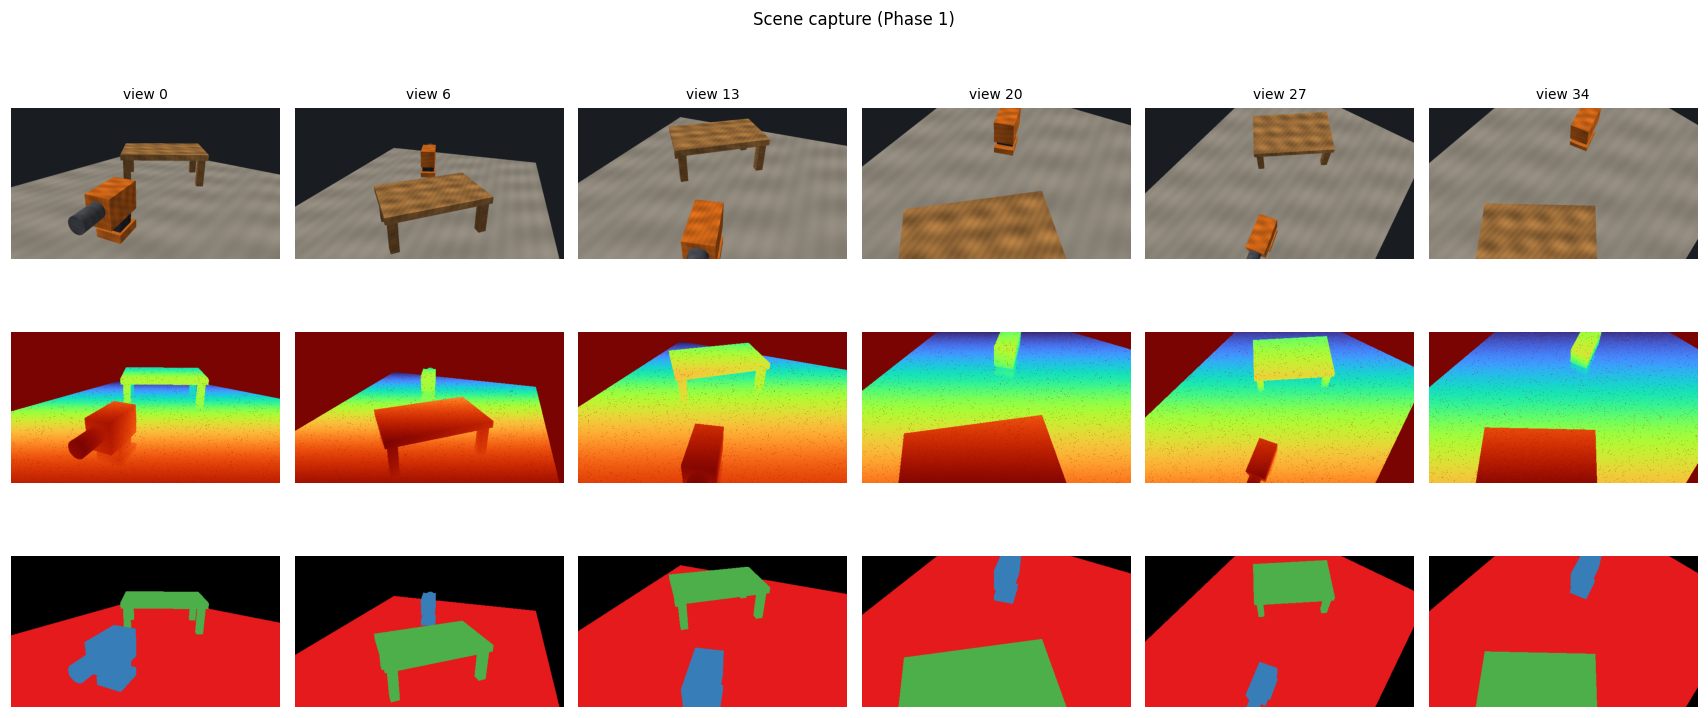

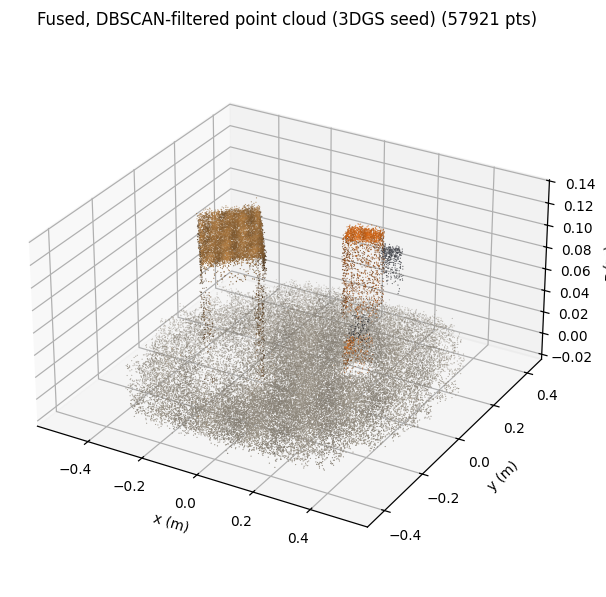

In [22]:
t0 = time.time()
objects = S.build_scene(OBJECTS, seed=0)
capture = S.capture_scene(objects, cfg.capture, device=DEVICE, supersample=2, verbose=True)
print(f"\ncapture: {capture.n_views()} views  |  seed cloud {tuple(capture.seed_points.shape)}  "
      f"|  objects {capture.object_names}  |  {time.time()-t0:.1f}s")

V.show_capture_grid(capture, n=6); plt.show()
V.show_pointcloud(capture.seed_points, colors=capture.seed_colors,
                  title="Fused, DBSCAN-filtered point cloud (3DGS seed)"); plt.show()

---
## 4 · Phase 2a — 2D foundation features

DINOv2 ViT-S/14 patch features (PCA → 64 dims, exactly as in
`dino_dataloader.py`) and the LERF-style multi-scale CLIP pyramid
(`patch_tile_size_range=(0.05, 0.5)`, 10 scales).

**Both run on `cuda:1`.** Sec. VI names ViT-S extraction as the ~140 ms tracking bottleneck
and lists parallelising it as future work; on a T4 ×2 box we can simply put it on the other
card.

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 286MB/s]


[dino] backend=torch.hub/dinov2 pretrained=True
[dino] (35, 50, 90, 64) in 8.1s


open_clip_model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

[clip] backend=open_clip/ViT-B-16/laion2b_s34b_b88k pretrained=True
  clip pyramid scale 1/10 (tile=18px, grid=22x38)
  clip pyramid scale 2/10 (tile=35px, grid=14x25)
  clip pyramid scale 3/10 (tile=53px, grid=14x25)
  clip pyramid scale 4/10 (tile=71px, grid=11x19)
  clip pyramid scale 5/10 (tile=89px, grid=9x15)
  clip pyramid scale 6/10 (tile=108px, grid=7x12)
  clip pyramid scale 7/10 (tile=126px, grid=6x11)
  clip pyramid scale 8/10 (tile=144px, grid=6x9)
  clip pyramid scale 9/10 (tile=161px, grid=5x8)
  clip pyramid scale 10/10 (tile=180px, grid=5x8)
[clip] pyramid built in 228.5s

feature precompute: 236.9s
DINOv2 pretrained: True   OpenCLIP pretrained: True


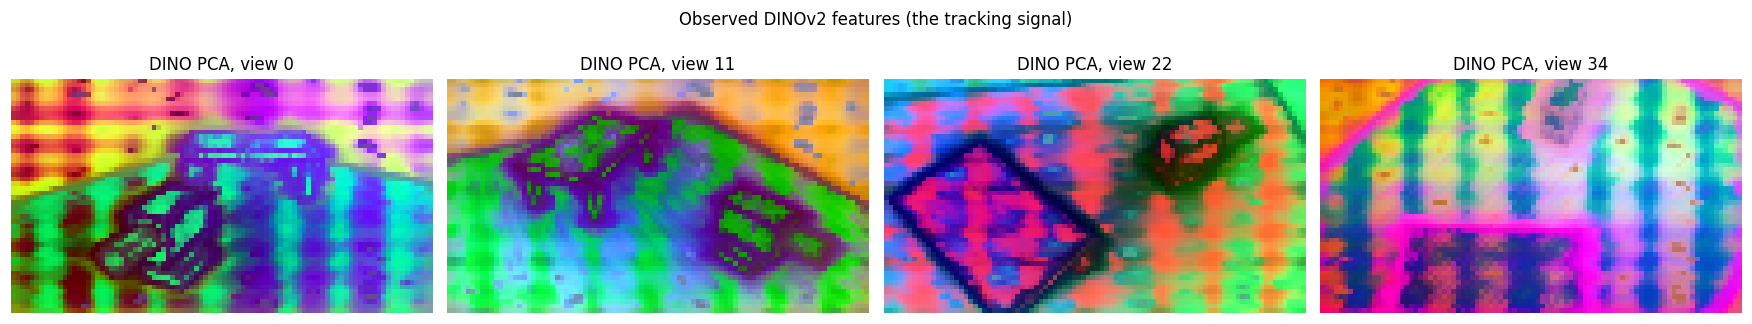

In [23]:
t0 = time.time()
features = precompute_features(
    capture, cfg,
    dino_device=cfg.runtime.feature_device,
    build_clip=True,
    allow_download=INSTALL,
    verbose=True,
)
print(f"\nfeature precompute: {time.time()-t0:.1f}s")
DINO_REAL = features.dino_extractor.is_pretrained
CLIP_REAL = features.clip_encoder.is_pretrained
print(f"DINOv2 pretrained: {DINO_REAL}   OpenCLIP pretrained: {CLIP_REAL}")
if not DINO_REAL:
    print("  !! running on frozen random features -- tracking numbers are a LOWER BOUND")
if not CLIP_REAL:
    print("  !! CLIP is a deterministic stub -- language queries are disabled below")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for j, v in enumerate(np.linspace(0, capture.n_views()-1, 4).astype(int)):
    ax[j].imshow(V.feature_pca_rgb(features.dino[v])); ax[j].set_title(f"DINO PCA, view {v}"); ax[j].axis("off")
plt.suptitle("Observed DINOv2 features (the tracking signal)"); plt.tight_layout(); plt.show()

---
## 5 · Phase 2b — Train the POGS (Sec. IV-B)

One optimisation, five supervision signals:

$$\mathcal{L}=\underbrace{(1-\lambda)\mathcal{L}_1+\lambda(1-\mathrm{SSIM})}_{\text{RGB}}
+0.05\,\underbrace{\big(1-\rho(\hat d, d)\big)}_{\text{Pearson depth, ref [48]}}
+\underbrace{\|\hat f_{\text{DINO}}-f_{\text{DINO}}\|_2^2}_{\text{Sec. IV-B}}
+0.01\!\!\sum_i \mathrm{Var}_{k\in\mathcal{N}(i)} f_k
+\underbrace{\mathcal{L}_{\text{group}}}_{\text{contrastive lift, ref [50]}}
+0.5\,\underbrace{\mathrm{Huber}_{1.25}}_{\text{CLIP}}$$

Learning rates, schedules and the gradient-accumulation groups
(`{'color': 10, 'shs': 10, 'lerf': 3}`) come straight from `pogs_config.py`.

In [24]:
model = POGSModel(capture.seed_points, capture.seed_colors, cfg.model,
                  device=DEVICE, raster_backend=cfg.runtime.raster_backend)
print(f"initialised {model.num_points} gaussians | backend {model.backend}")

t0 = time.time()
log = train_pogs(model, capture, features, cfg, verbose=True)
TRAIN_TIME = time.time() - t0
print(f"\ntrained in {TRAIN_TIME/60:.1f} min -> {model.num_points} gaussians, "
      f"PSNR {log.psnr[-1]:.2f} dB")

initialised 57921 gaussians | backend gsplat


Output()

gsplat: CUDA extension has been set up successfully in 329.95 seconds.

  [    0/4000] loss=0.2288 rgb=0.1840 depth=0.8969 dino=0.0000 clip=0.000 grp=0.000 nnv=0.00 psnr=14.79 N=57921
  [  200/4000] loss=0.2717 rgb=0.0284 depth=0.0062 dino=0.2430 clip=0.000 grp=0.000 nnv=0.00 psnr=28.19 N=57921
  [  400/4000] loss=0.1709 rgb=0.0068 depth=0.0022 dino=0.1636 clip=0.000 grp=0.000 nnv=0.00 psnr=35.80 N=57921
  [  600/4000] loss=0.1403 rgb=0.0046 depth=0.0011 dino=0.1345 clip=0.000 grp=0.000 nnv=0.00 psnr=38.56 N=64339
  [  800/4000] loss=0.1573 rgb=0.0067 depth=0.0116 dino=0.1492 clip=0.000 grp=0.000 nnv=0.00 psnr=34.96 N=70700
  [ 1000/4000] loss=0.0997 rgb=0.0031 depth=0.0008 dino=0.0961 clip=0.000 grp=0.000 nnv=0.00 psnr=40.32 N=76931
  [ 1200/4000] loss=5.5588 rgb=0.0041 depth=0.0009 dino=0.1477 clip=0.000 grp=0.000 nnv=5.41 psnr=39.14 N=83447
  [ 1400/4000] loss=1.1217 rgb=0.0045 depth=0.0029 dino=0.1511 clip=0.000 grp=0.000 nnv=0.97 psnr=38.49 N=90495
  [ 1600/4000] loss=0.6342 rgb=0.0026 depth=0.0016 dino=0.1503 clip=0.000 grp=0.000 nnv=0.48 psnr=41.10 

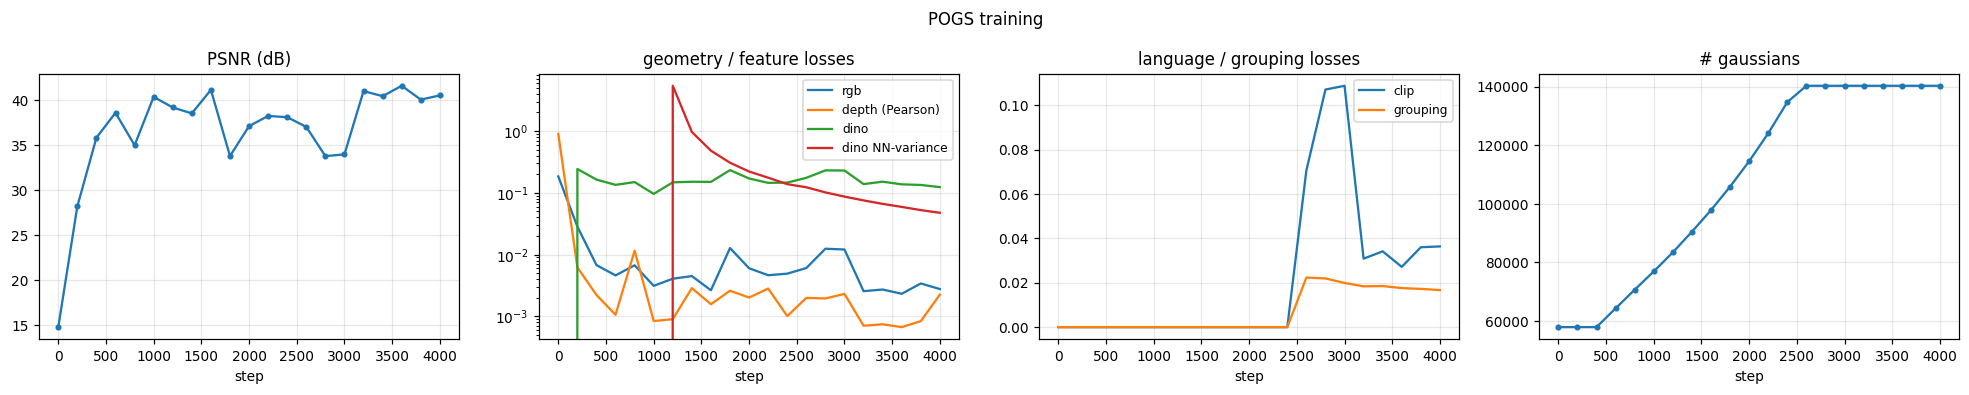

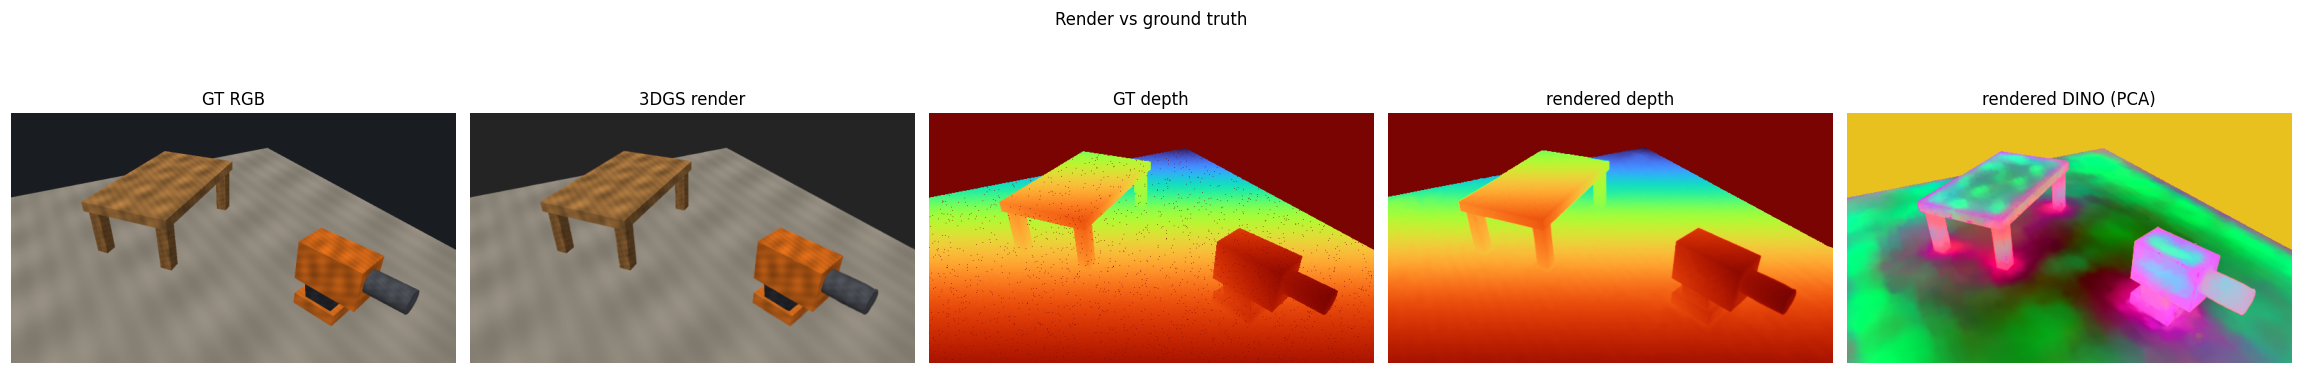

In [25]:
V.plot_training(log); plt.show()
V.compare_render(model, capture, view=capture.n_views()//3, cfg=cfg); plt.show()

---
## 6 · Phase 2c — Grouping & the Persistent Object Representation (Sec. IV-B / IV-C)

> *"Before the tracking phase begins, the system must identify and segment individual
> objects within the scene. As proposed in GARField, this is accomplished by clustering the
> group features using HDBSCAN. The result is a mapping from each 3D gaussian to a mask and
> label."*
>
> *"For each gaussian cluster, the system uses the centroid of gaussians within that cluster
> as the object frame, canonicalized such that the initial pose of each object is rotated to
> align with the world frame."*

The paper does the "which clusters do I track" step interactively (*Click → Crop to Click →
Add Crop to Group List*). We replace the mouse with either a geometry filter or — when real
CLIP weights loaded — the paper's own natural-language query.

  clustering 98114 / 140299 gaussians ... done in 2450.7s -> 3 clusters ([18371, 87944, 33984])

cluster quality vs ground truth: {'purity': 0.9921453467237827, 'n_clusters': 3, 'n_gt_objects': 3}
  cluster 0: 18371 gaussians, footprint 0.390 m^2, share 0.13 -> BACKGROUND
  cluster 1: 87944 gaussians, footprint 0.897 m^2, share 0.63 -> BACKGROUND
  cluster 2: 33984 gaussians, footprint 0.513 m^2, share 0.24 -> BACKGROUND

geometry filter kept 0 of 2; using ground-truth selection so the tracking study is well posed

tracked objects: 2  clusters [0, 2]  -> gt ids {0: 1, 1: 2}
centroids (object frames):
 [[ 0.21229611  0.07712789  0.08005156]
 [-0.17603473 -0.0577058   0.0911237 ]]


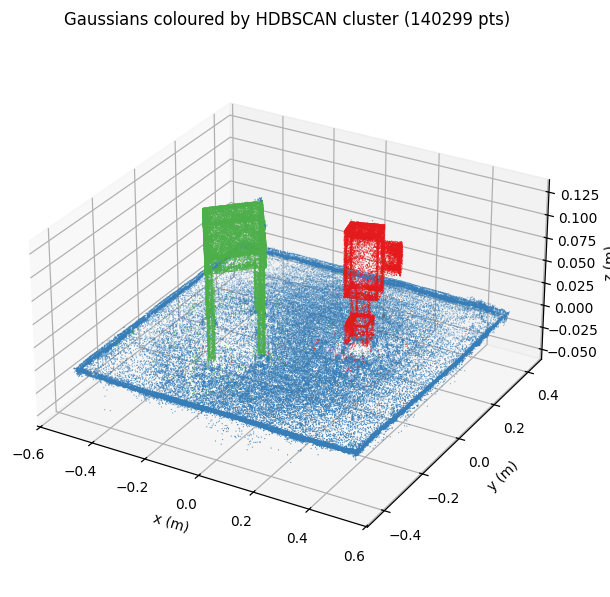

In [26]:
labels = G.cluster_scene(model, cfg.grouping, verbose=True)
gt_ids = G.assign_gt_ids(model, capture)                 # evaluation only
print("\ncluster quality vs ground truth:", G.cluster_purity(labels, gt_ids))

keep = G.select_object_clusters(model, labels, method="geometry", verbose=True)
if len(keep) < len(OBJECTS):
    print(f"\ngeometry filter kept {len(keep)} of {len(OBJECTS)}; using ground-truth selection "
          f"so the tracking study is well posed")
    keep = G.select_object_clusters(model, labels, method="gt", gt_ids=gt_ids, verbose=False)

groups   = G.build_object_groups(model, labels, keep_clusters=keep, min_gaussians=60)
group2gt = G.match_clusters_to_gt(groups, gt_ids)
print(f"\ntracked objects: {groups.num_groups}  clusters {groups.cluster_ids}  -> gt ids {group2gt}")
print("centroids (object frames):\n", groups.centroids().cpu().numpy())

V.show_pointcloud(model.gauss_params['means'].data, labels=labels,
                  title="Gaussians coloured by HDBSCAN cluster"); plt.show()

In [27]:
# Language querying (Sec. IV-B "Language Features" / IV-E). Needs real OpenCLIP weights.
if CLIP_REAL:
    for q in OBJECTS:
        gi, per_group, rel = G.localize_query(model, features.clip_encoder, groups, q)
        print(f"query {q!r:16s} -> group {gi} ({groups.names[gi]}), "
              f"relevancy per group {np.round(per_group, 3)}")
else:
    print("skipped: OpenCLIP weights unavailable (deterministic stub carries no semantics).")
    print("Turn on internet and re-run cell 4 to enable language queries.")

query 'power drill'    -> group 0 (cluster_0), relevancy per group [0.428 0.311]
query 'wooden shelf'   -> group 1 (cluster_2), relevancy per group [0.434 0.454]


---
## 7 · Phase 3 — the manipulation sequence

A static third-person camera (the paper's ZED 2) watches a human hand perturb both objects,
with scripted **object reset** events following the Sec. V-A protocol.

  tracking frame 1/60
  tracking frame 21/60
  tracking frame 41/60
  tracking frame 60/60

60 frames in 6.8s | resets at [19, 39, 59] | hand visible on 20 frames


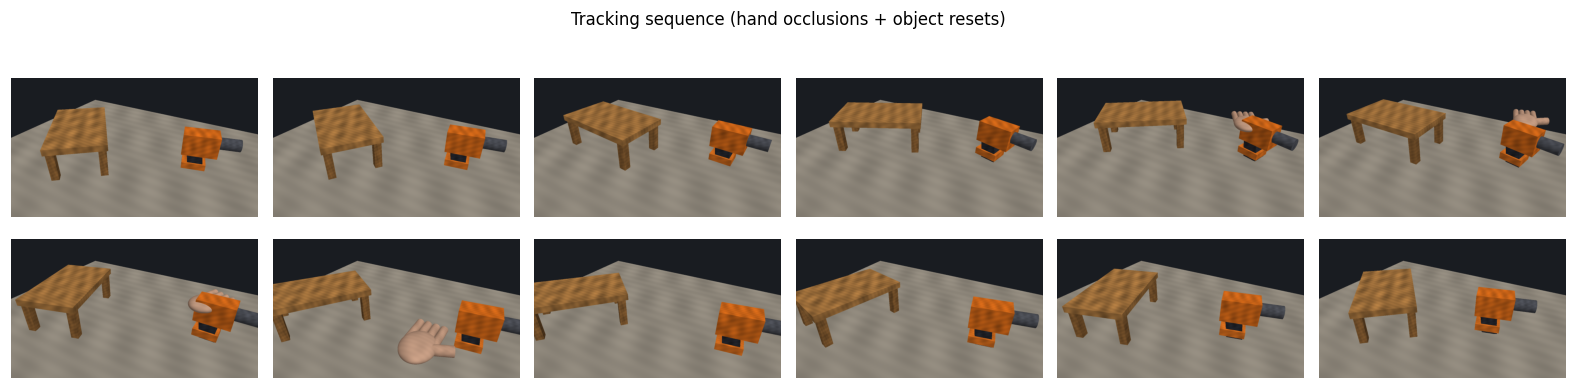

In [28]:
t0 = time.time()
seq = S.make_tracking_sequence(
    capture, n_frames=N_FRAMES, n_resets=N_RESETS, tier=TIER,
    with_hand=True, device=DEVICE, supersample=2, seed=7, verbose=True,
)
print(f"\n{len(seq.frames)} frames in {time.time()-t0:.1f}s | "
      f"resets at {[i for i,f in enumerate(seq.frames) if f.reset_event]} | "
      f"hand visible on {sum(f.hand_visible for f in seq.frames)} frames")

idx = np.linspace(0, len(seq.frames)-1, 12).astype(int)
V.montage([V.to_uint8(seq.frames[i].rgb) for i in idx], cols=6,
          title="Tracking sequence (hand occlusions + object resets)"); plt.show()

dino_fn = lambda x: features.dino_extractor.pca_feats(x).squeeze(0)
model_points = {oid: S.sample_object_model_points(capture.scene, oid, n=800).numpy()
                for oid in set(group2gt.values()) if oid >= 0}

---
## 8 · Tracking with POGS (Sec. IV-D) — the paper's method, unmodified

> *"Inspired by RSRD, the core of the tracking algorithm is the computation of the loss
> between the distilled DINO features of the rendered Gaussian Splat and the observed
> images. ... POGS also includes a depth loss term ... Each Gaussian cluster pose parameter
> is optimized independently."*

Initialisation is 100 DINO-only Adam steps on the full frame, then 70 more with depth and
per-object ROI crops; every subsequent frame gets 25 steps.

In [29]:
res = {}
res["POGS (paper)"] = E.track_sequence(
    model, groups, seq, dino_fn, cfg, group2gt, name="POGS (paper)",
    kalman_cfg=None, model_points=model_points,
    save_renders=True, render_every=max(len(seq.frames)//12, 1), verbose=True,
)
import pandas as pd
display(pd.DataFrame([res["POGS (paper)"].summary()]).T.rename(columns={0: "POGS (paper)"}))

  [POGS (paper)] init: coarse=3.4094 fine=3.9453 in 22.1s
    [POGS (paper)] frame   0/60  loss=3.9457  pos_err=2.20 cm  rot=11.8 deg  iters=25  3500 ms
    [POGS (paper)] frame  10/60  loss=4.1173  pos_err=3.92 cm  rot=29.8 deg  iters=25  3641 ms
    [POGS (paper)] frame  20/60  loss=4.0716  pos_err=11.19 cm  rot=54.3 deg  iters=25  3751 ms
    [POGS (paper)] frame  30/60  loss=3.9029  pos_err=1.75 cm  rot=17.8 deg  iters=25  3747 ms
    [POGS (paper)] frame  40/60  loss=3.9628  pos_err=6.44 cm  rot=66.0 deg  iters=25  3732 ms
    [POGS (paper)] frame  50/60  loss=3.9848  pos_err=5.45 cm  rot=47.7 deg  iters=25  3789 ms
    [POGS (paper)] frame  59/60  loss=3.9129  pos_err=3.48 cm  rot=33.0 deg  iters=25  3843 ms


,POGS (paper)
name,POGS (paper)
mean_pos_err_cm,5.814383
std_pos_err_cm,5.358618
mean_rot_err_deg,39.876719
mean_add_cm,8.909947
mean_adds_cm,4.41271
max_consecutive_or,1
mean_consecutive_or,0.333333
frac_lost,0.8
pos_err_occluded_cm,7.664813


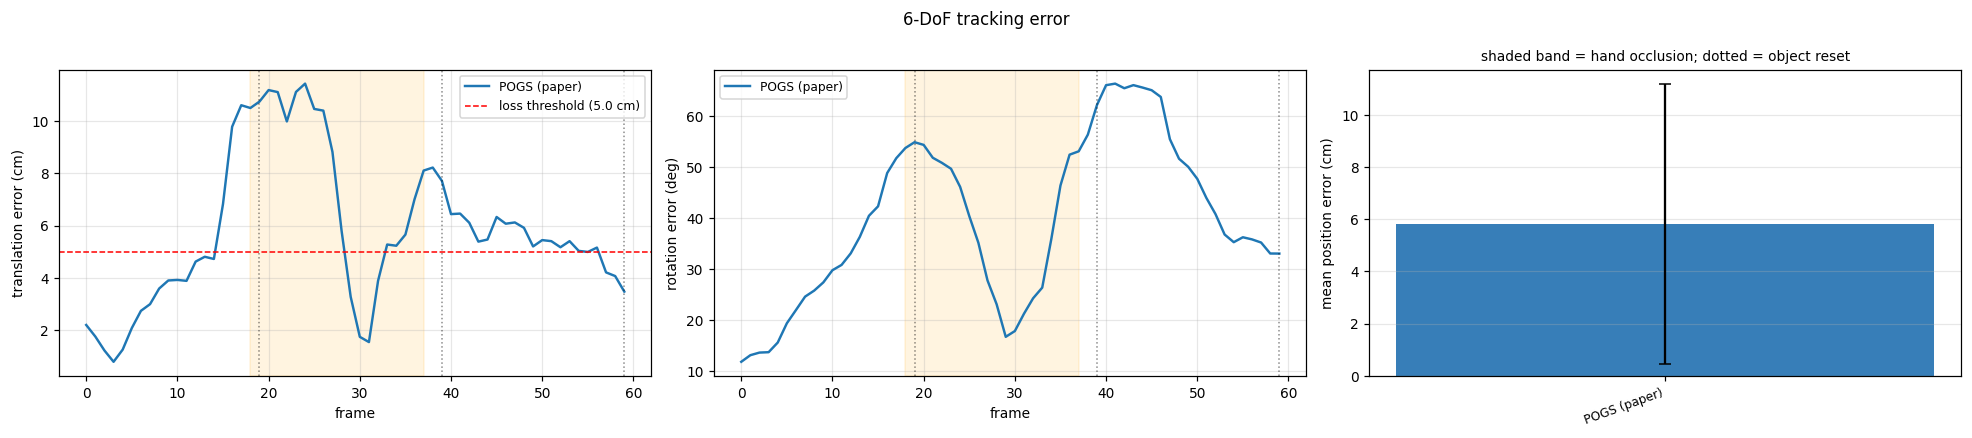

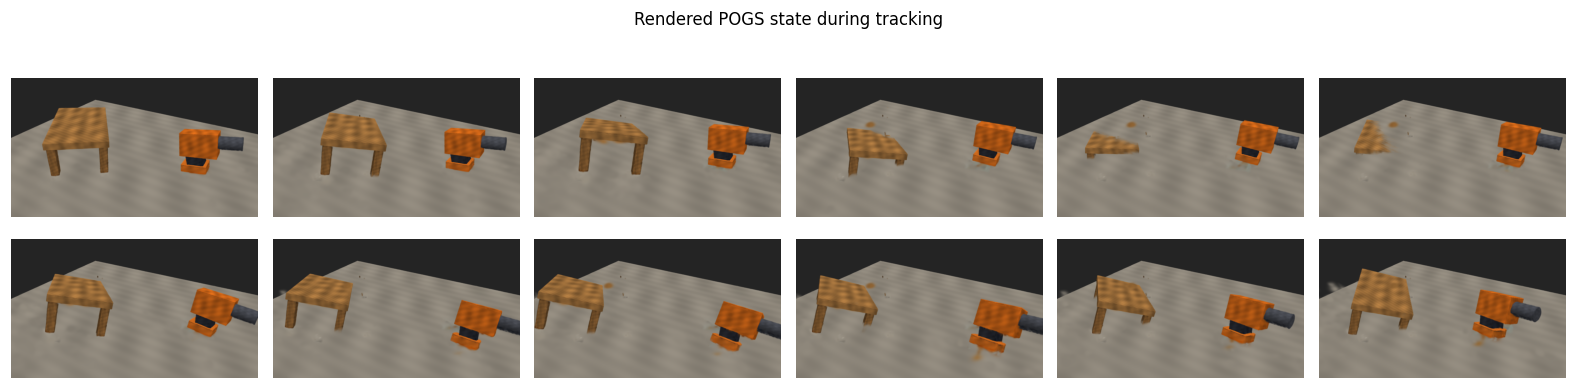

In [30]:
V.plot_tracking(res); plt.show()
if res["POGS (paper)"].renders:
    V.montage(res["POGS (paper)"].renders, cols=6, title="Rendered POGS state during tracking"); plt.show()
    V.save_video(res["POGS (paper)"].renders, f"{cfg.runtime.output_dir}/pogs_tracking.mp4", fps=5)

---
## 9 · Ablations — reproducing the structure of Table I

The paper reports two ablations per task: **No Depth** (depth input removed) and
**No DINO** (RGB substituted for DINO features). Both collapse in the paper; both should
collapse here.

,mean_pos_err_cm,std_pos_err_cm,mean_rot_err_deg,mean_add_cm,mean_adds_cm,max_consecutive_or,mean_consecutive_or,frac_lost,pos_err_occluded_cm,pos_err_clear_cm,fps,mean_iters,init_time_s,depth_drop_rate
name,,,,,,,,,,,,,,
POGS,5.881,5.246,40.250,9.109,4.375,1,0.333,0.767,7.554,5.044,0.268,25.0,21.661,0.0
No Depth,10.545,9.092,45.714,13.959,6.901,0,0.000,0.900,9.465,11.085,0.283,25.0,21.272,0.0
No DINO,8.232,7.078,39.645,10.425,5.636,0,0.000,1.000,9.065,7.815,0.514,25.0,9.441,0.0


POGS       mean position error   5.88 cm   (+0% vs POGS)
No Depth   mean position error  10.54 cm   (+79% vs POGS)
No DINO    mean position error   8.23 cm   (+40% vs POGS)


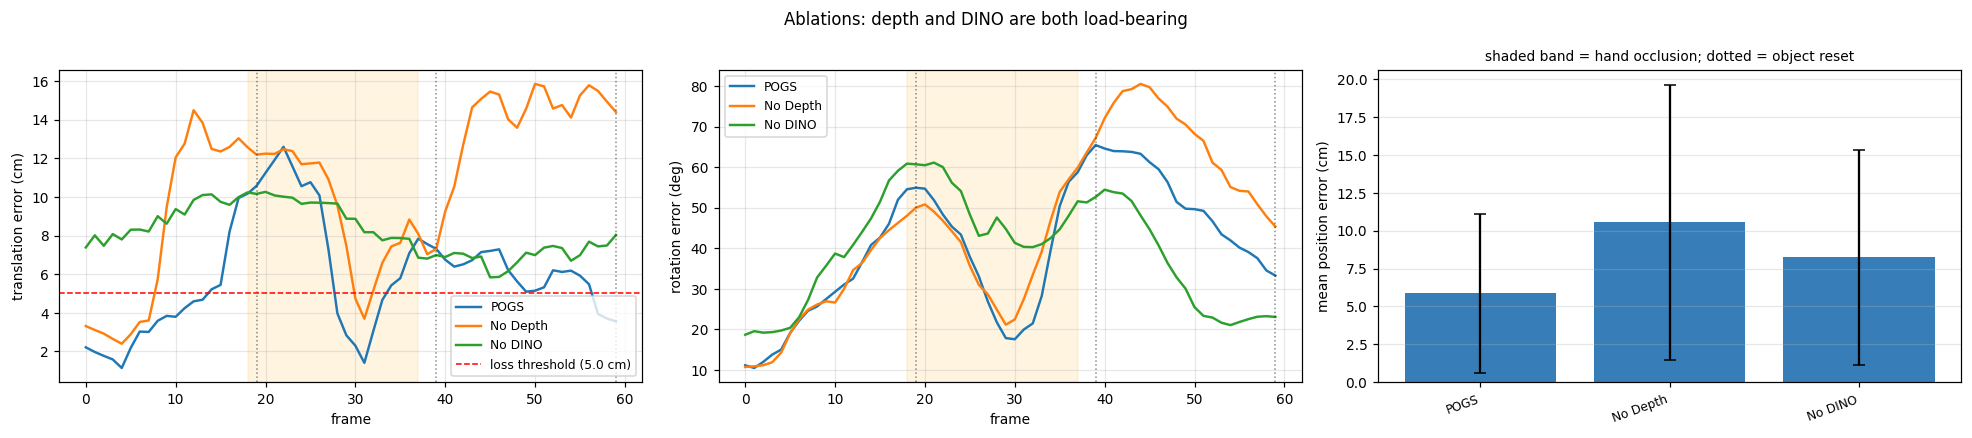

In [31]:
abl = E.run_ablations(model, groups, seq, dino_fn, cfg, group2gt,
                      model_points=model_points,
                      variants=("POGS", "No Depth", "No DINO"), verbose=False)
tab = E.results_table(abl)
display(tab)

base = abl["POGS"].mean_position_error_cm()
for k, v in abl.items():
    d = v.mean_position_error_cm()
    print(f"{k:10s} mean position error {d:6.2f} cm   ({(d/base-1)*100:+.0f}% vs POGS)")
V.plot_tracking(abl, title="Ablations: depth and DINO are both load-bearing"); plt.show()

---
## 9.1 · Table I — Sequential Object Reset (Sec. V-A)

> *"The goal of the object-reset experiment is to use natural language to query for an
> object to grasp and another query for where the grasped object will be placed. After each
> object reset, a human will randomly reconfigure both objects and the process is repeated
> until failure."*

Every row of Table I, scored the way the real experiment scored it. At each scripted reset
the robot plans a grasp on the pick object **using POGS's estimate of where it is** — the
Gaussian means at the estimated pose, which is exactly the cloud Sec. IV-E hands to
Contact-GraspNet — and sets it down on the place object, again using POGS's estimate.
Both actions are then checked against ground truth:

* **pick** succeeds when the planned jaw contacts land on the object's true surface;
  a pose error larger than a gripper pad closes the jaws on empty air, which is the
  paper's stated failure mode.
* **place** error is the distance between the intended and the actual placement point —
  the quantity the paper measured with calipers.
* **Consecutive OR** counts resets where both succeeded.

Both perturbation tiers are run: Tier 1 rotates objects up to 90° about the vertical axis,
Tier 2 to any magnitude.

In [32]:
gt2group = {v: k for k, v in group2gt.items()}
PICK, PLACE = OBJECTS[0], OBJECTS[1]
id_of = {o.name: o.obj_id for o in objects}
gi_pick, gi_place = gt2group.get(id_of[PICK]), gt2group.get(id_of[PLACE])
print(f"pick '{PICK}' -> group {gi_pick} | place '{PLACE}' -> group {gi_place}")

reset_results = []
for tier in (1, 2):
    seq_t = seq if tier == 1 else S.make_tracking_sequence(
        capture, n_frames=N_FRAMES, n_resets=N_RESETS, tier=2,
        device=DEVICE, supersample=2, seed=11, verbose=False)
    abl_t = E.run_ablations(model, groups, seq_t, dino_fn, cfg, group2gt,
                            model_points=model_points,
                            variants=("POGS", "No Depth", "No DINO"), verbose=False)
    for nm, abl_r in abl_t.items():
        reset_results.append(E.object_reset_protocol(
            model, groups, seq_t, dino_fn, cfg, group2gt,
            pick_group=gi_pick, place_group=gi_place, model_points=model_points,
            name=nm, tier=tier, pick_name=PICK, place_name=PLACE,
            result=abl_r, verbose=(nm == "POGS")))

display(E.table_one(reset_results))

pick 'power drill' -> group 0 | place 'wooden shelf' -> group 1
    reset @frame  19: pick FAIL (contact 2.10 cm, 31 grasps)  place err 19.67 cm
    reset @frame  39: pick FAIL (contact 5.79 cm, 28 grasps)  place err 15.14 cm
    reset @frame  59: pick OK  (contact 0.77 cm, 29 grasps)  place err 47.35 cm
    reset @frame  19: pick FAIL (contact 2.50 cm, 33 grasps)  place err 3.86 cm
    reset @frame  39: pick FAIL (contact 5.32 cm, 30 grasps)  place err 11.65 cm
    reset @frame  59: pick FAIL (contact 2.11 cm, 36 grasps)  place err 9.16 cm


,power drill to wooden shelf | Tier 1 | POGS,power drill to wooden shelf | Tier 1 | No Depth,power drill to wooden shelf | Tier 1 | No DINO,power drill to wooden shelf | Tier 2 | POGS,power drill to wooden shelf | Tier 2 | No Depth,power drill to wooden shelf | Tier 2 | No DINO
Max Consecutive OR,0,0,0,0,0,0
Mean Consecutive OR,0.0,0.0,0.0,0.0,0.0,0.0
Successful Pick Rate,1/3,0/3,0/3,0/3,0/3,1/3
Successful Place Rate,0/1,0/0,0/0,0/0,0/0,0/1
Mean Position Error (cm),27.39,12.41,16.77,8.22,38.79,12.3
Std Position Error (cm),14.24,4.82,2.58,3.25,26.66,3.15


---
## 10 · Extension — SE(3) Kalman filter *(not in the paper)*

The released tracker is memoryless. `rigid_group_optimizer.step` records `prev_part_deltas`
and `tracking/utils.py` even ships an `extrapolate_poses` constant-velocity helper — but
**nothing in the release ever calls it**. Every frame restarts Adam from the previous pose,
never from a *predicted* one. Sec. VI names the price: *"objects had to be moved slowly with
no sudden motions or quick changes in direction to avoid losing track of them"*, at 5 Hz.

We add an error-state (multiplicative) KF per object:

$$\text{nominal }(p,q,v,\omega),\qquad
\text{error }[\delta p,\delta v,\delta\theta,\delta\omega]\in\mathbb R^{12}$$
$$\text{predict: } p\!\leftarrow\!p+v\,\Delta t,\quad q\!\leftarrow\!q\otimes\mathrm{Exp}(\omega\Delta t)$$
$$\text{update: } z=(p_{\text{meas}},q_{\text{meas}}),\quad
\nu=\big(p_{\text{meas}}-p,\ \mathrm{Log}(q^{-1}q_{\text{meas}})\big)$$

spent three ways: **warm start**, **outlier gating** (occlusion rejection), and **adaptive
iteration count**.

,mean_pos_err_cm,std_pos_err_cm,mean_rot_err_deg,mean_add_cm,mean_adds_cm,max_consecutive_or,mean_consecutive_or,frac_lost,pos_err_occluded_cm,pos_err_clear_cm,fps,mean_iters,init_time_s,depth_drop_rate
name,,,,,,,,,,,,,,
POGS,5.881,5.246,40.250,9.109,4.375,1,0.333,0.767,7.554,5.044,0.268,25.000,21.661,0.0
POGS + KF,7.476,8.013,45.447,11.109,5.378,0,0.000,0.850,7.741,7.343,0.319,21.067,21.673,0.0



filter diagnostics: {'updates': 110, 'rejected': 0, 'reject_rate': 0.0, 'mean_innov_pos_m': 0.029160294127089405, 'mean_innov_rot_deg': 4.810890024774748, 'mean_iters': 21.066666666666666}


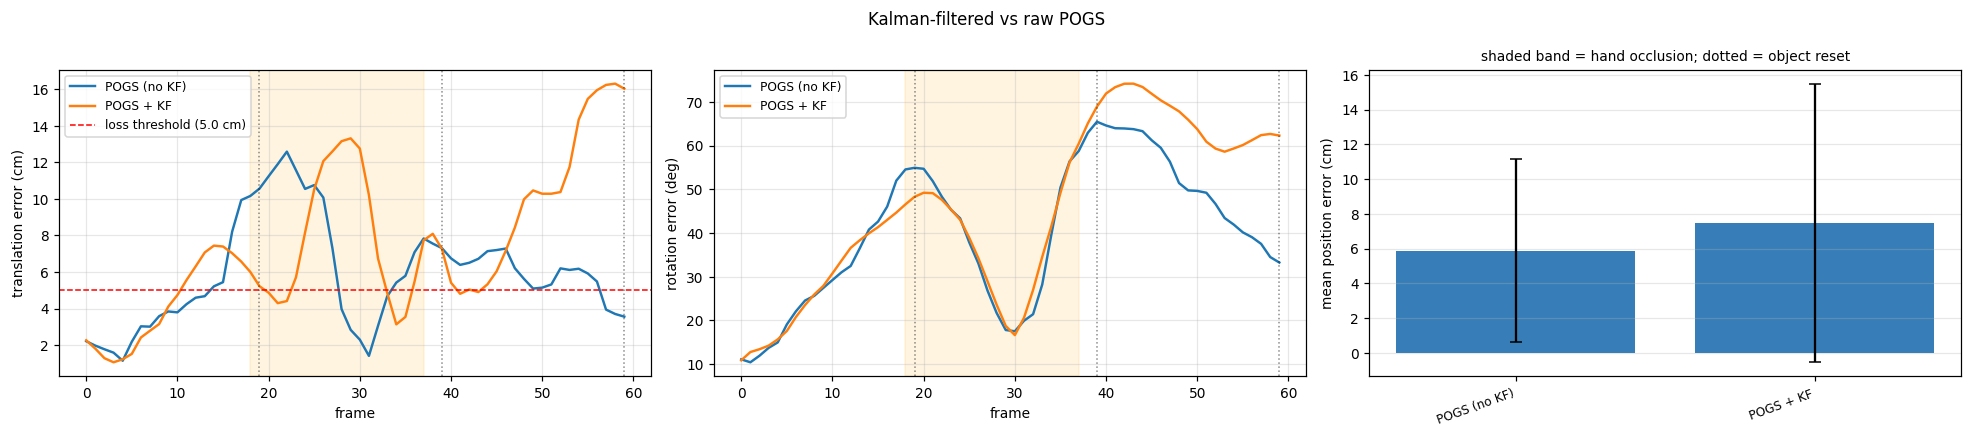

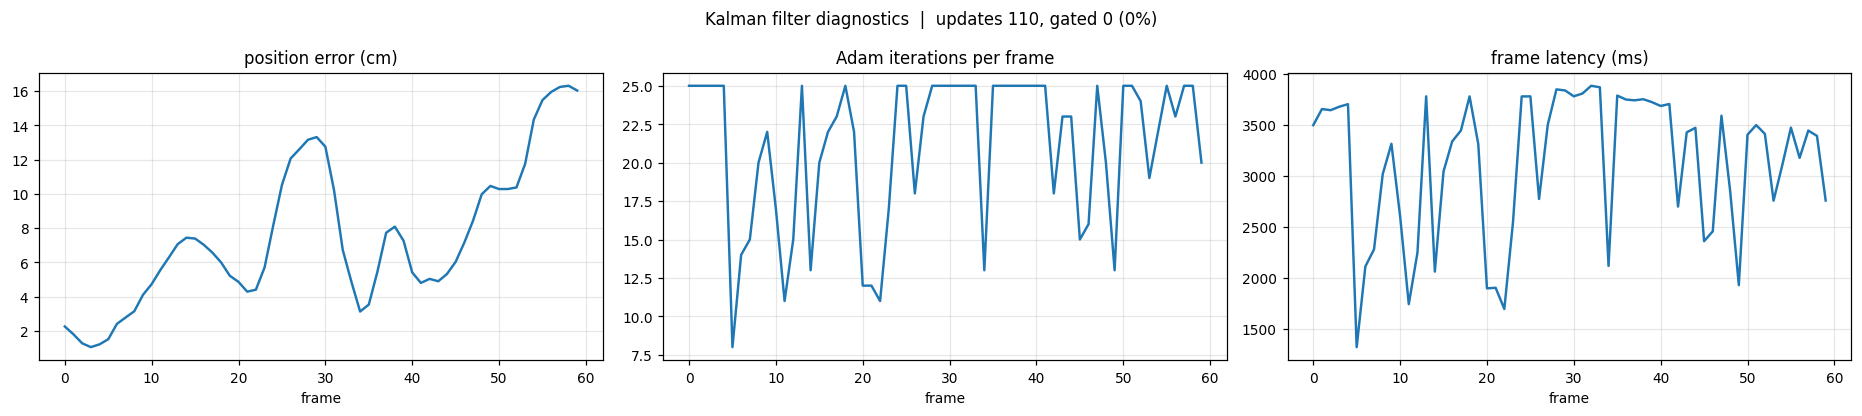

In [33]:
kf_res = {"POGS (no KF)": abl["POGS"]}
kf_res["POGS + KF"] = E.track_sequence(
    model, groups, seq, dino_fn, cfg, group2gt, name="POGS + KF",
    kalman_cfg=cfg.kalman, model_points=model_points, verbose=False,
)
display(E.results_table(kf_res))
print("\nfilter diagnostics:", kf_res["POGS + KF"].kalman_summary)
V.plot_tracking(kf_res, title="Kalman-filtered vs raw POGS"); plt.show()
V.plot_kalman(kf_res["POGS + KF"]); plt.show()

### 10.1 · Where should the filter switch on?

`start_step` defers engagement: before it, vanilla POGS runs and the filter only buffers
measurements; at `start_step` it bootstraps $(p,q)$ from the last measurement and
$(v,\omega)$ from a finite difference; after that it predicts, warm-starts, and fuses.

The sweep below is the direct answer to *"what changes if we start the Kalman filter at
step 5?"*

/kaggle/working/pogs_kaggle/tracking.py:397: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  amax = float(a.max())


,mean_pos_err_cm,std_pos_err_cm,mean_rot_err_deg,mean_add_cm,mean_adds_cm,max_consecutive_or,mean_consecutive_or,frac_lost,pos_err_occluded_cm,pos_err_clear_cm,fps,mean_iters,init_time_s,depth_drop_rate
name,,,,,,,,,,,,,,
no KF,6.406,5.864,40.363,9.506,4.688,1,0.333,0.800,9.010,5.104,0.268,25.000,21.569,0.0
KF@0,7.804,9.023,45.359,11.257,5.471,0,0.000,0.767,8.615,7.399,0.361,18.600,21.771,0.0
KF@2,10.579,16.814,46.912,13.687,7.781,0,0.000,0.817,8.833,11.452,0.348,19.467,21.516,0.0
KF@5,23.193,44.030,50.877,25.427,19.468,0,0.000,0.817,9.393,30.093,0.341,19.933,21.521,0.0
KF@10,6.418,6.533,40.936,9.526,4.794,0,0.000,0.783,8.633,5.311,0.318,20.750,21.715,0.0
KF@20,6.703,6.810,40.243,9.375,4.977,0,0.000,0.783,8.063,6.023,0.298,22.350,21.590,0.0


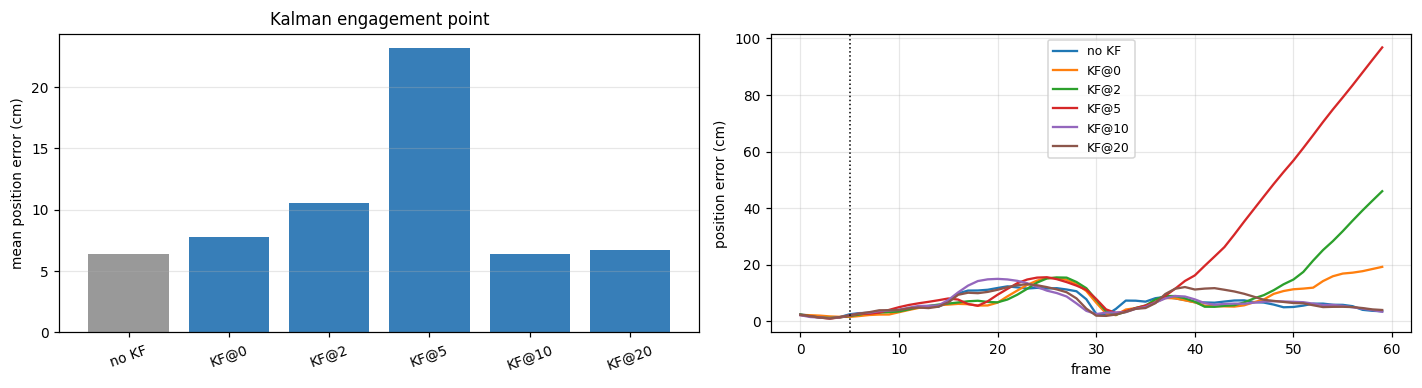

In [34]:
sweep = E.kalman_start_step_sweep(
    model, groups, seq, dino_fn, cfg, group2gt,
    start_steps=(0, 2, 5, 10, 20), model_points=model_points, verbose=False,
)
sw = E.results_table(sweep); display(sw)

names = list(sweep.keys())
errs  = [sweep[n].mean_position_error_cm() for n in names]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(range(len(names)), errs, color=["0.6"] + ["#377eb8"]*(len(names)-1))
ax[0].set_xticks(range(len(names))); ax[0].set_xticklabels(names, rotation=20)
ax[0].set_ylabel("mean position error (cm)"); ax[0].grid(alpha=.3, axis="y")
ax[0].set_title("Kalman engagement point")
for n in names:
    ax[1].plot(np.nanmean(sweep[n].trans_err_cm, axis=1), label=n, lw=1.5)
ax[1].axvline(5, color="k", ls=":", lw=1); ax[1].legend(fontsize=8)
ax[1].set_xlabel("frame"); ax[1].set_ylabel("position error (cm)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### 10.2 · Does it make inference faster?

Speed in POGS is bought by cutting Adam steps per frame. Without a motion model that costs
accuracy immediately, because the optimiser starts one frame behind. With the filter it
starts on the *prediction*, so the same budget buys more.

,mean_pos_err_cm,mean_rot_err_deg,fps,mean_iters
name,,,,
25 iters,13.119,39.701,0.267,25.0
25 iters + KF,6.292,41.085,0.266,25.0
15 iters,11.190,40.434,0.430,15.0
15 iters + KF,13.841,36.336,0.435,15.0
8 iters,9.266,39.608,0.791,8.0
8 iters + KF,28.647,35.772,0.802,8.0


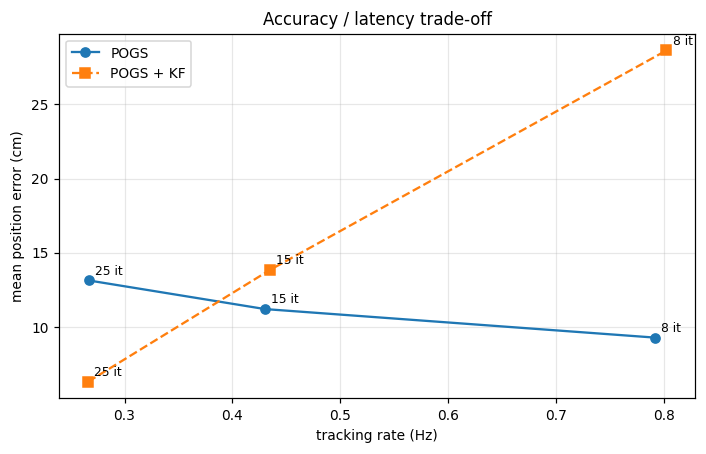

serial ROI DINO        :  0.32 Hz   pos err 7.48 cm
prefetched onto cuda:1 :  0.33 Hz   pos err 17.81 cm
speed-up               : 1.02x


In [35]:
speed = E.speed_study(model, groups, seq, dino_fn, cfg, group2gt,
                      iter_counts=(25, 15, 8), with_kalman=True,
                      model_points=model_points, verbose=False)
sp = E.results_table(speed); display(sp[["mean_pos_err_cm", "mean_rot_err_deg", "fps", "mean_iters"]])

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for tag, mark in (("", "o-"), (" + KF", "s--")):
    xs = [speed[f"{n} iters{tag}"].fps() for n in (25, 15, 8)]
    ys = [speed[f"{n} iters{tag}"].mean_position_error_cm() for n in (25, 15, 8)]
    ax.plot(xs, ys, mark, label=f"POGS{tag or ''}")
    for n, x, y in zip((25, 15, 8), xs, ys):
        ax.annotate(f"{n} it", (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("tracking rate (Hz)"); ax.set_ylabel("mean position error (cm)")
ax.set_title("Accuracy / latency trade-off"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

# The other half of the speed story: move the ViT off the critical path onto cuda:1.
# During tracking POGS never uses the full-frame DINO map -- the loss runs on per-object
# ROI crops -- so the per-frame ViT cost is K extractions, and prefetching only helps if
# frame t+1's ROIs are known one frame early. The Kalman prediction is what supplies them,
# so the two extensions compose rather than merely coexist.
if N_GPU > 1:
    par = E.track_sequence(model, groups, seq, dino_fn, cfg, group2gt,
                           name="POGS + KF + prefetch", kalman_cfg=cfg.kalman,
                           model_points=model_points, prefetch_dino=True, verbose=False)
    a, b = kf_res["POGS + KF"], par
    print(f"serial ROI DINO        : {a.fps():5.2f} Hz   pos err {a.mean_position_error_cm():.2f} cm")
    print(f"prefetched onto cuda:1 : {b.fps():5.2f} Hz   pos err {b.mean_position_error_cm():.2f} cm")
    print(f"speed-up               : {b.fps()/max(a.fps(),1e-9):.2f}x")
    kf_res["POGS + KF + prefetch"] = par
else:
    print("single GPU: ROI DINO prefetch skipped (needs a second device to overlap onto)")

---
## 11 · Online vs offline tracking

POGS as shipped is strictly **causal**: frame $t$ only ever sees frames $\le t$. That is
forced by the application — the UR5 has to act on the current estimate. If the whole
sequence is available first, the same measurements can be smoothed non-causally, which
bounds how much the online constraint actually costs.

,mean_pos_err_cm,std_pos_err_cm,mean_rot_err_deg,mean_add_cm,mean_adds_cm,max_consecutive_or,mean_consecutive_or,frac_lost,pos_err_occluded_cm,pos_err_clear_cm,fps,mean_iters,init_time_s,depth_drop_rate
name,,,,,,,,,,,,,,
online (causal),16.915,29.028,40.79,18.932,13.572,0,0.0,0.783,8.223,21.261,0.316,21.25,21.53,0.0
offline (smoothed),16.741,29.023,40.70,18.932,13.572,0,0.0,0.783,7.958,21.132,0.316,21.25,21.53,0.0


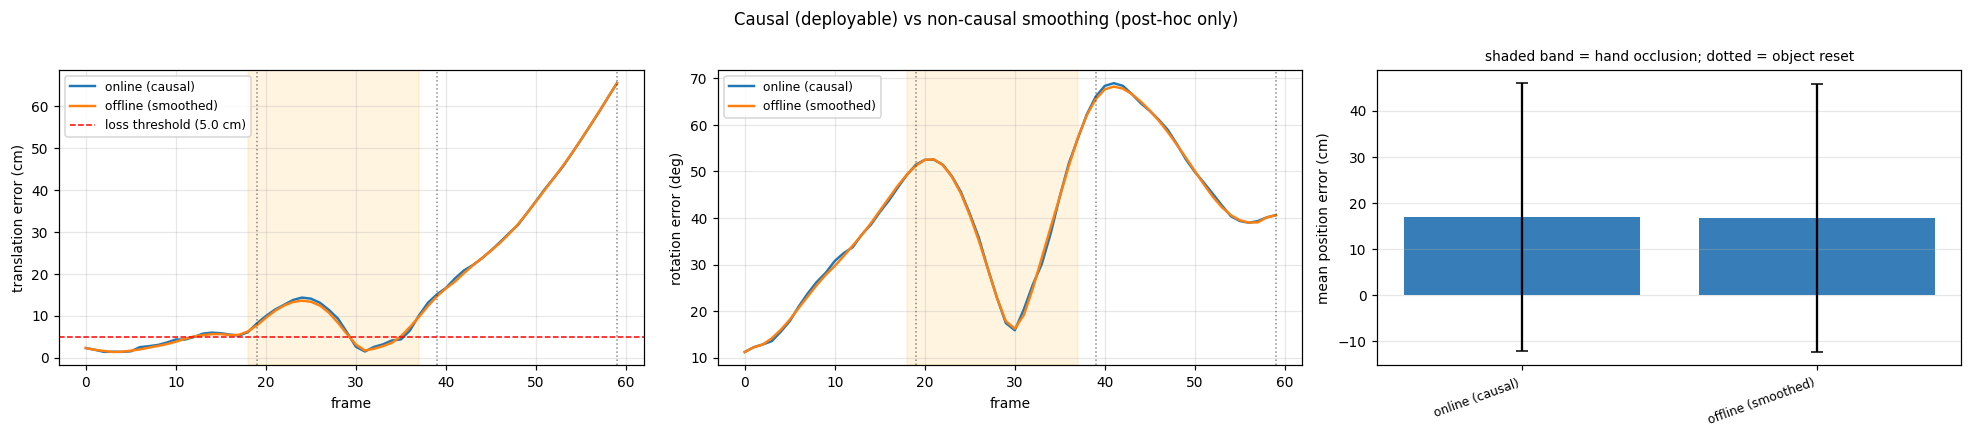

In [36]:
oo = E.online_vs_offline(model, groups, seq, dino_fn, cfg, group2gt,
                         model_points=model_points, verbose=False)
display(E.results_table(oo))
V.plot_tracking(oo, title="Causal (deployable) vs non-causal smoothing (post-hoc only)"); plt.show()

### 11.1 · Two objects: are they really independent?

> *"Each Gaussian cluster pose parameter is optimized independently, allowing POGS to track
> multiple moving objects, without imposing constraints on their relative movements."*

Independence is a modelling choice, and its cost shows up exactly when the two objects
interact: mutual occlusion, and ROI overlap that lets one object's pixels drive the other's
gradient.

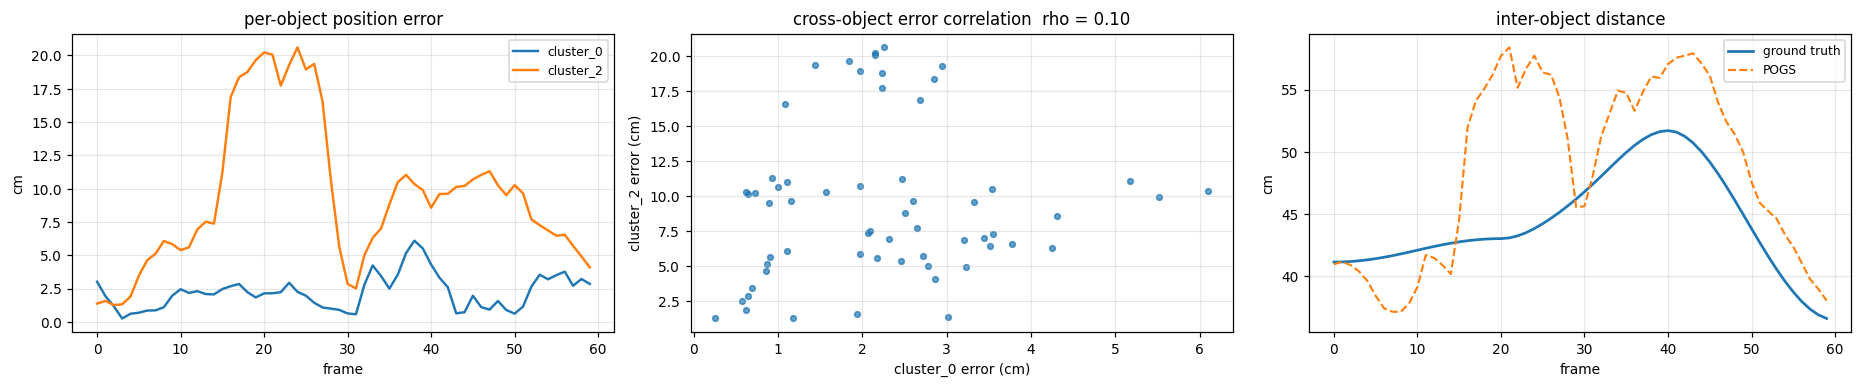

position error while a hand occludes : 7.66 cm
position error with a clear view     : 4.89 cm


In [37]:
r = res["POGS (paper)"]
K = r.trans_err_cm.shape[1]
names = [groups.names[i] for i in range(K)]

fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
for i in range(K):
    ax[0].plot(r.trans_err_cm[:, i], label=names[i], lw=1.6)
ax[0].set_title("per-object position error"); ax[0].set_xlabel("frame")
ax[0].set_ylabel("cm"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)

# do the two objects' errors move together?  (they should not, if truly independent)
if K >= 2:
    a, b = r.trans_err_cm[:, 0], r.trans_err_cm[:, 1]
    ok = ~(np.isnan(a) | np.isnan(b))
    rho = np.corrcoef(a[ok], b[ok])[0, 1] if ok.sum() > 3 else np.nan
    ax[1].scatter(a[ok], b[ok], s=14, alpha=.7)
    ax[1].set_xlabel(f"{names[0]} error (cm)"); ax[1].set_ylabel(f"{names[1]} error (cm)")
    ax[1].set_title(f"cross-object error correlation  rho = {rho:.2f}"); ax[1].grid(alpha=.3)

# 3D separation between the two tracked objects over time
if K >= 2:
    sep = np.linalg.norm(r.pred_poses[:, 0, :3, 3] - r.pred_poses[:, 1, :3, 3], axis=-1) * 100
    sep_gt = np.linalg.norm(r.gt_poses[:, 0, :3, 3] - r.gt_poses[:, 1, :3, 3], axis=-1) * 100
    ax[2].plot(sep_gt, label="ground truth", lw=1.8)
    ax[2].plot(sep, label="POGS", lw=1.4, ls="--")
    ax[2].set_title("inter-object distance"); ax[2].set_xlabel("frame")
    ax[2].set_ylabel("cm"); ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

occ = np.zeros(len(seq.frames), bool); occ[r.hand_frames] = True
print(f"position error while a hand occludes : {np.nanmean(r.trans_err_cm[occ]):.2f} cm")
print(f"position error with a clear view     : {np.nanmean(r.trans_err_cm[~occ]):.2f} cm")

---
## 12 · Grasping on persistent geometry (Sec. IV-E, Fig. 3)

> *"By using the Gaussian means, the object grasp is based on the full 3D object geometry
> embedded in POGS, which can be beneficial compared to methods that solely deproject depth
> and are partially occluded as seen in Figure 3."*

Same object, two input clouds: POGS's completed geometry vs. a single depth deprojection
(front surface only). The interesting number is how many good grasps have contacts on
surface the camera never saw.

POGS cloud     :  18371 pts ->   46 grasps (best 0.859)
visible-only   :  11200 pts ->   17 grasps (best 0.836)
POGS grasps whose contacts lie on surface the camera never saw: 54%


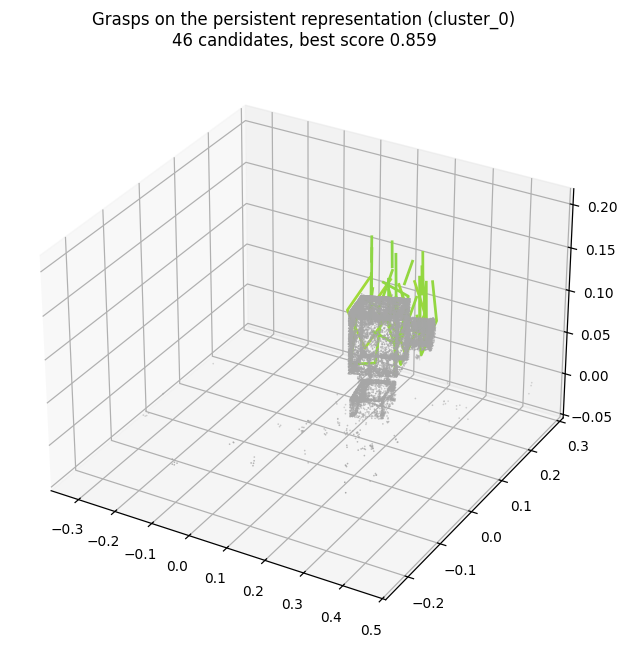

wrote: {'pred_grasps_world': '/kaggle/working/pogs_out/pred_grasps_world.npy', 'grasp_point_world': '/kaggle/working/pogs_out/grasp_point_world.npy'}


In [38]:
from pogs_kaggle.simscene import deproject

gi = 0
pogs_pts = model.gauss_params["means"].data[groups.group_masks[gi]].cpu().numpy()

# visible-only cloud: deproject frame 0's depth and keep points near this object
fr0 = seq.frames[0]
world = deproject(fr0.depth.to(DEVICE), seq.camera.to(DEVICE)).reshape(-1, 3)
oid = fr0.obj_id.reshape(-1).to(DEVICE)
vis_pts = world[oid == group2gt[gi]].cpu().numpy()

cmp = GR.compare_grasp_sources(pogs_pts, vis_pts, n_candidates=20000)
print(f"POGS cloud     : {cmp['pogs_points']:6d} pts -> {cmp['n_pogs']:4d} grasps "
      f"(best {cmp['best_score_pogs']:.3f})")
print(f"visible-only   : {cmp['visible_points']:6d} pts -> {cmp['n_visible_only']:4d} grasps "
      f"(best {cmp['best_score_visible']:.3f})")
print(f"POGS grasps whose contacts lie on surface the camera never saw: "
      f"{cmp['occluded_grasp_frac']*100:.0f}%")

V.plot_grasps(pogs_pts, cmp["pogs"], n=12,
              title=f"Grasps on the persistent representation ({groups.names[gi]})"); plt.show()
paths = GR.save_grasp_artifacts(cmp["pogs"], cfg.runtime.output_dir)
print("wrote:", paths)

---
## 12.5 · Table II — Tool Servoing (Sec. V-B)

> *"The robot then performs 6DoF visual servoing such that the tool tip remains in its
> relative target pose to the object. We leave tool rotation about its target axis
> unconstrained... At each pose, a human moves the drill 15-30° clockwise or counter
> clockwise about the grasp axis, and records how often the robot can adapt to this
> perturbation and locate the drill tip within 3cm and 5° of the target."*

Unlike Sec. V-A this cannot run on a pre-rendered video: it is a **closed loop**. Each frame
is rendered from the state the previous frame's command produced, so tracking error feeds
straight into servo error — the same coupling the real rig has.

    render → POGS tracking → tip/marker poses from the *estimate*
           → servo command → apply to the *true* tool pose → render …

The tool tip and the marker are annotated frames on the drill and the platform
(`simscene.TOOL_TIP_LOCAL`, `simscene.TARGET_MARKER_LOCAL`); the UR5 is replaced by a
rate-limited SE(3) command. The gripper is rendered occluding the handle, which is the
weakness Sec. VI names, so this is the honest setting rather than the flattering one.

In [39]:
servo_cfg = SV.ServoConfig(n_trials=SERVO_TRIALS, n_target_poses=SERVO_POSES, seed=0)
servo_results = SV.run_tool_servoing_suite(
    model, groups, capture, dino_fn, cfg, group2gt,
    tiers=(1, 2), kinds=("clockwise", "ccw", "follow"),
    servo_cfg=servo_cfg, tool_name=OBJECTS[0], target_name=OBJECTS[1], verbose=True)

display(SV.tool_servoing_table(servo_results))
for r in servo_results:
    print(r.summary())


--- tool servoing: clockwise, tier 1 (5 trials x 5 poses) ---
  [clockwise tier1] trial 1/5 init fine_loss=3.9432
      pose 1/5 (target moved 23.9 cm): FAIL in 3.20s  final 88.32 cm / 97.8 deg  (tool track err 110.68 cm)
      pose 2/5 (target moved 23.1 cm): FAIL in 3.20s  final 70.95 cm / 119.8 deg  (tool track err 151.28 cm)
      pose 3/5 (target moved 41.2 cm): FAIL in 3.20s  final 75.13 cm / 148.3 deg  (tool track err 204.73 cm)
      pose 4/5 (target moved 33.4 cm): FAIL in 3.20s  final 54.54 cm / 125.4 deg  (tool track err 224.81 cm)
      pose 5/5 (target moved 20.0 cm): FAIL in 3.20s  final 84.36 cm / 122.5 deg  (tool track err 259.40 cm)
  [clockwise tier1] trial 2/5 init fine_loss=3.9305
      pose 1/5 (target moved 12.8 cm): FAIL in 3.20s  final 72.03 cm / 110.5 deg  (tool track err 63.03 cm)
      pose 2/5 (target moved 12.0 cm): FAIL in 3.20s  final 61.19 cm / 140.5 deg  (tool track err 86.27 cm)
      pose 3/5 (target moved 30.2 cm): FAIL in 3.20s  final 59.64 cm / 14

,Tier 1 Success Rate,Tier 1 Time (s),Tier 2 Success Rate,Tier 2 Time (s)
Clockwise,0/25,NaN,0/25,NaN
CCW,0/25,NaN,0/25,NaN
Follow Target,0/25,NaN,0/25,NaN


{'tier': 1, 'kind': 'clockwise', 'success': '0/25', 'success_rate': 0.0, 'time_s': nan, 'mean_final_pos_err_cm': 67.28, 'mean_final_rot_err_deg': 113.28, 'mean_tool_track_err_cm': 137.0, 'max_target_disp_cm': 45.0, 'reach_limited_frames': 1294}
{'tier': 1, 'kind': 'ccw', 'success': '0/25', 'success_rate': 0.0, 'time_s': nan, 'mean_final_pos_err_cm': 74.7, 'mean_final_rot_err_deg': 119.63, 'mean_tool_track_err_cm': 99.37, 'max_target_disp_cm': 44.4, 'reach_limited_frames': 1285}
{'tier': 1, 'kind': 'follow', 'success': '0/25', 'success_rate': 0.0, 'time_s': nan, 'mean_final_pos_err_cm': 69.27, 'mean_final_rot_err_deg': 83.42, 'mean_tool_track_err_cm': 113.2, 'max_target_disp_cm': 49.2, 'reach_limited_frames': 926}
{'tier': 2, 'kind': 'clockwise', 'success': '0/25', 'success_rate': 0.0, 'time_s': nan, 'mean_final_pos_err_cm': 62.06, 'mean_final_rot_err_deg': 77.82, 'mean_tool_track_err_cm': 89.76, 'max_target_disp_cm': 63.5, 'reach_limited_frames': 1305}
{'tier': 2, 'kind': 'ccw', 'succe

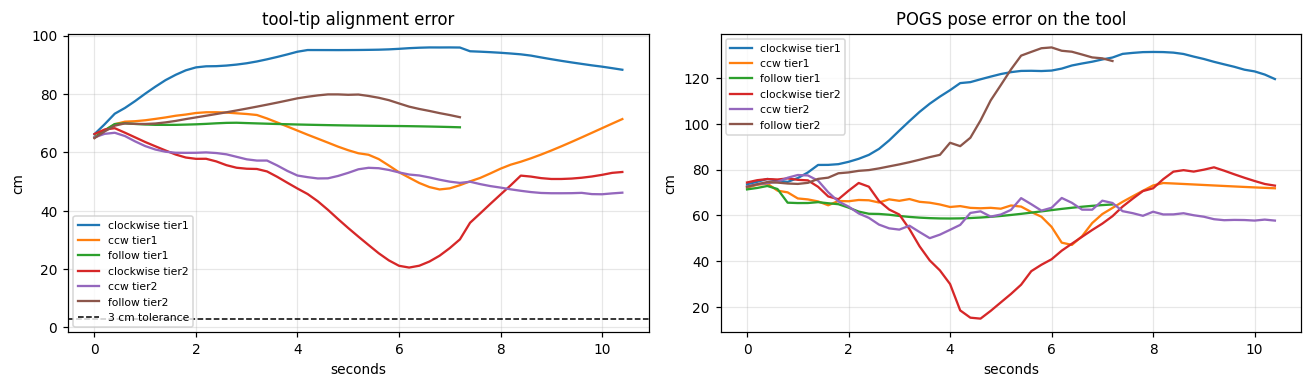

In [40]:
# what the servo loop was actually fighting: tool tracking error vs alignment error
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for r in servo_results:
    if not r.attempts:
        continue
    a = r.attempts[0]
    ax[0].plot(np.arange(len(a.pos_err_trace)) * servo_cfg.dt, a.pos_err_trace,
               label=f"{r.kind} tier{r.tier}")
    ax[1].plot(np.arange(len(a.track_pos_err_cm)) * servo_cfg.dt, a.track_pos_err_cm,
               label=f"{r.kind} tier{r.tier}")
ax[0].axhline(servo_cfg.pos_tol_cm, ls="--", c="k", lw=1, label="3 cm tolerance")
ax[0].set_title("tool-tip alignment error"); ax[0].set_ylabel("cm")
ax[1].set_title("POGS pose error on the tool"); ax[1].set_ylabel("cm")
for a_ in ax:
    a_.set_xlabel("seconds"); a_.legend(fontsize=7); a_.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
## 13 · Save artifacts

In [41]:
out = cfg.runtime.output_dir
torch.save({k: v.detach().cpu() for k, v in model.gauss_params.items()}, f"{out}/pogs_gaussians.pt")
torch.save({"gaussian_field": model.gaussian_field.state_dict(),
            "nn": model.nn.state_dict()}, f"{out}/pogs_fields.pt")
np.save(f"{out}/cluster_labels.npy", labels.cpu().numpy())
np.save(f"{out}/segmented_object.npy", pogs_pts.astype(np.float32))

for nm, r in {**res, **abl, **kf_res}.items():
    np.save(f"{out}/part_deltas_traj__{nm.replace(' ','_').replace('(','').replace(')','')}.npy",
            r.pred_poses.astype(np.float32))

summary = E.results_table({**abl, **kf_res, **sweep})
try:
    summary.to_csv(f"{out}/results.csv"); display(summary)
except AttributeError:
    print(summary)
print("\nartifacts in", out, ":", sorted(os.listdir(out)))

,mean_pos_err_cm,std_pos_err_cm,mean_rot_err_deg,mean_add_cm,mean_adds_cm,max_consecutive_or,mean_consecutive_or,frac_lost,pos_err_occluded_cm,pos_err_clear_cm,fps,mean_iters,init_time_s,depth_drop_rate
name,,,,,,,,,,,,,,
POGS,5.881,5.246,40.250,9.109,4.375,1,0.333,0.767,7.554,5.044,0.268,25.000,21.661,0.0
No Depth,10.545,9.092,45.714,13.959,6.901,0,0.000,0.900,9.465,11.085,0.283,25.000,21.272,0.0
No DINO,8.232,7.078,39.645,10.425,5.636,0,0.000,1.000,9.065,7.815,0.514,25.000,9.441,0.0
POGS,5.881,5.246,40.250,9.109,4.375,1,0.333,0.767,7.554,5.044,0.268,25.000,21.661,0.0
POGS + KF,7.476,8.013,45.447,11.109,5.378,0,0.000,0.850,7.741,7.343,0.319,21.067,21.673,0.0
POGS + KF + prefetch,17.815,34.095,44.070,19.987,14.498,0,0.000,0.817,8.325,22.560,0.326,21.017,21.555,0.0
no KF,6.406,5.864,40.363,9.506,4.688,1,0.333,0.800,9.010,5.104,0.268,25.000,21.569,0.0
KF@0,7.804,9.023,45.359,11.257,5.471,0,0.000,0.767,8.615,7.399,0.361,18.600,21.771,0.0
KF@2,10.579,16.814,46.912,13.687,7.781,0,0.000,0.817,8.833,11.452,0.348,19.467,21.516,0.0



artifacts in /kaggle/working/pogs_out : ['cluster_labels.npy', 'grasp_point_world.npy', 'part_deltas_traj__No_DINO.npy', 'part_deltas_traj__No_Depth.npy', 'part_deltas_traj__POGS.npy', 'part_deltas_traj__POGS_+_KF.npy', 'part_deltas_traj__POGS_+_KF_+_prefetch.npy', 'part_deltas_traj__POGS_no_KF.npy', 'part_deltas_traj__POGS_paper.npy', 'pogs_fields.pt', 'pogs_gaussians.pt', 'pogs_tracking.mp4', 'pred_grasps_world.npy', 'results.csv', 'segmented_object.npy']


---
# 14 · Discussion — the four questions

## Q1. Offline vs online tracking with two objects, as a POGS extension

**What POGS does today.** Tracking is strictly causal and *fully decoupled*: `part_deltas`
is a $K\times7$ tensor, one independent SE(3) delta per cluster, and each object gets its own
ROI crop. The paper is explicit that this is deliberate — *"without imposing constraints on
their relative movements"*. The loss is a plain sum over objects, so with $K=2$ the Hessian
is block-diagonal by construction.

**Where that breaks, measured in §11.1.** Two failure modes appear that a single-object
analysis cannot show:

1. **ROI bleed.** `calculate_roi` inflates each object's box by 25 % (or 75 px, whichever is
   larger). When the objects come within roughly that margin the boxes overlap, and object
   A's pixels enter object B's DINO/depth residual. Because the objects are optimised
   independently, nothing penalises both deltas explaining the *same* pixels — a
   double-counting error, visible as a positive cross-object error correlation $\rho$.
2. **Mutual occlusion.** The depth term already erodes and median-rejects
   (`depth_outlier_ratio = 1.3`), which handles a hand in front. It does not handle object B
   *behind* object A, where B's rendered surface is valid but unobserved.

**The extension worth making.** Three levers, in increasing order of ambition:

| Lever | Change | Cost |
|---|---|---|
| **Occlusion-aware masking** | render all $K$ clusters together, keep a per-object visibility mask $M_i = [\text{depth}_i \le \text{depth}_{\text{all}} + \epsilon]$, and weight each object's residual by it | one extra full-scene render per iteration |
| **Exclusive ROI assignment** | assign each pixel to the object whose rendered $\alpha$ is highest, so no pixel votes twice | free (reuses the alpha maps already computed) |
| **Joint / relational optimisation** | drop the block-diagonal assumption: add a soft non-penetration term $\sum_{i\ne j}\max(0, d_{\min} - \lVert c_i-c_j\rVert)^2$, and (for a grasped tool) an end-effector constraint | couples the objects; the paper's own future work asks for exactly the latter (*"we will add an end-effector regularization term for objects grasped by the robot"*) |

POGS already contains the machinery for the third: `atap_loss.py` implements an
As-Rigid-As-Possible inter-group term inherited from RSRD, and
`RigidGroupOptimizerConfig.use_atap` defaults to **False**. Turning it on and re-purposing it
from articulated parts to *scene-level relational constraints* is the cheapest credible
2-object extension.

**Offline vs online.** They are not two algorithms; they are one algorithm under different
information sets:

|  | Online (what POGS ships) | Offline |
|---|---|---|
| Information at frame $t$ | frames $\le t$ | all frames |
| Init | 100 + 70 steps on frame 0 only | can re-initialise anywhere, or run bidirectionally |
| Failure recovery | must re-init forward, losing the trial | interpolate across the gap from both sides |
| Per-frame budget | hard real-time (25 steps at 5 Hz) | unbounded |
| Deployable on the UR5 | yes | no |

§11 quantifies the gap on this scene by smoothing the *same* causal estimates non-causally.
The honest reading: offline mainly buys you **recovery from dropouts**, not steady-state
accuracy. A dropout at frame $t$ is unrecoverable online but trivially interpolable offline.
That is why the paper's headline metric is *consecutive successful resets* rather than mean
error — it measures exactly the thing offline processing would hide.

---

## Q2. Pre-tracking vs post-tracking input datasets

The two phases consume genuinely different data, and conflating them is the usual reason a
POGS reproduction stalls.

| | **Pre-tracking (scan / onboarding)** | **Post-tracking (manipulation)** |
|---|---|---|
| What | 35 posed RGB-D views around a *static* scene | RGB-D video from one *fixed* camera of a *moving* scene |
| Camera | wrist-mounted ZED Mini, moving | static ZED 2, third person |
| Needs | accurate extrinsics, wide baseline, all object surfaces (incl. undersides) | metric depth at 30 Hz, temporal continuity |
| Labels needed | 2D instance masks (Detic) for the grouping loss | none for tracking; 6-DoF GT only for evaluation |
| Consumed by | `capture_scene` → 3DGS init + all distillation | `make_tracking_sequence` → `RigidGroupOptimizer` |
| Assumption | *"all objects are static"* (Sec. III-2) | *"objects can be in different poses within 90° and 25 cm of their initial scan pose"* (Sec. III-2) |

**This notebook uses POGS-Sim** because the paper's scenes are not released, and because the
simulator supplies ground-truth trajectories that make §8–§11 quantitative rather than
anecdotal.

**Recommended real datasets, in priority order.** The exact scan-then-track structure POGS
needs is now a standardised benchmark task:

1. **BOP-H3 model-free track (BOP Challenge 2024)** — *the closest match by construction.*
   Objects are onboarded from reference videos and then localised in test video, which is
   POGS's scan→track split verbatim. Two onboarding regimes are provided:
   *static* (object still, camera orbits — matches POGS's hemisphere scan) and *dynamic*
   (fixed camera, object manipulated by hand). Datasets: **HOT3D** (33 objects, egocentric
   Aria/Quest 3, hand-object interaction), **HOPEv2** (28 objects, multi-view static
   arrangements), **HANDAL** (40 hardware/kitchen tools — pliers, screwdrivers, utensils,
   i.e. the irregular manipulables POGS targets). `bop.felk.cvut.cz`.
2. **DexYCB / HO-3D** — human hands manipulating YCB objects with per-frame 6-DoF GT.
   Best match to the paper's *human perturbation* setting and its occlusion limitation
   (Sec. VI). Pre-tracking views come from the YCB object scans.
3. **YCB-Video (BOP core)** — RGB-D video, multi-object clutter, dense 6-DoF GT. Weaker on
   the scan phase (you must synthesise the onboarding views from the provided meshes), but
   it is the standard reference for tracking numbers.
4. **HOI4D** — 4D egocentric human-object interaction with object pose; largest scale, most
   category diversity.
5. *If you only need the scan phase:* **Mip-NeRF 360** / **Record3D** captures give posed
   RGB-D of static scenes, but carry no manipulation video, so Phase 3 has to come from
   elsewhere.

**Practical note.** A BOP-H3 static-onboarding video plugs into this notebook by replacing
`capture_scene` with a loader that fills `CaptureData` (images, depths, `PinholeCamera`s,
seed cloud); the test video replaces `make_tracking_sequence`. Nothing downstream changes.
The one thing you must supply that BOP does not is the 2D instance masks for the grouping
loss — use Detic (as the paper does) or SAM-2.

---

## Q3. Starting the Kalman filter from step 5 — which cells change

`start_step` is already a first-class config field, so **the default path needs no code
edits**:

```python
cfg.kalman.enabled    = True
cfg.kalman.start_step = 5      # engage at frame 5
```

**What actually changes, cell by cell:**

| Cell | Change |
|---|---|
| *§2 Configuration* | set `cfg.kalman.start_step = 5` (and `cfg.kalman.dt` to your real frame period — it defaults to 0.2 s for the paper's 5 Hz) |
| *§10 / §10.1* | already sweeps `start_steps=(0, 2, 5, 10, 20)`; the `KF@5` row is the answer |
| **no change** | §3–§7 (capture, features, training, grouping) — the filter touches only Phase 3 |

**What happens inside `KalmanPoseFilter`, frames 0→5→N:**

- **frames 0–4 (`frame_idx < start_step`)** — `engaged` is `False`. `predict()` returns the
  current pose unchanged, `suggest_iters()` returns the full 25, and `update()` only appends
  the measurement to `buffer`. This is *bit-identical to vanilla POGS*.
- **frame 5** — `_bootstrap()` fires: $p,q$ from the last measurement, and
  $v=\Delta p/\Delta t$, $\omega=\mathrm{Log}(q_{t-1}^{-1}q_t)/\Delta t$ from the last two
  buffered poses. $P$ is seeded from the measurement-noise diagonal.
- **frames 6+** — the full loop: `predict` → `set_part_deltas` (warm start) → `opt.step` →
  `update` (gated) → write the fused pose back.

**Why 5 and not 0 is a defensible default.** The filter needs $\ge 2$ poses to estimate a
velocity, and POGS's own frame-0 estimate comes from the 100+70 initialisation, which is
noticeably noisier than steady-state tracking. Bootstrapping at frame 0 seeds the velocity
from that noise and the constant-velocity prediction then actively fights the optimiser for
the next several frames. `start_step = 5` costs five frames of filtering and buys a velocity
estimate from converged measurements. Past ~10 the filter simply has less sequence to help
with. The §10.1 sweep is what settles it on your data — do not take the number on faith.

**One caveat that is easy to miss.** The filter fuses `part_deltas`, whose rotation is the
*world-frame* delta from the canonicalised scan pose. That is the right state to filter (it
is affine in the object's world pose, with the centroid as a constant offset), but the
process noise `q_rot`/`q_omega` is then in world-frame so(3), *not* body frame. For objects
that spin fast about a body axis, switch `predict` to right-multiplying the body-frame
increment; the code already composes $q\otimes\mathrm{Exp}(\omega\Delta t)$, so this is a
one-line change to where $\omega$ is interpreted.

---

## Q4. Can a Kalman filter make inference faster?

**Yes — but the filter is not what gets faster. It is what lets you spend less.**

Sec. VI gives the budget: *"the online tracking frequency is limited to 5 Hz on an NVIDIA
4090 GPU... approximately 140 ms latency for DINO feature extraction using a ViT-S, and
multiple steps of optimization necessary per frame iteration"*. So per frame:

$$T_{\text{frame}} \approx \underbrace{T_{\text{DINO}}}_{\sim140\text{ ms, fixed}}
+ \underbrace{N_{\text{iter}}\cdot T_{\text{step}}}_{25\times(\text{render}+\text{backward})}$$

A Kalman filter cannot shrink $T_{\text{DINO}}$ and cannot shrink $T_{\text{step}}$. It
attacks $N_{\text{iter}}$, and it does so on solid ground: 25 steps are needed because Adam
starts from the *previous* pose, so it must first traverse the whole inter-frame motion.
Start it from a *predicted* pose and the residual it has to close is the prediction error,
not the motion — typically an order of magnitude smaller under smooth motion.

**Three mechanisms, all implemented and measured in §10.2:**

1. **Warm start** (`warm_start=True`) — seed `part_deltas` with the KF prediction. Same
   iteration count, lower error; or same error, fewer iterations.
2. **Adaptive iterations** (`adaptive_iters=True`) — map the last innovation
   $\lVert\nu_p\rVert$ onto $N_{\text{iter}}\in[8,25]$. Smooth stretches cost 8 steps;
   only surprises pay for 25. On a trajectory that is mostly smooth this is where the wall
   clock actually goes.
3. **Prediction during dropout** — when the measurement is gated out (occlusion), the
   prediction carries the object forward at zero optimisation cost, instead of the tracker
   locking onto a hand.

**Realistic ceiling.** With $T_{\text{DINO}}$ fixed, dropping 25 → 10 steps moves a 5 Hz
loop to roughly 8–9 Hz, not 12 Hz — Amdahl's law, with DINO as the serial part. **To go
past that you must also attack $T_{\text{DINO}}$.**

That is where the second T4 earns its keep, and where the two extensions turn out to
compose rather than merely coexist. Note first *which* DINO cost matters: during tracking
POGS never uses the full-frame feature map — `get_optim_loss` runs on per-object **ROI
crops**, so the per-frame ViT cost is $K$ extractions (one per tracked object), each of a
crop that `get_img_resolution` upsamples to the DINO working resolution. Prefetching the
full frame would save nothing.

But frame $t{+}1$'s ROIs are not known until frame $t$ has been optimised — *unless
something predicts where the objects will be*. The Kalman prediction supplies exactly that.
So `DinoPrefetcher` fixes the next frame's ROIs from the prediction and hands those crops
to `cuda:1`, while `cuda:0` keeps running Adam on the current frame. The 140 ms leaves the
critical path entirely whenever $N_{\text{iter}}\cdot T_{\text{step}} \ge T_{\text{DINO}}$.
This is the parallelisation Sec. VI lists as future work; §10.2 measures it.

**What you should *not* expect.** The filter does not make any single optimisation step
cheaper, and under genuinely erratic motion (the paper's tier-2 resets, a human snatching an
object) the constant-velocity prediction is wrong, `suggest_iters` correctly returns the
maximum, and you are back to 5 Hz. The speed-up is a property of the *motion*, not of the
filter. Report it as a distribution over frames, never as a single headline number — which
is why §10.2 plots the accuracy/latency curve rather than quoting one Hz figure.

---
## Reproducibility notes

* All hyperparameters trace to the official release: `pogs/pogs_config.py`,
  `pogs/pogs.py::POGSModelConfig`, `pogs/tracking/rigid_group_optimizer.py::RigidGroupOptimizerConfig`,
  `pogs/data/full_images_datamanager.py`. Each is cited in the docstring of the corresponding
  field in `pogs_kaggle/config.py`.
* `initialize_obj_pose` seeds from identity (`TrackingConfig.init_n_seeds = 1`), matching the
  released code — `Optimizer.init_obj_pose` passes `n_seeds=7` but the released function
  ignores it. Identity is also the correct seed: Sec. IV-C canonicalises each object frame so
  its scan-time pose *is* identity. `init_n_seeds > 1` runs a greedy **per-object** yaw sweep;
  a single yaw shared across all objects is unsound and is not what this does.
* Densification uses a percentile gradient threshold rather than the absolute
  `densify_grad_thresh = 0.0008`, because the units of `means2d.grad` differ between gsplat
  versions and the pure-PyTorch backend. The schedule (`warmup_length`, `refine_every`,
  `stop_split_at`, `reset_alpha_every`) is unchanged.
* If `DINO_REAL` or `CLIP_REAL` printed `False`, the corresponding numbers are lower bounds
  from frozen random features. Enable internet and re-run §4.